# CEBADA360 · Estimación del rendimiento de cebada maltera con percepción remota
**Reto AgroCebada FIRA 2026** · Código fuente del modelo predictivo y de los resultados que alimentan nuestra aplicación

En este notebook está todo el proceso con el que estimamos el rendimiento de cebada maltera de temporal en 59 parcelas del Altiplano de Hidalgo, Tlaxcala y Puebla para el ciclo abril–octubre de 2025. Partimos de los datos oficiales del reto (imágenes de Sentinel-2, Landsat y Planet, clima mensual, topografía y los polígonos de las 197 parcelas), los auditamos y limpiamos, los convertimos en variables que describen cómo creció cada parcela, comparamos varios modelos con una validación cuidadosa y generamos las predicciones finales, sus márgenes de error y los indicadores que usa la aplicación.

## El problema
De las 197 parcelas, 138 tienen rendimiento conocido (t/ha) y 59 lo tienen oculto. La tarea es estimar esas 59. Todo lo que hacemos gira alrededor de tres hechos que conviene tener presentes desde el inicio:

1. **Hay un solo rendimiento por parcela.** Solo conocemos el rendimiento final de 2025; no hay rendimientos de otros años ni de otras fechas. Por eso no tratamos el problema como una serie de tiempo: lo temporal son las imágenes y el clima, y los resumimos en variables por parcela (fecha de siembra estimada, vigor máximo, lluvia en la etapa vegetativa, etc.). El resultado es una tabla con una fila por parcela.
2. **Son pocas parcelas.** Con 138 observaciones, un modelo con muchas variables o muy flexible termina aprendiendo el ruido de esas parcelas y se equivoca más en parcelas nuevas. Por eso preferimos modelos sencillos y regularizados, y solo aceptamos una variable o un modelo nuevo si baja el error en parcelas no vistas más que el ruido propio de la validación.
3. **La ubicación pesa mucho.** Las 59 parcelas están intercaladas con las de entrenamiento (la parcela con dato más cercana está, en la mediana, a 0.35 km). El rendimiento de las parcelas vecinas, el promedio del municipio y un patrón espacial suave explican la mayor parte de lo que se puede explicar; el satélite y el clima agregan poco encima de eso, y lo documentamos con pruebas.

## Cómo está organizado
| Etapa | Pasos | Qué se obtiene |
|---|---|---|
| Configuración y datos | 0 y carga de archivos | rutas, lectura directa del `DataSet 1.zip`, cálculo del rendimiento de las vecinas sin fuga |
| Auditoría y limpieza | 1 a 6 | tabla principal revisada, archivos limpios por sensor, primera base por parcela, análisis espacial, diccionario |
| Variables del cultivo | 8, 7, 9 a 12 | fenología con suavizado Whittaker, clima por etapa del cultivo, humedad, base de modelado final (v3), reducción de variables, bases de predicción temprana |
| Preguntas del comité | 13 a 16 | revisión de las etapas contra lo que dijeron los organizadores, comparación con las vecinas, señales de riesgo climático, banderas de calidad |
| Modelo | A a G | elección del número de vecinas, comparación de modelos, modelo final, predicciones y factores para la app |
| Validación y diagnóstico | 17 a 23, 25, 26, 28 | supuestos, criterios de información, predicción final con control de calidad, barrido de variables, validación espacial y anidada, pesos del ensamble, variabilidad residual, parcelas atípicas, curva de aprendizaje |
| Crédito y aplicación | 24, 27, 29 | crédito sugerido por parcela, márgenes de error por municipio y visor geográfico |
| Verificación | 30 | comprobación automática de que la entrega y las métricas no cambiaron |

El paso 8 va antes del 7 porque el clima por etapa necesita las fechas de siembra, pico y secado que calcula la fenología. Los pasos 13 en adelante que no son la predicción final son **diagnósticos**: ninguno cambió el modelo ni las 59 predicciones.

## El modelo final en una frase
Un **ensamble** que promedia, con el mismo peso (⅓ cada uno), tres estimaciones: una regresión **Ridge** con el rendimiento de las 12 parcelas vecinas, la lluvia y la amplitud térmica de la etapa vegetativa de 2025; el **promedio del municipio**; y un **proceso gaussiano** sobre las coordenadas. En validación cruzada (5 particiones × 10 repeticiones, estratificada por municipio) obtuvo RMSE 0.494 t/ha, MAE 0.338 t/ha y R² 0.661; la estimación más conservadora, con validación anidada y ponderando por la distancia real de las 59, está entre 0.50 y 0.51 t/ha.

## Cómo ejecutarlo
1. En Colab: **Entorno de ejecución → Ejecutar todo** (en Jupyter: **Run → Run All Cells**). Tarda alrededor de 20 minutos.
2. En la celda **Subir los archivos** aparece el botón **Elegir archivos** (en una computadora se abre una ventana). Selecciona **`DataSet 1.zip`** tal como se descarga de la plataforma del reto, sin descomprimir: trae clima, topografía y shapefile. También funcionan `Archivos_para_subir.zip` o los 12 archivos sueltos.
3. Cada paso muestra sus tablas y gráficas debajo de su celda. Al final, en Colab se descarga un `.zip` con todos los resultados.

**Paquetes.** En Colab ya vienen todos (el notebook instala `rasterio` solo si hace falta). En una computadora: `pip install pandas numpy scipy scikit-learn matplotlib statsmodels rasterio openpyxl` y `conda install -c conda-forge geopandas`. El paso 30 escribe `requirements.txt` con las versiones exactas con que se generó la entrega.

## Dónde quedan los resultados
| Carpeta | Contenido |
|---|---|
| `outputs/` | archivos limpios por sensor, bases por parcela (v1, v2, v3), coordenadas, diccionarios, señales de riesgo y banderas de calidad |
| `figs/` | gráficas de la auditoría y de las variables del cultivo |
| `resultados_I3/` | modelo, métricas, validaciones y diagnósticos; **la entrega está en `resultados_I3/ENTREGA/predicciones_59_entrega.csv`** con su huella SHA-256 |
| `resultados_I4/` | crédito sugerido por parcela, supuestos con fuente, escenarios y sensibilidad |
| `resultados_app/` | visor geográfico (`visor_cebada360.html`), datos y pruebas del visor |

Los nombres `resultados_I3` y `resultados_I4` vienen de cómo organizamos el trabajo internamente; los conservamos porque la aplicación y las verificaciones leen esas rutas.

## Cómo leer las métricas
- **RMSE** (t/ha): error típico de la predicción; castiga más los errores grandes. Con un rendimiento promedio cercano a 3.96 t/ha, un RMSE de 0.49 significa equivocarse, en un caso típico, alrededor de media tonelada por hectárea.
- **MAE** (t/ha): error promedio en valor absoluto; menos sensible a las pocas parcelas con siniestro.
- **R²**: proporción de la variación del rendimiento entre parcelas que el modelo explica en parcelas no vistas (1 sería perfecto; 0 equivale a predecir siempre el promedio).

Este archivo se guardó sin salidas. Las cifras que se citan en el texto son las de nuestra corrida de referencia (13 y 14 de octubre de 2026), las mismas que el paso 30 verifica al ejecutar el notebook completo.

## 0. Configuración
No hay que cambiar nada. Los archivos se guardan en la carpeta `datos` y los resultados en `outputs` y `figs`.

### Explicación

**Objetivo.** Dejar listas las librerías, rutas, parámetros generales y las funciones que leen los datos del reto, para que todo el notebook corra con un solo "Ejecutar todo", tanto en Colab como en una computadora.

**Procedimiento.**
- Importamos las librerías de análisis (pandas, NumPy, SciPy, scikit-learn, matplotlib) y fijamos los parámetros que usan varios pasos: los umbrales de nubosidad (20 % el principal y 10 % como sensibilidad), la ventana de análisis de 2025 (abril a diciembre, para alcanzar a ver la senescencia de noviembre) y la semilla `SEMILLA = 42`.
- `buscar()` y `localizar_archivos()` encuentran cada archivo oficial aunque la plataforma le haya agregado un prefijo al nombre (por ejemplo `aa94a458-...csv`).
- `subir_archivos()`, `extraer_zips()` y `preparar_desde_dataset_oficial()` permiten subir directamente el `DataSet 1.zip` de la plataforma. El zip oficial trae zips internos y un solo archivo Básico, así que el código los abre, divide el Básico en dos partes y genera los tres archivos por parcela que el resto del notebook espera (municipio, topografía y Tmax mensual).
- `_zonal()` calcula estadísticas de un raster dentro de cada parcela usando **todas las celdas que toca el polígono** (`all_touched=True`). Lo necesitamos porque una celda de clima mide unos 5 km y muchas parcelas son mucho más chicas que eso: sin `all_touched`, algunas parcelas no "contendrían" ninguna celda.

**Justificación.** El jurado tiene el zip oficial, no nuestros CSV intermedios. Por eso el notebook reconstruye esos insumos con el mismo método del equipo (se verificó una diferencia de 0.0 contra nuestros CSV) y así cualquiera puede reproducir la entrega.

**Relación con el proyecto.** Es la base de la reproducibilidad: sin esta celda no hay datos con qué construir variables ni entrenar el modelo.

In [45]:
# Paso 0 · Configuración: librerías, rutas, parámetros globales y funciones para leer el DataSet oficial.
# Aquí solo se DEFINEN cosas (no se procesa nada todavía). Los parámetros de esta celda los usan los pasos siguientes.
import sys, re, time, traceback
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.stats import wasserstein_distance
from sklearn.model_selection import KFold, StratifiedKFold, GroupKFold
from sklearn.cluster import KMeans

try:                                        # Windows: evita errores con acentos en la consola
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
except Exception:
    pass

# =====================================================================================
# CONFIGURACIÓN (lo único que podrías necesitar cambiar)
# =====================================================================================
SUBIR_ARCHIVOS = True    # True = abre la ventana para subir los archivos si todavía no están
DESCARGAR_RESULTADOS = True   # True = al final descarga un .zip con los resultados (en Colab)
CARPETA_DATOS = None     # No hace falta tocarlo: los archivos subidos se guardan en la carpeta "datos"
PASOS_A_CORRER = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]      # quita números para saltarte pasos
SUBIR_CLIMA = True       # True = si no hay rasters .tif de clima en 'datos', pide subirlos (Tmin, Tmax, precipitación)

try:
    BASE = Path(__file__).resolve().parent  # carpeta de este archivo
except NameError:
    BASE = Path.cwd()                       # en Jupyter: carpeta del notebook
OUT = BASE / "outputs"; FIG = BASE / "figs"; DATOS = BASE / "datos"
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

# Usamos dos umbrales de nubosidad: 20 % como principal (más imágenes) y 10 % para revisar que las fechas fenológicas
# no cambien (paso 8).
UMBRALES_NUBOSIDAD = (10, 20)                 # 20 = principal, 10 = sensibilidad
# El ciclo oficial es abr-oct, pero extendemos la ventana a diciembre para observar el secado completo del cultivo.
VENTANA_2025 = ("2025-04-01", "2025-12-31")   # incluye la senescencia de noviembre
# Semilla general para los muestreos aleatorios de la auditoría y de las variables del cultivo (p. ej., la muestra de
# curvas del paso 8).
SEMILLA = 42
_trapz = getattr(np, "trapezoid", None) or np.trapz   # compatible con NumPy 1.x y 2.x

# La plataforma renombra los archivos con un prefijo; por eso se busca por terminación del nombre y en varias
# carpetas.
def buscar(nombre):
    """Busca un archivo oficial por nombre, aunque tenga un prefijo (p. ej. 'aa94a458-...')."""
    carpetas = [Path(CARPETA_DATOS)] if CARPETA_DATOS else [BASE / "datos", BASE / "datos" / "shp", BASE, BASE / "data_shp"]
    for c in carpetas:
        if not c.exists():
            continue
        exacto = c / nombre
        if exacto.exists():
            return exacto
        parecidos = sorted(c.glob("*" + nombre))
        if parecidos:
            return parecidos[0]
        recursivo = sorted(c.rglob("*" + nombre))
        if recursivo:
            return recursivo[0]
    return BASE / "datos" / nombre                # no existe: se reporta en verificar_datos()

NOMBRES = {
    "F_Y": "ID_area_rendimiento_70_30_Reto_AgroCebada.csv",
    "F_PRO": "Conjunto_datos_PRO_AgroCebada.csv",
    "F_B1": "BASICO_AgroCebada2026_parte1_AGC001-099.csv",
    "F_B2": "BASICO_AgroCebada2026_parte2_AGC100-197.csv",
    "F_MUN": "Tmax_2023_02_por_parcela.csv",
    "F_TOPO": "Topografia_por_parcela.csv",
    "F_TMAX": "Tmax_2022_2025_por_parcela.csv",
    "SHP": "Parcelas_Reto_AGC_CONJUNTO.shp",
}

def localizar_archivos():
    """Ubica cada archivo (en 'datos' o junto al código) y los deja en variables globales."""
    global F_Y, F_PRO, F_B1, F_B2, F_MUN, F_TOPO, F_TMAX, SHP
    F_Y, F_PRO, F_B1, F_B2 = (buscar(NOMBRES[k]) for k in ("F_Y", "F_PRO", "F_B1", "F_B2"))
    F_MUN, F_TOPO, F_TMAX, SHP = (buscar(NOMBRES[k]) for k in ("F_MUN", "F_TOPO", "F_TMAX", "SHP"))

def faltantes():
    localizar_archivos()
    return [n for k, n in NOMBRES.items() if k != "SHP" and not buscar(n).exists()]

def subir_archivos(mensaje="Presiona 'Elegir archivos' y selecciona 'DataSet 1.zip' del reto (o los 12 archivos / Archivos_para_subir.zip)."):
    """Abre una ventana para subir los archivos y los guarda en la carpeta 'datos'.
    Acepta los archivos sueltos o un .zip que los contenga."""
    import shutil, zipfile
    destino = BASE / "datos"; destino.mkdir(exist_ok=True)
    guardados = []
    try:                                            # Google Colab
        from google.colab import files
        print(mensaje)
        subidos = files.upload()
        for nombre, contenido in subidos.items():
            (destino / nombre).write_bytes(contenido)
            if Path(nombre).exists() and Path(nombre).resolve() != (destino / nombre).resolve():
                Path(nombre).unlink()
            guardados.append(destino / nombre)
    except ImportError:                             # Jupyter o Spyder en tu computadora
        import tkinter as tk
        from tkinter import filedialog
        raiz = tk.Tk(); raiz.withdraw(); raiz.attributes("-topmost", True)
        print("Se abrió una ventana: selecciona 'DataSet 1.zip' del reto, o los 12 archivos (Ctrl + clic) o un .zip con ellos.")
        rutas = filedialog.askopenfilenames(parent=raiz, title="CEBADA360 · Selecciona los archivos del reto",
                                            filetypes=[("Archivos del reto", "*.csv *.shp *.shx *.dbf *.prj *.cpg *.zip *.tif"),
                                                       ("Todos", "*.*")])
        raiz.destroy()
        for r in rutas:
            shutil.copy(r, destino / Path(r).name)
            guardados.append(destino / Path(r).name)
    extraer_zips(destino)                           # también abre los zips que vienen dentro de otro zip
    print(f"Archivos guardados en {destino}: {len(list(destino.iterdir()))}")

def descargar_resultados():
    """Comprime outputs/ y figs/ y, en Colab, los descarga a tu computadora."""
    import zipfile
    zip_res = BASE / "resultados_cebada360_I1_I2.zip"
    with zipfile.ZipFile(zip_res, "w", zipfile.ZIP_DEFLATED) as zf:
        for carpeta in (OUT, BASE / "figs", BASE / "resultados_I3", BASE / "resultados_I4", BASE / "resultados_app"):   # + visor (paso 29)
            if not carpeta.exists():
                continue
            for f in carpeta.rglob("*"):
                if f.is_file() and "_shapefile" not in f.parts:
                    zf.write(f, f.relative_to(BASE))
    print("Resultados comprimidos en:", zip_res)
    try:
        from google.colab import files
        files.download(str(zip_res))
    except ImportError:
        print("(En tu computadora los resultados ya están en las carpetas 'outputs' y 'figs'.)")

F_Y = F_PRO = F_B1 = F_B2 = F_MUN = F_TOPO = F_TMAX = SHP = None
localizar_archivos()

def preparar_shapefile():
    """El shapefile son 5 archivos que deben llamarse igual. Si llegaron con prefijos distintos
    (p. ej. 'c88387f8-...shp' y 'c81f8a39-...shx'), se copian juntos con el mismo nombre."""
    import shutil
    partes = {ext: buscar("Parcelas_Reto_AGC_CONJUNTO." + ext) for ext in ["shp", "shx", "dbf", "prj", "cpg"]}
    if not partes["shp"].exists():
        raise FileNotFoundError("No se encontró Parcelas_Reto_AGC_CONJUNTO.shp (se necesita para el paso 5).")
    if len({p.parent / p.stem for p in partes.values() if p.exists()}) == 1:
        return partes["shp"]
    destino = OUT / "_shapefile"; destino.mkdir(exist_ok=True)
    for ext, p in partes.items():
        if p.exists():
            shutil.copy(p, destino / ("Parcelas_Reto_AGC_CONJUNTO." + ext))
        elif ext in ("shx", "dbf"):
            raise FileNotFoundError(f"Falta el archivo .{ext} del shapefile.")
    return destino / "Parcelas_Reto_AGC_CONJUNTO.shp"

def verificar_datos():
    print("Carpeta de trabajo:", BASE)
    falta = False
    for nombre, p in [("Rendimientos", F_Y), ("Planet (PRO)", F_PRO), ("Básico parte 1", F_B1), ("Básico parte 2", F_B2),
                      ("Municipios (Tmax 2023-02)", F_MUN), ("Topografía", F_TOPO), ("Tmax 2022-2025", F_TMAX), ("Shapefile", SHP)]:
        ok = p.exists()
        print(f"  {'OK   ' if ok else 'FALTA'} {nombre:<26} {p}")
        if not ok and nombre != "Shapefile":
            falta = True
    if falta:
        raise FileNotFoundError("Faltan archivos de datos (marcados con FALTA). Vuelve a ejecutar y súbelos "
                                "en la ventana que aparece.")

# =====================================================================================
# DATASET OFICIAL: se puede subir directo "DataSet 1.zip" de la plataforma del reto
# =====================================================================================
def _ya_extraido(carpeta, z):
    """Solo cuenta como extraído si salió bien y el zip no cambió de tamaño (si lo vuelven a subir, se reintenta)."""
    m = carpeta / f".extraido_{z.name}"
    return m.exists() and m.read_text() == f"ok {z.stat().st_size}"


# El DataSet oficial trae zips dentro de zips (shapefile, clima, topografía): se abren todos y se deja una marca para
# no repetir.
def extraer_zips(carpeta=None):
    """Descomprime todos los .zip de 'datos', también los que vienen DENTRO de otro zip (el dataset oficial trae
    el shapefile, la precipitación, la temperatura y la topografía en zips internos). Todo queda en 'datos' sin
    subcarpetas. Cada zip se abre una sola vez (se deja una marca .extraido_<nombre>)."""
    import zipfile
    carpeta = carpeta or (BASE / "datos"); carpeta.mkdir(exist_ok=True)
    pendientes = [z for z in carpeta.glob("*.zip")
                  if not z.name.startswith(".") and not _ya_extraido(carpeta, z)]   # "._x" de la Mac y nuestras marcas .extraido_*
    while pendientes:
        z = pendientes.pop()
        try:
            with zipfile.ZipFile(z) as zf:
                for miembro in zf.namelist():
                    nombre = Path(miembro).name
                    if miembro.endswith("/") or "__MACOSX" in miembro or nombre.startswith("._"):
                        continue                       # basura que agrega la Mac al comprimir
                    destino = carpeta / nombre
                    destino.write_bytes(zf.read(miembro))
                    if destino.suffix.lower() == ".zip":
                        pendientes.append(destino)     # zip dentro del zip
        except zipfile.BadZipFile:
            mb = z.stat().st_size / 1e6
            print(f"AVISO: '{z.name}' ({mb:.1f} MB) no es un zip válido: probablemente la subida se cortó. "
                  f"Se ignora. Si es el dataset, bórralo de la carpeta 'datos' y vuelve a subirlo "
                  f"(DataSet 1.zip debe pesar ~57 MB).")
            (carpeta / f".extraido_{z.name}").write_text("invalido")
            continue
        (carpeta / f".extraido_{z.name}").write_text(f"ok {z.stat().st_size}")
        print("Descomprimido:", z.name)


# Estadística zonal: resume un raster (clima o topografía) dentro de cada polígono. all_touched=True porque las celdas
# de clima (~5 km) son más grandes que muchas parcelas.
def _zonal(raster, parcelas, prefijo):
    """Estadísticos por parcela con TODAS las celdas que toca la parcela (all_touched), igual que los CSV del equipo."""
    import rasterio
    from rasterio.mask import mask
    with rasterio.open(raster) as src:
        nod = -9999 if src.nodata is None else src.nodata
        g = parcelas.to_crs(src.crs); filas = []
        for pid, geom in zip(g.ID_POLIGON, g.geometry):
            a, _ = mask(src, [geom], crop=True, all_touched=True, filled=True, nodata=nod)
            a = a[0].astype(float); a = a[(a != nod) & (a > -1000)]
            filas.append({"ID_POLIGON": pid, f"{prefijo}_mean": a.mean() if a.size else np.nan,
                          f"{prefijo}_std": a.std() if a.size else np.nan, f"{prefijo}_min": a.min() if a.size else np.nan,
                          f"{prefijo}_max": a.max() if a.size else np.nan, f"{prefijo}_n_celdas": int(a.size)})
    return pd.DataFrame(filas).set_index("ID_POLIGON")


# Reconstruye desde el zip oficial los insumos por parcela que generó el equipo (municipio, topografía, Tmax), sin
# tocar los que ya existan.
def preparar_desde_dataset_oficial():
    """Si se subió el dataset oficial, genera lo que el notebook espera y no viene en él:
       1) Básico en dos partes (el oficial trae un solo archivo con las 197 parcelas).
       2) Municipio y estado por parcela (Tmax_2023_02_por_parcela.csv) desde el shapefile.
       3) Topografia_por_parcela.csv desde los rasters de elevación y pendiente.
       4) Tmax_2022_2025_por_parcela.csv desde los 48 rasters de Tmax.
       Si el archivo del equipo ya existe, NO se toca. Mismo método que el equipo (se verificó: diferencia 0.0000)."""
    D = BASE / "datos"; D.mkdir(exist_ok=True)
    extraer_zips(D)
    hecho = []
    # 1) Básico
    unico = buscar("Conjunto_datos_BASICO_AgroCebada2026.csv")
    if unico.exists() and not (buscar(NOMBRES["F_B1"]).exists() and buscar(NOMBRES["F_B2"]).exists()):
        b = pd.read_csv(unico, encoding="utf-8-sig")
        num = b.ID_POLIGONO.str.extract(r"(\d+)")[0].astype(int)
        b[num <= 99].to_csv(D / NOMBRES["F_B1"], index=False, encoding="utf-8-sig")
        b[num >= 100].to_csv(D / NOMBRES["F_B2"], index=False, encoding="utf-8-sig")
        hecho.append(f"Básico dividido en 2 partes ({(num <= 99).sum()} + {(num >= 100).sum()} filas)")
    falta_mun, falta_topo, falta_tmax = (not buscar(NOMBRES[k]).exists() for k in ("F_MUN", "F_TOPO", "F_TMAX"))
    if not (falta_mun or falta_topo or falta_tmax):
        localizar_archivos()
        if hecho: print("Preparado:", "; ".join(hecho))
        return
    try:
        shp = preparar_shapefile()
    except FileNotFoundError:
        localizar_archivos(); return              # sin shapefile no se puede generar el resto
    try:
        import geopandas as gpd
    except ImportError:
        print("AVISO: falta geopandas para generar municipio/topografía/Tmax (en Colab ya viene)."); return
    try:
        import rasterio  # noqa: F401
    except ImportError:
        import subprocess
        print("Instalando rasterio (solo la primera vez, ~30 s)...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)
    g = gpd.read_file(shp)
    # 2) Municipio y estado
    if falta_mun:
        g.drop(columns="geometry").to_csv(D / NOMBRES["F_MUN"], index=False)
        hecho.append("municipio y estado desde el shapefile")
    # 3) Topografía
    if falta_topo:
        el, pe = sorted(D.glob("Elevacion*.tif")), sorted(D.glob("Pendiente*.tif"))
        if el and pe:
            topo = _zonal(el[0], g, "Elevacion").join(_zonal(pe[0], g, "Pendiente"))
            topo.reset_index().to_csv(D / NOMBRES["F_TOPO"], index=False)
            hecho.append("Topografia_por_parcela.csv desde los rasters INEGI")
        else:
            print("AVISO: no están los rasters de elevación y pendiente.")
    # 4) Tmax mensual por parcela
    if falta_tmax:
        tif = {}
        for p in D.glob("*.tif"):
            m = re.fullmatch(r"tmax_(20\d\d)_(\d\d)\.tif", p.name.lower())
            if m: tif[(int(m.group(1)), int(m.group(2)))] = p
        if tif:
            partes = []
            for (a, m_), p in sorted(tif.items()):
                partes.append(_zonal(p, g, f"Tmax_{a}_{m_:02d}")[[f"Tmax_{a}_{m_:02d}_{s}" for s in ("mean", "std", "min", "max", "n_celdas")]])
            pd.concat(partes, axis=1).reset_index().to_csv(D / NOMBRES["F_TMAX"], index=False)
            hecho.append(f"Tmax_2022_2025_por_parcela.csv desde {len(tif)} rasters")
        else:
            print("AVISO: no están los rasters de Tmax.")
    localizar_archivos()
    print("Preparado desde el dataset oficial:", "; ".join(hecho) if hecho else "nada")


## Subir los archivos
Sube **`DataSet 1.zip` tal como se descarga de la plataforma del reto** (no hace falta descomprimirlo; trae el clima, la topografía y el shapefile adentro). El notebook abre los zips internos, divide el Básico en dos partes y genera municipio, topografía y Tmax por parcela con el mismo método que el equipo (verificado: diferencia 0.0 con los CSV del equipo). También acepta `Archivos_para_subir.zip` o los 12 archivos sueltos. Si ya están en la carpeta `datos`, no los vuelve a pedir.

### Explicación

**Qué hace.** Primero intenta preparar todo con lo que ya está en la carpeta `datos`; si falta algo, abre la ventana para subir archivos y vuelve a preparar. Al final, `verificar_datos()` imprime una línea `OK` o `FALTA` por cada insumo y detiene el notebook si falta alguno esencial.

**Por qué así.** Preferimos que el notebook se detenga con un mensaje claro a que siga con datos incompletos y produzca predicciones equivocadas sin avisar.

In [46]:
# Prepara los insumos con lo que haya en 'datos'; si falta algo, pide subir el DataSet oficial y vuelve a preparar.
# verificar_datos() se detiene con error si falta un archivo esencial (mejor detenerse que predecir con datos incompletos).
preparar_desde_dataset_oficial()        # si ya hay archivos o un .zip en 'datos', prepara lo que falte
if SUBIR_ARCHIVOS and faltantes():
    print("Faltan archivos:", ", ".join(faltantes()))
    subir_archivos()
    preparar_desde_dataset_oficial()
verificar_datos()

Carpeta de trabajo: /content
  OK    Rendimientos               /content/datos/ID_area_rendimiento_70_30_Reto_AgroCebada.csv
  OK    Planet (PRO)               /content/datos/Conjunto_datos_PRO_AgroCebada.csv
  OK    Básico parte 1             /content/datos/BASICO_AgroCebada2026_parte1_AGC001-099.csv
  OK    Básico parte 2             /content/datos/BASICO_AgroCebada2026_parte2_AGC100-197.csv
  OK    Municipios (Tmax 2023-02)  /content/datos/Tmax_2023_02_por_parcela.csv
  OK    Topografía                 /content/datos/Topografia_por_parcela.csv
  OK    Tmax 2022-2025             /content/datos/Tmax_2022_2025_por_parcela.csv
  OK    Shapefile                  /content/datos/Parcelas_Reto_AGC_CONJUNTO.shp


## Rendimiento de las parcelas vecinas (función auxiliar)
Calcula el rendimiento promedio de las *k* parcelas de entrenamiento más cercanas sin usar el dato de la parcela evaluada.

Uso dentro de un fold: `tr, va = agregar_vecinos_en_fold(base.iloc[idx_tr], base.iloc[idx_va], k=12)`

### Explicación

**Objetivo.** Construir la variable más importante del proyecto: el **rendimiento promedio de las 12 parcelas de entrenamiento más cercanas**, ponderado por la inversa de la distancia (IDW).

**Procedimiento.**
- `CoordenadasParcelas` lee los centroides de cada parcela en kilómetros (proyección EPSG:6372, la cónica conforme de Lambert para México), para que las distancias sean en km reales y no en grados.
- `VecinosRendimiento` guarda las parcelas de entrenamiento y, para una parcela nueva, promedia el rendimiento de sus *k* vecinas con peso `1/distancia^p` (`k=12`, `p=1`). La distancia mínima de 0.05 km evita pesos infinitos entre parcelas pegadas.
- `transform_train()` calcula la variable para las propias parcelas de entrenamiento **excluyendo a cada parcela de su propio promedio** (leave-one-out). `transform()` se niega a recibir parcelas que estén en el entrenamiento, para que no se pueda usar por error su propio rendimiento.

**Justificación.** El rendimiento tiene autocorrelación espacial: parcelas cercanas comparten suelo, clima local y, muchas veces, manejo. Si la parcela que validamos entrara en su propio promedio, el modelo "vería la respuesta" y el error de validación saldría artificialmente bajo. Estas protecciones son la razón por la que podemos confiar en la validación.

**Relación con el proyecto.** Esta variable es uno de los componentes centrales del ensamble final (dentro del Ridge) y la base de casi todas las comparaciones de los pasos 13 a 23.

In [47]:
# Clases para calcular el rendimiento de las parcelas vecinas SIN fuga (la parcela evaluada nunca entra en su promedio).
# Las distancias se calculan en km (EPSG:6372) para que el peso 1/distancia tenga sentido físico.
class CoordenadasParcelas:
    """Centroides de las parcelas en km (EPSG:6372), indexados por ID_POLIGONO."""
    def __init__(self, ruta=None):
        ruta = ruta or OUT / "coordenadas_parcelas.csv"
        self.df = pd.read_csv(ruta).set_index("ID_POLIGONO")[["x_km", "y_km"]]

    def xy(self, ids):
        faltan = set(ids) - set(self.df.index)
        if faltan:
            raise KeyError(f"IDs sin coordenadas: {sorted(faltan)[:5]}")
        return self.df.loc[list(ids)].values


class VecinosRendimiento:
    """Rendimiento promedio de los k vecinos de entrenamiento, ponderado por 1/distancia^p.

    k : número de vecinos.
    p : potencia del peso por distancia (0 = promedio simple).
    d_min_km : distancia mínima para el peso (evita pesos infinitos entre parcelas contiguas).
    """
    def __init__(self, k=12, p=1.0, d_min_km=0.05):
        self.k, self.p, self.d_min_km = k, p, d_min_km

    def fit(self, ids_train, y_train, coords):
        self.ids_train = np.asarray(ids_train)
        self.y_train = np.asarray(y_train, dtype=float)
        if np.isnan(self.y_train).any():
            raise ValueError("y_train contiene NaN: solo se deben pasar parcelas con rendimiento conocido.")
        self.coords = coords
        self.xy_train = coords.xy(self.ids_train)
        return self

    def _promedio(self, D):
        k = min(self.k, D.shape[1])
        idx = np.argsort(D, axis=1)[:, :k]
        dk = np.take_along_axis(D, idx, axis=1)
        # Peso IDW: las vecinas más cercanas pesan más. La distancia mínima de 0.05 km evita dividir entre cero.
        w = 1.0 / np.maximum(dk, self.d_min_km) ** self.p
        return (w * self.y_train[idx]).sum(1) / w.sum(1)

    def transform(self, ids):
        """Para parcelas que NO están en el entrenamiento (validación o PREDICCION)."""
        ids = np.asarray(ids)
        if np.isin(ids, self.ids_train).any():
            raise ValueError("Hay parcelas que también están en el entrenamiento: usa transform_train() para ellas.")
        return self._promedio(cdist(self.coords.xy(ids), self.xy_train))

    def transform_train(self):
        """Para las propias parcelas de entrenamiento, excluyendo a cada una de su promedio (leave-one-out)."""
        D = cdist(self.xy_train, self.xy_train)
        # Leave-one-out: cada parcela de entrenamiento queda a distancia infinita de sí misma, así no usa su propio
        # rendimiento.
        np.fill_diagonal(D, np.inf)
        return self._promedio(D)


def agregar_vecinos_en_fold(df_train, df_test, k=12, columna_y="y", nombre="vec_rend_k12", coords=None):
    """Atajo: devuelve copias de df_train y df_test con la columna de vecinos agregada sin fuga."""
    coords = coords or CoordenadasParcelas()
    v = VecinosRendimiento(k=k).fit(df_train.ID_POLIGONO, df_train[columna_y], coords)
    a, b = df_train.copy(), df_test.copy()
    a[nombre] = v.transform_train()
    b[nombre] = v.transform(df_test.ID_POLIGONO)
    return a, b

## Paso 1 · Auditoría de la tabla principal

### Explicación

**Objetivo.** Revisar la tabla oficial de rendimientos antes de usarla: que haya 197 parcelas únicas, que el rendimiento falte exactamente en las 59 de PREDICCION y conocer cómo se distribuye.

**Procedimiento.**
1. Se elimina la columna vacía que trae el CSV oficial y se verifican el formato de los ID (`AGC_###`), los duplicados y los faltantes.
2. Se describen el rendimiento (percentiles, valores más frecuentes) y el área por conjunto, y la correlación de Spearman entre área y rendimiento.
3. Se agregan el municipio y el estado de cada parcela.
4. **Línea base por municipio (leave-one-out):** cada parcela se predice con el promedio de su municipio *sin ella*. Es la referencia más sencilla posible y nos dice cuánto explica la ubicación gruesa por sí sola.
5. Se revisa qué proporción de rendimientos son "redondos" (múltiplos de 0.5 t/ha).

**Interpretación y hallazgo.** En Calpulalpan, Emiliano Zapata, Apan y Nanacamilpa **todos** los rendimientos son múltiplos de 0.5, mientras que en Chignahuapan vienen con dos decimales. Esto sugiere que en esos municipios el dato lo reportó el productor (redondeado) y en Chignahuapan se midió. Lo guardamos como bandera `rend_redondo` **solo para diagnóstico**: no es predictor, porque depende del propio rendimiento y no existe para las 59.

**Relación con el proyecto.** Define la variable objetivo, el conjunto de entrenamiento y la primera referencia de error contra la que comparamos todo lo demás.

In [48]:
# Paso 1 · Auditoría de la tabla principal: consistencia de IDs y faltantes, descriptivos del rendimiento,
# línea base "promedio del municipio" (leave-one-out) y bandera diagnóstica de rendimientos redondeados a 0.5 t/ha.
def paso1_tabla_principal():
    # ---- config ----
    y_raw = pd.read_csv(F_Y, encoding="utf-8-sig")
    print("Columnas originales:", list(y_raw.columns)); print("Dimensiones:", y_raw.shape)

    # ---- columna vacía ----
    vacias = [c for c in y_raw.columns if y_raw[c].notna().sum()==0]
    print("Columnas sin ningún valor:", vacias)
    y = y_raw.drop(columns=vacias)

    # ---- verificaciones ----
    print("Filas:", len(y), "| IDs únicos:", y.ID_POLIGONO.nunique(), "| duplicados de ID:", y.ID_POLIGONO.duplicated().sum())
    print("Formato de ID válido (AGC_###):", y.ID_POLIGONO.str.fullmatch(r"AGC_\d{3}").all())
    print(y.CONJUNTO.value_counts())
    print("Rendimiento disponible por conjunto:"); print(y.groupby("CONJUNTO").RENDIMIENTO_T_HA.apply(lambda s: s.notna().sum()))
    print("¿Todos los NaN de rendimiento son PREDICCION?:", (y.RENDIMIENTO_T_HA.isna() == (y.CONJUNTO=="PREDICCION")).all())
    print("Área faltante:", y.AREA_HA.isna().sum())

    # ---- descriptivos ----
    tr = y[y.CONJUNTO=="ENTRENAMIENTO"]
    print("Rendimiento (t/ha), entrenamiento:"); print(tr.RENDIMIENTO_T_HA.describe(percentiles=[.1,.25,.5,.75,.9]).round(3))
    print("Valores más frecuentes:"); print(tr.RENDIMIENTO_T_HA.value_counts().head(8))
    print("Área (ha) por conjunto:"); print(y.groupby("CONJUNTO").AREA_HA.describe().round(2))
    print("Correlación Spearman área-rendimiento:", round(tr[["AREA_HA","RENDIMIENTO_T_HA"]].corr("spearman").iloc[0,1],3))

    # ---- municipio y estado ----
    mun = pd.read_csv(F_MUN)[["ID_POLIGON","Municipio","Estado"]].rename(columns={"ID_POLIGON":"ID_POLIGONO"})
    y = y.merge(mun, on="ID_POLIGONO", how="left")
    print("Parcelas sin municipio:", y.Municipio.isna().sum())
    tab = pd.crosstab([y.Estado, y.Municipio], y.CONJUNTO, margins=True); print(tab)
    print("Rendimiento medio por municipio (entrenamiento):")
    print(y[y.CONJUNTO=="ENTRENAMIENTO"].groupby(["Estado","Municipio"]).RENDIMIENTO_T_HA.agg(["count","mean","std","min","max"]).round(2))

    # ---- señal del municipio ----
    # ¿Cuánto explica el municipio por sí solo? Leave-one-out: cada parcela se predice con la media de SU municipio sin ella.
    tr = y[y.CONJUNTO=="ENTRENAMIENTO"].copy()
    g = tr.groupby("Municipio").RENDIMIENTO_T_HA
    n, s_ = g.transform("count"), g.transform("sum")
    media_global = tr.RENDIMIENTO_T_HA.mean()
    # Leave-one-out por municipio: (suma del municipio − la parcela) / (n − 1). Si el municipio tiene una sola parcela
    # se usa la media global.
    tr["pred_loo_mun"] = np.where(n>1, (s_-tr.RENDIMIENTO_T_HA)/(n-1).clip(lower=1), media_global)
    err = tr.RENDIMIENTO_T_HA - tr.pred_loo_mun
    rmse, mae = np.sqrt((err**2).mean()), err.abs().mean()
    r2 = 1 - (err**2).sum()/((tr.RENDIMIENTO_T_HA-media_global)**2).sum()
    print(f"Baseline media global:     RMSE = {tr.RENDIMIENTO_T_HA.std(ddof=0):.3f}")
    print(f"Baseline media municipio:  RMSE = {rmse:.3f} | MAE = {mae:.3f} | R2 = {r2:.3f}")
    # Valores redondos (2.5, 3.0, 3.5) vs valores con 2 decimales
    tr["redondo"] = (tr.RENDIMIENTO_T_HA*2).round(6).mod(1)==0
    print("Proporción de rendimientos 'redondos' (múltiplos de 0.5) por municipio:")
    print(tr.groupby("Municipio").redondo.agg(["count","mean"]).round(2))
    # HALLAZGO: en Calpulalpan, Emiliano Zapata, Apan y Nanacamilpa TODOS los rendimientos son múltiplos de 0.5
    # (2.5, 3.0, 3.5): parecen reportados por el productor; en Chignahuapan son medidos (2 decimales).
    # Se guarda como bandera de DIAGNÓSTICO (no es predictor: depende de y y no existe para PREDICCION).
    # Bandera de DIAGNÓSTICO: depende de y, así que nunca se usa como predictor (en las 59 queda NaN).
    y["rend_redondo"] = np.where(y.CONJUNTO == "ENTRENAMIENTO",
                                 ((y.RENDIMIENTO_T_HA * 2).round(6) % 1 == 0).astype(float), np.nan)
    rr = tr.groupby("Municipio").redondo.mean()
    print("Municipios con 100% de rendimientos redondos:", sorted(rr[rr == 1].index.tolist()),
          f"| total redondos: {int(y.rend_redondo.sum())} de 138")

    # ---- salida ----
    y.to_csv(OUT/"tabla_principal_limpia.csv", index=False)
    print("Guardado tabla_principal_limpia.csv:", y.shape)

paso1_tabla_principal()

Columnas originales: ['ID_POLIGONO', 'AREA_HA', 'RENDIMIENTO_T_HA', 'CONJUNTO', 'Unnamed: 4']
Dimensiones: (197, 5)
Columnas sin ningún valor: ['Unnamed: 4']
Filas: 197 | IDs únicos: 197 | duplicados de ID: 0
Formato de ID válido (AGC_###): True
CONJUNTO
ENTRENAMIENTO    138
PREDICCION        59
Name: count, dtype: int64
Rendimiento disponible por conjunto:
CONJUNTO
ENTRENAMIENTO    138
PREDICCION         0
Name: RENDIMIENTO_T_HA, dtype: int64
¿Todos los NaN de rendimiento son PREDICCION?: True
Área faltante: 0
Rendimiento (t/ha), entrenamiento:
count    138.000
mean       3.955
std        0.851
min        2.000
10%        2.892
25%        3.200
50%        4.340
75%        4.550
90%        4.842
max        5.590
Name: RENDIMIENTO_T_HA, dtype: float64
Valores más frecuentes:
RENDIMIENTO_T_HA
3.00    19
3.50    13
2.50    11
4.52     5
4.55     5
3.30     4
4.49     4
4.54     4
Name: count, dtype: int64
Área (ha) por conjunto:
               count  mean   std   min   25%   50%   75%    

## Paso 2 · Auditoría del Dataset Básico: Sentinel-2 y Landsat

### Explicación

**Objetivo.** Entender la estructura del Dataset Básico antes de limpiarlo: cuántas observaciones hay por parcela, por año y por sensor, y por qué faltan valores.

**Procedimiento.** Se unen las dos partes del Básico y se revisan duplicados, fechas, observaciones por parcela y por año. Después se mide el porcentaje de faltantes de cada índice **por sensor**: en las filas de Landsat solo existe VI6T y en las de Sentinel-2 están los otros 22 índices, así que esos faltantes son *estructurales* (no errores). Finalmente se compara la nubosidad de las filas con y sin índice, y cuántas observaciones quedan por parcela con distintos umbrales de nubosidad.

**Interpretación.** La tabla de umbrales nos ayudó a decidir cuánta nubosidad tolerar: un umbral muy estricto deja muy pocas imágenes por parcela en temporada de lluvias, justo cuando el cultivo crece. Las filas sin índice suelen ser escenas nubladas.

**Justificación.** El diccionario de índices del reto pide conservar la identificación del sensor y no fusionar mediciones de distintas fuentes como si fueran equivalentes; por eso todo el análisis posterior trata Sentinel-2, Landsat y Planet por separado.

In [49]:
# Paso 2 · Auditoría del Dataset Básico: estructura, duplicados, faltantes estructurales por sensor
# (Landsat solo trae VI6T; Sentinel-2 trae los otros 22 índices) y efecto del umbral de nubosidad.
def paso2_dataset_basico():
    # ---- config ----
    b1 = pd.read_csv(F_B1, encoding="utf-8-sig"); b2 = pd.read_csv(F_B2, encoding="utf-8-sig")
    print("Parte 1:", b1.shape, "| Parte 2:", b2.shape, "| mismas columnas:", list(b1.columns)==list(b2.columns))
    print("Parcelas compartidas entre partes:", len(set(b1.ID_POLIGONO)&set(b2.ID_POLIGONO)))
    bas = pd.concat([b1,b2], ignore_index=True)
    bas["fecha"] = pd.to_datetime(bas.fecha_captura, format="%d/%m/%Y")

    # ---- estructura ----
    print("Filas:", len(bas), "| columnas:", bas.shape[1]-1, "| parcelas:", bas.ID_POLIGONO.nunique())
    print(bas.sensor.value_counts())
    print("Fechas:", bas.fecha.min().date(), "a", bas.fecha.max().date())
    print("Duplicados exactos:", bas.drop(columns="fecha").duplicated().sum(),
          "| duplicados ID+fecha+sensor:", bas.duplicated(["ID_POLIGONO","fecha","sensor"]).sum())
    opp = bas.groupby("ID_POLIGONO").size()
    print(f"Obs. por parcela: min {opp.min()} | mediana {opp.median():.0f} | media {opp.mean():.1f} | max {opp.max()}")
    print("Observaciones por año y sensor:"); print(pd.crosstab(bas.fecha.dt.year, bas.sensor))

    # ---- faltantes estructurales por sensor ----
    idx_cols = [c for c in bas.columns if c.endswith(("_promedio","_std","_max","_min"))]
    falt = bas.groupby("sensor")[idx_cols].apply(lambda d: d.isna().mean()*100).T.round(1)
    falt["indice"] = falt.index.str.rsplit("_", n=1).str[0]
    print(falt.groupby("indice")[["Landsat","Sentinel-2"]].mean().round(1))

    # ---- Sentinel-2: faltantes vs nubosidad ----
    s2 = bas[bas.sensor=="Sentinel-2"]
    tiene = s2.ndvi_promedio.notna()
    print("S2 total:", len(s2), "| con NDVI:", tiene.sum(), "| sin NDVI:", (~tiene).sum())
    print(s2.groupby(tiene.rename("tiene_ndvi")).porcentaje_nubosidad.describe().round(2))

    # ---- Landsat: faltantes vs nubosidad ----
    ls = bas[bas.sensor=="Landsat"]
    tiene_l = ls.vi6t_promedio.notna()
    print("Landsat total:", len(ls), "| con VI6T:", tiene_l.sum(), f"| sin VI6T: {(~tiene_l).sum()} ({(~tiene_l).mean():.2%})")
    print(ls.groupby(tiene_l.rename("tiene_vi6t")).porcentaje_nubosidad.describe().round(2))

    # ---- umbrales de nubosidad ----
    def tabla_umbral(df, col):
        v = df[df[col].notna()]; rows=[]
        for u in [10,20,30,40,50]:
            g = v[v.porcentaje_nubosidad<=u].groupby("ID_POLIGONO").size().reindex(bas.ID_POLIGONO.unique(), fill_value=0)
            rows.append(dict(umbral=u, obs=int(g.sum()), prom_parcela=round(g.mean(),2), min_parcela=int(g.min())))
        return pd.DataFrame(rows)
    print("Sentinel-2 (con NDVI):"); print(tabla_umbral(s2, "ndvi_promedio").to_string(index=False))
    print("Landsat (con VI6T):"); print(tabla_umbral(ls, "vi6t_promedio").to_string(index=False))

    # ---- rangos ----
    v = s2[tiene]
    print("Rangos de promedios S2 (min, max):")
    print(v[[c for c in idx_cols if c.endswith("_promedio") and not c.startswith("vi6t")]].agg(["min","max"]).T.round(3))

paso2_dataset_basico()

Parte 1: (53935, 96) | Parte 2: (53731, 96) | mismas columnas: True
Parcelas compartidas entre partes: 0
Filas: 107666 | columnas: 96 | parcelas: 197
sensor
Sentinel-2    59040
Landsat       48626
Name: count, dtype: int64
Fechas: 2022-01-01 a 2025-12-31
Duplicados exactos: 0 | duplicados ID+fecha+sensor: 0
Obs. por parcela: min 494 | mediana 511 | media 546.5 | max 692
Observaciones por año y sensor:
sensor  Landsat  Sentinel-2
fecha                      
2022      12806       13922
2023      13125       13917
2024      11759       14381
2025      10936       16820
sensor  Landsat  Sentinel-2
indice                     
crc       100.0        24.0
dswi2     100.0        24.0
dswi3     100.0        24.0
dswi4     100.0        24.0
dswi5     100.0        24.0
emsi      100.0        24.0
enddi     100.0        24.0
endwi     100.0        24.0
evi       100.0        24.0
fapar     100.0        24.0
lai       100.0        24.0
mcrc      100.0        24.0
mra       100.0        24.0
msi    

## Paso 3 · Auditoría Planet, limpieza por sensor y variables de calidad

### Explicación

**Objetivo.** Dejar archivos limpios de cada sensor y medir qué tan buena es la información satelital de cada parcela.

**Procedimiento.**
1. **Planet (Dataset PRO, 2025):** cobertura por mes, relación entre faltantes y nubosidad, consistencia interna (mínimo ≤ promedio ≤ máximo, desviaciones no negativas) y correlación entre NDVI, EVI, LAI y MSAVI. Notamos que el LAI de Planet se calcula con el borde rojo (bandas b8 y b7), así que **no es equivalente** al LAI de Sentinel-2.
2. **Filtro de caídas bruscas:** cada observación se compara con la mediana móvil de su propia parcela (ventana de 7 observaciones). Se *marca* (no se borra) si cae más de 0.08 o sube más de 0.15. La versión corregida solo marca **puntos aislados**: si la observación anterior o siguiente se desvía en la misma dirección, es un cambio real del cultivo (por ejemplo el verdor de julio) y se conserva. La primera versión borraba ese verdor en 13 parcelas.
3. **Comparación Planet vs Sentinel-2:** en pares de la misma parcela y el mismo día se calcula la correlación y la recta de ajuste del NDVI. Sirve para confirmar que miden algo parecido pero con sesgo propio, otra razón para no mezclarlos.
4. Se guardan archivos limpios por sensor con nubosidad ≤ 10 % y ≤ 20 %.
5. **Variables de calidad (`cal_*`):** número de imágenes válidas, hueco máximo entre imágenes, nubosidad media y primera/última fecha por parcela y sensor.

**Justificación.** Las nubes y sombras producen caídas falsas del NDVI que alterarían las fechas del cultivo. Marcar en vez de borrar permite revisar la decisión. Las variables `cal_*` describen la *calidad del dato*, no la del cultivo, así que **no se usan como predictores** (solo para banderas de calidad en el paso 16).

**Relación con el proyecto.** Todos los indicadores fenológicos de los pasos 4, 8, 9 y 11 se calculan sobre estos archivos limpios con nubosidad ≤ 20 %.

PRO: (47804, 21) | parcelas: 197 | sensor: ['Planet']
Fechas: 2025-01-01 a 2025-12-30 | fechas únicas: 311
Parcelas en PRO que están en tabla principal: True | parcelas de la tabla sin PRO: []
Duplicados exactos: 0 | duplicados ID+fecha: 0
Obs. por parcela: min 233 mediana 243.0 max 251
      obs  con_ndvi
mes                
1    4316      3057
2    4135      3401
3    5166      4939
4    4760      4476
5    4436      3118
6    2213      1222
7    2940      1796
8    4381      3215
9    3964      2142
10   3561      2279
11   3407      2951
12   4525      3151
              count    mean    std    min    25%    50%    75%    max
tiene_ndvi                                                           
False       12057.0  100.00   0.00  100.0  100.0  100.0  100.0  100.0
True        35747.0    6.53  20.24    0.0    0.0    0.0    0.0   96.0
¿Faltantes simultáneos en los 16 índices?: True
Distribución de nubosidad en obs. con NDVI:
count    35747.00
mean         6.53
std         20.24
min   

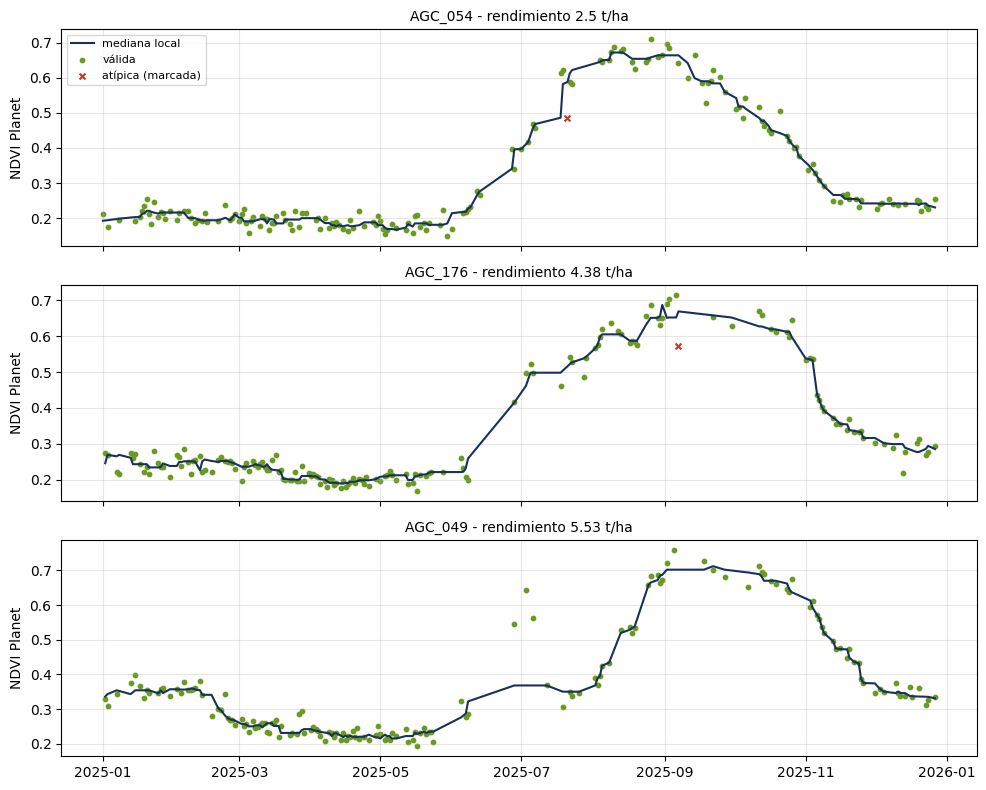

Básico: (107666, 97) | parcelas: 197 | {'Sentinel-2': 59040, 'Landsat': 48626}
S2: columnas vi6t no nulas: False | Landsat: índices S2 no nulos: False
Obs. válidas por parcela en la ventana abr-dic 2025 (nub<=20%):
      Planet  Sentinel2  Landsat
mean   108.9       45.4     24.1
min     77.0       38.0     14.0
50%    111.0       45.0     22.0
max    126.0       54.0     42.0
Última fecha Planet: 2025-12-30 | Última fecha S2 2025: 2025-12-31
Pares mismo día: 7199 | r = 0.986 | Planet = 1.008*S2 + 0.077 | sesgo medio (Pl-S2) = 0.079


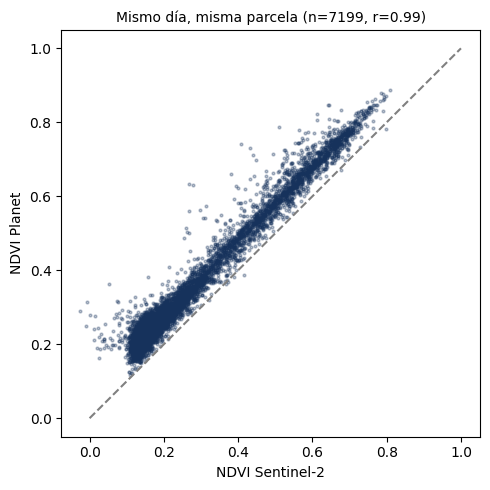

Archivos limpios guardados.
                        mean    min    50%    max
cal_pl_n_obs           108.4   75.0  111.0  126.0
cal_pl_hueco_max_dias   19.8   14.0   20.0   34.0
cal_pl_nub_media         0.5    0.0    0.4    1.9
cal_pl_primera          91.1   91.0   91.0   93.0
cal_pl_ultima          361.6  358.0  362.0  364.0
cal_s2_n_obs            44.3   37.0   44.0   54.0
cal_s2_hueco_max_dias   25.5   20.0   25.0   40.0
cal_s2_nub_media         0.5    0.0    0.4    2.2
cal_s2_primera          95.0   95.0   95.0   95.0
cal_s2_ultima          364.9  360.0  365.0  365.0
cal_ls_n_obs            24.1   14.0   22.0   42.0
cal_ls_hueco_max_dias   43.4   31.0   40.0   72.0
cal_ls_nub_media         0.4    0.0    0.2    4.1
cal_ls_primera          93.0   93.0   93.0   93.0
cal_ls_ultima          364.7  333.0  365.0  365.0


In [50]:
# Paso 3 · Planet (PRO 2025): auditoría, filtro de caídas bruscas (solo puntos aislados), comparación con Sentinel-2,
# archivos limpios por sensor (nubosidad <= 10 % y <= 20 %) y variables de calidad de la información por parcela.
def paso3_planet_y_limpieza():
    # ---- config ----
    CICLO_INI, CICLO_FIN = VENTANA_2025  # ventana de análisis: el ciclo oficial es abr-oct, pero la senescencia observada llega a noviembre
    pd.set_option("display.width", 160)

    y = pd.read_csv(F_Y, encoding="utf-8-sig").loc[:, lambda d: ~d.columns.str.startswith("Unnamed")]
    y = y.dropna(axis=1, how="all")
    pro = pd.read_csv(F_PRO, encoding="utf-8-sig")
    pro["fecha"] = pd.to_datetime(pro["fecha_captura"], format="%d/%m/%Y")
    print("PRO:", pro.shape, "| parcelas:", pro.ID_POLIGONO.nunique(), "| sensor:", pro.sensor.unique())
    print("Fechas:", pro.fecha.min().date(), "a", pro.fecha.max().date(), "| fechas únicas:", pro.fecha.nunique())
    print("Parcelas en PRO que están en tabla principal:", pro.ID_POLIGONO.isin(y.ID_POLIGONO).all(),
          "| parcelas de la tabla sin PRO:", sorted(set(y.ID_POLIGONO)-set(pro.ID_POLIGONO)))

    # ---- duplicados y cobertura ----
    dup_exact = pro.duplicated().sum()
    dup_key = pro.duplicated(["ID_POLIGONO","fecha"]).sum()
    print("Duplicados exactos:", dup_exact, "| duplicados ID+fecha:", dup_key)
    opp = pro.groupby("ID_POLIGONO").size()
    print("Obs. por parcela: min", opp.min(), "mediana", opp.median(), "max", opp.max())
    mes = pro.assign(mes=pro.fecha.dt.month).groupby("mes").agg(obs=("ID_POLIGONO","size"),
            con_ndvi=("ndvi_promedio", lambda s: s.notna().sum()))
    print(mes)

    # ---- faltantes vs nubosidad ----
    pro["tiene_ndvi"] = pro.ndvi_promedio.notna()
    print(pro.groupby("tiene_ndvi").porcentaje_nubosidad.describe().round(2))
    cols_idx = [c for c in pro.columns if any(c.startswith(k) for k in ["ndvi_","evi_","lai_","msavi_"])]
    print("¿Faltantes simultáneos en los 16 índices?:", (pro[cols_idx].isna().sum(axis=1).isin([0,16])).all())
    print("Distribución de nubosidad en obs. con NDVI:")
    print(pro.loc[pro.tiene_ndvi,"porcentaje_nubosidad"].describe(percentiles=[.5,.75,.9,.95]).round(2))

    # ---- umbrales ----
    v = pro[pro.tiene_ndvi]
    rows=[]
    for u in [0,5,10,20,30,50,100]:
        s = v[v.porcentaje_nubosidad<=u]; s_c = s[(s.fecha>=CICLO_INI)&(s.fecha<=CICLO_FIN)]
        g = s_c.groupby("ID_POLIGONO").size().reindex(y.ID_POLIGONO, fill_value=0)
        rows.append(dict(umbral=u, obs=len(s), obs_ciclo=len(s_c), prom_parcela_ciclo=round(g.mean(),1),
                         min_parcela_ciclo=g.min(), parcelas_con_obs=(g>0).sum()))
    umb_pro = pd.DataFrame(rows); print(umb_pro)

    # ---- consistencia ----
    chk = {}
    for ix in ["ndvi","evi","lai","msavi"]:
        a = v[[f"{ix}_min",f"{ix}_promedio",f"{ix}_max",f"{ix}_std"]]
        chk[ix] = dict(min_le_prom=(a.iloc[:,0]<=a.iloc[:,1]+1e-9).mean(), prom_le_max=(a.iloc[:,1]<=a.iloc[:,2]+1e-9).mean(),
                       std_neg=(a.iloc[:,3]<0).sum(), prom_min=a.iloc[:,1].min(), prom_max=a.iloc[:,1].max())
    print(pd.DataFrame(chk).T.round(4))
    print("Correlaciones entre promedios (Planet):")
    print(v[["ndvi_promedio","evi_promedio","lai_promedio","msavi_promedio"]].corr().round(3))
    # LAI2 = 5.405*NDVI(b8,b7) - 0.114 -> no es función del NDVI(b8,b6)
    print("Rango LAI implícito (LAI+0.114)/5.405:", ((v.lai_promedio+0.114)/5.405).describe().round(3)[["min","max"]].to_dict())

    # ---- filtro de caídas bruscas ----
    # Umbrales asimétricos: una nube o sombra baja el NDVI (0.08), mientras que un salto hacia arriba de 0.15 suele
    # ser artefacto.
    def filtro_caidas(df, col="ndvi_promedio", ventana=7, umbral_baja=0.08, umbral_alta=0.15):
        """Marca observaciones atípicas respecto a la mediana móvil de la propia parcela.
        Caídas > 0.08 (sombras/nubes parciales) y saltos > 0.15 (artefactos). No borra: marca.
        CORRECCIÓN: solo se marca un punto AISLADO. Si la observación anterior o la siguiente de la misma parcela
        se desvía en la misma dirección, es un cambio real (p. ej. el verdor de julio) y se conserva.
        Antes, el 52% de las marcas caía entre 15 jun y 31 jul y borraba ese primer verdor en 13 parcelas."""
        df = df.sort_values(["ID_POLIGONO","fecha"]).copy()
        med = df.groupby("ID_POLIGONO")[col].transform(lambda s: s.rolling(ventana, center=True, min_periods=3).median())
        df["ndvi_mediana_local"] = med
        abajo, arriba = df[col] < med - umbral_baja, df[col] > med + umbral_alta
        def con_vecino(m):
            g = m.groupby(df.ID_POLIGONO)
            return g.shift(1, fill_value=False).astype(bool) | g.shift(-1, fill_value=False).astype(bool)
        # Si la observación vecina se desvía en la misma dirección es un cambio REAL del cultivo (se conserva); solo
        # se marcan puntos aislados.
        racha = (abajo & con_vecino(abajo)) | (arriba & con_vecino(arriba))
        df["caida_brusca"] = (abajo | arriba) & ~racha
        df.attrs["conservadas"] = int(racha.sum())
        return df
    p20 = filtro_caidas(v[v.porcentaje_nubosidad<=20])
    print("Obs. marcadas como atípicas (nub<=20%):", p20.caida_brusca.sum(), f"({p20.caida_brusca.mean():.1%})",
          "| desviaciones conservadas por formar racha (cambio real):", p20.attrs["conservadas"])
    vj = p20[p20.caida_brusca & p20.fecha.between("2025-06-15", "2025-07-31")]
    print(f"Marcadas entre 15 jun y 31 jul: {len(vj)} ({len(vj)/max(p20.caida_brusca.sum(),1):.0%} del total)")
    print("Nubosidad media: marcadas", round(p20.loc[p20.caida_brusca,'porcentaje_nubosidad'].mean(),2),
          "| no marcadas", round(p20.loc[~p20.caida_brusca,'porcentaje_nubosidad'].mean(),2))

    # ---- figura ejemplo ----
    ej = y[y.CONJUNTO=="ENTRENAMIENTO"].sort_values("RENDIMIENTO_T_HA")
    ids = [ej.ID_POLIGONO.iloc[2], ej.ID_POLIGONO.iloc[len(ej)//2], ej.ID_POLIGONO.iloc[-3]]
    fig, axs = plt.subplots(3,1, figsize=(10,8), sharex=True)
    for ax, i in zip(axs, ids):
        d = p20[p20.ID_POLIGONO==i]
        ax.plot(d.fecha, d.ndvi_mediana_local, color="#16325c", lw=1.5, label="mediana local")
        ax.scatter(d.loc[~d.caida_brusca,"fecha"], d.loc[~d.caida_brusca,"ndvi_promedio"], s=10, color="#6a9a1f", label="válida")
        ax.scatter(d.loc[d.caida_brusca,"fecha"], d.loc[d.caida_brusca,"ndvi_promedio"], s=18, color="#c0392b", marker="x", label="atípica (marcada)")
        r = y.set_index("ID_POLIGONO").loc[i,"RENDIMIENTO_T_HA"]
        ax.set_title(f"{i} - rendimiento {r} t/ha", fontsize=10); ax.set_ylabel("NDVI Planet"); ax.grid(alpha=.3)
    axs[0].legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.savefig(FIG/"planet_ndvi_ejemplos.png", dpi=110); plt.show()

    # ---- Básico: carga y separación por sensor ----
    bas = pd.concat([pd.read_csv(F_B1, encoding="utf-8-sig"), pd.read_csv(F_B2, encoding="utf-8-sig")], ignore_index=True)
    bas["fecha"] = pd.to_datetime(bas["fecha_captura"], format="%d/%m/%Y")
    print("Básico:", bas.shape, "| parcelas:", bas.ID_POLIGONO.nunique(), "|", bas.sensor.value_counts().to_dict())
    s2 = bas[bas.sensor=="Sentinel-2"].copy(); ls = bas[bas.sensor=="Landsat"].copy()
    cols_s2 = [c for c in bas.columns if c.endswith(("_promedio","_std","_max","_min")) and not c.startswith("vi6t")]
    cols_ls = [c for c in bas.columns if c.startswith("vi6t")]
    print("S2: columnas vi6t no nulas:", s2[cols_ls].notna().any().any(), "| Landsat: índices S2 no nulos:", ls[cols_s2].notna().any().any())
    s2v = s2[s2.ndvi_promedio.notna()]; lsv = ls[ls.vi6t_promedio.notna()]

    # ---- comparación 2025: Planet vs Sentinel-2 ----
    def en_ciclo(d): return d[(d.fecha>=CICLO_INI)&(d.fecha<=CICLO_FIN)]
    comp = pd.DataFrame({
      "Planet": en_ciclo(v[v.porcentaje_nubosidad<=20]).groupby("ID_POLIGONO").size(),
      "Sentinel2": en_ciclo(s2v[s2v.porcentaje_nubosidad<=20]).groupby("ID_POLIGONO").size(),
      "Landsat": en_ciclo(lsv[lsv.porcentaje_nubosidad<=20]).groupby("ID_POLIGONO").size()}).reindex(y.ID_POLIGONO).fillna(0)
    print("Obs. válidas por parcela en la ventana abr-dic 2025 (nub<=20%):"); print(comp.describe().round(1).loc[["mean","min","50%","max"]])
    print("Última fecha Planet:", v.fecha.max().date(), "| Última fecha S2 2025:", s2v.fecha.max().date())
    m = pd.merge(p20[~p20.caida_brusca][["ID_POLIGONO","fecha","ndvi_promedio"]],
                 s2v[s2v.porcentaje_nubosidad<=20][["ID_POLIGONO","fecha","ndvi_promedio"]],
                 on=["ID_POLIGONO","fecha"], suffixes=("_pl","_s2"))
    # Mismo día y misma parcela: correlación y recta Planet = a·S2 + b. Muestra que los sensores no son
    # intercambiables.
    r = m.ndvi_promedio_pl.corr(m.ndvi_promedio_s2); b = np.polyfit(m.ndvi_promedio_s2, m.ndvi_promedio_pl, 1)
    print(f"Pares mismo día: {len(m)} | r = {r:.3f} | Planet = {b[0]:.3f}*S2 + {b[1]:.3f} | sesgo medio (Pl-S2) = {(m.ndvi_promedio_pl-m.ndvi_promedio_s2).mean():.3f}")
    fig, ax = plt.subplots(figsize=(5,5))
    ax.scatter(m.ndvi_promedio_s2, m.ndvi_promedio_pl, s=4, alpha=.3, color="#16325c"); ax.plot([0,1],[0,1],"--",color="grey")
    ax.set_xlabel("NDVI Sentinel-2"); ax.set_ylabel("NDVI Planet"); ax.set_title(f"Mismo día, misma parcela (n={len(m)}, r={r:.2f})", fontsize=10)
    plt.tight_layout(); plt.savefig(FIG/"planet_vs_s2_ndvi.png", dpi=110); plt.show()

    # ---- salidas limpias ----
    keep_pro = ["ID_POLIGONO","fecha","sensor","porcentaje_nubosidad"]+cols_idx
    for u in [10,20]:
        pc = filtro_caidas(v[v.porcentaje_nubosidad<=u])
        pc[keep_pro+["caida_brusca"]].to_csv(OUT/f"planet_clean_nub{u}.csv", index=False)
        s2c = filtro_caidas(s2v[s2v.porcentaje_nubosidad<=u])
        s2c[["ID_POLIGONO","fecha","sensor","porcentaje_nubosidad"]+cols_s2+["caida_brusca"]].to_csv(OUT/f"s2_clean_nub{u}.csv", index=False)
        lsv[lsv.porcentaje_nubosidad<=u][["ID_POLIGONO","fecha","sensor","porcentaje_nubosidad"]+cols_ls].to_csv(OUT/f"landsat_clean_nub{u}.csv", index=False)
    print("Archivos limpios guardados.")

    # ---- variables de calidad por parcela ----
    # Variables cal_*: describen la DISPONIBILIDAD de imágenes (no el cultivo); se usan para banderas, no como
    # predictores.
    def calidad(df, pref, col_ok):
        d = en_ciclo(df[col_ok]).sort_values(["ID_POLIGONO","fecha"])
        g = d.groupby("ID_POLIGONO")
        gap = g.fecha.apply(lambda s: s.diff().dt.days.max())
        q = pd.DataFrame({f"cal_{pref}_n_obs": g.size(), f"cal_{pref}_hueco_max_dias": gap,
                          f"cal_{pref}_nub_media": g.porcentaje_nubosidad.mean(),
                          f"cal_{pref}_primera": g.fecha.min().dt.dayofyear, f"cal_{pref}_ultima": g.fecha.max().dt.dayofyear})
        return q
    p20c = filtro_caidas(v[v.porcentaje_nubosidad<=20]); s20c = filtro_caidas(s2v[s2v.porcentaje_nubosidad<=20])
    qual = pd.concat([calidad(p20c, "pl", ~p20c.caida_brusca), calidad(s20c, "s2", ~s20c.caida_brusca),
                      calidad(lsv[lsv.porcentaje_nubosidad<=20], "ls", slice(None))], axis=1)
    qual = qual.reindex(y.ID_POLIGONO); qual.index.name = "ID_POLIGONO"
    n_cols = [c for c in qual.columns if c.endswith("_n_obs")]; qual[n_cols] = qual[n_cols].fillna(0).astype(int)
    qual.round(2).to_csv(OUT/"quality_features.csv")
    print(qual.describe().round(1).T[["mean","min","50%","max"]])

paso3_planet_y_limpieza()

## Paso 4 · Base maestra: fenología, historial, topografía y Tmax

### Explicación

**Objetivo.** Convertir las series de imágenes de cada parcela en variables que describan su temporada 2025, y unirlas con historial, topografía y clima.

**Procedimiento.**
- **Fenología (función `fenologia`).** La serie de un índice se suaviza con una mediana móvil centrada de 21 días. Sobre la curva suavizada se definen:
  - *base*: mediana enero–mayo (suelo desnudo antes de sembrar);
  - *pico*: máximo entre el 10 de julio y el 30 de noviembre. Se excluye el brote de inicios de julio porque corresponde a malezas que nacen con las primeras lluvias, antes del barbecho y la siembra;
  - *subida* y *secado*: cruces del 50 % entre la base y el pico (antes y después del pico);
  - *AUC*: área de (valor − base) entre subida y secado, una medida del vigor acumulado;
  - *post30*: valor 25-35 días después del pico (llenado de grano) y *brote temprano* (aparte).
- Con Planet se calcula para NDVI, MSAVI y LAI, más la heterogeneidad dentro de la parcela alrededor del pico. Con Sentinel-2, NDVI y los índices de humedad/estrés alrededor del pico (NDWI, MSI, NDSVI, FAPAR).
- **Landsat:** VI6T medio y mínimo de julio a octubre (índice espectral-térmico).
- **Historial 2022-2024:** pico anual de NDVI de Sentinel-2, como medida del potencial "habitual" de la parcela.
- **Topografía** (elevación y pendiente) y **Tmax** por temporada con su anomalía contra 2022-2024.
- Al final se calculan correlaciones de Spearman con el rendimiento, también **dentro de cada municipio** (restando la media municipal), para ver qué señal satelital queda una vez descontada la ubicación.

**Justificación.** Las fechas y valores relativos a cada parcela son más comparables entre parcelas que los valores en una fecha fija, porque no todas se sembraron el mismo día. La correlación dentro del municipio evita confundir "esta zona rinde más" con "este índice predice el rendimiento".

**Relación con el proyecto.** Es la primera versión de la tabla de modelado. La fenología de este paso se reemplaza después por la versión con suavizado Whittaker (pasos 8 y 9), pero el historial, la topografía y Landsat se conservan.

In [51]:
# Paso 4 · Base maestra v1: resume las series satelitales de cada parcela en variables de la temporada 2025
# (fenología con mediana móvil de 21 días), y las une con historial 2022-2024, Landsat, topografía y Tmax.
def paso4_base_maestra():
    # ---- config ----
    VENTANA = VENTANA_2025
    tp = pd.read_csv(OUT/"tabla_principal_limpia.csv")
    cal = pd.read_csv(OUT/"quality_features.csv")
    pl = pd.read_csv(OUT/"planet_clean_nub20.csv", parse_dates=["fecha"]); pl = pl[~pl.caida_brusca]
    s2 = pd.read_csv(OUT/"s2_clean_nub20.csv", parse_dates=["fecha"]); s2 = s2[~s2.caida_brusca]
    ls = pd.read_csv(OUT/"landsat_clean_nub20.csv", parse_dates=["fecha"])
    print("Insumos:", tp.shape, cal.shape, pl.shape, s2.shape, ls.shape)

    # ---- función fenológica ----
    def fenologia(d, col, pref, suav="21D"):
        """Variables fenológicas relativas a la parcela sobre una serie (fecha, valor).
        - Base = mediana ene-may (suelo desnudo).
        - Pico del cultivo = máximo entre 10 jul y 30 nov. Se excluye el brote de principios de julio
          (malezas/vegetación que brota con las primeras lluvias, antes del barbecho y la siembra; lo ven Planet y S2).
        - Subida = ÚLTIMO cruce ascendente del 50% (base-pico) antes del pico; secado = primer cruce descendente después.
        - AUC = área de (valor - base) entre subida y secado, sobre días reales.
        - brote_temprano = máximo 15 jun-15 jul menos base (variable aparte)."""
        s = d.set_index("fecha")[col].dropna().sort_index()
        if len(s) < 5: return {}
        # Ventana CENTRADA: una ventana solo hacia atrás retrasaría ~7 días todas las fechas fenológicas.
        sm = s.rolling(suav, center=True).median()   # centrada: una ventana solo hacia atrás retrasa ~7 días las fechas
        base = sm[:"2025-05-31"].median()
        # El pico se busca desde el 10 de julio para no confundir el brote de malezas de inicios de julio con la
        # cebada.
        w = sm["2025-07-10":"2025-11-30"]
        pico_f, pico = w.idxmax(), w.max()
        amp = pico - base; mitad = base + 0.5*amp
        ant = sm[VENTANA[0]:pico_f]; debajo = ant[ant < mitad]
        sub = ant[ant.index > debajo.index.max()].index.min() if len(debajo) else ant.index.min()
        des = sm[pico_f:VENTANA[1]]; sec = des[des < mitad].index.min()
        if pd.isna(sec): sec = des.index.max()
        a = (sm[sub:sec] - base).clip(lower=0)
        auc = _trapz(a.values, (a.index - a.index[0]).days) if len(a) > 1 else np.nan
        post = sm[pico_f + pd.Timedelta(days=25): pico_f + pd.Timedelta(days=35)]
        brote = sm["2025-06-15":"2025-07-15"].max() - base
        doy = lambda t: t.dayofyear if pd.notna(t) else np.nan
        return {f"{pref}_base": base, f"{pref}_pico": pico, f"{pref}_amplitud": amp, f"{pref}_auc": auc,
                f"{pref}_doy_subida": doy(sub), f"{pref}_doy_pico": doy(pico_f), f"{pref}_doy_secado": doy(sec),
                f"{pref}_dias_sub_pico": (pico_f - sub).days, f"{pref}_duracion": (sec - sub).days,
                f"{pref}_post30": post.mean() if len(post) else np.nan,
                f"{pref}_caida_post30": (pico - post.mean()) if len(post) else np.nan,
                f"{pref}_brote_temprano": brote}

    def valor_en_ventana(d, col, pref, centro, dias=20, stat="mean"):
        if pd.isna(centro): return {pref: np.nan}
        w = d[(d.fecha >= centro - pd.Timedelta(days=dias)) & (d.fecha <= centro + pd.Timedelta(days=dias))][col]
        return {pref: getattr(w, stat)() if len(w) else np.nan}

    # ---- Planet ----
    rows = []
    for i, d in pl.groupby("ID_POLIGONO"):
        r = {"ID_POLIGONO": i}
        r.update(fenologia(d, "ndvi_promedio", "pl_ndvi"))
        r.update(fenologia(d, "msavi_promedio", "pl_msavi"))
        r.update(fenologia(d, "lai_promedio", "pl_lai"))
        pico_f = pd.Timestamp("2025-01-01") + pd.Timedelta(days=r["pl_ndvi_doy_pico"]-1)
        r.update(valor_en_ventana(d, "ndvi_std", "pl_ndvi_std_pico", pico_f))      # heterogeneidad intra-parcela
        r.update(valor_en_ventana(d, "ndvi_min", "pl_ndvi_min_pico", pico_f))
        rows.append(r)
    f_pl = pd.DataFrame(rows); print("Planet:", f_pl.shape)

    # ---- Sentinel-2 ----
    rows = []
    for i, d in s2.groupby("ID_POLIGONO"):
        r = {"ID_POLIGONO": i}
        r.update(fenologia(d, "ndvi_promedio", "s2_ndvi"))
        pico_f = pd.Timestamp("2025-01-01") + pd.Timedelta(days=r["s2_ndvi_doy_pico"]-1)
        for ix in ["ndwi", "msi", "ndsvi", "fapar"]:                             # humedad, estrés, senescencia, radiación
            r.update(valor_en_ventana(d, f"{ix}_promedio", f"s2_{ix}_pico", pico_f))
        r.update(valor_en_ventana(d, "ndwi_promedio", "s2_ndwi_post30", pico_f + pd.Timedelta(days=30), dias=10))
        r.update(valor_en_ventana(d, "ndvi_std", "s2_ndvi_std_pico", pico_f))
        rows.append(r)
    f_s2 = pd.DataFrame(rows); print("Sentinel-2:", f_s2.shape)

    # ---- Landsat ----
    l25 = ls[(ls.fecha >= "2025-07-01") & (ls.fecha <= "2025-10-31")]
    f_ls = l25.groupby("ID_POLIGONO").vi6t_promedio.agg(ls_vi6t_media_jul_oct="mean", ls_vi6t_min_jul_oct="min").reset_index()
    print("Landsat:", f_ls.shape)

    # ---- historial 2022-2024 ----
    def pico_anual(d, anio):
        s = d.set_index("fecha").ndvi_promedio.sort_index()
        s = s[f"{anio}-01-01":f"{anio}-12-31"].rolling("21D", center=True).median()
        return s.max() if len(s) else np.nan
    rows = []
    for i, d in s2.groupby("ID_POLIGONO"):
        r = {"ID_POLIGONO": i}
        for a in [2022, 2023, 2024]: r[f"hist_ndvi_pico_{a}"] = pico_anual(d, a)
        rows.append(r)
    f_h = pd.DataFrame(rows)
    hc = [f"hist_ndvi_pico_{a}" for a in [2022, 2023, 2024]]
    f_h["hist_ndvi_pico_media"] = f_h[hc].mean(axis=1); f_h["hist_ndvi_pico_std"] = f_h[hc].std(axis=1)
    print("Historial:", f_h.shape)

    # ---- topografía y clima ----
    topo = pd.read_csv(F_TOPO).rename(columns={"ID_POLIGON": "ID_POLIGONO"})
    topo = topo[["ID_POLIGONO", "Elevacion_mean", "Elevacion_std", "Pendiente_mean", "Pendiente_std"]]
    topo.columns = ["ID_POLIGONO", "topo_elev_media", "topo_elev_std", "topo_pend_media", "topo_pend_std"]
    tx = pd.read_csv(F_TMAX).rename(columns={"ID_POLIGON": "ID_POLIGONO"}).set_index("ID_POLIGONO")
    mc = lambda a, meses: [f"Tmax_{a}_{m:02d}_mean" for m in meses]
    clim = pd.DataFrame(index=tx.index)
    clim["clim_tmax_jun_ago_2025"] = tx[mc(2025, [6,7,8])].mean(axis=1)
    clim["clim_tmax_sep_nov_2025"] = tx[mc(2025, [9,10,11])].mean(axis=1)
    hist_ja = pd.concat([tx[mc(a, [6,7,8])].mean(axis=1) for a in [2022,2023,2024]], axis=1).mean(axis=1)
    hist_sn = pd.concat([tx[mc(a, [9,10,11])].mean(axis=1) for a in [2022,2023,2024]], axis=1).mean(axis=1)
    clim["clim_tmax_anom_jun_ago"] = clim.clim_tmax_jun_ago_2025 - hist_ja
    clim["clim_tmax_anom_sep_nov"] = clim.clim_tmax_sep_nov_2025 - hist_sn
    clim = clim.reset_index()
    print("Topografía:", topo.shape, "| Clima (solo Tmax disponible por parcela):", clim.shape)

    # ---- unión ----
    bm = tp.rename(columns={"AREA_HA": "area_ha", "RENDIMIENTO_T_HA": "y"})
    for f in [cal, f_pl, f_s2, f_ls, f_h, topo, clim]:
        bm = bm.merge(f, on="ID_POLIGONO", how="left")
    assert len(bm) == 197 and bm.ID_POLIGONO.is_unique
    print("Base maestra v1:", bm.shape)
    na = bm.isna().sum(); print("Columnas con faltantes:"); print(na[na > 0])

    # ---- revisión rápida de señal ----
    tr = bm[bm.CONJUNTO == "ENTRENAMIENTO"]
    num = tr.select_dtypes("number").drop(columns=["y", "rend_redondo"], errors="ignore")
    corr = num.corrwith(tr.y, method="spearman").dropna().sort_values(key=abs, ascending=False)
    print("Top 20 correlaciones de Spearman con el rendimiento (138 parcelas):"); print(corr.head(20).round(3))
    # ¿Qué señal satelital queda DENTRO de cada municipio? (correlación parcial: se resta la media municipal)
    dm = tr.copy(); cols = num.columns
    # Se resta la media del municipio: así la correlación mide señal DENTRO de cada zona y no diferencias entre zonas.
    dm[cols] = dm[cols] - dm.groupby("Municipio")[cols].transform("mean")
    dm["y_dm"] = dm.y - dm.groupby("Municipio").y.transform("mean")
    corr_w = dm[cols].corrwith(dm.y_dm, method="spearman").dropna().sort_values(key=abs, ascending=False)
    print("Top 15 correlaciones DENTRO de municipio:"); print(corr_w.head(15).round(3))

    # ---- salida ----
    bm.to_csv(OUT/"base_maestra_v1.csv", index=False)
    bloques = {p: [c for c in bm.columns if c.startswith(p)] for p in ["cal_","pl_","s2_","ls_","hist_","topo_","clim_"]}
    print({k: len(v) for k, v in bloques.items()}, "| total variables:", sum(len(v) for v in bloques.values()) + 1)

paso4_base_maestra()

Insumos: (197, 7) (197, 16) (32142, 21) (39305, 93) (28083, 8)
Planet: (197, 39)
Sentinel-2: (197, 19)
Landsat: (197, 3)
Historial: (197, 6)
Topografía: (197, 5) | Clima (solo Tmax disponible por parcela): (197, 5)
Base maestra v1: (197, 93)
Columnas con faltantes:
y                         59
rend_redondo              59
pl_ndvi_post30            13
pl_ndvi_caida_post30      13
pl_msavi_post30           10
pl_msavi_caida_post30     10
pl_lai_post30             12
pl_lai_caida_post30       12
s2_ndvi_post30             6
s2_ndvi_caida_post30       6
s2_ndvi_brote_temprano    18
dtype: int64
Top 20 correlaciones de Spearman con el rendimiento (138 parcelas):
clim_tmax_anom_jun_ago    0.696
clim_tmax_anom_sep_nov    0.594
clim_tmax_sep_nov_2025   -0.523
pl_msavi_base             0.510
cal_ls_n_obs              0.487
s2_ndvi_base              0.471
cal_pl_hueco_max_dias     0.444
cal_ls_hueco_max_dias    -0.436
pl_ndvi_doy_secado        0.428
s2_ndvi_doy_secado        0.423
pl_msavi_doy_s

## Paso 5 · Análisis espacial, validación y vecinos. Requiere geopandas

### Explicación

**Objetivo.** Entender cómo están distribuidas las parcelas en el espacio y elegir un esquema de validación que reproduzca la situación de las 59 parcelas que hay que predecir.

**Procedimiento.**
1. Se calculan centroides en km (EPSG:6372) y la distancia de cada parcela de predicción a la parcela de entrenamiento más cercana.
2. **Comparación de esquemas de validación (enfoque tipo NNDM).** Para cuatro esquemas (K-Fold aleatorio, estratificado por municipio, bloques espaciales k-means y dejar un municipio fuera) se mide la distribución de distancias "parcela de validación → parcela de entrenamiento más cercana" y se compara con la distribución real de las 59 usando la **distancia de Wasserstein** (qué tanto hay que "mover" una distribución para convertirla en la otra). El esquema con menor Wasserstein es el que mejor imita la realidad.
3. **Índice de Moran** del rendimiento con 5 vecinas: mide si parcelas cercanas tienen rendimientos parecidos (autocorrelación espacial), con un valor p por permutaciones. Se repite restando la media municipal.
4. Se evalúa la variable de vecinas para distintos *k* con K-Fold 5 × 10, sin fuga.
5. Se guardan las coordenadas, el GeoJSON de parcelas y las tablas.

**Interpretación.** Las 59 están intercaladas con el entrenamiento (mediana ≈ 0.35 km). La validación estratificada por municipio reproduce bien esa situación; los bloques espaciales y dejar un municipio fuera simulan parcelas mucho más lejanas que las reales. Por eso la estratificada se volvió la validación oficial del equipo, y los esquemas espaciales se reportan después (paso 21) como prueba de uso en zonas nuevas.

**Relación con el proyecto.** Aquí se fija `k = 12` vecinas y la validación con la que se compararon todos los modelos.

(197, 12) | CRS original: EPSG:4326 | polígonos inválidos: 0
Diferencia media entre área calculada y área_ha: 0.045 ha
Predicción → entrenamiento más cercano (km): mediana 0.35 | P90 1.07 | máx 1.91
Extensión del área de estudio (km): [42.1 50.9]
Real (predicción): mediana 0.349 km
                              esquema  mediana_km  p90_km  W_vs_real
                 K-Fold aleatorio (5)       0.415   1.419      0.261
      Estratificado por municipio (5)       0.423   1.281      0.220
Bloques espaciales k-means (8 grupos)       3.453   9.423      3.590
             Dejar un municipio fuera       4.847   9.880      4.924


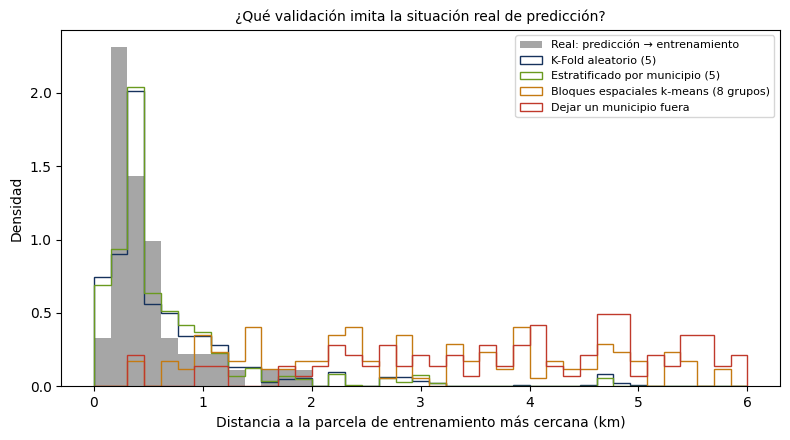

Moran I del rendimiento (k=5 vecinos): 0.694 | p = 0.001
Moran I dentro de municipio (rendimiento menos media municipal): -0.003 | p = 0.460
K-Fold aleatorio 5 × 10 repeticiones (138 parcelas):
                      RMSE  RMSE_sd    MAE     R2
Media global         0.855    0.004  0.755 -0.016
Media del municipio  0.514    0.005  0.338  0.633
Vecinos k=1          0.563    0.031  0.392  0.558
Vecinos k=3          0.517    0.015  0.381  0.628
Vecinos k=5          0.518    0.007  0.381  0.626
Vecinos k=8          0.507    0.005  0.369  0.643
Vecinos k=12         0.500    0.006  0.362  0.652


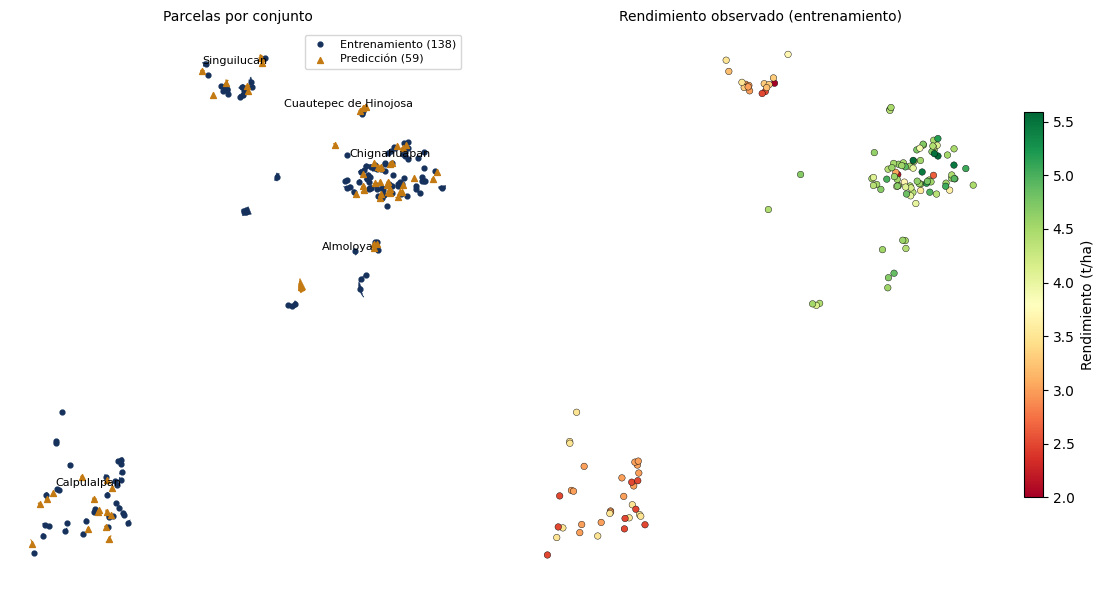

Guardado: coordenadas_parcelas.csv, parcelas.geojson, comparacion_esquemas_validacion.csv, evaluacion_vecinos.csv


In [52]:
# Paso 5 · Análisis espacial: coordenadas en km, comparación de esquemas de validación contra la situación real
# de las 59 (distancia de Wasserstein), autocorrelación espacial (Moran) y desempeño de la variable de vecinas.
def paso5_espacial():
    import geopandas as gpd   # solo este paso lo necesita
    SHP = preparar_shapefile()
    # ---- config ----
    g = gpd.read_file(SHP).rename(columns={"ID_POLIGON": "ID_POLIGONO"})
    tp = pd.read_csv(OUT/"tabla_principal_limpia.csv")
    g = g.merge(tp[["ID_POLIGONO", "RENDIMIENTO_T_HA"]], on="ID_POLIGONO")
    # EPSG:6372 (México ITRF2008 LCC) está en metros: necesario para medir distancias reales entre parcelas.
    gm = g.to_crs(6372)                       # México ITRF2008 / LCC (metros)
    g["x_km"], g["y_km"] = gm.centroid.x/1000, gm.centroid.y/1000
    cen = gm.centroid.to_crs(4326); g["lon"], g["lat"] = cen.x, cen.y   # centroide en metros, luego a grados
    print(g.shape, "| CRS original:", g.crs, "| polígonos inválidos:", (~g.is_valid).sum())
    print("Diferencia media entre área calculada y área_ha:", round((gm.area/1e4 - g["área_ha"]).abs().mean(), 3), "ha")

    # ---- ¿qué tan intercaladas están? ----
    xy = g[["x_km","y_km"]].values; D = cdist(xy, xy); np.fill_diagonal(D, np.inf)
    tr = (g.CONJUNTO=="ENTRENAMIENTO").values; pr = ~tr
    d_pred = D[pr][:, tr].min(1)
    print(f"Predicción → entrenamiento más cercano (km): mediana {np.median(d_pred):.2f} | P90 {np.percentile(d_pred,90):.2f} | máx {d_pred.max():.2f}")
    print("Extensión del área de estudio (km):", ((xy.max(0)-xy.min(0))).round(1))

    # ---- comparación de esquemas de validación (enfoque NNDM) ----
    # Para cada esquema se mide la distancia de cada parcela de prueba a la parcela de entrenamiento más cercana
    # y se compara con la situación real de predicción (d_pred). Menor distancia de Wasserstein = imita mejor la realidad.
    T = g[tr].reset_index(drop=True); Dt = cdist(T[["x_km","y_km"]], T[["x_km","y_km"]])
    km = KMeans(n_clusters=8, n_init=10, random_state=0).fit(T[["x_km","y_km"]])
    esquemas = {
     "K-Fold aleatorio (5)": lambda s: KFold(5, shuffle=True, random_state=s).split(T),
     "Estratificado por municipio (5)": lambda s: StratifiedKFold(5, shuffle=True, random_state=s).split(T, T.Municipio.where(T.Municipio.map(T.Municipio.value_counts())>=5, "Otros")),
     "Bloques espaciales k-means (8 grupos)": lambda s: GroupKFold(5).split(T, groups=km.labels_),
     "Dejar un municipio fuera": lambda s: GroupKFold(T.Municipio.nunique()).split(T, groups=T.Municipio),
    }
    res, dist_cv = [], {}
    for nombre, gen in esquemas.items():
        ds = []
        for s in range(5):
            for a, b in gen(s):
                ds.extend(Dt[np.ix_(b, a)].min(1))
        ds = np.array(ds); dist_cv[nombre] = ds
        # Wasserstein compara la distribución de distancias de cada validación con la real de las 59: menor = imita
        # mejor.
        res.append(dict(esquema=nombre, mediana_km=np.median(ds), p90_km=np.percentile(ds,90), W_vs_real=wasserstein_distance(ds, d_pred)))
    res = pd.DataFrame(res).round(3); print(f"Real (predicción): mediana {np.median(d_pred):.3f} km"); print(res.to_string(index=False))

    # ---- figura distancias ----
    fig, ax = plt.subplots(figsize=(8,4.5))
    bins = np.linspace(0, 6, 40)
    ax.hist(d_pred, bins=bins, density=True, histtype="stepfilled", alpha=.35, color="black", label="Real: predicción → entrenamiento")
    for (n, ds), c in zip(dist_cv.items(), ["#16325c","#6a9a1f","#c47a12","#c0392b"]):
        ax.hist(ds, bins=bins, density=True, histtype="step", lw=1.8, color=c, label=n)
    ax.set_xlabel("Distancia a la parcela de entrenamiento más cercana (km)"); ax.set_ylabel("Densidad"); ax.legend(fontsize=8)
    ax.set_title("¿Qué validación imita la situación real de predicción?", fontsize=10); plt.tight_layout()
    plt.savefig(FIG/"validacion_distancias.png", dpi=110); plt.show()

    # ---- autocorrelación espacial del rendimiento (Moran I) ----
    # Índice de Moran con 5 vecinas y prueba por 999 permutaciones: ¿parcelas cercanas rinden parecido?
    def moran(y, xy, k=5):
        n = len(y); Dm = cdist(xy, xy); np.fill_diagonal(Dm, np.inf)
        W = np.zeros((n,n)); idx = np.argsort(Dm, 1)[:, :k]
        for i in range(n): W[i, idx[i]] = 1/k
        z = y - y.mean(); I = (n/W.sum()) * (z @ W @ z) / (z @ z)
        rng = np.random.default_rng(0); perm = [ (n/W.sum()) * ((zp:=rng.permutation(z)) @ W @ zp) / (z @ z) for _ in range(999)]
        return I, (np.sum(np.array(perm) >= I)+1)/1000
    yv = T.RENDIMIENTO_T_HA.values; I, p = moran(yv, T[["x_km","y_km"]].values)
    print(f"Moran I del rendimiento (k=5 vecinos): {I:.3f} | p = {p:.3f}")
    T["y_dm"] = yv - T.groupby("Municipio").RENDIMIENTO_T_HA.transform("mean")
    I2, p2 = moran(T.y_dm.values, T[["x_km","y_km"]].values)
    print(f"Moran I dentro de municipio (rendimiento menos media municipal): {I2:.3f} | p = {p2:.3f}")

    # ---- variable de vecinos: evaluación sin fuga ----
    class _Coords:   # coordenadas en memoria (el CSV se escribe al final de este mismo script)
        def __init__(self, df): self.df = df.set_index("ID_POLIGONO")[["x_km","y_km"]]
        def xy(self, ids): return self.df.loc[list(ids)].values
    coords_mem = _Coords(T)
    def pred_vecinos(a, b, k):
        return VecinosRendimiento(k=k).fit(a.ID_POLIGONO, a.RENDIMIENTO_T_HA, coords_mem).transform(b.ID_POLIGONO)
    def pred_muni(tr_df, te_df):
        m = tr_df.groupby("Municipio").RENDIMIENTO_T_HA.mean(); return te_df.Municipio.map(m).fillna(tr_df.RENDIMIENTO_T_HA.mean()).values
    def evalua(fn, reps=10):
        out = []
        for s in range(reps):
            pred = np.zeros(len(T))
            for a, b in KFold(5, shuffle=True, random_state=s).split(T):
                pred[b] = fn(T.iloc[a], T.iloc[b])
            e = yv - pred; out.append((np.sqrt((e**2).mean()), np.abs(e).mean(), 1-(e**2).sum()/((yv-yv.mean())**2).sum()))
        o = np.array(out); return dict(RMSE=o[:,0].mean(), RMSE_sd=o[:,0].std(), MAE=o[:,1].mean(), R2=o[:,2].mean())
    filas = {"Media global": evalua(lambda a,b: np.full(len(b), a.RENDIMIENTO_T_HA.mean())),
             "Media del municipio": evalua(pred_muni)}
    for k in [1,3,5,8,12]:
        filas[f"Vecinos k={k}"] = evalua(lambda a,b,k=k: pred_vecinos(a, b, k))
    tabla_vec = pd.DataFrame(filas).T.round(3); print("K-Fold aleatorio 5 × 10 repeticiones (138 parcelas):"); print(tabla_vec)

    # ---- mapa ----
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    gp = g.to_crs(6372)
    gp[gp.CONJUNTO=="ENTRENAMIENTO"].plot(ax=axs[0], color="#16325c", edgecolor="#16325c", lw=.3)
    gp[gp.CONJUNTO=="PREDICCION"].plot(ax=axs[0], color="#c47a12", edgecolor="#c47a12", lw=.3)
    cx, cy = gp.centroid.x, gp.centroid.y
    axs[0].scatter(cx[gp.CONJUNTO=="ENTRENAMIENTO"], cy[gp.CONJUNTO=="ENTRENAMIENTO"], s=12, color="#16325c", label="Entrenamiento (138)")
    axs[0].scatter(cx[gp.CONJUNTO=="PREDICCION"], cy[gp.CONJUNTO=="PREDICCION"], s=18, color="#c47a12", marker="^", label="Predicción (59)")
    for m, d in gp.groupby("Municipio"):
        if len(d) >= 9: axs[0].annotate(m, (d.centroid.x.mean(), d.centroid.y.mean()), fontsize=8, ha="center", xytext=(0, 14), textcoords="offset points")
    axs[0].legend(fontsize=8); axs[0].set_title("Parcelas por conjunto", fontsize=10); axs[0].set_axis_off()
    t = gp[gp.CONJUNTO=="ENTRENAMIENTO"]
    sc = axs[1].scatter(t.centroid.x, t.centroid.y, c=t.RENDIMIENTO_T_HA, cmap="RdYlGn", s=22, edgecolor="k", lw=.3)
    plt.colorbar(sc, ax=axs[1], label="Rendimiento (t/ha)", shrink=.7); axs[1].set_title("Rendimiento observado (entrenamiento)", fontsize=10); axs[1].set_axis_off()
    plt.tight_layout(); plt.savefig(FIG/"mapa_parcelas.png", dpi=110); plt.show()

    # ---- salidas ----
    g[["ID_POLIGONO","CONJUNTO","Municipio","Estado","lon","lat","x_km","y_km"]].to_csv(OUT/"coordenadas_parcelas.csv", index=False)
    g.to_crs(4326)[["ID_POLIGONO","CONJUNTO","Municipio","Estado","área_ha","geometry"]].to_file(OUT/"parcelas.geojson", driver="GeoJSON")
    res.to_csv(OUT/"comparacion_esquemas_validacion.csv", index=False); tabla_vec.to_csv(OUT/"evaluacion_vecinos.csv")
    print("Guardado: coordenadas_parcelas.csv, parcelas.geojson, comparacion_esquemas_validacion.csv, evaluacion_vecinos.csv")

paso5_espacial()

## Paso 6 · Diccionario de variables

### Explicación

**Objetivo.** Documentar cada columna de los archivos limpios y de la base maestra v1: descripción, unidad y bloque al que pertenece.

**Cómo funciona.** Las descripciones se generan a partir del prefijo del nombre (`pl_` = Planet, `s2_` = Sentinel-2, `ls_` = Landsat, `cal_` = calidad, `hist_` = historial, `topo_` = topografía, `clim_` = clima) y del sufijo fenológico (`_pico`, `_auc`, `_doy_subida`, etc.). Un `assert` detiene el notebook si alguna columna queda sin descripción.

**Nota.** Las fórmulas de índices que aparecen son referencias; los índices ya vienen calculados por el proveedor y no los recalculamos. Este diccionario se actualiza para la base v3 en el paso 12.

In [53]:
# Paso 6 · Diccionario de la base maestra v1: descripción y unidad de cada columna, generadas por patrón de nombre.
# El assert garantiza que ninguna variable quede sin documentar.
def paso6_diccionario():
    # ---- config ----

    # ---- archivos limpios ----
    filas = [
    ("planet_clean_nub*.csv","ID_POLIGONO","Identificador de parcela (AGC_001 a AGC_197)","texto"),
    ("planet/s2/landsat_clean_nub*.csv","fecha","Fecha de captura (AAAA-MM-DD)","fecha"),
    ("planet/s2/landsat_clean_nub*.csv","porcentaje_nubosidad","Nubosidad de la escena (%); filtrada a <=10 o <=20","%"),
    ("planet_clean_nub*.csv","ndvi_{promedio,std,max,min}","NDVI Planet (b8-b6)/(b8+b6) (fórmula de referencia bibliográfica; el índice ya viene calculado por el proveedor: confirmar con su documentación): media, desviación, máximo y mínimo dentro de la parcela","adim."),
    ("planet_clean_nub*.csv","evi_{...}","EVI Planet","adim."),
    ("planet_clean_nub*.csv","lai_{...}","LAI2 Planet = 5.405*(b8-b7)/(b8+b7)-0.114 (red edge) (fórmula de referencia bibliográfica; el índice ya viene calculado por el proveedor: confirmar con su documentación). NO equivale al LAI de Sentinel-2","m2/m2 aprox."),
    ("planet_clean_nub*.csv","msavi_{...}","MSAVI Planet","adim."),
    ("planet/s2_clean_nub*.csv","caida_brusca","True si la obs. se aleja de la mediana móvil (7 obs.) de su parcela: >0.08 abajo o >0.15 arriba. Se marca, no se borra","bool"),
    ("s2_clean_nub*.csv","{indice}_{promedio,std,max,min}","22 índices Sentinel-2 del Dataset Básico (NDVI, EVI, CRC, MCRC, NDSVI, SRNDI, MRA, LAI, FAPAR, SAVI, NDTI, STI, NDWI, ENDWI, MSI, EMSI, DSWI2-5, NDDI, ENDDI)","adim."),
    ("landsat_clean_nub*.csv","vi6t_{promedio,std,max,min}","VI6T Landsat (B3-ST_B10)/(B3+ST_B10) (fórmula de referencia bibliográfica; el índice ya viene calculado por el proveedor: confirmar con su documentación)","adim."),
    ("coordenadas_parcelas.csv","lon, lat","Centroide de la parcela (WGS84)","grados"),
    ("coordenadas_parcelas.csv","x_km, y_km","Centroide de la parcela en EPSG:6372 (México ITRF2008 LCC)","km"),
    ]
    dic = pd.DataFrame(filas, columns=["archivo","variable","descripcion","unidad"])

    # ---- base maestra ----
    bm = pd.read_csv(OUT/"base_maestra_v1.csv", nrows=1)
    SENSOR = {"pl":"Planet", "s2":"Sentinel-2", "ls":"Landsat"}
    FENO = {
     "base":("Valor típico de ene-may 2025 (suelo desnudo)","adim."), "pico":("Máximo de la curva suavizada entre 10 jul y 30 nov","adim."),
     "amplitud":("pico - base","adim."), "auc":("Área de (valor - base) entre subida y secado","adim.·días"),
     "doy_subida":("Día del año del último cruce ascendente del 50% (base-pico) antes del pico","día del año"),
     "doy_pico":("Día del año del pico","día del año"), "doy_secado":("Día del año del primer cruce descendente del 50% después del pico. Puede caer después de octubre (fuera de la ventana oficial abr-oct del ciclo): observación posterior, no evidencia anticipada de cosecha; no es regresor del modelo final","día del año"),
     "dias_sub_pico":("Días de la subida al pico","días"), "duracion":("Días de la subida al secado","días"),
     "post30":("Valor medio 25-35 días después del pico (llenado de grano)","adim."), "caida_post30":("pico - post30","adim."),
     "brote_temprano":("Máximo 15 jun-15 jul menos base: verdor previo a la siembra (malezas/barbecho), no es la cebada","adim."),
    }
    fijas = {"ID_POLIGONO":("Identificador de parcela","texto"), "area_ha":("Superficie oficial","ha"),
     "y":("Rendimiento observado (solo ENTRENAMIENTO; NaN en PREDICCION)","t/ha"), "CONJUNTO":("ENTRENAMIENTO o PREDICCION","texto"),
     "Municipio":("Municipio","texto"),
     "rend_redondo":("1 si el rendimiento es múltiplo de 0.5 (reportado por productor); diagnóstico, NO predictor","0/1"), "Estado":("Estado","texto")}
    CAL = {"n_obs":("Obs. válidas en abr-dic 2025 (nubosidad <=20%, sin atípicas)","conteo"),
     "hueco_max_dias":("Mayor intervalo entre obs. válidas consecutivas","días"), "nub_media":("Nubosidad media de las obs. válidas","%"),
     "primera":("Día del año de la primera obs. válida","día del año"), "ultima":("Día del año de la última obs. válida","día del año")}
    OTRAS = {
     "pl_ndvi_std_pico":("Desviación de NDVI dentro de la parcela, ±20 días del pico (heterogeneidad)","adim."),
     "pl_ndvi_min_pico":("NDVI mínimo dentro de la parcela, ±20 días del pico","adim."),
     "s2_ndvi_std_pico":("Desviación de NDVI dentro de la parcela, ±20 días del pico","adim."),
     "s2_ndwi_pico":("NDWI (humedad) ±20 días del pico","adim."), "s2_msi_pico":("MSI (estrés hídrico) ±20 días del pico","adim."),
     "s2_ndsvi_pico":("NDSVI (senescencia/residuo) ±20 días del pico","adim."), "s2_fapar_pico":("FAPAR ±20 días del pico","fracción"),
     "s2_ndwi_post30":("NDWI ±10 días alrededor de pico+30","adim."),
     "ls_vi6t_media_jul_oct":("VI6T medio jul-oct 2025","adim."), "ls_vi6t_min_jul_oct":("VI6T mínimo jul-oct 2025","adim."),
     "hist_ndvi_pico_media":("Promedio de los picos anuales 2022-2024 (potencial histórico)","adim."),
     "hist_ndvi_pico_std":("Desviación de los picos anuales 2022-2024 (estabilidad)","adim."),
     "topo_elev_media":("Elevación media","m s.n.m."), "topo_elev_std":("Desviación de la elevación","m"),
     "topo_pend_media":("Pendiente media","grados"), "topo_pend_std":("Desviación de la pendiente","grados"),
     "clim_tmax_jun_ago_2025":("Tmax media jun-ago 2025 (CHIRTS)","°C"), "clim_tmax_sep_nov_2025":("Tmax media sep-nov 2025","°C"),
     "clim_tmax_anom_jun_ago":("Tmax jun-ago 2025 menos promedio 2022-2024","°C"), "clim_tmax_anom_sep_nov":("Tmax sep-nov 2025 menos promedio 2022-2024","°C"),
    }
    rows = []
    for c in bm.columns:
        if c in fijas: d,u = fijas[c]
        elif c in OTRAS: d,u = OTRAS[c]
        elif (m := re.match(r"hist_ndvi_pico_(\d{4})", c)): d,u = (f"Pico de NDVI Sentinel-2 en {m.group(1)}","adim.")
        elif (m := re.match(r"cal_(pl|s2|ls)_(.+)", c)): d,u = CAL[m.group(2)]; d = f"{SENSOR[m.group(1)]}: {d}"
        elif (m := re.match(r"(pl|s2)_(ndvi|msavi|lai)_(.+)", c)) and m.group(3) in FENO:
            d,u = FENO[m.group(3)]; d = f"{SENSOR[m.group(1)]} {m.group(2).upper()}: {d}"
        else: d,u = ("SIN DESCRIPCIÓN","")
        bloque = c.split("_")[0]+"_" if c.split("_")[0] in ("pl","s2","ls","cal","hist","topo","clim") else "id"
        rows.append(("base_maestra_v1.csv", c, d, u, bloque))
    dbm = pd.DataFrame(rows, columns=["archivo","variable","descripcion","unidad","bloque"])
    assert (dbm.descripcion != "SIN DESCRIPCIÓN").all(), dbm[dbm.descripcion=="SIN DESCRIPCIÓN"]
    dic = pd.concat([dic.assign(bloque=""), dbm], ignore_index=True)
    dic.to_csv(OUT/"diccionario_variables.csv", index=False, encoding="utf-8-sig")
    print("Diccionario:", len(dic), "filas |", len(dbm), "columnas de la base maestra documentadas")
    print(dbm.bloque.value_counts().to_dict())
    print("Nota: las variables cal_ miden disponibilidad de imágenes; no usarlas como predictores.")

paso6_diccionario()

Diccionario: 105 filas | 93 columnas de la base maestra documentadas
{'pl_': 38, 's2_': 18, 'cal_': 15, 'id': 7, 'hist_': 5, 'topo_': 4, 'clim_': 4, 'ls_': 2}
Nota: las variables cal_ miden disponibilidad de imágenes; no usarlas como predictores.


## Subir los rasters de clima (Tmin, Tmax, precipitación)
Sube el **.zip con las carpetas `Tmin/`, `Tmax/` y la de precipitación** tal como vienen de la plataforma (o los `.tif` sueltos). Si ya están en `datos`, no los vuelve a pedir. Si no los tienes, presiona *Cancelar*: el paso 7 usa solo la Tmax de la tabla.

### Explicación

Esta celda solo pide los rasters mensuales de clima si todavía no están en `datos`. Con el `DataSet 1.zip` oficial ya vienen incluidos (Tmin, Tmax y precipitación CHIRPS de 2022 a 2025), así que normalmente no pide nada. Si no se suben, el paso 7 trabaja solo con la Tmax que ya está en las tablas por parcela y las variables de lluvia y amplitud térmica no existirían.

In [54]:
# Pide los rasters de clima solo si no están (con DataSet 1.zip ya vienen). Sin ellos el paso 7 usa solo Tmax.
def hay_clima():
    return any(p.suffix.lower() in (".tif", ".tiff") and not p.name.startswith("._") and any(k in p.name.lower() for k in ["tmin", "prec", "chirps"])
               for p in DATOS.rglob("*"))
if SUBIR_CLIMA and not hay_clima():
    try:
        subir_archivos("Selecciona el .zip con los rasters de clima (Tmin, Tmax y precipitación) o los .tif sueltos.")
    except Exception as e:
        print("No se subieron rasters de clima:", e)
tifs = sorted(p.name for p in DATOS.rglob("*.tif"))
print(f"Rasters .tif en datos: {len(tifs)}", "| ejemplos:", tifs[:3])

Rasters .tif en datos: 146 | ejemplos: ['Elevacion_INEGI_CEM4_120m.tif', 'PREC_2022_01.tif', 'PREC_2022_02.tif']


## Paso 8 · Revisión de la fenología: Whittaker y doble joroba
*Va antes del paso 7: el clima por etapa usa las fechas que calcula este paso.*

### Explicación

**Objetivo.** Obtener fechas y valores fenológicos más confiables que los de la mediana móvil del paso 4, y estudiar la "doble joroba" que aparece en algunas curvas.

**Procedimiento.**
1. **Comparación de suavizados.** Se prueban mediana móvil de 21 días (la de la v1), Savitzky-Golay de 31 días y Whittaker con λ = 200 y λ = 1000. Como no tenemos fechas de campo, se juzgan por: (a) qué tanto coinciden las fechas de subida, pico y secado entre Planet y Sentinel-2 (dos sensores independientes deberían ver lo mismo), (b) qué tan cerca queda la curva de las observaciones de Planet y (c) si respetan el orden subida < pico ≤ secado.
2. **Whittaker con pesos.** Resuelve un problema de mínimos cuadrados penalizados: busca una curva diaria *z* que se parezca a las observaciones donde las hay (peso 1) y que sea suave (penaliza las segundas diferencias con λ). Los días sin imagen tienen peso 0, así que la curva **rellena huecos sin interpolar antes**, algo útil en temporada de lluvias con muchas nubes.
3. **Variables fenológicas** para NDVI, EVI, MSAVI y LAI de Planet y NDVI y EVI de Sentinel-2: base, pico, amplitud, AUC, fechas, duración, velocidades de crecimiento y senescencia, estadísticos dentro de la temporada y la **doble joroba** (un primer verdor de junio-julio, un valle en la canícula y luego el pico principal).
4. **Sensibilidad a la nubosidad:** se repite con imágenes de nubosidad ≤ 10 % y se compara con la de ≤ 20 %.
5. Figura con 18 parcelas (bajo, medio y alto rendimiento) para revisar las curvas a mano.
6. **"Paradoja" del AUC y la duración.** Dentro de cada municipio, más AUC o más duración se asocian con *menos* rendimiento. El análisis muestra que la duración depende sobre todo de la fecha de subida, y que al controlar por ella la relación desaparece: es un efecto del calendario (o del verdor previo de malezas), no de que "más vigor" dañe al cultivo.

**Interpretación (corrida de referencia).** Con 10 % y 20 % de nubosidad las fechas fenológicas quedaron casi iguales (Spearman ≥ 0.98), por lo que el umbral de 20 % es seguro y conserva más imágenes.

**Relación con el proyecto.** Las fechas de este paso definen las etapas del cultivo que usa el clima por etapa (paso 7). Por eso este paso se ejecuta antes que el 7 a pesar de su número.

Planet: (32142, 7) | Sentinel-2 2025: (11584, 5)
Diferencia media Planet vs Sentinel-2 (días) y fidelidad a las observaciones de Planet (jun-nov):
              suavizado  dif_subida_dias  dif_pico_dias  dif_secado_dias  r_pico  rmse_vs_obs  sesgo_pico  orden_ok_%
Mediana móvil 21 d (v1)            7.528         10.528            4.964   0.738        0.029      -0.019       100.0
    Savitzky-Golay 31 d            3.670         10.746            3.452   0.727        0.024      -0.015       100.0
        Whittaker λ=200            3.152          9.614            2.898   0.782        0.023      -0.017       100.0
       Whittaker λ=1000            2.878          7.107            2.152   0.846        0.028      -0.022       100.0
Variables de fenología (Whittaker): (197, 139) | orden subida<pico<=secado: {'pl_ndvi': np.int64(197), 'pl_evi': np.int64(197), 'pl_msavi': np.int64(197), 'pl_lai': np.int64(197), 's2_ndvi': np.int64(197), 's2_evi': np.int64(197)}
  pl_ndvi_doy_subida: P25, media

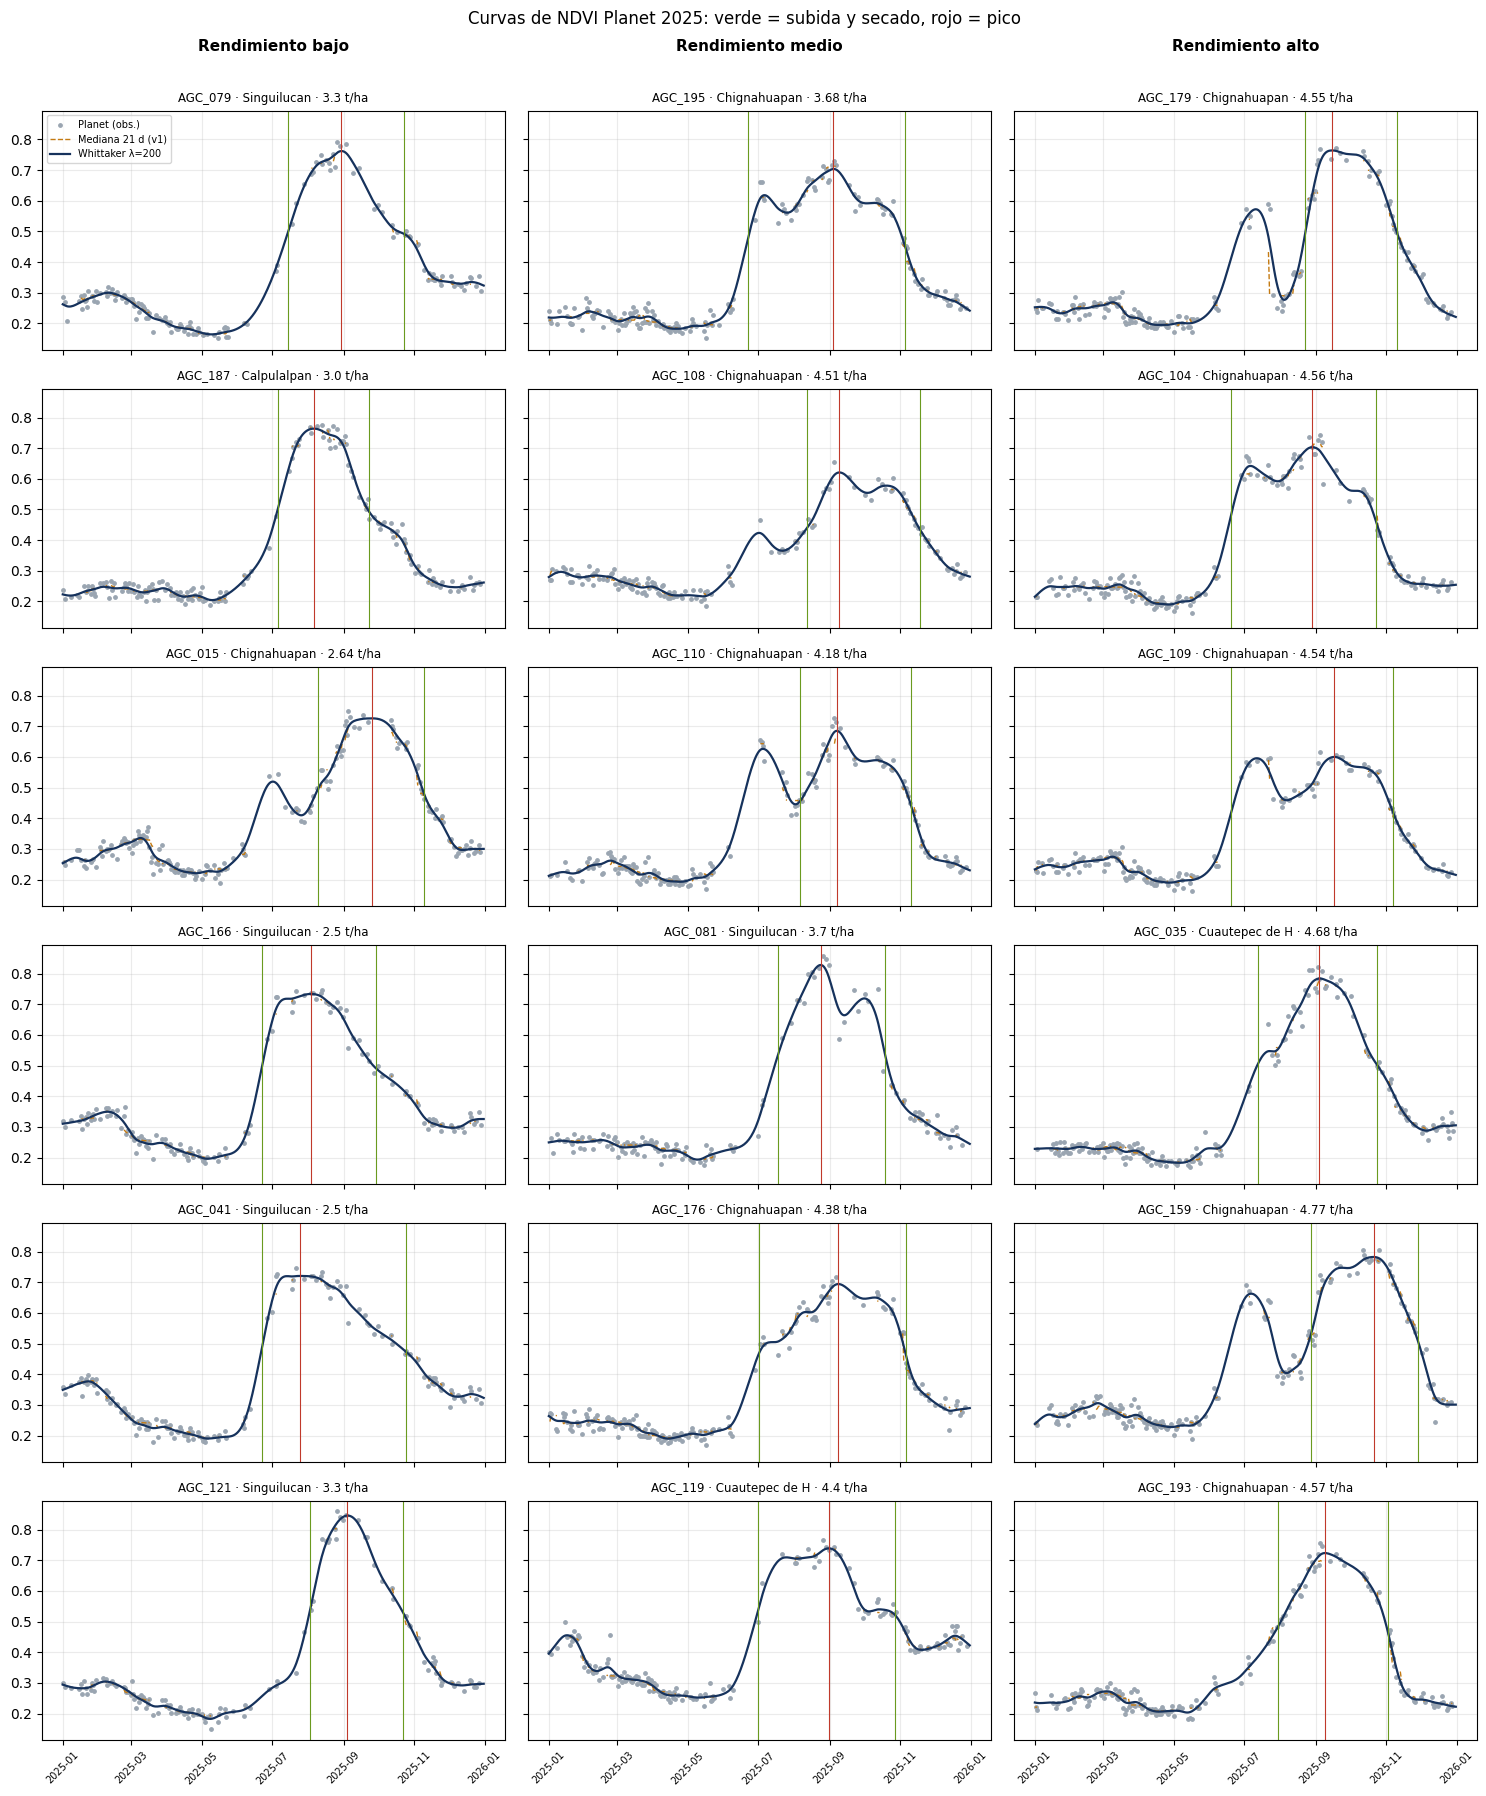

Figura guardada: figs/curvas_fenologia_revision.png (18 parcelas)
1) Spearman con el rendimiento DENTRO del municipio (138 parcelas):
pl_ndvi_auc                  -0.186
pl_ndvi_duracion             -0.197
pl_ndvi_doy_subida            0.215
pl_ndvi_doy_subida_primera    0.096
pl_ndvi_doy_secado            0.104
pl_ndvi_doy_pico              0.168
pl_ndvi_pico                  0.012
pl_ndvi_joroba1_rel          -0.204
pl_ndvi_valle_prof            0.091
pl_ndvi_brote_temprano       -0.150

2) La duración depende de la subida, no del secado (Spearman dentro de municipio):
pl_ndvi_doy_subida    -0.803
pl_ndvi_doy_secado     0.038
pl_ndvi_joroba1_rel    0.493

3) Duración vs rendimiento controlando por la fecha de subida: ρ parcial = -0.05 (desaparece)

4) Por municipio (más de 15 parcelas):
   Calpulalpan    n= 30 | duración -0.10 | subida +0.27 | verdor temprano -0.20
   Chignahuapan   n= 71 | duración -0.21 | subida +0.23 | verdor temprano -0.20
   Singuilucan    n= 16 | duración -0.18

In [55]:
# Paso 8 · Fenología con Whittaker (λ = 200): comparación de suavizados, variables fenológicas de Planet y Sentinel-2,
# sensibilidad a nubosidad 10 % vs 20 % y análisis de la doble joroba. Corre ANTES del paso 7 porque este usa sus fechas.
def paso8_fenologia_whittaker():
    import numpy as np, pandas as pd, matplotlib
    import matplotlib.pyplot as plt
    from scipy.signal import savgol_filter
    from scipy import sparse
    from scipy.sparse.linalg import spsolve
    from scipy.stats import spearmanr
    # ---- config ----
    DIAS = pd.date_range("2025-01-01", "2025-12-31")
    LAMBDA = 200
    cols_pl = ["ID_POLIGONO", "fecha", "ndvi_promedio", "evi_promedio", "msavi_promedio", "lai_promedio", "caida_brusca"]
    pl = pd.read_csv(OUT/"planet_clean_nub20.csv", parse_dates=["fecha"], usecols=cols_pl); pl = pl[~pl.caida_brusca]
    s2 = pd.read_csv(OUT/"s2_clean_nub20.csv", parse_dates=["fecha"], usecols=["ID_POLIGONO","fecha","ndvi_promedio","evi_promedio","caida_brusca"]); s2 = s2[~s2.caida_brusca]
    pl, s2 = pl[pl.fecha.dt.year == 2025], s2[s2.fecha.dt.year == 2025]
    bm = pd.read_csv(OUT/"base_maestra_v1.csv")
    print("Planet:", pl.shape, "| Sentinel-2 2025:", s2.shape)

    # ---- suavizados ----
    def a_diario(s):
        s = s.groupby(s.index).mean()
        return s.reindex(DIAS)

    def suav_mediana(s):           # el que se usó en la base maestra v1
        return a_diario(s.rolling("21D", center=True).median())

    def suav_savgol(s, ventana=31):
        d = a_diario(s).interpolate(limit_direction="both")
        return pd.Series(savgol_filter(d.values, ventana, 2), index=DIAS)

    # Whittaker: minimiza Σ w·(y − z)² + λ·Σ(Δ²z)². w = 1 en días con imagen y 0 sin imagen, así rellena huecos sin
    # interpolar.
    def suav_whittaker(s, lam=LAMBDA):
        """Whittaker con pesos: 1 en días con observación, 0 en días sin ella (rellena huecos sin interpolar antes)."""
        d = a_diario(s); w = d.notna().astype(float).values; y = d.fillna(0).values; n = len(y)
        D = sparse.diags([1.0, -2.0, 1.0], [0, 1, 2], shape=(n - 2, n), format="csr")
        A = (sparse.diags(w, format="csr") + lam * (D.T @ D)).tocsc()
        return pd.Series(spsolve(A, w * y), index=DIAS)

    def fechas(sm):
        base = sm[:"2025-05-31"].median(); w = sm["2025-07-10":"2025-11-30"]
        pf = w.idxmax(); mitad = base + 0.5 * (w.max() - base)
        ant = sm["2025-04-01":pf]; deb = ant[ant < mitad]
        sub = ant[ant.index > deb.index.max()].index.min() if len(deb) else ant.index.min()
        des = sm[pf:"2025-12-31"]; sec = des[des < mitad].index.min()
        if pd.isna(sec): sec = des.index.max()
        return sub, pf, sec

    # ---- comparación de suavizados ----
    SUAVIZADOS = {"Mediana móvil 21 d (v1)": suav_mediana, "Savitzky-Golay 31 d": suav_savgol,
                  "Whittaker λ=200": suav_whittaker, "Whittaker λ=1000": lambda s: suav_whittaker(s, 1000)}
    series_pl = {i: d.set_index("fecha").ndvi_promedio.sort_index() for i, d in pl.groupby("ID_POLIGONO")}
    series_s2 = {i: d.set_index("fecha").ndvi_promedio.sort_index() for i, d in s2.groupby("ID_POLIGONO")}
    filas = []
    for nombre, f in SUAVIZADOS.items():
        r, rmse, sesgo = [], [], []
        for i in series_pl:
            sp, ss = f(series_pl[i]), f(series_s2[i])
            a, b = fechas(sp), fechas(ss)
            r.append([t.dayofyear for t in a + b])
            obs = series_pl[i].groupby(level=0).mean()["2025-06-01":"2025-11-30"]
            rmse.append(np.sqrt(((obs - sp.reindex(obs.index)) ** 2).mean()))
            crudo = series_pl[i][a[1] - pd.Timedelta(days=15): a[1] + pd.Timedelta(days=15)]
            sesgo.append(sp[a[1]] - crudo.quantile(.9) if len(crudo) else np.nan)
        r = np.array(r, float)
        # Criterios sin datos de campo: coincidencia Planet vs S2, fidelidad a las observaciones y orden lógico de las
        # fechas.
        filas.append({"suavizado": nombre,
                      "dif_subida_dias": np.abs(r[:, 0] - r[:, 3]).mean(), "dif_pico_dias": np.abs(r[:, 1] - r[:, 4]).mean(),
                      "dif_secado_dias": np.abs(r[:, 2] - r[:, 5]).mean(), "r_pico": np.corrcoef(r[:, 1], r[:, 4])[0, 1],
                      "rmse_vs_obs": np.mean(rmse), "sesgo_pico": np.nanmean(sesgo),
                      "orden_ok_%": 100 * np.mean((r[:, 0] < r[:, 1]) & (r[:, 1] <= r[:, 2]))})
    comp = pd.DataFrame(filas).round(3)
    print("Diferencia media Planet vs Sentinel-2 (días) y fidelidad a las observaciones de Planet (jun-nov):")
    print(comp.to_string(index=False))
    comp.to_csv(OUT/"comparacion_suavizados.csv", index=False)

    # ---- fenología con Whittaker ----
    def fenologia(sm, pref):
        base = sm[:"2025-05-31"].median(); sub, pf, sec = fechas(sm); pico = sm[pf]; amp = pico - base
        a = (sm[sub:sec] - base).clip(lower=0)
        temp = sm[sub:sec]                                                   # curva dentro de la temporada
        auc = _trapz(a.values, np.arange(len(a))) if len(a) > 1 else np.nan
        post = sm[pf + pd.Timedelta(days=25): pf + pd.Timedelta(days=35)].mean()
        pend_subida = (sm[pf] - sm[sub]) / max((pf - sub).days, 1)          # velocidad de crecimiento
        pend_secado = (sm[pf] - sm[sec]) / max((sec - pf).days, 1)          # velocidad de senescencia
        # Doble joroba: primer verdor (15 jun-31 jul), valle (canícula) y pico principal
        j = sm["2025-06-15":"2025-07-31"]; h1f, h1 = j.idxmax(), j.max()
        if h1f < pf:
            v = sm[h1f:pf]; vf, valle = v.idxmin(), v.min()
        else:
            vf, valle = pd.NaT, h1
        joroba1 = (h1 - base) / amp if amp > 0 else np.nan                  # fuerza del verdor temprano (0-1)
        prof = (h1 - valle) / amp if amp > 0 else np.nan                    # profundidad del valle (0-1)
        mitad = base + 0.5 * amp; c = sm["2025-06-01":pf]; prim = c[c >= mitad].index.min()
        return {f"{pref}_base": base, f"{pref}_pico": pico, f"{pref}_amplitud": amp, f"{pref}_auc": auc,
                f"{pref}_doy_subida": sub.dayofyear, f"{pref}_doy_pico": pf.dayofyear, f"{pref}_doy_secado": sec.dayofyear,
                f"{pref}_dias_sub_pico": (pf - sub).days, f"{pref}_duracion": (sec - sub).days,
                f"{pref}_post30": post, f"{pref}_caida_post30": pico - post,
                f"{pref}_vel_subida": pend_subida, f"{pref}_vel_secado": pend_secado,
                f"{pref}_brote_temprano": sm["2025-06-15":"2025-07-15"].max() - base,
                f"{pref}_joroba1_rel": joroba1, f"{pref}_valle_prof": prof,
                f"{pref}_doy_valle": vf.dayofyear if pd.notna(vf) else np.nan,
                f"{pref}_doble_joroba": int(joroba1 >= 0.5 and prof >= 0.15),
                f"{pref}_doy_subida_primera": prim.dayofyear,
                # estadísticos de la temporada (subida -> secado) sobre la curva suavizada
                f"{pref}_med_temp": temp.median(), f"{pref}_min_temp": temp.min(),
                f"{pref}_std_temp": temp.std(), f"{pref}_rango_temp": temp.max() - temp.min()}
    filas = []
    for i, d in pl.groupby("ID_POLIGONO"):
        d = d.set_index("fecha").sort_index(); r = {"ID_POLIGONO": i}
        for col, pref in [("ndvi_promedio", "pl_ndvi"), ("evi_promedio", "pl_evi"), ("msavi_promedio", "pl_msavi"), ("lai_promedio", "pl_lai")]:
            r.update(fenologia(suav_whittaker(d[col]), pref))
        r.update(fenologia(suav_whittaker(series_s2[i]), "s2_ndvi"))
        r.update(fenologia(suav_whittaker(s2[s2.ID_POLIGONO == i].set_index("fecha").evi_promedio.sort_index()), "s2_evi"))
        filas.append(r)
    feno = pd.DataFrame(filas)
    orden = {p: ((feno[f"{p}_doy_subida"] < feno[f"{p}_doy_pico"]) & (feno[f"{p}_doy_pico"] <= feno[f"{p}_doy_secado"])).sum() for p in ["pl_ndvi", "pl_evi", "pl_msavi", "pl_lai", "s2_ndvi", "s2_evi"]}
    print("Variables de fenología (Whittaker):", feno.shape, "| orden subida<pico<=secado:", orden)
    f = lambda c: (pd.Timestamp("2024-12-31") + pd.to_timedelta(feno[c].quantile([.25, .5, .75]), unit="D")).dt.strftime("%d-%b").tolist()
    for c in ["pl_ndvi_doy_subida", "pl_ndvi_doy_pico", "pl_ndvi_doy_secado"]:
        print(f"  {c}: P25, mediana, P75 = {f(c)}")
    print("  Duración subida-secado (días): mediana", feno.pl_ndvi_duracion.median())
    feno.to_csv(OUT/"features_fenologia_whittaker.csv", index=False)

    # ---- comparación de umbral de nubosidad 10% vs 20% ----
    # Misma fenología Whittaker con las observaciones de nubosidad <=10%. Si las fechas y valores casi no cambian,
    # el umbral de 20% (más observaciones) es seguro; en el modelado se puede comparar el RMSE con ambas bases.
    # Sensibilidad: la misma fenología con nubosidad <= 10 %; si las fechas casi no cambian, el 20 % (más imágenes) es
    # seguro.
    pl10 = pd.read_csv(OUT/"planet_clean_nub10.csv", parse_dates=["fecha"], usecols=cols_pl)
    pl10 = pl10[(~pl10.caida_brusca) & (pl10.fecha.dt.year == 2025)]
    f10 = pd.DataFrame([{"ID_POLIGONO": i, **fenologia(suav_whittaker(d.set_index("fecha").ndvi_promedio.sort_index()), "pl_ndvi")}
                        for i, d in pl10.groupby("ID_POLIGONO")])
    f10.to_csv(OUT/"features_fenologia_whittaker_nub10.csv", index=False)
    n20 = pl.groupby("ID_POLIGONO").size(); n10 = pl10.groupby("ID_POLIGONO").size()
    cmp_rows = []
    for c in ["pl_ndvi_doy_subida", "pl_ndvi_doy_pico", "pl_ndvi_doy_secado", "pl_ndvi_duracion", "pl_ndvi_pico",
              "pl_ndvi_base", "pl_ndvi_auc", "pl_ndvi_post30", "pl_ndvi_joroba1_rel"]:
        a = feno.set_index("ID_POLIGONO")[c]; b = f10.set_index("ID_POLIGONO")[c].reindex(a.index)
        cmp_rows.append(dict(variable=c, dif_media_abs=(a - b).abs().mean(), dif_mediana_abs=(a - b).abs().median(),
                             spearman=spearmanr(a, b, nan_policy="omit")[0]))
    cmp = pd.DataFrame(cmp_rows).round(3)
    cmp.to_csv(OUT/"comparacion_nubosidad_10_20.csv", index=False)
    print(f"\nNubosidad 10% vs 20% (Planet 2025): obs. por parcela {n10.median():.0f} vs {n20.median():.0f} (mediana)")
    print(cmp.to_string(index=False))

    # ---- curvas para revisar a mano ----
    tr = bm[bm.CONJUNTO == "ENTRENAMIENTO"].copy()
    tr["grupo"] = pd.qcut(tr.y.rank(method="first"), 3, labels=["bajo", "medio", "alto"])
    muestra = (tr.sort_values(["grupo", "Municipio"]).groupby("grupo", observed=True)
                 .apply(lambda g: g.sample(6, random_state=SEMILLA), include_groups=False).reset_index(level=0))
    fig, axs = plt.subplots(6, 3, figsize=(15, 18), sharex=True, sharey=True)
    for col, (gr, g) in zip(range(3), muestra.groupby("grupo", observed=True)):
        for fila, (_, r) in enumerate(g.iterrows()):
            ax = axs[fila, col]; s = series_pl[r.ID_POLIGONO]
            ax.scatter(s.index, s.values, s=6, color="#9aa5b1", label="Planet (obs.)")
            ax.plot(DIAS, suav_mediana(s).values, color="#c47a12", lw=1, ls="--", label="Mediana 21 d (v1)")
            sm = suav_whittaker(s); ax.plot(DIAS, sm.values, color="#16325c", lw=1.6, label="Whittaker λ=200")
            sub, pf, sec = fechas(sm)
            for t, c in [(sub, "#6a9a1f"), (pf, "#c0392b"), (sec, "#6a9a1f")]: ax.axvline(t, color=c, lw=.8)
            ax.set_title(f"{r.ID_POLIGONO} · {r.Municipio[:14]} · {r.y} t/ha", fontsize=8.5); ax.grid(alpha=.25)
        axs[0, col].annotate(f"Rendimiento {gr}", (0.5, 1.25), xycoords="axes fraction", ha="center", fontsize=11, weight="bold")
    axs[0, 0].legend(fontsize=7, loc="upper left")
    for ax in axs[-1]: ax.tick_params(axis="x", rotation=45, labelsize=7)
    fig.suptitle("Curvas de NDVI Planet 2025: verde = subida y secado, rojo = pico", y=0.995, fontsize=12)
    plt.tight_layout(); plt.savefig(FIG/"curvas_fenologia_revision.png", dpi=90); plt.show()
    print("Figura guardada: figs/curvas_fenologia_revision.png (18 parcelas)")

    # ---- paradoja AUC y duración ----
    # Dentro de cada municipio, ¿por qué más AUC/duración va con MENOS rendimiento? (diagnóstico, usa y)
    d = bm[["ID_POLIGONO", "CONJUNTO", "Municipio", "y"]].merge(feno, on="ID_POLIGONO")
    d = d[d.CONJUNTO == "ENTRENAMIENTO"].copy()
    vars_ = ["pl_ndvi_auc", "pl_ndvi_duracion", "pl_ndvi_doy_subida", "pl_ndvi_doy_subida_primera", "pl_ndvi_doy_secado",
             "pl_ndvi_doy_pico", "pl_ndvi_pico", "pl_ndvi_joroba1_rel", "pl_ndvi_valle_prof", "pl_ndvi_brote_temprano"]
    dm = d.copy()
    for c in vars_ + ["y"]:
        dm[c] = d[c] - d.groupby("Municipio")[c].transform("mean")          # se quita el efecto del municipio
    print("1) Spearman con el rendimiento DENTRO del municipio (138 parcelas):")
    print(dm[vars_].corrwith(dm.y, method="spearman").round(3).to_string())
    print("\n2) La duración depende de la subida, no del secado (Spearman dentro de municipio):")
    print(dm[["pl_ndvi_doy_subida", "pl_ndvi_doy_secado", "pl_ndvi_joroba1_rel"]].corrwith(dm.pl_ndvi_duracion, method="spearman").round(3).to_string())
    # Correlación parcial por rangos: quita el efecto de la fecha de subida para ver si la duración aporta algo por sí
    # misma.
    def parcial(a, b, ctrl):
        ra, rb, rc = dm[a].rank(), dm[b].rank(), dm[ctrl].rank()
        res = lambda v: v - np.polyval(np.polyfit(rc, v, 1), rc)
        return spearmanr(res(ra), res(rb))[0]
    print("\n3) Duración vs rendimiento controlando por la fecha de subida: ρ parcial =",
          round(parcial("pl_ndvi_duracion", "y", "pl_ndvi_doy_subida"), 3), "(desaparece)")
    print("\n4) Por municipio (más de 15 parcelas):")
    for m, g in d.groupby("Municipio"):
        if len(g) >= 15:
            print(f"   {m:<14} n={len(g):>3} | duración {spearmanr(g.pl_ndvi_duracion, g.y)[0]:+.2f} | "
                  f"subida {spearmanr(g.pl_ndvi_doy_subida, g.y)[0]:+.2f} | verdor temprano {spearmanr(g.pl_ndvi_joroba1_rel, g.y)[0]:+.2f}")
    dj = feno.merge(bm[["ID_POLIGONO", "Municipio"]], on="ID_POLIGONO")
    print(f"\n5) Doble joroba: {int(dj.pl_ndvi_doble_joroba.sum())} de 197 parcelas | por municipio:",
          dj.groupby("Municipio").pl_ndvi_doble_joroba.sum().loc[lambda x: x > 0].to_dict())
    vj = dj.loc[dj.pl_ndvi_doble_joroba == 1]
    print("   Valle mediano:", (pd.Timestamp("2024-12-31") + pd.Timedelta(days=vj.pl_ndvi_doy_valle.median())).strftime("%d-%b"),
          "| profundidad mediana:", round(vj.pl_ndvi_valle_prof.median(), 2), "de la amplitud")
    v2 = vj.s2_ndvi_doy_valle; print("   Sentinel-2 ve el valle con diferencia mediana de", (vj.pl_ndvi_doy_valle - v2).abs().median(), "días")

paso8_fenologia_whittaker()

## Paso 7 · Clima por etapa del cultivo (Tmin, Tmax, precipitación)
*Se corre después del paso 8 porque usa sus fechas de subida, pico y secado.*

*Grados-día (GDD):* el plan los pide **solo si hay datos diarios defendibles**. Los rasters del reto son mensuales (promedios de Tmin/Tmax), y un GDD calculado con promedios mensuales subestima los días cálidos y no es comparable con la literatura. Por eso no se calculan; en su lugar se usan Tmed y amplitud térmica por etapa.

### Explicación

**Objetivo.** Medir el clima que vivió *cada parcela* en *sus* etapas de desarrollo, en lugar de usar meses fijos iguales para todas.

**Procedimiento.**
1. Se extraen de los rasters mensuales Tmin, Tmax (CHIRTS-ERA5) y precipitación (CHIRPS) para cada parcela, promediando las celdas que toca el polígono (respaldo: el valor en el centroide). El resultado se guarda en `clima_mensual_por_parcela.csv`.
2. Con las fechas de Whittaker de Planet se definen tres etapas por parcela: **siembra** (45 días antes de la subida hasta la subida), **vegetativa** (subida → pico) y **llenado** (pico → secado).
3. Como el clima es mensual, cada mes se pondera por los días que caen dentro de la etapa. La lluvia se trata como **suma** (fracción proporcional del mes) y la temperatura como **promedio ponderado**.
4. Se calculan los valores de 2025 y su **anomalía** contra la misma ventana en 2022-2024, además de la temperatura media y la **amplitud térmica** (Tmax − Tmin) por etapa.
5. Se crea la base maestra v2 (v1 + estas variables de clima).

**Justificación.** Dos parcelas sembradas con un mes de diferencia viven lluvias distintas en su etapa vegetativa aunque estén juntas. Atar el clima a la fenología de cada parcela representa mejor las condiciones del cultivo.

**Lo que no hicimos y por qué.** No calculamos grados-día (GDD): los rasters son promedios mensuales y un GDD calculado así subestima los días cálidos; no sería comparable con la literatura.

**Limitación.** La resolución del clima es de ~5 km: parcelas vecinas suelen caer en la misma celda y reciben el mismo valor mensual. Por eso el clima ayuda poco a distinguir parcelas cercanas.

**Relación con el proyecto.** De aquí salen las dos variables climáticas del modelo final: **lluvia en la etapa vegetativa** y **amplitud térmica en la etapa vegetativa** de 2025.

In [56]:
# Paso 7 · Clima por etapa: extrae Tmin, Tmax y lluvia mensuales por parcela y los resume en las etapas de siembra,
# vegetativa y llenado DE CADA PARCELA (fechas Whittaker del paso 8), ponderando cada mes por los días de traslape.
def paso7_clima_etapas():
    import re
    import numpy as np, pandas as pd, geopandas as gpd
    # ---- config ----
    CLIMA = DATOS / "clima"
    VARIABLES = {"Tmin": "media", "Tmax": "media", "Prec": "suma"}   # cómo se agrega cada variable en el tiempo
    ANIOS = [2022, 2023, 2024, 2025]

    # ---- extracción por parcela ----
    def identificar(p):
        """Devuelve (variable, año, mes) a partir del nombre del archivo, o None.
        Acepta Tmin_2025_01.tif, Tmax_2025_01.tif, Prec_2025_01.tif y nombres tipo CHIRPS (chirps-v2.0.2025.01.tif)."""
        n = p.name.lower()
        if n.startswith("._") or "__macosx" in str(p).lower(): return None   # archivos ocultos de la Mac
        if "tmin" in n: var = "Tmin"
        elif "tmax" in n: var = "Tmax"
        elif any(k in n for k in ["prec", "chirps", "lluvia", "ppt", "pcp", "precip"]): var = "Prec"
        else: return None
        m = re.search(r"(20[12]\d)[._-]?(0[1-9]|1[0-2])(?!\d)", n)
        if not m: return None
        anio, mes = int(m.group(1)), int(m.group(2))
        return (var, anio, mes) if anio in ANIOS else None

    def importar_rasterio():
        try:
            import rasterio
        except ImportError:                       # Colab no lo trae: se instala solo
            import subprocess
            print("Instalando rasterio (solo la primera vez, ~30 s)...")
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)
        import rasterio
        from rasterio.mask import mask
        return rasterio, mask

    tifs = {}
    for p in DATOS.rglob("*"):
        if p.suffix.lower() in (".tif", ".tiff"):
            k = identificar(p)
            if k: tifs.setdefault(k[0], []).append((p, k[1], k[2]))
    for var, lst in tifs.items():
        print(f"Rasters de {var}: {len(lst)} archivos | años {sorted({a for _, a, _ in lst})}")

    def extraer_variable(var, parcelas):
        """Promedio de las celdas que toca cada parcela (all_touched: las parcelas son mucho más chicas que la celda de 5 km)."""
        archivos = sorted(tifs.get(var, []), key=lambda t: (t[1], t[2]))
        if not archivos:
            return None
        rasterio, mask = importar_rasterio()       # solo se importa si hay rasters
        filas = []
        for f, anio, mes in archivos:
            with rasterio.open(f) as src:
                g = parcelas.to_crs(src.crs)
                nod = src.nodata
                for pid, geom in zip(g.ID_POLIGONO, g.geometry):
                    arr, _ = mask(src, [geom], crop=True, all_touched=True, filled=True, nodata=-9999 if nod is None else nod)
                    a = arr[0].astype(float)
                    a[(a == (-9999 if nod is None else nod)) | (a < -1000)] = np.nan
                    v = np.nanmean(a) if np.isfinite(a).any() else np.nan
                    if np.isnan(v):   # respaldo: valor en el centroide
                        c = geom.centroid; v = float(list(src.sample([(c.x, c.y)]))[0][0])
                        v = np.nan if (nod is not None and v == nod) or v < -1000 else v
                    if var == "Prec" and v < 0: v = np.nan
                    filas.append((pid, var, anio, mes, v))
        t = pd.DataFrame(filas, columns=["ID_POLIGONO", "variable", "anio", "mes", "valor"])
        meses = t.groupby("anio").mes.nunique()
        if (meses < 12).any(): print(f"  AVISO {var}: meses incompletos por año -> {meses[meses < 12].to_dict()}")
        return t

    parcelas = gpd.read_file(preparar_shapefile()).rename(columns={"ID_POLIGON": "ID_POLIGONO"})[["ID_POLIGONO", "geometry"]]
    tablas = []
    for var in VARIABLES:
        t = extraer_variable(var, parcelas)
        if t is None and var == "Tmax":   # respaldo: Tmax ya extraída por el equipo
            tx = pd.read_csv(F_TMAX).rename(columns={"ID_POLIGON": "ID_POLIGONO"})
            cols = [c for c in tx.columns if c.endswith("_mean")]
            t = tx.melt("ID_POLIGONO", cols, value_name="valor")
            t[["variable", "anio", "mes"]] = t.variable.str.extract(r"(Tmax)_(\d{4})_(\d{2})_mean")
            t["anio"], t["mes"] = t.anio.astype(int), t.mes.astype(int)
            print("Tmax: se usa Tmax_2022_2025_por_parcela.csv")
        if t is None:
            print(f"AVISO: no hay rasters de {var} en {DATOS}. Se omite (sube los .tif o un .zip con ellos).")
            continue
        print(f"{var}: {len(t)} valores | parcelas {t.ID_POLIGONO.nunique()} | NaN {t.valor.isna().sum()}")
        tablas.append(t)
    mensual = pd.concat(tablas, ignore_index=True)
    mensual.to_csv(OUT / "clima_mensual_por_parcela.csv", index=False)

    # ---- ventanas por etapa de cada parcela ----
    # Las etapas salen de la fenología Whittaker de Planet (paso 8, que ahora corre ANTES que este paso): siembra = 45 días antes de la subida;
    # vegetativa = subida -> pico; llenado = pico -> secado. Los valores mensuales se ponderan por días de traslape.
    bm = pd.read_csv(OUT / "base_maestra_v1.csv")
    # CORRECCIÓN: antes se usaban las fechas de la v1 (mediana móvil). En 23 parcelas el pico difería >15 días
    # del de Whittaker, que es la fenología que queda en la v3. Ahora el clima usa las mismas fechas que el resto.
    fen = pd.read_csv(OUT / "features_fenologia_whittaker.csv")[["ID_POLIGONO", "pl_ndvi_doy_subida", "pl_ndvi_doy_pico", "pl_ndvi_doy_secado"]]
    def doy_a_fecha(anio, doy): return pd.Timestamp(f"{anio}-01-01") + pd.Timedelta(days=int(doy) - 1)

    # Lluvia: suma de la fracción de cada mes que cae en la etapa. Temperatura: promedio ponderado por días.
    def valor_ventana(serie_mes, ini, fin, modo):
        """serie_mes: dict (mes -> valor) de un año. Pondera cada mes por los días que caen en [ini, fin)."""
        dias = pd.date_range(ini, fin - pd.Timedelta(days=1), freq="D")
        if len(dias) == 0: return np.nan
        pesos = pd.Series(1, index=dias).groupby(dias.month).sum()
        v = pd.Series({m: serie_mes.get(m, np.nan) for m in pesos.index})
        if v.isna().all(): return np.nan
        if modo == "suma":   # precipitación mensual -> fracción del mes
            dias_mes = pd.Series({m: pd.Period(f"{ini.year}-{m:02d}").days_in_month for m in pesos.index})
            return float((v * pesos / dias_mes).sum(min_count=1))
        return float((v * pesos).sum() / pesos[v.notna()].sum())

    piv = mensual.pivot_table(index=["ID_POLIGONO", "variable", "anio"], columns="mes", values="valor")
    filas = []
    for _, r in fen.iterrows():
        out = {"ID_POLIGONO": r.ID_POLIGONO}
        etapas = {}
        sub, pico, sec = r.pl_ndvi_doy_subida, r.pl_ndvi_doy_pico, r.pl_ndvi_doy_secado
        # Etapas propias de cada parcela: siembra = 45 días antes de la subida del NDVI; vegetativa = subida→pico;
        # llenado = pico→secado.
        etapas["siembra"] = (sub - 45, sub); etapas["vegetativa"] = (sub, pico); etapas["llenado"] = (pico, sec)
        for var, modo in VARIABLES.items():
            for et, (d0, d1) in etapas.items():
                vals = {}
                for a in ANIOS:
                    key = (r.ID_POLIGONO, var, a)
                    if key not in piv.index: continue
                    vals[a] = valor_ventana(piv.loc[key].to_dict(), doy_a_fecha(a, d0), doy_a_fecha(a, d1), modo)
                if 2025 not in vals: continue
                v = var.lower()
                out[f"clim_{v}_{et}_2025"] = vals[2025]
                hist = [vals[a] for a in (2022, 2023, 2024) if a in vals and not np.isnan(vals[a])]
                # Anomalía: 2025 menos el promedio 2022-2024 en las mismas fechas de la etapa.
                if hist: out[f"clim_{v}_{et}_anom"] = vals[2025] - np.mean(hist)   # misma ventana en años previos
        filas.append(out)
    feat = pd.DataFrame(filas)
    # Derivadas: temperatura media y amplitud térmica por etapa (si hay Tmin y Tmax)
    for et in ["siembra", "vegetativa", "llenado"]:
        a, b = f"clim_tmax_{et}_2025", f"clim_tmin_{et}_2025"
        if a in feat and b in feat:
            feat[f"clim_tmed_{et}_2025"] = (feat[a] + feat[b]) / 2
            # Amplitud térmica = Tmax − Tmin: en el Altiplano, días cálidos con noches frías (cielos despejados)
            # indican menos nubosidad y lluvia.
            feat[f"clim_amplitud_{et}_2025"] = feat[a] - feat[b]
    print("features_clima:", feat.shape)

    # ---- salida ----
    feat.to_csv(OUT / "features_clima.csv", index=False)
    bm2 = bm.drop(columns=[c for c in bm.columns if c.startswith("clim_")]).merge(feat, on="ID_POLIGONO", how="left")
    assert len(bm2) == 197 and bm2.ID_POLIGONO.is_unique
    bm2.to_csv(OUT / "base_maestra_v2.csv", index=False)
    print("base_maestra_v2.csv:", bm2.shape, "| variables clim_:", sum(c.startswith("clim_") for c in bm2.columns))
    tr = bm2[bm2.CONJUNTO == "ENTRENAMIENTO"]
    c = tr[[x for x in feat.columns if x != "ID_POLIGONO"]].corrwith(tr.y, method="spearman").sort_values(key=abs, ascending=False)
    print("Correlación de Spearman con el rendimiento (exploratoria, 138 parcelas):"); print(c.head(10).round(3))

paso7_clima_etapas()

Rasters de Tmax: 48 archivos | años [2022, 2023, 2024, 2025]
Rasters de Tmin: 48 archivos | años [2022, 2023, 2024, 2025]
Rasters de Prec: 48 archivos | años [2022, 2023, 2024, 2025]
Tmin: 9456 valores | parcelas 197 | NaN 0
Tmax: 9456 valores | parcelas 197 | NaN 0
Prec: 9456 valores | parcelas 197 | NaN 0
features_clima: (197, 25)
base_maestra_v2.csv: (197, 113) | variables clim_: 24
Correlación de Spearman con el rendimiento (exploratoria, 138 parcelas):
clim_amplitud_vegetativa_2025   -0.585
clim_tmin_vegetativa_2025        0.465
clim_tmax_llenado_anom           0.435
clim_tmin_vegetativa_anom        0.412
clim_tmax_llenado_2025          -0.397
clim_prec_siembra_2025          -0.377
clim_tmed_vegetativa_2025        0.345
clim_tmin_siembra_2025           0.345
clim_tmax_siembra_anom           0.324
clim_tmed_siembra_2025           0.300
dtype: float64


## Paso 9 · Humedad y estrés por etapa; base maestra v3

### Explicación

**Objetivo.** Agregar indicadores de agua en el dosel por etapa y formar la base de modelado definitiva (v3).

**Procedimiento.**
- Con Sentinel-2 se promedian NDWI (agua en la vegetación), MSI (estrés hídrico; más alto = más estrés), NDSVI (vegetación senescente) y NDVI en tres ventanas: etapa vegetativa, llenado de grano y canícula (11 de julio a 31 de agosto). También se guardan el NDWI mínimo y el MSI máximo como "peor momento".
- Si una ventana tiene **menos de 3 imágenes**, el valor se deja en NaN: un promedio de una o dos imágenes no es confiable.
- **Base maestra v3** = v2 (clima por etapa) + fenología Whittaker (reemplaza la de la v1) + humedad por etapa.
- **Interacciones vegetación × lluvia:** producto de las dos variables estandarizadas (z). Es positivo cuando ambas están arriba (o ambas abajo) del promedio. Se estandariza con las 197 parcelas y **no usa el rendimiento**, así que no hay fuga.

**Relación con el proyecto.** `base_maestra_v3.csv` es la tabla que usan todos los modelos de los pasos A en adelante.

In [57]:
# Paso 9 · Humedad y estrés (NDWI, MSI, NDSVI, NDVI de Sentinel-2) por etapa, interacciones vegetación × lluvia
# y construcción de la base maestra v3 (la que usan todos los modelos).
def paso9_humedad_etapas():
    import numpy as np, pandas as pd
    # ---- config ----
    INDICES = ["ndwi", "msi", "ndsvi", "ndvi"]
    # Con menos de 3 imágenes en la ventana el promedio no es confiable: se deja NaN.
    MIN_OBS = 3   # con menos de 3 imágenes en la ventana el valor no es confiable -> NaN
    s2 = pd.read_csv(OUT/"s2_clean_nub20.csv", parse_dates=["fecha"],
                     usecols=["ID_POLIGONO", "fecha", "caida_brusca"] + [f"{i}_promedio" for i in INDICES])
    s2 = s2[(~s2.caida_brusca) & (s2.fecha.dt.year == 2025)]
    feno = pd.read_csv(OUT/"features_fenologia_whittaker.csv")
    print("Sentinel-2 2025:", s2.shape, "| fenología:", feno.shape)

    # ---- ventanas por parcela ----
    f = lambda doy: pd.Timestamp("2024-12-31") + pd.to_timedelta(doy, unit="D")
    fechas = feno[["ID_POLIGONO"]].assign(sub=f(feno.pl_ndvi_doy_subida), pico=f(feno.pl_ndvi_doy_pico), sec=f(feno.pl_ndvi_doy_secado))
    d = s2.merge(fechas, on="ID_POLIGONO")
    ventanas = {"veg": (d.fecha >= d["sub"]) & (d.fecha < d.pico),
                "llen": (d.fecha >= d.pico) & (d.fecha <= d.sec),
                "canic": d.fecha.between("2025-07-11", "2025-08-31")}
    filas = []
    for nombre, m in ventanas.items():
        g = d[m].groupby("ID_POLIGONO")
        t = pd.DataFrame({"ID_POLIGONO": g.size().index, f"s2_n_obs_{nombre}": g.size().values})
        for ix in INDICES:
            col = f"{ix}_promedio"
            t[f"s2_{ix}_media_{nombre}"] = g[col].mean().values
        # extremo de estrés: NDWI mínimo y MSI máximo (más estrés = menos agua en el dosel)
        t[f"s2_ndwi_min_{nombre}"] = g["ndwi_promedio"].min().values
        t[f"s2_msi_max_{nombre}"] = g["msi_promedio"].max().values
        pocas = t[f"s2_n_obs_{nombre}"] < MIN_OBS
        t.loc[pocas, [c for c in t.columns if c not in ("ID_POLIGONO", f"s2_n_obs_{nombre}")]] = np.nan
        if pocas.any(): print(f"  Ventana {nombre}: {int(pocas.sum())} parcelas con menos de {MIN_OBS} imágenes -> NaN")
        filas.append(t.set_index("ID_POLIGONO"))
    hum = pd.concat(filas, axis=1).reindex(feno.ID_POLIGONO); hum.index.name = "ID_POLIGONO"
    print("Observaciones Sentinel-2 por ventana (mín / mediana):",
          {k: (int(hum[f's2_n_obs_{k}'].min()), int(hum[f's2_n_obs_{k}'].median())) for k in ventanas})
    print("Variables de humedad/estrés:", hum.shape[1] - 3, "| faltantes por columna (máx):", int(hum.isna().sum().max()))

    # ---- base maestra v3 ----
    # v3 = v2 (clima por etapa, paso 7) + fenología Whittaker (reemplaza las columnas de fenología de v1) + humedad por etapa
    bm2 = pd.read_csv(OUT/"base_maestra_v2.csv")
    reemplazo = [c for c in feno.columns if c != "ID_POLIGONO" and c in bm2.columns]
    nuevas = [c for c in feno.columns if c != "ID_POLIGONO" and c not in bm2.columns]
    bm3 = (bm2.drop(columns=reemplazo).merge(feno, on="ID_POLIGONO", how="left")
              .merge(hum.drop(columns=[c for c in hum.columns if c.startswith("s2_n_obs")]).reset_index(), on="ID_POLIGONO", how="left"))
    # ---- interacciones vegetación × lluvia (plan I2, punto 10) ----
    # Producto de variables estandarizadas (z) con las 197 parcelas (no usa y): positivo = ambos por arriba del promedio.
    # Estandarización con las 197 parcelas; no usa el rendimiento, así que no hay fuga.
    z = lambda c: (bm3[c] - bm3[c].mean()) / bm3[c].std()
    pares = {"int_ndvipico_x_prec_veg": ("pl_ndvi_pico", "clim_prec_vegetativa_2025"),
             "int_ndvipost30_x_prec_llen": ("pl_ndvi_post30", "clim_prec_llenado_2025"),
             "int_ndwi_veg_x_prec_veg": ("s2_ndwi_media_veg", "clim_prec_vegetativa_2025"),
             "int_ndwi_llen_x_prec_llen": ("s2_ndwi_min_llen", "clim_prec_llenado_2025"),
             "int_auc_x_prec_temp": ("pl_ndvi_auc", "clim_prec_vegetativa_2025")}
    hechas = []; bm3 = bm3.copy()
    for nom, (a, b) in pares.items():
        if a in bm3 and b in bm3:
            bm3[nom] = z(a) * z(b); hechas.append(nom)
    print("Interacciones vegetación × lluvia:", len(hechas) if hechas else "ninguna (faltan rasters de precipitación)")
    assert len(bm3) == 197 and bm3.ID_POLIGONO.is_unique and bm3.y.notna().sum() == 138
    print(f"Base maestra v3: {bm3.shape} | fenología reemplazada: {len(reemplazo)} columnas | nuevas de fenología: {len(nuevas)}"
          f" | nuevas de humedad: {hum.shape[1] - 3}")
    hum.reset_index().to_csv(OUT/"features_humedad_etapas.csv", index=False)
    bm3.to_csv(OUT/"base_maestra_v3.csv", index=False)

    # ---- revisión rápida (exploratoria, usa y) ----
    tr = bm3[bm3.CONJUNTO == "ENTRENAMIENTO"].copy()
    cols = [c for c in hum.columns if not c.startswith("s2_n_obs")] + hechas
    dm = tr.copy()
    for c in cols + ["y"]:
        dm[c] = tr[c] - tr.groupby("Municipio")[c].transform("mean")
    r = dm[cols].corrwith(dm.y, method="spearman").sort_values(key=abs, ascending=False)
    print("Humedad/estrés e interacciones: Spearman con el rendimiento DENTRO del municipio (top 8):"); print(r.head(8).round(3).to_string())

paso9_humedad_etapas()

Sentinel-2 2025: (11584, 7) | fenología: (197, 139)
  Ventana veg: 18 parcelas con menos de 3 imágenes -> NaN
Observaciones Sentinel-2 por ventana (mín / mediana): {'veg': (1, 7), 'llen': (3, 8), 'canic': (7, 10)}
Variables de humedad/estrés: 18 | faltantes por columna (máx): 24
Interacciones vegetación × lluvia: 5
Base maestra v3: (197, 226) | fenología reemplazada: 48 columnas | nuevas de fenología: 90 | nuevas de humedad: 18
Humedad/estrés e interacciones: Spearman con el rendimiento DENTRO del municipio (top 8):
int_ndvipico_x_prec_veg    0.223
s2_msi_media_canic         0.218
s2_ndwi_media_canic       -0.212
s2_ndvi_media_canic       -0.194
s2_ndwi_min_canic         -0.185
s2_msi_max_canic           0.180
s2_msi_max_llen           -0.168
s2_ndwi_min_llen           0.159


## Paso 10 · Reducción de variables redundantes y núcleo sugerido

### Explicación

**Objetivo.** Pasar de más de 100 variables muy correlacionadas a un conjunto manejable, **sin mirar el rendimiento** (para no sesgar la selección).

**Procedimiento.**
1. Se excluyen identificadores, la variable objetivo, la bandera de redondeo y las variables de calidad `cal_`.
2. Se calcula la correlación de Spearman absoluta entre todas las variables y se hace un **agrupamiento jerárquico** con distancia 1 − |ρ| y enlace promedio. Las variables con |ρ| > 0.85 quedan en el mismo grupo.
3. De cada grupo se elige un representante con reglas fijas: preferir Planet, luego NDVI, menos faltantes y mayor correlación promedio con su grupo.
4. Se define un **núcleo sugerido** de unas 24 variables elegidas por criterio agronómico (una o dos por familia: vigor, calendario, heterogeneidad, humedad, senescencia, historial, topografía, clima y área).

**Justificación.** Con 138 parcelas, meter variables casi idénticas solo agrega ruido y multicolinealidad. Elegir con reglas fijas y sin usar *y* evita el sesgo de seleccionar variables "porque salieron bien" con los mismos datos con que se evalúan.

**Relación con el proyecto.** El núcleo se usa para probar modelos más ricos (Random Forest y Gradient Boosting con 24 variables, Ridge sin ubicación). Como se ve en el paso B, **esos modelos no superaron al ensamble sencillo**, así que el núcleo quedó como referencia y no como entrada del modelo final.

In [58]:
# Paso 10 · Agrupa variables redundantes (|Spearman| > 0.85) y elige un representante por grupo con reglas fijas,
# SIN usar el rendimiento. Define además el "núcleo sugerido" de variables por criterio agronómico.
def paso10_variables_familias():
    import re
    import numpy as np, pandas as pd
    from scipy.cluster.hierarchy import linkage, fcluster
    from scipy.spatial.distance import squareform
    # ---- config ----
    UMBRAL = 0.85
    bm = pd.read_csv(OUT/"base_maestra_v3.csv")
    excluir = {"ID_POLIGONO", "y", "CONJUNTO", "Municipio", "Estado", "rend_redondo"}
    cand = [c for c in bm.columns if c not in excluir and not c.startswith("cal_") and pd.api.types.is_numeric_dtype(bm[c])]
    X = bm[cand]
    constantes = [c for c in cand if X[c].nunique(dropna=True) <= 1]
    cand = [c for c in cand if c not in constantes]; X = bm[cand]
    print(f"Candidatas: {len(cand)} (se excluyen ID, y, municipio y {sum(c.startswith('cal_') for c in bm.columns)} variables cal_)",
          "| constantes descartadas:", constantes)

    # ---- familias ----
    def familia(c):
        if c.startswith("int_"): return "interacciones vegetación × lluvia"
        if c.startswith("clim_"): return "clima"
        if c.startswith("topo_"): return "topografía"
        if c.startswith("hist_"): return "historial 2022-2024"
        if c.startswith("ls_"): return "térmico (Landsat VI6T)"
        if c == "area_ha": return "parcela"
        if any(k in c for k in ["ndwi", "msi"]): return "humedad / estrés"
        if any(k in c for k in ["ndsvi", "fapar"]): return "senescencia / radiación"
        if c.endswith(("_std_temp", "_rango_temp")): return "variabilidad en la temporada"
        if "_std_" in c or "_min_pico" in c: return "heterogeneidad intra-parcela"
        if any(k in c for k in ["doy_", "dias_", "duracion", "vel_", "joroba", "valle", "doble", "brote"]): return "calendario y forma de la curva"
        return "vigor (NDVI/EVI/MSAVI/LAI)"

    def describir(c):
        """Descripción en palabras de cada variable (por patrón de nombre)."""
        sens = {"pl": "Planet", "s2": "Sentinel-2", "ls": "Landsat"}
        m = re.match(r"(pl|s2)_(ndvi|evi|msavi|lai)_(.+)", c)
        feno = {"base": "valor en suelo desnudo (ene-may)", "pico": "valor máximo del cultivo", "amplitud": "pico menos base",
                "auc": "área bajo la curva entre subida y secado", "doy_subida": "día del año en que arranca el cultivo",
                "doy_subida_primera": "primer cruce del 50% desde junio", "doy_pico": "día del año del pico",
                "doy_secado": "día del año del secado", "dias_sub_pico": "días de la subida al pico",
                "duracion": "días de la subida al secado", "post30": "valor ~30 días después del pico (llenado)",
                "caida_post30": "caída en los 30 días después del pico", "vel_subida": "velocidad de crecimiento",
                "vel_secado": "velocidad de senescencia", "brote_temprano": "verdor 15 jun-15 jul sobre la base",
                "joroba1_rel": "fuerza del verdor temprano (0-1 de la amplitud)", "valle_prof": "profundidad del valle de canícula (0-1)",
                "doy_valle": "día del año del valle", "doble_joroba": "1 si hay verdor temprano y valle marcado",
                "std_pico": "desviación del NDVI dentro de la parcela en el pico", "min_pico": "NDVI mínimo dentro de la parcela en el pico",
                "med_temp": "mediana de la curva en la temporada", "min_temp": "mínimo de la curva en la temporada",
                "std_temp": "variabilidad (desv. estándar) de la curva en la temporada", "rango_temp": "rango (máx - mín) de la curva en la temporada"}
        if m and m.group(3) in feno: return f"{sens[m.group(1)]} {m.group(2).upper()}: {feno[m.group(3)]}"
        m = re.match(r"s2_(ndwi|msi|ndsvi|ndvi)_(media|min|max)_(veg|llen|canic)", c)
        if m:
            et = {"veg": "etapa vegetativa", "llen": "llenado de grano", "canic": "canícula (11 jul-31 ago)"}[m.group(3)]
            return f"Sentinel-2 {m.group(1).upper()}: {m.group(2)} en {et}"
        m = re.match(r"clim_(tmax|tmin|tmed|amplitud|prec)_(siembra|vegetativa|llenado)_(2025|anom)", c)
        if m:
            v = {"tmax": "Tmax", "tmin": "Tmin", "tmed": "Temperatura media", "amplitud": "Amplitud térmica", "prec": "Precipitación"}[m.group(1)]
            return f"{v} en {m.group(2)} " + ("2025" if m.group(3) == "2025" else "(anomalía vs 2022-2024)")
        m = re.match(r"int_(.+)", c)
        if m: return "Interacción (producto de valores estandarizados): " + m.group(1).replace("_x_", " × ").replace("_", " ")
        otras = {"area_ha": "superficie de la parcela (ha)", "topo_elev_media": "elevación media", "topo_elev_std": "variación de elevación",
                 "topo_pend_media": "pendiente media", "topo_pend_std": "variación de pendiente",
                 "hist_ndvi_pico_media": "pico de NDVI promedio 2022-2024 (potencial histórico)", "hist_ndvi_pico_std": "variabilidad del pico 2022-2024",
                 "ls_vi6t_media_jul_oct": "VI6T medio jul-oct", "ls_vi6t_min_jul_oct": "VI6T mínimo jul-oct"}
        if c in otras: return otras[c]
        m = re.match(r"hist_ndvi_pico_(\d{4})", c)
        if m: return f"pico de NDVI Sentinel-2 en {m.group(1)}"
        m = re.match(r"s2_(ndwi|msi|ndsvi|fapar)_(pico|post30)", c)
        if m: return f"Sentinel-2 {m.group(1).upper()} alrededor del " + ("pico" if m.group(2) == "pico" else "pico + 30 días")
        return c

    # ---- agrupamiento por redundancia ----
    R = X.corr(method="spearman").abs().fillna(0).to_numpy(copy=True)
    np.fill_diagonal(R, 1.0)
    # Agrupamiento jerárquico con distancia 1 − |ρ|: las variables casi iguales quedan juntas.
    Z = linkage(squareform(1 - R, checks=False), method="average")
    grupo = fcluster(Z, t=1 - UMBRAL, criterion="distance")
    # Reglas fijas para el representante (Planet > S2, NDVI primero, menos faltantes); no se mira el rendimiento.
    def prioridad(c):
        """Menor = preferida. Reglas fijas, sin mirar el rendimiento."""
        sensor = 0 if c.startswith("pl_") else 1 if c.startswith("s2_") else 2
        indice = 0 if "_ndvi_" in c else 1 if "_msavi_" in c else 2 if "_lai_" in c else 1
        return (sensor, indice, X[c].isna().sum())
    tabla = pd.DataFrame({"variable": cand, "grupo": grupo, "familia": [familia(c) for c in cand],
                          "faltantes": X.isna().sum().values})
    idx = {c: i for i, c in enumerate(cand)}
    reps = {}
    for g, sub in tabla.groupby("grupo"):
        vs = list(sub.variable)
        central = {v: np.mean([R[idx[v], idx[w]] for w in vs]) for v in vs}
        reps[g] = sorted(vs, key=lambda v: prioridad(v) + (-central[v],))[0]
    tabla["representante"] = tabla.variable.isin(reps.values())
    tabla["descripcion"] = tabla.variable.map(describir)
    tabla["tamaño_grupo"] = tabla.groupby("grupo").variable.transform("size")
    tabla["redundante_con"] = [("" if r else reps[g]) for g, r in zip(tabla.grupo, tabla.representante)]
    sel = tabla[tabla.representante]
    print(f"Grupos: {tabla.grupo.nunique()} | de {len(cand)} variables quedan {len(sel)} (una por grupo)")
    print("Por familia (seleccionadas / candidatas):")
    print(tabla.groupby("familia").agg(candidatas=("variable", "size"), seleccionadas=("representante", "sum")).to_string())

    # ---- ejemplos de grupos grandes ----
    for g, sub in tabla[tabla.tamaño_grupo >= 4].groupby("grupo"):
        print(f"- Grupo de {len(sub)}: se queda {reps[g]} | descarta: {', '.join(sorted(set(sub.variable) - {reps[g]}))[:200]}")

    # ---- núcleo sugerido ----
    # Lista corta (una o dos variables por familia), elegida por criterio agronómico y sin mirar el rendimiento.
    # Es el punto de partida de I3; las ablaciones dentro de la validación cruzada deciden qué se queda.
    NUCLEO = {
        "vigor (NDVI/EVI/MSAVI/LAI)": ["pl_ndvi_base", "pl_ndvi_pico", "pl_ndvi_post30"],
        "calendario y forma de la curva": ["pl_ndvi_doy_subida", "pl_ndvi_doy_pico", "pl_ndvi_doy_secado",
                                           "pl_ndvi_joroba1_rel", "pl_ndvi_doble_joroba", "pl_ndvi_vel_secado"],
        "heterogeneidad intra-parcela": ["pl_ndvi_std_pico"],
        "humedad / estrés": ["s2_ndwi_min_llen", "s2_ndwi_media_veg"],   # MSI = (1-NDWI)/(1+NDWI): redundante
        "senescencia / radiación": ["s2_ndsvi_media_llen"],
        "historial 2022-2024": ["hist_ndvi_pico_media"],
        "topografía": ["topo_elev_media", "topo_pend_media"],
        "clima": ["clim_tmax_llenado_2025", "clim_tmax_llenado_anom"],
        "parcela": ["area_ha"],
    }
    # Si ya existen Tmin y precipitación (paso 7 con rasters), se agregan automáticamente
    for extra in ["clim_amplitud_vegetativa_2025", "clim_prec_vegetativa_2025", "clim_prec_llenado_2025", "clim_prec_llenado_anom", "clim_tmin_llenado_2025"]:
        if extra in bm.columns: NUCLEO["clima"].append(extra)
    nucleo = [v for vs in NUCLEO.values() for v in vs]
    faltan = [v for v in nucleo if v not in bm.columns]; assert not faltan, faltan
    Rn = bm[nucleo].corr(method="spearman").abs().to_numpy(copy=True); np.fill_diagonal(Rn, 0)
    i, j = np.unravel_index(Rn.argmax(), Rn.shape)
    print(f"Núcleo sugerido: {len(nucleo)} variables | correlación máxima entre ellas: {Rn.max():.2f} ({nucleo[i]} vs {nucleo[j]})")
    pd.DataFrame([(f, v, describir(v)) for f, vs in NUCLEO.items() for v in vs], columns=["familia", "variable", "descripcion"]).to_csv(OUT/"variables_nucleo.csv", index=False)

    # ---- salida ----
    tabla.sort_values(["familia", "grupo", "representante"], ascending=[True, True, False]).to_csv(OUT/"variables_por_familia.csv", index=False)
    cols_sel = ["ID_POLIGONO", "CONJUNTO", "Municipio", "Estado", "y"] + sel.variable.tolist()
    bm[cols_sel].to_csv(OUT/"base_maestra_v3_reducida.csv", index=False)
    print("Guardado: variables_por_familia.csv y base_maestra_v3_reducida.csv", bm[cols_sel].shape)

paso10_variables_familias()

Candidatas: 205 (se excluyen ID, y, municipio y 15 variables cal_) | constantes descartadas: []
Grupos: 103 | de 205 variables quedan 103 (una por grupo)
Por familia (seleccionadas / candidatas):
                                   candidatas  seleccionadas
familia                                                     
calendario y forma de la curva             78             35
clima                                      24             19
heterogeneidad intra-parcela                3              2
historial 2022-2024                         5              5
humedad / estrés                           15              5
interacciones vegetación × lluvia           5              5
parcela                                     1              1
senescencia / radiación                     5              3
topografía                                  4              3
térmico (Landsat VI6T)                      2              2
variabilidad en la temporada               12              0
vigor (NDVI

## Paso 11 · Datasets de predicción temprana
¿Qué tan bien se puede predecir el rendimiento **antes de la cosecha**? Para cada fecha de corte (1 jul, 1 ago, 1 sep, 1 oct, 1 nov y final) se construye una base con **solo la información disponible hasta ese día**: curva NDVI Planet suavizada hasta el corte, NDWI reciente, lluvia y temperatura acumuladas desde mayo, más las variables fijas (topografía, historial, área). Con estas bases se puede entrenar el mismo modelo en cada corte y comparar su error. Para FIRA esto es clave: estimar el rendimiento a tiempo para crédito y seguro.

### Explicación

**Objetivo.** Preparar bases que simulan "estamos en esta fecha" (1 jul, 1 ago, 1 sep, 1 oct, 1 nov y final) para saber qué tan pronto se puede estimar el rendimiento.

**Procedimiento.** Para cada corte se usa **solo información anterior a esa fecha**: la curva de NDVI de Planet suavizada con Whittaker *terminando en el corte* (no ve el futuro), el NDWI reciente, la lluvia y las temperaturas acumuladas desde mayo (solo meses completos antes del corte) y las variables fijas (topografía, historial, área). Se incluyen indicadores como "¿ya arrancó el cultivo?" (NDVI 0.15 arriba de su base).

**Interpretación (corrida del equipo).** En el análisis del equipo, el error estimado desde el 1 de julio fue parecido al del final de la temporada (RMSE ≈ 0.51), porque el componente que más pesa —la ubicación y el rendimiento de las vecinas— ya se conoce antes de la cosecha. Esa comparación de RMSE por corte no está implementada en este notebook final: aquí solo se generan las bases.

**Relación con el proyecto.** Es útil para FIRA: el crédito y el seguro se deciden antes de la cosecha.

In [59]:
# Paso 11 · Bases de predicción temprana: para cada fecha de corte solo se usa información ANTERIOR al corte
# (Whittaker que termina en el corte, clima de meses completos), más variables fijas. Este paso solo genera las bases.
def paso11_datasets_tempranos():
    from scipy import sparse
    from scipy.sparse.linalg import spsolve
    from scipy.stats import spearmanr
    # ---- config ----
    # Cada corte simula "estamos en esta fecha": solo se usa información satelital y climática ANTERIOR al corte.
    CORTES = {"01jul": "2025-07-01", "01ago": "2025-08-01", "01sep": "2025-09-01",
              "01oct": "2025-10-01", "01nov": "2025-11-01", "final": "2025-12-31"}
    LAMBDA = 200
    UMBRAL_ARRANQUE = 0.15         # el cultivo "arrancó" cuando la curva sube 0.15 sobre su base de ene-may
    DIR = OUT / "datasets_tempranos"; DIR.mkdir(exist_ok=True)

    pl = pd.read_csv(OUT/"planet_clean_nub20.csv", parse_dates=["fecha"], usecols=["ID_POLIGONO", "fecha", "ndvi_promedio", "caida_brusca"])
    pl = pl[(~pl.caida_brusca) & (pl.fecha.dt.year == 2025)]
    s2 = pd.read_csv(OUT/"s2_clean_nub20.csv", parse_dates=["fecha"], usecols=["ID_POLIGONO", "fecha", "ndwi_promedio", "caida_brusca"])
    s2 = s2[(~s2.caida_brusca) & (s2.fecha.dt.year == 2025)]
    clima = pd.read_csv(OUT/"clima_mensual_por_parcela.csv")
    bm = pd.read_csv(OUT/"base_maestra_v3.csv")
    estaticas = ["ID_POLIGONO", "CONJUNTO", "Municipio", "Estado", "y", "area_ha"] + \
                [c for c in bm.columns if c.startswith(("topo_", "hist_"))]   # se conocen antes de la temporada
    print("Variables estáticas:", len(estaticas) - 5, "| variables climáticas disponibles:", sorted(clima.variable.unique()))

    # La serie diaria termina en el corte: el suavizado no puede usar imágenes posteriores (sin fuga temporal).
    def whittaker_hasta(s, fin, lam=LAMBDA):
        """Whittaker solo con observaciones <= fin; la serie diaria termina en el corte (no ve el futuro)."""
        dias = pd.date_range("2025-01-01", fin)
        s = s[s.index <= fin]; s = s.groupby(s.index).mean().reindex(dias)
        w = s.notna().astype(float).values; yv = s.fillna(0).values; n = len(yv)
        D = sparse.diags([1.0, -2.0, 1.0], [0, 1, 2], shape=(n - 2, n), format="csr")
        A = (sparse.diags(w, format="csr") + lam * (D.T @ D)).tocsc()
        return pd.Series(spsolve(A, w * yv), index=dias)

    def clima_hasta(pid, fin, var, modo):
        """Valor de la ventana 1 may -> corte (meses completos antes del corte) en 2025 y anomalía vs 2022-2024."""
        meses = [m for m in range(5, 13) if pd.Timestamp(f"2025-{m:02d}-01") + pd.offsets.MonthEnd(0) < pd.Timestamp(fin) + pd.Timedelta(days=1)]
        if not meses: return np.nan, np.nan
        d = clima[(clima.ID_POLIGONO == pid) & (clima.variable == var) & clima.mes.isin(meses)]
        agg = (lambda s: s.sum()) if modo == "suma" else (lambda s: s.mean())
        por_anio = d.groupby("anio").valor.agg(agg)
        if 2025 not in por_anio: return np.nan, np.nan
        hist = por_anio.drop(2025, errors="ignore")
        return por_anio[2025], (por_anio[2025] - hist.mean()) if len(hist) else np.nan

    series_pl = {i: d.set_index("fecha").ndvi_promedio.sort_index() for i, d in pl.groupby("ID_POLIGONO")}
    series_ndwi = {i: d.set_index("fecha").ndwi_promedio.sort_index() for i, d in s2.groupby("ID_POLIGONO")}
    VARS_CLIMA = {"Prec": "suma", "Tmax": "media", "Tmin": "media"}
    todos = []
    for corte, fin in CORTES.items():
        fin_ts = pd.Timestamp(fin); filas = []
        for pid in bm.ID_POLIGONO:
            sm = whittaker_hasta(series_pl[pid], fin)
            base = sm[:"2025-05-31"].median()
            ver = sm["2025-06-01":fin]
            mx, fmx = (ver.max(), ver.idxmax()) if len(ver) else (np.nan, pd.NaT)
            arr = ver[ver >= base + UMBRAL_ARRANQUE]
            r = {"ID_POLIGONO": pid, "corte": corte,
                 "t_ndvi_base": base, "t_ndvi_actual": sm.iloc[-1],
                 "t_ndvi_max": mx, "t_ndvi_doy_max": fmx.dayofyear if pd.notna(fmx) else np.nan,
                 "t_ndvi_amplitud": mx - base,
                 "t_ndvi_auc": (ver - base).clip(lower=0).sum(),                               # NDVI·día desde 1 jun
                 "t_ndvi_pend30": (sm.iloc[-1] - sm.iloc[-31]) / 30 if len(sm) > 31 else np.nan,
                 "t_ndvi_doy_arranque": arr.index.min().dayofyear if len(arr) else np.nan,
                 "t_ndvi_arranco": int(len(arr) > 0),
                 "t_dias_desde_arranque": (fin_ts - arr.index.min()).days if len(arr) else 0,
                 "t_n_obs_planet": int(series_pl[pid][(series_pl[pid].index >= "2025-06-01") & (series_pl[pid].index <= fin)].size)}
            nd = series_ndwi.get(pid, pd.Series(dtype=float))
            nd30 = nd[(nd.index > fin_ts - pd.Timedelta(days=30)) & (nd.index <= fin_ts)]
            ndt = nd[(nd.index >= "2025-06-01") & (nd.index <= fin_ts)]
            r["t_ndwi_ult30"] = nd30.mean() if len(nd30) else np.nan
            r["t_ndwi_media_temp"] = ndt.mean() if len(ndt) else np.nan
            for var, modo in VARS_CLIMA.items():
                if var in set(clima.variable):
                    v25, an = clima_hasta(pid, fin, var, modo)
                    r[f"t_{var.lower()}_{'acum' if modo == 'suma' else 'media'}_may"] = v25
                    r[f"t_{var.lower()}_anom_may"] = an
            filas.append(r)
        t = bm[estaticas].merge(pd.DataFrame(filas), on="ID_POLIGONO")
        t.to_csv(DIR / f"temprano_{corte}.csv", index=False); todos.append(t)
        print(f"  {corte}: {t.shape} | cultivo ya arrancado en {int(t.t_ndvi_arranco.sum())} de 197 parcelas"
              f" | NaN máx por columna {int(t.drop(columns='y').isna().sum().max())}")
    larga = pd.concat(todos, ignore_index=True)
    larga.to_csv(DIR / "temprano_todos_los_cortes.csv", index=False)

    # ---- verificación rápida (exploratoria, usa y): ¿la señal crece conforme avanza la temporada? ----
    tr = larga[larga.CONJUNTO == "ENTRENAMIENTO"].copy()
    tv = [c for c in larga.columns if c.startswith("t_") and c not in ("t_ndvi_arranco",)]
    res = {}
    for corte, g in tr.groupby("corte", sort=False):
        dm = g[tv + ["y"]] - g.groupby("Municipio")[tv + ["y"]].transform("mean")
        cc = dm[tv].corrwith(dm.y, method="spearman").dropna()
        res[corte] = {"max_abs_rho_dentro_mun": round(float(cc.abs().max()), 3), "variable": cc.abs().idxmax()}
    print("Señal DENTRO de municipio por corte (máx |rho| de Spearman):")
    print(pd.DataFrame(res).T.reindex(CORTES).to_string())
    print(f"Guardado en {DIR.name}/: {len(CORTES)} archivos por corte + temprano_todos_los_cortes.csv {larga.shape}")
    print("Uso (Integrante 3): entrenar el mismo modelo en cada corte y graficar RMSE(t) con la validación estratificada.")

paso11_datasets_tempranos()


Variables estáticas: 10 | variables climáticas disponibles: ['Prec', 'Tmax', 'Tmin']
  01jul: (197, 35) | cultivo ya arrancado en 131 de 197 parcelas | NaN máx por columna 66
  01ago: (197, 35) | cultivo ya arrancado en 196 de 197 parcelas | NaN máx por columna 1
  01sep: (197, 35) | cultivo ya arrancado en 197 de 197 parcelas | NaN máx por columna 0
  01oct: (197, 35) | cultivo ya arrancado en 197 de 197 parcelas | NaN máx por columna 0
  01nov: (197, 35) | cultivo ya arrancado en 197 de 197 parcelas | NaN máx por columna 0
  final: (197, 35) | cultivo ya arrancado en 197 de 197 parcelas | NaN máx por columna 0
Señal DENTRO de municipio por corte (máx |rho| de Spearman):
      max_abs_rho_dentro_mun           variable
01jul                  0.197        t_ndvi_base
01ago                  0.209  t_ndwi_media_temp
01sep                  0.239         t_ndvi_auc
01oct                  0.216         t_ndvi_auc
01nov                  0.195        t_ndvi_base
final                  0.195   

## Paso 12 · Diccionario de variables de la base maestra v3
Documenta **todas** las columnas de `base_maestra_v3.csv` y de los datasets tempranos: descripción, unidad, familia, faltantes y si están en la base reducida o en el núcleo. Va en los anexos del reporte.

*Nota:* las fórmulas de índices que aparecen en el diccionario son referencias bibliográficas; los índices ya vienen calculados por el proveedor. Las fechas de secado pueden caer después de octubre (fuera de la ventana oficial abr-oct): son observaciones posteriores, no evidencia anticipada de cosecha, y no son regresores del modelo final.

### Explicación

Genera `diccionario_variables_v3.csv`, que documenta **todas** las columnas de la base v3 y de los datasets tempranos: descripción, unidad, bloque, familia, número de faltantes, si está en la base reducida o en el núcleo, y con qué variable es redundante. Las descripciones se construyen por patrón de nombre y un `assert` impide dejar variables sin descripción. Este archivo va en los anexos del reporte.

In [60]:
# Paso 12 · Diccionario de la base maestra v3 y de los datasets tempranos (para los anexos del reporte).
def paso12_diccionario_v3():
    import re
    # ---- config ----
    bm = pd.read_csv(OUT/"base_maestra_v3.csv")
    red = set(pd.read_csv(OUT/"base_maestra_v3_reducida.csv", nrows=1).columns)
    nuc = set(pd.read_csv(OUT/"variables_nucleo.csv").variable)
    fam = pd.read_csv(OUT/"variables_por_familia.csv").set_index("variable")
    SENS = {"pl": "Planet", "s2": "Sentinel-2", "ls": "Landsat"}
    IDX = {"ndvi": "NDVI", "evi": "EVI", "msavi": "MSAVI", "lai": "LAI", "ndwi": "NDWI", "msi": "MSI", "ndsvi": "NDSVI", "fapar": "FAPAR"}
    FENO = {"base": ("valor típico ene-may 2025 (suelo desnudo)", "adim."), "pico": ("máximo de la curva suavizada (10 jul-30 nov)", "adim."),
            "amplitud": ("pico - base", "adim."), "auc": ("área de (valor - base) entre subida y secado", "adim.·día"),
            "doy_subida": ("día del año del último cruce ascendente del 50% antes del pico", "día del año"),
            "doy_subida_primera": ("día del año del primer cruce del 50% desde junio", "día del año"),
            "doy_pico": ("día del año del pico", "día del año"), "doy_secado": ("día del año del primer cruce descendente del 50% tras el pico; puede caer después de octubre (fuera de la ventana oficial abr-oct): observación posterior, no evidencia anticipada de cosecha; no es regresor del modelo final", "día del año"),
            "dias_sub_pico": ("días de la subida al pico", "días"), "duracion": ("días de la subida al secado", "días"),
            "post30": ("valor medio 25-35 días después del pico (llenado de grano)", "adim."), "caida_post30": ("pico - post30", "adim."),
            "vel_subida": ("velocidad de crecimiento (pico - subida)/días", "adim./día"), "vel_secado": ("velocidad de senescencia", "adim./día"),
            "brote_temprano": ("máximo 15 jun-15 jul menos base (verdor previo: malezas/barbecho)", "adim."),
            "joroba1_rel": ("fuerza del verdor temprano (0-1 de la amplitud)", "fracción"), "valle_prof": ("profundidad del valle de canícula (0-1)", "fracción"),
            "doy_valle": ("día del año del valle (NaN = no hay valle)", "día del año"), "doble_joroba": ("1 si hay verdor temprano y valle marcado", "0/1"),
            "med_temp": ("mediana de la curva entre subida y secado", "adim."), "min_temp": ("mínimo de la curva entre subida y secado", "adim."),
            "std_temp": ("desviación estándar de la curva entre subida y secado", "adim."), "rango_temp": ("máx - mín de la curva entre subida y secado", "adim."),
            "std_pico": ("desviación dentro de la parcela, ±20 días del pico (heterogeneidad)", "adim."), "min_pico": ("mínimo dentro de la parcela, ±20 días del pico", "adim.")}
    ETAPA = {"veg": "etapa vegetativa (subida→pico)", "llen": "llenado de grano (pico→secado)", "canic": "canícula (11 jul-31 ago)",
             "siembra": "siembra (45 días antes de la subida)", "vegetativa": "etapa vegetativa (subida→pico)", "llenado": "llenado de grano (pico→secado)"}
    CLIM = {"tmax": ("Tmax media", "°C"), "tmin": ("Tmin media", "°C"), "tmed": ("temperatura media (Tmax+Tmin)/2", "°C"),
            "amplitud": ("amplitud térmica Tmax - Tmin", "°C"), "prec": ("precipitación acumulada", "mm")}
    FIJAS = {"ID_POLIGONO": ("Identificador de parcela", "texto", "id"), "CONJUNTO": ("ENTRENAMIENTO o PREDICCION", "texto", "id"),
             "Municipio": ("Municipio", "texto", "id"), "Estado": ("Estado", "texto", "id"), "area_ha": ("Superficie oficial", "ha", "parcela"),
             "y": ("Rendimiento observado (NaN en PREDICCION) — variable objetivo", "t/ha", "objetivo"),
             "rend_redondo": ("1 si el rendimiento es múltiplo de 0.5 (reportado por productor). Diagnóstico, NO predictor", "0/1", "diagnóstico"),
             "topo_elev_media": ("Elevación media (INEGI CEM)", "m s.n.m.", "topografía"), "topo_elev_std": ("Desviación de la elevación", "m", "topografía"),
             "topo_pend_media": ("Pendiente media", "grados", "topografía"), "topo_pend_std": ("Desviación de la pendiente", "grados", "topografía"),
             "hist_ndvi_pico_media": ("Promedio de los picos de NDVI S2 2022-2024 (potencial histórico)", "adim.", "historial"),
             "hist_ndvi_pico_std": ("Desviación de los picos 2022-2024 (estabilidad)", "adim.", "historial"),
             "ls_vi6t_media_jul_oct": ("VI6T Landsat medio jul-oct 2025", "adim.", "térmico"), "ls_vi6t_min_jul_oct": ("VI6T Landsat mínimo jul-oct 2025", "adim.", "térmico")}

    def describir(c):
        if c in FIJAS: return FIJAS[c]
        m = re.match(r"cal_(pl|s2|ls)_(.+)", c)
        if m:
            q = {"n_obs": ("observaciones válidas abr-dic 2025", "conteo"), "hueco_max_dias": ("mayor hueco entre observaciones", "días"),
                 "nub_media": ("nubosidad media", "%"), "primera": ("día del año de la 1a observación", "día del año"), "ultima": ("día del año de la última obs.", "día del año")}[m.group(2)]
            return (f"{SENS[m.group(1)]}: {q[0]} (calidad de información; NO usar como predictor)", q[1], "calidad")
        m = re.match(r"hist_ndvi_pico_(\d{4})", c)
        if m: return (f"Pico de NDVI Sentinel-2 en {m.group(1)}", "adim.", "historial")
        m = re.match(r"(pl|s2)_(ndvi|evi|msavi|lai)_(.+)", c)
        if m and m.group(3) in FENO:
            d, u = FENO[m.group(3)]; return (f"{SENS[m.group(1)]} {IDX[m.group(2)]} (Whittaker λ=200): {d}", u, "fenología")
        m = re.match(r"s2_(ndwi|msi|ndsvi|ndvi)_(media|min|max)_(veg|llen|canic)", c)
        if m: return (f"Sentinel-2 {IDX[m.group(1)]}: {m.group(2)} en {ETAPA[m.group(3)]} (NaN si <3 imágenes)", "adim.", "humedad/estrés")
        m = re.match(r"s2_(ndwi|msi|ndsvi|fapar)_(pico|post30)", c)
        if m: return (f"Sentinel-2 {IDX[m.group(1)]} " + ("±20 días del pico" if m.group(2) == "pico" else "±10 días de pico+30"), "adim.", "humedad/estrés")
        m = re.match(r"clim_(tmax|tmin|tmed|amplitud|prec)_(siembra|vegetativa|llenado)_(2025|anom)", c)
        if m:
            d, u = CLIM[m.group(1)]
            return (f"{d} en {ETAPA[m.group(2)]}, " + ("2025" if m.group(3) == "2025" else "anomalía 2025 vs promedio 2022-2024 (misma ventana)") +
                    " — rasters CHIRTS-ERA5 / CHIRPS", u, "clima")
        m = re.match(r"int_(.+)", c)
        if m: return ("Interacción: producto de valores estandarizados (z) de " + m.group(1).replace("_x_", " × ").replace("_", " "), "z·z", "interacción")
        return ("(sin descripción)", "", "otro")

    filas = []
    for c in bm.columns:
        d, u, b = describir(c)
        filas.append(dict(variable=c, bloque=b, familia=fam.familia.get(c, ""), descripcion=d, unidad=u,
                          faltantes=int(bm[c].isna().sum()) if c != "y" else 59,
                          en_reducida=c in red, en_nucleo=c in nuc,
                          redundante_con=fam.redundante_con.get(c, "") if c in fam.index else ""))
    dic = pd.DataFrame(filas).fillna("")
    sin = dic[dic.descripcion == "(sin descripción)"].variable.tolist()
    assert not sin, f"Variables sin descripción: {sin}"

    # ---- datasets tempranos ----
    T = {"t_ndvi_base": ("NDVI Planet base ene-may", "adim."), "t_ndvi_actual": ("NDVI suavizado en la fecha de corte", "adim."),
         "t_ndvi_max": ("NDVI máximo desde 1 jun hasta el corte", "adim."), "t_ndvi_doy_max": ("día del año de ese máximo", "día del año"),
         "t_ndvi_amplitud": ("máximo - base hasta el corte", "adim."), "t_ndvi_auc": ("área de (NDVI - base) desde 1 jun hasta el corte", "adim.·día"),
         "t_ndvi_pend30": ("cambio diario del NDVI en los 30 días previos al corte", "adim./día"),
         "t_ndvi_doy_arranque": ("día en que el NDVI supera base+0.15 (NaN si aún no)", "día del año"), "t_ndvi_arranco": ("1 si el cultivo ya arrancó", "0/1"),
         "t_dias_desde_arranque": ("días desde el arranque hasta el corte", "días"), "t_n_obs_planet": ("imágenes Planet válidas desde 1 jun", "conteo"),
         "t_ndwi_ult30": ("NDWI S2 medio de los 30 días previos al corte", "adim."), "t_ndwi_media_temp": ("NDWI S2 medio desde 1 jun", "adim."),
         "t_prec_acum_may": ("lluvia acumulada desde 1 may (meses completos)", "mm"), "t_prec_anom_may": ("anomalía de esa lluvia vs 2022-2024", "mm"),
         "t_tmax_media_may": ("Tmax media desde 1 may", "°C"), "t_tmax_anom_may": ("anomalía de Tmax vs 2022-2024", "°C"),
         "t_tmin_media_may": ("Tmin media desde 1 may", "°C"), "t_tmin_anom_may": ("anomalía de Tmin vs 2022-2024", "°C"),
         "corte": ("fecha de corte: 01jul, 01ago, 01sep, 01oct, 01nov o final", "texto")}
    p = OUT/"datasets_tempranos"/"temprano_todos_los_cortes.csv"
    if p.exists():
        tcols = [c for c in pd.read_csv(p, nrows=1).columns if c in T]
        dic = pd.concat([dic.assign(archivo="base_maestra_v3.csv"),
                         pd.DataFrame([dict(archivo="datasets_tempranos/temprano_*.csv", variable=c, bloque="predicción temprana",
                                            descripcion=T[c][0] + " (solo información anterior al corte)", unidad=T[c][1]) for c in tcols])],
                        ignore_index=True).fillna("")
    dic.to_csv(OUT/"diccionario_variables_v3.csv", index=False, encoding="utf-8-sig")
    print(f"Diccionario v3: {len(dic)} filas | base_maestra_v3: {bm.shape[1]} columnas documentadas (todas con descripción)")
    print(dic[dic.archivo == "base_maestra_v3.csv"].bloque.value_counts().to_string())
    print("Guardado: diccionario_variables_v3.csv (ábrelo en Excel; trae familia, unidad, faltantes y si está en la reducida/núcleo)")

paso12_diccionario_v3()


Diccionario v3: 246 filas | base_maestra_v3: 226 columnas documentadas (todas con descripción)
bloque
fenología         141
clima              24
humedad/estrés     23
calidad            15
interacción         5
historial           5
topografía          4
id                  4
térmico             2
diagnóstico         1
parcela             1
objetivo            1
Guardado: diccionario_variables_v3.csv (ábrelo en Excel; trae familia, unidad, faltantes y si está en la reducida/núcleo)


# Pasos 13 a 16 · Lo que aprendimos de la sesión de preguntas con el comité (9 de octubre)
En la segunda sesión de preguntas los organizadores aclararon varios puntos (las numeramos P1, P2, … según el orden de las preguntas). Así los usamos:
- **P2** (la siembra inicia en los primeros días de mayo) y **P14** (casi todo es *Doña Josefa*, 6 hileras; algo de *Voyager*, 2 hileras) → **paso 13**: ¿nuestras etapas de clima están bien puestas?
- **P13** (la app debe mostrar los factores y servir al productor) y **P5** (el rendimiento lo reporta la comercializadora) → **pasos 14 y 15**: comparación contra vecinas y señales de riesgo.
- **P9** (muestreo estratificado) y **P12** (no hay siniestros por parcela) → **paso 16**: banderas de calidad por parcela.

**Regla:** una variable nueva entra al modelo **solo si baja el RMSE** de la misma validación (5 folds × 10 repeticiones, estratificada por municipio, vecinos dentro de cada fold). Si no, se queda en la app o en el reporte.

Esta celda solo define las funciones; las siguientes las corren.

### Explicación

Esta celda define herramientas comunes y las cuatro funciones de los pasos 13-16.

- **`_idw`**: misma idea que `VecinosRendimiento` (12 vecinas, peso 1/distancia), escrita de forma compacta para usarla dentro de los folds.
- **`evaluar(base, cols)`**: es la **validación oficial del equipo**. Hace 5 folds × 10 repeticiones estratificados por municipio (los municipios con menos de 5 parcelas se agrupan en "Otros"). En cada fold calcula las vecinas solo con el entrenamiento del fold (excluyendo a cada parcela de su propio promedio) y ajusta un **Ridge** con las vecinas + las columnas pedidas. Devuelve RMSE, su desviación entre repeticiones, MAE y R² calculados con todos los errores fuera de fold.
- **Ridge (`RidgeCV`)**: regresión lineal con penalización L2 que encoge los coeficientes hacia cero; el parámetro de penalización α se elige por validación interna entre 0.01 y 1000. Antes se imputan faltantes con la mediana y se estandarizan las variables, todo dentro de un `Pipeline` para que esos pasos también se aprendan solo con el entrenamiento del fold.

**Regla de adopción.** Una variable nueva entra al modelo **solo si baja el RMSE** de esta misma validación. Si no, se queda en la app o en el reporte. Esta regla es la que mantuvo el modelo final pequeño.

In [61]:
# Pasos 13-16: utilidades comunes (_idw, evaluar = validación oficial del equipo) y las funciones de cada paso.
# evaluar(): 5 folds × 10 repeticiones, estratificada por municipio; vecinas calculadas DENTRO de cada fold; Ridge con
# imputación y estandarización dentro del Pipeline (se aprenden solo con el entrenamiento del fold).
# =====================================================================================
# CEBADA360 · Pasos 13 a 16 (ajustes por la segunda sesión de preguntas, 9-oct-2026)
#   13 · Ventanas de etapa: P2 (siembra desde inicios de mayo) y ciclo de Doña Josefa (P14)
#   14 · Cada parcela contra sus vecinas (zona buena vs. parcela bien manejada)
#   15 · Señales de riesgo tipo seguro paramétrico (sequía, canícula, lluvia en cosecha)
#   16 · Banderas de calidad por parcela (revisión manual de las 59 + margen de error de la app)
# Regla: una variable nueva entra al modelo SOLO si baja el RMSE de la misma validación (5 folds × 10 repeticiones,
# estratificada por municipio, vecinos calculados dentro de cada fold). Si no, se queda en la app o en el reporte.
# =====================================================================================
import numpy as np, pandas as pd
from pathlib import Path
from scipy.spatial.distance import cdist
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

K_VEC = 12
ANIOS = [2022, 2023, 2024, 2025]
# Ciclo de Doña Josefa (6 hileras, ICAMEX) y ABI Voyager (2 hileras): días después de la siembra.
# Fuente: Rev. Mex. Fitopatología 39(3), 2021 (evaluación de fungicidas contra roya amarilla en seis variedades).
JOSEFA = {"espigamiento": 64, "madurez": 126}
VOYAGER = {"espigamiento": 72, "madurez": 140}


# ------------------------------------------------------------------ utilidades comunes
def _idw(XY_dest, XY_or, y_or, excluir_diag=False, k=K_VEC):
    D = cdist(XY_dest, XY_or)
    if excluir_diag:
        np.fill_diagonal(D, np.inf)
    idx = np.argsort(D, 1)[:, :k]
    w = 1 / np.maximum(np.take_along_axis(D, idx, 1), .05)
    return (w * y_or[idx]).sum(1) / w.sum(1)


def cargar_base(OUT):
    bm = pd.read_csv(OUT / "base_maestra_v3.csv")
    co = pd.read_csv(OUT / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km"]]
    return bm.merge(co, on="ID_POLIGONO", how="left")


# Validación oficial del equipo: la misma para comparar cualquier variable o modelo.
def evaluar(base, cols, repeticiones=10, semilla0=0):
    """RMSE/MAE/R² de 'vecinos k=12 + cols' con la validación del equipo. cols=[] -> vecinos solos."""
    tr = base[base.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
    XY, y = tr[["x_km", "y_km"]].values, tr.y.values
    # Estratos: municipios con menos de 5 parcelas se juntan en 'Otros' para que todos los folds tengan de todos.
    strat = tr.Municipio.where(tr.Municipio.map(tr.Municipio.value_counts()) >= 5, "Otros")
    errs, rmses = [], []
    for s in range(semilla0, semilla0 + repeticiones):
        e_rep = np.zeros(len(tr))
        for a, b in StratifiedKFold(5, shuffle=True, random_state=s).split(tr, strat):
            # Vecinas del entrenamiento del fold (leave-one-out) y de la validación (solo con el entrenamiento): sin
            # fuga.
            v_a = _idw(XY[a], XY[a], y[a], excluir_diag=True)       # sin su propio rendimiento
            v_b = _idw(XY[b], XY[a], y[a])
            if cols:
                m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                  RidgeCV(alphas=np.logspace(-2, 3, 30)))
                m.fit(np.c_[v_a, tr.loc[a, cols].values], y[a])
                p = m.predict(np.c_[v_b, tr.loc[b, cols].values])
            else:
                p = v_b
            e_rep[b] = y[b] - p
        errs.append(e_rep); rmses.append(np.sqrt((e_rep ** 2).mean()))
    e = np.concatenate(errs)
    return {"RMSE": round(float(np.sqrt((e ** 2).mean())), 4), "RMSE_sd": round(float(np.std(rmses)), 4),
            "MAE": round(float(np.abs(e).mean()), 4), "R2": round(float(1 - (e ** 2).mean() / y.var()), 4)}


def _doy_a_fecha(anio, doy):
    return pd.Timestamp(f"{anio}-01-01") + pd.Timedelta(days=int(round(doy)) - 1)


def _valor_ventana(serie_mes, ini, fin, modo, anio):
    """Pondera cada mes por los días de la ventana [ini, fin) que caen en él (igual que el paso 7)."""
    ini, fin = max(ini, pd.Timestamp(f"{anio}-01-01")), min(fin, pd.Timestamp(f"{anio + 1}-01-01"))
    dias = pd.date_range(ini, fin - pd.Timedelta(days=1), freq="D")
    if len(dias) == 0:
        return np.nan
    pesos = pd.Series(1, index=dias).groupby(dias.month).sum()
    v = pd.Series({m: serie_mes.get(m, np.nan) for m in pesos.index})
    if v.isna().all():
        return np.nan
    if modo == "suma":
        dm = pd.Series({m: pd.Period(f"{anio}-{m:02d}").days_in_month for m in pesos.index})
        return float((v * pesos / dm).sum(min_count=1))
    return float((v * pesos).sum() / pesos[v.notna()].sum())


# ------------------------------------------------------------------ PASO 13
# PASO 13: ¿están bien puestas las etapas? Compara 3 definiciones y las contrasta con lo que dijo el comité (P2) y con
# la variedad Doña Josefa (P14).
def paso13_ventanas_siembra(OUT, FIG=None):
    """¿Las etapas del clima están bien puestas? Compara 3 formas de definirlas y las valida contra P2 y la variedad."""
    base = cargar_base(OUT)
    fen = base[["ID_POLIGONO", "pl_ndvi_doy_subida", "pl_ndvi_doy_pico", "pl_ndvi_doy_secado"]]
    mensual = pd.read_csv(OUT / "clima_mensual_por_parcela.csv")
    piv = mensual.pivot_table(index=["ID_POLIGONO", "variable", "anio"], columns="mes", values="valor")
    vars_disp = sorted(mensual.variable.unique())

    # --- 1) Fecha de siembra implícita vs. lo que dijeron los organizadores (P2: "primeros días de mayo")
    siembra_doy = fen.pl_ndvi_doy_subida - 45
    resumen_siembra = pd.Series({
        "siembra_mediana": _doy_a_fecha(2025, siembra_doy.median()).strftime("%d-%b"),
        "siembra_p10": _doy_a_fecha(2025, siembra_doy.quantile(.1)).strftime("%d-%b"),
        "siembra_p90": _doy_a_fecha(2025, siembra_doy.quantile(.9)).strftime("%d-%b"),
        "pct_antes_1jun": round(100 * (siembra_doy < 152).mean(), 1),
        "pct_despues_1jul": round(100 * (siembra_doy >= 182).mean(), 1),
        "ciclo_satelite_dias_mediana(siembra→secado)": int((fen.pl_ndvi_doy_secado - siembra_doy).median()),
        "ciclo_Josefa_dias(siembra→madurez)": JOSEFA["madurez"],
        "ciclo_Voyager_dias(siembra→madurez)": VOYAGER["madurez"],
    })
    print("Fecha de siembra implícita (subida − 45 días) frente a P2:")
    print(resumen_siembra.to_string())

    # --- 2) Tres esquemas de etapas
    def etapas(r, esquema):
        sub, pico, sec = r.pl_ndvi_doy_subida, r.pl_ndvi_doy_pico, r.pl_ndvi_doy_secado
        if esquema == "A_actual":          # el del paso 7
            return {"siembra": (sub - 45, sub), "vegetativa": (sub, pico), "llenado": (pico, sec)}
        if esquema == "B_calendario_P2":   # fechas fijas: siembra may-jun (P2), crecimiento jul-ago, llenado sep-oct
            return {"siembra": (121, 182), "vegetativa": (182, 244), "llenado": (244, 305)}
        if esquema == "C_Josefa":          # siembra estimada + días del ciclo de Doña Josefa
            s0 = sub - 45
            return {"siembra": (s0 - 15, s0 + 15), "vegetativa": (s0, s0 + JOSEFA["espigamiento"]),
                    "llenado": (s0 + JOSEFA["espigamiento"], s0 + JOSEFA["madurez"])}
    modos = {"Prec": "suma", "Tmin": "media", "Tmax": "media"}
    tablas = {}
    for esquema in ["A_actual", "B_calendario_P2", "C_Josefa"]:
        filas = []
        for _, r in fen.iterrows():
            out = {"ID_POLIGONO": r.ID_POLIGONO}
            for et, (d0, d1) in etapas(r, esquema).items():
                for var in vars_disp:
                    key = (r.ID_POLIGONO, var, 2025)
                    if key not in piv.index:
                        continue
                    serie = piv.loc[key].to_dict()
                    out[f"{var.lower()}_{et}"] = _valor_ventana(serie, _doy_a_fecha(2025, d0), _doy_a_fecha(2025, d1),
                                                                modos.get(var, "media"), 2025)
            filas.append(out)
        t = pd.DataFrame(filas)
        for et in ["siembra", "vegetativa", "llenado"]:
            if f"tmax_{et}" in t and f"tmin_{et}" in t:
                t[f"amplitud_{et}"] = t[f"tmax_{et}"] - t[f"tmin_{et}"]
        tablas[esquema] = t.add_prefix(f"{esquema}__").rename(columns={f"{esquema}__ID_POLIGONO": "ID_POLIGONO"})

    # --- 3) Mismo modelo (vecinos + lluvia y amplitud del crecimiento) con cada esquema
    filas = [{"modelo": "Vecinos k=12 solos", **evaluar(base, [])}]
    for esquema, t in tablas.items():
        b = base.merge(t, on="ID_POLIGONO", how="left")
        cols = [c for c in [f"{esquema}__prec_vegetativa", f"{esquema}__amplitud_vegetativa"] if c in b]
        filas.append({"modelo": f"Vecinos + lluvia y amplitud del crecimiento · {esquema}", **evaluar(b, cols)})
        cols3 = cols + [c for c in [f"{esquema}__prec_llenado"] if c in b]
        filas.append({"modelo": f"   + lluvia del llenado · {esquema}", **evaluar(b, cols3)})
    comp = pd.DataFrame(filas)
    print("\nComparación de esquemas de etapas (misma validación):")
    print(comp.to_string(index=False))

    pd.concat([pd.DataFrame({"indicador": resumen_siembra.index, "valor": resumen_siembra.values.astype(str)})]) \
      .to_csv(OUT / "siembra_implicita_vs_P2.csv", index=False)
    comp.to_csv(OUT / "comparacion_ventanas_etapas.csv", index=False)
    todas = tablas["A_actual"]
    for t in list(tablas.values())[1:]:
        todas = todas.merge(t, on="ID_POLIGONO")
    todas.to_csv(OUT / "clima_etapas_3_esquemas.csv", index=False)

    if FIG is not None:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(8, 3.6))
        ax.hist(siembra_doy, bins=25, color="#6a994e", alpha=.85)
        for d, lab in [(121, "1 may (P2)"), (152, "1 jun"), (182, "1 jul")]:
            ax.axvline(d, ls="--", c="k", lw=1); ax.text(d + 1, ax.get_ylim()[1] * .9, lab, fontsize=8)
        ax.set_xlabel("Día del año de siembra implícita (subida NDVI − 45 días)"); ax.set_ylabel("Parcelas")
        ax.set_title("Siembra implícita por satélite vs. referencia de los organizadores")
        fig.tight_layout(); fig.savefig(FIG / "13_siembra_implicita.png", dpi=150); plt.close(fig)
    return comp


# ------------------------------------------------------------------ PASO 14
# PASO 14: cada parcela menos la mediana de sus 12 vecinas (de las 197, sin rendimiento): ¿va mejor o peor que su
# zona?
def paso14_relativo_vecinas(OUT):
    """Diferencia de cada parcela contra la mediana de sus 12 parcelas más cercanas (de las 197; no usa rendimiento,
    así que no hay fuga). Separa 'zona buena' (ya la capta el vecino de rendimiento) de 'parcela que va mejor que su zona'."""
    base = cargar_base(OUT)
    XY = base[["x_km", "y_km"]].values
    D = cdist(XY, XY); np.fill_diagonal(D, np.inf)
    idx = np.argsort(D, 1)[:, :K_VEC]
    VARS = ["pl_ndvi_pico", "pl_ndvi_auc", "pl_ndvi_post30", "pl_ndvi_doy_subida", "pl_ndvi_duracion",
            "pl_evi_pico", "pl_evi_auc", "s2_ndvi_pico", "s2_ndwi_media_veg"]
    VARS = [v for v in VARS if v in base]
    rel = pd.DataFrame({"ID_POLIGONO": base.ID_POLIGONO})
    for v in VARS:
        x = base[v].values.astype(float)
        rel[f"rel_{v}"] = x - np.nanmedian(x[idx], 1)
    rel.to_csv(OUT / "features_relativas_vecinas.csv", index=False)

    b = base.merge(rel, on="ID_POLIGONO")
    filas = [{"modelo": "Vecinos k=12 solos", **evaluar(b, [])},
             {"modelo": "Vecinos + lluvia y amplitud (referencia del equipo)",
              **evaluar(b, ["clim_prec_vegetativa_2025", "clim_amplitud_vegetativa_2025"])}]
    for v in VARS:
        filas.append({"modelo": f"Vecinos + rel_{v}", **evaluar(b, [f"rel_{v}"])})
    comp = pd.DataFrame(filas).sort_values("RMSE")
    mejor = comp.iloc[0]
    if mejor.modelo.startswith("Vecinos + rel_"):
        col = mejor.modelo.replace("Vecinos + ", "")
        filas.append({"modelo": f"Vecinos + lluvia y amplitud + {col}",
                      **evaluar(b, ["clim_prec_vegetativa_2025", "clim_amplitud_vegetativa_2025", col])})
        comp = pd.DataFrame(filas).sort_values("RMSE")
    tr = b[b.CONJUNTO == "ENTRENAMIENTO"]
    resid = tr.y - _idw(tr[["x_km", "y_km"]].values, tr[["x_km", "y_km"]].values, tr.y.values, excluir_diag=True)
    corr = tr[[f"rel_{v}" for v in VARS]].corrwith(resid, method="spearman").round(3)
    print("Correlación (Spearman) de cada 'parcela − vecinas' con lo que los vecinos NO explican:")
    print(corr.sort_values(key=abs, ascending=False).to_string())
    print("\nValidación:"); print(comp.to_string(index=False))
    comp.to_csv(OUT / "comparacion_relativas_vecinas.csv", index=False)
    return comp


# ------------------------------------------------------------------ PASO 15
# PASO 15: indicadores tipo seguro paramétrico con lluvia CHIRPS de cada parcela contra su propio promedio 2022-2024.
def paso15_senales_riesgo(OUT):
    """Indicadores que usaría un seguro paramétrico (por índice). Se calculan con la lluvia mensual CHIRPS de cada
    parcela contra su propio promedio 2022-2024 (mismo mes)."""
    base = cargar_base(OUT)
    m = pd.read_csv(OUT / "clima_mensual_por_parcela.csv")
    p = m[m.variable == "Prec"].pivot_table(index=["ID_POLIGONO", "mes"], columns="anio", values="valor")
    p["hist"] = p[[a for a in (2022, 2023, 2024) if a in p]].mean(1)
    p.columns = [str(c) for c in p.columns]
    p["ratio"] = p["2025"] / p["hist"].replace(0, np.nan)
    g = p.reset_index()
    def suma(meses, col):
        return g[g.mes.isin(meses)].groupby("ID_POLIGONO")[col].sum()
    r = pd.DataFrame(index=base.ID_POLIGONO)
    r["riesgo_meses_secos_jun_sep"] = g[g.mes.isin([6, 7, 8, 9])].assign(seco=lambda d: d.ratio < .6) \
                                       .groupby("ID_POLIGONO").seco.sum()
    r["riesgo_canicula_jul_ago_pct"] = (100 * suma([7, 8], "2025") / suma([7, 8], "hist")).round(1)
    r["riesgo_temporada_may_oct_pct"] = (100 * suma(range(5, 11), "2025") / suma(range(5, 11), "hist")).round(1)
    r["riesgo_lluvia_cosecha_oct_mm"] = g[g.mes == 10].set_index("ID_POLIGONO")["2025"].round(1)
    r["riesgo_lluvia_cosecha_oct_pct"] = (100 * g[g.mes == 10].set_index("ID_POLIGONO").ratio).round(1)
    tmin = m[(m.variable == "Tmin") & (m.anio == 2025) & (m.mes.isin([9, 10]))]
    if len(tmin):
        r["riesgo_tmin_sep_oct"] = tmin.groupby("ID_POLIGONO").valor.min().round(2)
    r = r.reset_index()
    # Bandera simple para la app: 0 = normal, 1 = atención, 2 = alerta
    r["riesgo_nivel"] = (
        (r.riesgo_meses_secos_jun_sep >= 2).astype(int) + (r.riesgo_canicula_jul_ago_pct < 70).astype(int)
        + (r.riesgo_lluvia_cosecha_oct_pct > 180).astype(int)).clip(0, 2)
    r.to_csv(OUT / "senales_riesgo.csv", index=False)

    b = base.merge(r, on="ID_POLIGONO")
    cols = [c for c in r.columns if c.startswith("riesgo_") and c != "riesgo_nivel"]
    filas = [{"modelo": "Vecinos k=12 solos", **evaluar(b, [])}]
    for c in cols:
        filas.append({"modelo": f"Vecinos + {c}", **evaluar(b, [c])})
    comp = pd.DataFrame(filas).sort_values("RMSE")
    print(r.drop(columns="ID_POLIGONO").describe().round(1).T[["mean", "min", "50%", "max"]].to_string())
    print("\nNivel de riesgo (parcelas):", r.riesgo_nivel.value_counts().sort_index().to_dict())
    print("\nValidación:"); print(comp.to_string(index=False))
    comp.to_csv(OUT / "comparacion_senales_riesgo.csv", index=False)
    return r, comp


# ------------------------------------------------------------------ PASO 16
# PASO 16: banderas de calidad de los datos de cada parcela (para revisión manual y para la app).
def paso16_banderas_calidad(OUT):
    """Una fila por parcela con lo que hay que revisar a mano y que la app usa para ampliar el margen de error."""
    base = cargar_base(OUT)
    tr = base[base.CONJUNTO == "ENTRENAMIENTO"]
    XYt, yt = tr[["x_km", "y_km"]].values, tr.y.values
    XY = base[["x_km", "y_km"]].values
    D = cdist(XY, XYt)
    D[np.asarray(base.ID_POLIGONO, dtype=str)[:, None] == np.asarray(tr.ID_POLIGONO, dtype=str)[None, :]] = np.inf
    dist_vec = np.sort(D, 1)[:, :K_VEC].mean(1)
    b = pd.DataFrame({"ID_POLIGONO": base.ID_POLIGONO, "CONJUNTO": base.CONJUNTO, "Municipio": base.Municipio})
    b["bq_doble_joroba"] = base.pl_ndvi_doble_joroba.fillna(0).astype(int)
    b["bq_pico_en_borde"] = (base.pl_ndvi_doy_pico <= base.pl_ndvi_doy_pico.min() + 2).astype(int)
    b["bq_pocas_imagenes"] = (base.cal_pl_n_obs < base.cal_pl_n_obs.quantile(.1)).astype(int)
    b["bq_hueco_largo"] = (base.cal_pl_hueco_max_dias > 30).astype(int)
    b["bq_lejos_de_entrenamiento"] = (dist_vec > np.quantile(dist_vec, .9)).astype(int)
    b["bq_dist_media_vecinas_km"] = dist_vec.round(2)
    b["bq_ciclo_corto"] = (base.pl_ndvi_duracion < 60).astype(int)
    b["bq_rend_redondo"] = base.get("rend_redondo", pd.Series(0, index=base.index)).fillna(0).astype(int)
    # Atípico de rendimiento (solo entrenamiento): residuo vs. vecinos > 2.5 desviaciones robustas
    res = pd.Series(np.nan, index=base.index)
    i_tr = base.CONJUNTO.eq("ENTRENAMIENTO").values
    res[i_tr] = yt - _idw(XYt, XYt, yt, excluir_diag=True)
    mad = 1.4826 * np.nanmedian(np.abs(res - np.nanmedian(res)))
    b["bq_rend_atipico"] = (np.abs(res) > 2.5 * mad).astype(int)
    banderas = [c for c in b.columns if c.startswith("bq_") and c not in ("bq_dist_media_vecinas_km", "bq_rend_redondo")]
    b["bq_total"] = b[banderas].sum(1)
    b["bq_revisar"] = np.where(b.bq_total >= 2, "revisar", np.where(b.bq_total == 1, "atención", "ok"))
    b.to_csv(OUT / "banderas_calidad.csv", index=False)
    print("Parcelas con cada bandera (197):"); print(b[banderas].sum().to_string())
    p59 = b[b.CONJUNTO == "PREDICCION"]
    print("\nLas 59 de predicción:", p59.bq_revisar.value_counts().to_dict())
    print(p59[p59.bq_total >= 2][["ID_POLIGONO", "Municipio"] + banderas].to_string(index=False))
    return b


## Paso 13 · Ventanas de etapa contra P2 y el ciclo de Doña Josefa
Compara tres formas de definir siembra / crecimiento / llenado: **A** la actual (subida NDVI − 45 días), **B** calendario fijo (siembra may-jun como dijo P2), **C** siembra estimada + días del ciclo de Doña Josefa (espigamiento 64 d, madurez 126 d). Salidas: `siembra_implicita_vs_P2.csv`, `comparacion_ventanas_etapas.csv`, `clima_etapas_3_esquemas.csv`, `figs/13_siembra_implicita.png`.

**Cómo leer los resultados.**

- **Siembra implícita** = subida del NDVI − 45 días. En la corrida del equipo la mediana fue el 24 de mayo y el percentil 10 el 5 de mayo, coherente con lo que dijo el comité (P2: la siembra inicia a principios de mayo). La distribución es bimodal (~57 % en mayo y ~43 % entre fines de junio y julio), y el rendimiento medio de ambos grupos fue prácticamente igual.
- **Ciclo por satélite** (siembra → secado): mediana de 142 días, entre los 126 de Doña Josefa y los 140 de Voyager (Rodríguez-García et al., 2021, *Revista Mexicana de Fitopatología* 39(3)).
- **Esquemas de etapa:** con la misma validación, el esquema actual (A, basado en la fenología de cada parcela) dio RMSE 0.4963 contra 0.5030 del calendario fijo (B) y 0.5030 del ciclo de Josefa (C). Por eso se mantuvo A.

In [62]:
# Ejecuta el paso 13 (ventanas de etapa); ver la explicación en la celda Markdown anterior.
comp13 = paso13_ventanas_siembra(OUT, FIG)

Fecha de siembra implícita (subida − 45 días) frente a P2:
siembra_mediana                                24-May
siembra_p10                                    05-May
siembra_p90                                    04-Jul
pct_antes_1jun                                   59.4
pct_despues_1jul                                 14.2
ciclo_satelite_dias_mediana(siembra→secado)       142
ciclo_Josefa_dias(siembra→madurez)                126
ciclo_Voyager_dias(siembra→madurez)               140

Comparación de esquemas de etapas (misma validación):
                                                       modelo   RMSE  RMSE_sd    MAE     R2
                                           Vecinos k=12 solos 0.4995   0.0118 0.3603 0.6531
       Vecinos + lluvia y amplitud del crecimiento · A_actual 0.4963   0.0110 0.3565 0.6575
                              + lluvia del llenado · A_actual 0.5008   0.0106 0.3597 0.6513
Vecinos + lluvia y amplitud del crecimiento · B_calendario_P2 0.5030   0.0096 0.3635 0

## Paso 14 · Cada parcela contra sus vecinas
`rel_x = x de la parcela − mediana de x en sus 12 parcelas más cercanas` (de las 197; no usa rendimiento → sin fuga). Separa "zona buena" de "parcela que va mejor que su zona". Salidas: `features_relativas_vecinas.csv`, `comparacion_relativas_vecinas.csv`.

**Cómo leer los resultados.**

La idea era separar "zona buena" (que ya captan las vecinas) de "parcela que va mejor que su zona". En la corrida del equipo **ninguna variable relativa bajó el RMSE** frente a la referencia (vecinas + lluvia + amplitud), así que no entraron al modelo. Sí son útiles en la app para explicarle al productor cómo se ve su parcela frente a las de alrededor.

In [63]:
# Ejecuta el paso 14 (parcela contra vecinas). Las variables rel_* no usan rendimiento: no hay fuga.
comp14 = paso14_relativo_vecinas(OUT)

Correlación (Spearman) de cada 'parcela − vecinas' con lo que los vecinos NO explican:
rel_pl_ndvi_duracion     -0.187
rel_pl_ndvi_doy_subida    0.125
rel_pl_ndvi_auc          -0.116
rel_pl_ndvi_post30        0.060
rel_pl_evi_auc           -0.040
rel_s2_ndwi_media_veg    -0.032
rel_pl_evi_pico          -0.026
rel_s2_ndvi_pico          0.024
rel_pl_ndvi_pico         -0.006

Validación:
                                             modelo   RMSE  RMSE_sd    MAE     R2
Vecinos + lluvia y amplitud (referencia del equipo) 0.4963   0.0110 0.3565 0.6575
                          Vecinos + rel_pl_ndvi_auc 0.4984   0.0140 0.3632 0.6546
                                 Vecinos k=12 solos 0.4995   0.0118 0.3603 0.6531
                   Vecinos + rel_pl_ndvi_doy_subida 0.4999   0.0125 0.3617 0.6525
                     Vecinos + rel_pl_ndvi_duracion 0.5001   0.0126 0.3626 0.6523
                       Vecinos + rel_pl_ndvi_post30 0.5023   0.0137 0.3612 0.6492
                           Vecinos + r

## Paso 15 · Señales de riesgo tipo seguro paramétrico
Con la lluvia CHIRPS de cada parcela contra su propio promedio 2022-2024: meses secos jun-sep (< 60 %), canícula jul-ago, temporada may-oct, lluvia en cosecha (octubre) y Tmin sep-oct. `riesgo_nivel` 0/1/2 para la app y la sección de crédito y seguro. Salidas: `senales_riesgo.csv`, `comparacion_senales_riesgo.csv`.

**Cómo leer los resultados.**

Los indicadores imitan cómo funciona un seguro paramétrico (se paga por un índice medible, no por inspección de daño): meses secos de junio a septiembre (< 60 % de lo normal), lluvia de la canícula, lluvia de la temporada, lluvia en cosecha (octubre) y Tmin de septiembre-octubre. `riesgo_nivel` (0, 1 o 2) suma cuántas condiciones adversas se cumplen.

En la corrida del equipo 2025 fue un año **muy lluvioso** (mayo-octubre ≈ 143 % del promedio 2022-2024, octubre ≈ 169 %), sin meses secos: el riesgo del año fue la lluvia en cosecha, no la sequía. Ninguna señal bajó el RMSE, así que se usan en la app y en el análisis de crédito (paso 24), no en el modelo.

*Limitación:* el "promedio" de comparación son solo tres años (2022-2024), una referencia corta para hablar de condiciones normales.

In [64]:
# Ejecuta el paso 15 (señales de riesgo climático tipo seguro paramétrico).
riesgo15, comp15 = paso15_senales_riesgo(OUT)

                                mean    min    50%    max
riesgo_meses_secos_jun_sep       0.0    0.0    0.0    0.0
riesgo_canicula_jul_ago_pct     92.9   83.0   88.9  118.9
riesgo_temporada_may_oct_pct   147.6  136.7  143.0  188.7
riesgo_lluvia_cosecha_oct_mm   124.2   70.1  134.7  167.6
riesgo_lluvia_cosecha_oct_pct  161.3  102.7  169.4  221.2
riesgo_tmin_sep_oct             10.9    9.5   11.2   11.4
riesgo_nivel                     0.3    0.0    0.0    1.0

Nivel de riesgo (parcelas): {0: 131, 1: 66}

Validación:
                                 modelo   RMSE  RMSE_sd    MAE     R2
Vecinos + riesgo_lluvia_cosecha_oct_pct 0.4983   0.0109 0.3578 0.6548
          Vecinos + riesgo_tmin_sep_oct 0.4992   0.0106 0.3549 0.6535
 Vecinos + riesgo_lluvia_cosecha_oct_mm 0.4994   0.0106 0.3561 0.6532
                     Vecinos k=12 solos 0.4995   0.0118 0.3603 0.6531
 Vecinos + riesgo_temporada_may_oct_pct 0.4995   0.0116 0.3593 0.6531
  Vecinos + riesgo_canicula_jul_ago_pct 0.4998   0.0112 0.

## Paso 16 · Banderas de calidad por parcela
Doble joroba, pico en el borde (10 de julio), pocas imágenes Planet, hueco > 30 días, lejos de las parcelas de entrenamiento, ciclo corto, rendimiento atípico (solo entrenamiento). `bq_revisar` = ok / atención / revisar. Sirve para la revisión manual de las 59 y para que la app amplíe el margen de error. Salida: `banderas_calidad.csv`.

**Cómo leer los resultados.**

Cada bandera marca algo que conviene revisar a mano: curva con doble joroba, pico en el borde de la ventana (10 de julio), pocas imágenes Planet, hueco de más de 30 días, parcela lejos del entrenamiento, ciclo corto y (solo en entrenamiento) rendimiento atípico frente a sus vecinas (> 2.5 desviaciones robustas, con la MAD). `bq_revisar` resume: 0 banderas = ok, 1 = atención, ≥ 2 = revisar. En la corrida del equipo, de las 59: 30 ok, 28 atención y 1 revisar (AGC_065).

Las banderas **no cambian la predicción**: sirven para la revisión manual y para que la app avise que una estimación es menos confiable.

In [65]:
# Ejecuta el paso 16 (banderas de calidad por parcela). No modifican predicciones.
banderas16 = paso16_banderas_calidad(OUT)

Parcelas con cada bandera (197):
bq_doble_joroba              43
bq_pico_en_borde             16
bq_pocas_imagenes            20
bq_hueco_largo                1
bq_lejos_de_entrenamiento    20
bq_ciclo_corto                1
bq_rend_atipico               8

Las 59 de predicción: {'ok': 30, 'atención': 28, 'revisar': 1}
ID_POLIGONO Municipio  bq_doble_joroba  bq_pico_en_borde  bq_pocas_imagenes  bq_hueco_largo  bq_lejos_de_entrenamiento  bq_ciclo_corto  bq_rend_atipico
    AGC_065  Almoloya                0                 1                  0               0                          1               0                0


# Pasos A a G · Construcción y elección del modelo
Comparan modelos con la validación del equipo (5 folds × 10 repeticiones, estratificada por municipio, vecinas calculadas dentro de cada fold), eligen el **ensamble CEBADA360** y generan lo que usa la app y el reporte. Todo queda en la carpeta `resultados_I3/`.

| Paso | Qué hace | Archivos |
|---|---|---|
| A | ¿Cuántas parcelas vecinas usar? | `eleccion_k_vecinas.csv` |
| B | Comparación de modelos: componentes, Ridge, Random Forest, Gradient Boosting y ensamble | `metricas_modelos.csv` |
| C | Respaldo sin ubicación (si no se conocen las vecinas) | `metricas_respaldo.csv` |
| D | Preguntas guía del reto | `preguntas_guia_1/2/3_*.csv`, `figs/preguntas_guia.png` |
| E | Modelo final, predicciones con intervalos y semáforo | `predicciones.csv`, `predicciones_59_entrega.csv`, `modelo.joblib`, `modelo_cebada360.py` |
| F | Factores de cada predicción (para la app) | `factores.csv`, `figs/importancia_factores.png` |
| G | Gráfica de modelos y versiones de librerías | `figs/comparacion_modelos.png`, `VERSIONES.txt` |

Tardan ~3 min (Random Forest y Gradient Boosting son lo más lento). La primera celda define las herramientas y escribe el módulo del modelo.

### Explicación

**Objetivo.** Definir en un solo lugar el modelo final (`ModeloCebada360`) y la función de validación que usan los pasos A-G, de modo que la app, el archivo `modelo.joblib` y las validaciones usen exactamente el mismo código.

**El modelo final: un ensamble de tres componentes con el mismo peso (⅓ cada uno).**
1. **Ridge** con tres entradas: el rendimiento de las 12 vecinas (IDW, sin la propia parcela), la **lluvia en la etapa vegetativa 2025** y la **amplitud térmica en la etapa vegetativa 2025**. Ridge es una regresión lineal con penalización que encoge los coeficientes; con pocas parcelas evita que el modelo se ajuste demasiado a casos particulares. Las variables se imputan con la mediana y se estandarizan dentro del pipeline.
2. **Promedio del municipio** calculado con las parcelas de entrenamiento (si el municipio no tiene parcelas con dato, se usa la media global).
3. **Proceso gaussiano (GP) sobre las coordenadas**: un modelo que supone que el rendimiento varía de forma suave en el espacio. Su kernel es `Constante × RBF + Ruido blanco`: el RBF dice qué tan parecidas son dos parcelas según su distancia (la escala de longitud se ajusta entre 0.1 y 50 km) y el término de ruido blanco absorbe la variación de cada parcela que no es espacial. Con `normalize_y=True` y `random_state=0` el ajuste es determinista.

**¿Por qué promediar los tres y no elegir uno?** Los tres capturan la ubicación de forma distinta (vecinas inmediatas, división administrativa, superficie suave) y sus errores no son idénticos; promediarlos reduce la varianza. Los pesos son iguales y **no se estiman con los datos**, así que no agregan parámetros que puedan sobreajustarse (el paso 23 comprobó que optimizarlos no ayuda).

**Ventajas y limitaciones.** Es sencillo, estable y explicable. Su limitación principal es que depende mucho de tener parcelas con rendimiento conocido cerca: en una región nueva el error crece (paso 21). Además, la lluvia y la amplitud vienen de celdas de ~5 km, por lo que casi no distinguen parcelas vecinas.

**Otros elementos de la celda.**
- El módulo completo se escribe como texto en `resultados_I3/modelo_cebada360.py` y se importa; es el mismo archivo que usa la app. Incluye `factores()` (descomposición aditiva de cada predicción), `cargar_o_reentrenar()` y `predecir()`, que reentrenan el modelo si `modelo.joblib` no abre con otra versión de scikit-learn.
- `vecinas_fold()` y `validar()` implementan la validación del equipo para cualquier función de predicción, y regresan la matriz de predicciones fuera de fold (repeticiones × parcelas).

In [66]:
# equipo · Herramientas comunes: escribe e importa el módulo del modelo final (ModeloCebada360) y define la
# validación del equipo (validar). OJO: el texto entre r''' ... ''' es el archivo modelo_cebada360.py que usa la app;
# no se documenta dentro de esa cadena para no cambiar el archivo que se genera.
# =====================================================================================
# CEBADA360 · Herramientas comunes de los pasos A a G
# Usa la base maestra v3 y la validación del equipo: 5 folds × 10 repeticiones, estratificada por municipio,
# vecinas calculadas DENTRO de cada fold (nunca con el rendimiento de la parcela que se valida).
# =====================================================================================
import sys, time, importlib, platform, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, norm
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
warnings.filterwarnings("ignore")

RES = BASE / "resultados_I3"; RES.mkdir(exist_ok=True)
FIG_I3 = RES / "figs"; FIG_I3.mkdir(exist_ok=True)
REPS_I3 = 10
Y_CORTE = 3.0          # rendimiento "bajo" para el semáforo y la probabilidad de rendimiento bajo (t/ha)

# ---- el módulo del modelo: se escribe tal cual en resultados_I3/ (lo usan la app y modelo.joblib) ----
MODULO_I3 = r'''"""
CEBADA360 · Modelo predictivo de rendimiento de cebada (t/ha) · Integrante 3

Ensamble de tres modelos con el mismo peso (1/3 cada uno; los pesos NO se ajustan con los datos, así no hay fuga):
  1. Ridge con: rendimiento de las 12 parcelas vecinas (ponderado por 1/distancia, sin la propia parcela)
     + lluvia en el crecimiento + amplitud térmica en el crecimiento.
  2. Promedio del municipio (de las parcelas de entrenamiento).
  3. Proceso gaussiano sobre las coordenadas (patrón espacial de la zona).

Uso:
    from modelo_cebada360 import ModeloCebada360, predecir
    m = ModeloCebada360().fit(df_entrenamiento)        # columnas: ID_POLIGONO, x_km, y_km, Municipio, y, VARS_CLIMA
    m.guardar("modelo.joblib")
    y_pred = predecir(df_nuevas, "modelo.joblib")      # mismas columnas menos y
    fac = m.factores(df_nuevas)                         # contribución aditiva de cada factor en t/ha (descomposición contable, no SHAP)
    m = cargar_o_reentrenar("modelo.joblib", df_entrenamiento, df_nuevas, referencia)   # app: robusto a la versión de scikit-learn
"""
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

VARS_CLIMA = ["clim_prec_vegetativa_2025", "clim_amplitud_vegetativa_2025"]
ETIQUETAS = {"vecinas": "Rendimiento de las parcelas vecinas",
             "municipio": "Promedio del municipio",
             "espacial": "Patrón espacial de la zona",
             "clim_prec_vegetativa_2025": "Lluvia en el crecimiento",
             "clim_amplitud_vegetativa_2025": "Amplitud térmica en el crecimiento"}


def idw_vecinas(XY_dest, XY_or, y_or, k=12, excluir=None):
    """Promedio del rendimiento de las k parcelas más cercanas, ponderado por 1/distancia.
    excluir: matriz booleana (dest × origen) de pares que no cuentan (la propia parcela)."""
    D = cdist(XY_dest, XY_or)
    if excluir is not None:
        D = np.where(excluir, np.inf, D)
    k = min(k, XY_or.shape[0] - 1 if excluir is not None else XY_or.shape[0])
    idx = np.argsort(D, 1)[:, :k]
    w = 1 / np.maximum(np.take_along_axis(D, idx, 1), .05)
    return (w * y_or[idx]).sum(1) / w.sum(1)


class ModeloCebada360:
    def __init__(self, k=12, vars_clima=VARS_CLIMA):
        self.k, self.vars_clima = k, list(vars_clima)

    # ------------------------------------------------------------ ajuste
    def fit(self, df):
        df = df.reset_index(drop=True)
        if df.y.isna().any():
            raise ValueError("fit() solo recibe parcelas con rendimiento (entrenamiento).")
        self.ids_ = np.asarray(df.ID_POLIGONO, dtype=str)
        self.XY_ = np.asarray(df[["x_km", "y_km"]], dtype=float)
        self.y_ = np.asarray(df.y, dtype=float)
        self.media_ = float(self.y_.mean())
        vec = self._vecinas(df)
        self.ridge_ = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
        self.ridge_.fit(np.c_[vec, np.asarray(df[self.vars_clima], dtype=float)], self.y_)
        self.mun_ = df.groupby("Municipio").y.mean().to_dict()
        kern = ConstantKernel(0.5) * RBF(length_scale=3.0, length_scale_bounds=(0.1, 50)) + WhiteKernel(0.2)
        self.gp_ = GaussianProcessRegressor(kern, normalize_y=True, random_state=0).fit(self.XY_, self.y_)
        return self

    def _vecinas(self, df):
        XY = np.asarray(df[["x_km", "y_km"]], dtype=float)
        mismo = np.asarray(df.ID_POLIGONO, dtype=str)[:, None] == self.ids_[None, :]   # nunca usar su propio rendimiento
        return idw_vecinas(XY, self.XY_, self.y_, self.k, excluir=mismo)

    # ------------------------------------------------------------ predicción
    def componentes(self, df):
        df = df.reset_index(drop=True)
        vec = self._vecinas(df)
        X = np.c_[vec, np.asarray(df[self.vars_clima], dtype=float)]
        return pd.DataFrame({
            "vecinas": vec,
            "ridge": self.ridge_.predict(X),
            "municipio": np.asarray(df.Municipio.map(self.mun_).fillna(self.media_), dtype=float),
            "espacial": self.gp_.predict(np.asarray(df[["x_km", "y_km"]], dtype=float))})

    def predict(self, df):
        c = self.componentes(df)
        return ((c.ridge + c.municipio + c.espacial) / 3).values

    # ------------------------------------------------------------ explicación
    def factores(self, df):
        """Contribución aditiva de cada factor a la predicción, en t/ha, respecto al promedio de entrenamiento.
        Es una descomposición CONTABLE exacta: media + suma de las 5 contribuciones = predicción (salvo redondeo).
          contribución_j (Ridge) = coef_j · (x_j − media_j) / desv_j / 3      (vecinas, lluvia, amplitud)
          contribución municipio = (promedio del municipio − media) / 3
          contribución espacial  = (predicción del GP − media) / 3
        Corrección del 14-oct (auditoría): NO es un valor SHAP exacto. Vecinas, municipio y GP dependen todos de la
        ubicación, así que no son variables independientes; tampoco es un efecto causal. Sirve para explicar en la app
        de dónde sale cada predicción."""
        df = df.reset_index(drop=True)
        c = self.componentes(df)
        imp, esc, rid = self.ridge_.named_steps.values()
        X = imp.transform(np.c_[c.vecinas.values, np.asarray(df[self.vars_clima], dtype=float)])
        z = (X - esc.mean_) / esc.scale_
        contrib_ridge = z * rid.coef_                    # cada columna suma 0 en promedio de entrenamiento
        filas = []
        nombres = ["vecinas"] + self.vars_clima
        for i, pid in enumerate(df.ID_POLIGONO):
            partes = {n: contrib_ridge[i, j] / 3 for j, n in enumerate(nombres)}
            partes["vecinas"] += (rid.intercept_ - self.media_) / 3           # ≈ 0
            partes["municipio"] = (c.municipio[i] - self.media_) / 3
            partes["espacial"] = (c.espacial[i] - self.media_) / 3
            valores = {"vecinas": c.vecinas[i], "municipio": c.municipio[i], "espacial": c.espacial[i],
                       **{v: df.loc[i, v] for v in self.vars_clima}}
            for n, contrib in partes.items():
                filas.append({"ID_POLIGONO": pid, "variable": n, "etiqueta": ETIQUETAS.get(n, n),
                              "valor": round(float(valores[n]), 4), "contribucion": round(float(contrib), 4)})
        return pd.DataFrame(filas)

    # ------------------------------------------------------------ guardar
    def guardar(self, ruta="modelo.joblib"):
        import joblib
        joblib.dump(self, ruta)


def cargar_o_reentrenar(ruta_joblib, df_entrenamiento, df_pred=None, referencia=None, tol=5e-4):
    """Carga modelo.joblib y, si no abre o no funciona con la versión instalada de scikit-learn (se guardó con la de
    VERSIONES.txt / requirements.txt), lo REENTRENA desde cero con las parcelas de entrenamiento: el ajuste es
    determinista y tarda menos de 1 s. Si se pasa `referencia` (Serie ID_POLIGONO -> rendimiento de la entrega) junto con
    df_pred, verifica que las predicciones coincidan a 4 decimales; si no, lanza un error en vez de mostrar algo distinto."""
    import joblib, warnings
    origen = "modelo.joblib"
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = joblib.load(ruta_joblib)
            m.predict(df_pred if df_pred is not None else df_entrenamiento.head(3))
    except Exception as e:
        m, origen = ModeloCebada360().fit(df_entrenamiento), f"reentrenado ({type(e).__name__} al abrir modelo.joblib)"
    if referencia is not None and df_pred is not None:
        p = pd.Series(np.round(m.predict(df_pred), 4), index=np.asarray(df_pred.ID_POLIGONO))
        dif = float((p - referencia.reindex(p.index)).abs().max())
        if not dif < tol and origen == "modelo.joblib":          # el joblib abrió pero da otra cosa: reentrenar
            m, origen = ModeloCebada360().fit(df_entrenamiento), "reentrenado (modelo.joblib no reproducía la entrega)"
            p = pd.Series(np.round(m.predict(df_pred), 4), index=np.asarray(df_pred.ID_POLIGONO))
            dif = float((p - referencia.reindex(p.index)).abs().max())
        if not dif < tol:
            raise ValueError(f"Las predicciones no coinciden con la entrega (diferencia máx {dif:.4f} t/ha)")
    m.origen_ = origen
    return m


def predecir(df, ruta="modelo.joblib", df_entrenamiento=None):
    """Predicción en t/ha (4 decimales) para filas con ID_POLIGONO, x_km, y_km, Municipio y las variables de clima.
    Robusta a la versión de scikit-learn (corrección del 14-oct): si modelo.joblib no abre o no funciona con la versión
    instalada y se pasa df_entrenamiento (las 138 con y), reentrena el modelo (determinista, <1 s). Sin df_entrenamiento,
    da un error que explica qué hacer. Para la app se recomienda cargar_o_reentrenar(), que además verifica las 59."""
    import joblib, warnings
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return np.round(joblib.load(ruta).predict(df), 4)
    except Exception as e:
        if df_entrenamiento is None:
            raise RuntimeError(f"modelo.joblib no se pudo usar con scikit-learn instalado ({type(e).__name__}: {e}). Instala "
                               f"requirements.txt o llama predecir(df, ruta, df_entrenamiento) / cargar_o_reentrenar().") from e
        return np.round(ModeloCebada360().fit(df_entrenamiento).predict(df), 4)
'''
# Se escribe el módulo tal cual y se importa: la app y modelo.joblib usan exactamente este código.
(RES / "modelo_cebada360.py").write_text(MODULO_I3, encoding="utf-8")
if str(RES) not in sys.path:
    sys.path.insert(0, str(RES))
import modelo_cebada360
importlib.reload(modelo_cebada360)
from modelo_cebada360 import ModeloCebada360, idw_vecinas, VARS_CLIMA

# ---- datos ----
bI3 = cargar_base(OUT)                                   # base maestra v3 + coordenadas (paso 13)
trI3 = bI3[bI3.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
prI3 = bI3[bI3.CONJUNTO == "PREDICCION"].reset_index(drop=True)
yI3 = trI3.y.values.astype(float)
XYI3 = trI3[["x_km", "y_km"]].values.astype(float)
# Estratos de la validación: municipios con menos de 5 parcelas se agrupan en 'Otros'.
ESTI3 = trI3.Municipio.where(trI3.Municipio.map(trI3.Municipio.value_counts()) >= 5, "Otros")
NUCLEO = [v for v in pd.read_csv(OUT / "variables_nucleo.csv").variable if v in bI3.columns]
print(f"Entrenamiento {len(trI3)} · predicción {len(prI3)} · variables núcleo {len(NUCLEO)} · clima del modelo {VARS_CLIMA}")


# Vecinas sin fuga dentro de un fold: entrenamiento con leave-one-out; validación solo contra el entrenamiento.
def vecinas_fold(a, b, k=12):
    """Vecinas sin fuga: para el entrenamiento del fold se excluye la propia parcela; para la validación, solo entrenamiento."""
    va = idw_vecinas(XYI3[a], XYI3[a], yI3[a], k, excluir=np.eye(len(a), dtype=bool))
    vb = idw_vecinas(XYI3[b], XYI3[a], yI3[a], k)
    return va, vb


# Aplica cualquier método con las MISMAS particiones (semillas 0-9): así todas las comparaciones son justas.
def validar(predecir_fold, reps=REPS_I3):
    """predecir_fold(a, b) -> predicción de las parcelas b entrenando con a. Devuelve métricas y la matriz fuera de fold."""
    OOF = np.zeros((reps, len(trI3)))
    for s in range(reps):
        for a, b in StratifiedKFold(5, shuffle=True, random_state=s).split(trI3, ESTI3):
            OOF[s, b] = predecir_fold(a, b)
    E = yI3[None, :] - OOF
    rm = np.sqrt((E ** 2).mean(1))
    return {"RMSE": round(float(np.sqrt((E ** 2).mean())), 4), "RMSE_sd": round(float(rm.std()), 4),
            "MAE": round(float(np.abs(E).mean()), 4), "R2": round(float(1 - (E ** 2).mean() / yI3.var()), 4)}, OOF


def X_de(df, cols):
    return np.asarray(df[cols], dtype=float)


Entrenamiento 138 · predicción 59 · variables núcleo 24 · clima del modelo ['clim_prec_vegetativa_2025', 'clim_amplitud_vegetativa_2025']


### Paso A · ¿Cuántas parcelas vecinas usar?

**Cómo leer los resultados.**

Se evalúa el promedio IDW de las *k* vecinas como predicción directa, para *k* entre 3 y 20. La decisión del equipo fue **no afinar *k* con estos mismos datos**: se usa `k = 12`, fijado en el paso 5, porque entre 8 y 20 vecinas las diferencias de RMSE quedan dentro del ruido entre repeticiones. Elegir el *k* "ganador" sería ajustar un hiperparámetro al azar de estas particiones; la sensibilidad a *k* se revisa en el paso 19 (k = 8 y 16).

In [67]:
# Paso A · Error de las k vecinas como predicción para varios k. Se conserva k = 12 (fijado en el paso 5);
# no se afina k con estos mismos datos porque las diferencias están dentro del ruido.
# ------------------------------------------------------------------ PASO A · ¿cuántas vecinas?
filas = []
for k in [3, 5, 8, 10, 12, 15, 20]:
    met, _ = validar(lambda a, b, k=k: vecinas_fold(a, b, k)[1])
    filas.append({"k_vecinas": k, **met})
tabla_k = pd.DataFrame(filas)
print("Rendimiento de las k vecinas (ponderado por 1/distancia) como predicción, misma validación:")
print(tabla_k.to_string(index=False))
k_min = int(tabla_k.loc[tabla_k.RMSE.idxmin(), "k_vecinas"])
print(f"\nMenor RMSE con k = {k_min}. Se usa k = 12, fijado de antemano en el paso 5: entre 8 y 20 vecinas las diferencias "
      f"de RMSE están dentro del ruido entre repeticiones, así que no se afina k con estos mismos datos (sensibilidad en el paso 19).")
tabla_k.to_csv(RES / "eleccion_k_vecinas.csv", index=False)


Rendimiento de las k vecinas (ponderado por 1/distancia) como predicción, misma validación:
 k_vecinas   RMSE  RMSE_sd    MAE     R2
         3 0.5170   0.0176 0.3777 0.6283
         5 0.5201   0.0150 0.3816 0.6240
         8 0.5059   0.0132 0.3679 0.6441
        10 0.5020   0.0131 0.3628 0.6496
        12 0.4995   0.0118 0.3603 0.6531
        15 0.4980   0.0117 0.3576 0.6551
        20 0.4954   0.0095 0.3535 0.6588

Menor RMSE con k = 20. Se usa k = 12, fijado de antemano en el paso 5: entre 8 y 20 vecinas las diferencias de RMSE están dentro del ruido entre repeticiones, así que no se afina k con estos mismos datos (sensibilidad en el paso 19).


### Paso B · Comparación de modelos
Los pesos del ensamble son iguales (1/3) y **no se ajustan con los datos**, así que no hay fuga.

### Explicación

Todos se evalúan con la **misma validación** (5 folds × 10 repeticiones, estratificada por municipio, vecinas dentro del fold), así que las diferencias de RMSE son comparables.

| Modelo | Idea | Por qué lo probamos |
|---|---|---|
| Media global | predice el promedio del entrenamiento | piso de referencia |
| Promedio del municipio | ubicación gruesa | componente del ensamble |
| Vecinas k = 12 | ubicación fina | componente del Ridge |
| Proceso gaussiano | superficie espacial suave | componente del ensamble |
| Ridge (vecinas + lluvia + amplitud) | lineal regularizado | componente del ensamble |
| Random Forest (500 árboles, hojas ≥ 3) | promedia muchos árboles; capta no linealidades | ver si las relaciones no lineales ayudan |
| Gradient Boosting (300 árboles de profundidad 2, tasa 0.05, submuestreo 0.8) | árboles en secuencia que corrigen el error anterior | idem, con la versión "fuerte" del aprendizaje automático |
| **Ensamble CEBADA360** | promedio con pesos ⅓ | el modelo seleccionado |

**Cómo leer los resultados.** Menor RMSE es mejor, y solo cuentan las diferencias mayores que el ± entre repeticiones (≈ 0.006 t/ha). La tabla impresa ordena los 10 modelos de mejor a peor; la gráfica del paso G muestra lo mismo.

**Resultados de la corrida de referencia (RMSE en t/ha).** Ensamble 0.4940 ± 0.0062 (MAE 0.338, R² 0.661); Ridge 0.4963; vecinas solas 0.4995; GP 0.5076; municipio 0.5116; media global 0.8508. Random Forest quedó entre 0.515 y 0.522 y Gradient Boosting entre 0.562 y 0.564.

**Interpretación.** Los modelos de árboles empeoran porque con 138 parcelas tienen demasiada flexibilidad y aprenden ruido; con 24 variables núcleo el problema crece. El ensamble gana por poco al Ridge (≈ 0.002 t/ha), una diferencia menor que el ruido entre repeticiones: lo elegimos porque es igual o mejor y más estable, no porque sea "claramente" superior. Ojo también con que ese 0.494 se obtuvo con los mismos datos con que comparamos los 10 modelos, lo que puede ser algo optimista; el paso 22 da una estimación más conservadora (≈ 0.500).

In [68]:
# Paso B · Comparación de 10 modelos con la misma validación (5 × 10, estratificada, vecinas dentro del fold).
# Los pesos del ensamble son 1/3 fijos (no se ajustan): no agregan parámetros ni fuga. Tarda ~3 min por RF y GB.
# ------------------------------------------------------------------ PASO B · comparación de modelos
t0 = time.time()
CLIMA = VARS_CLIMA


def media_global(a, b):
    return np.full(len(b), yI3[a].mean())


def municipio(a, b):
    m = trI3.iloc[a].groupby("Municipio").y.mean()
    return trI3.iloc[b].Municipio.map(m).fillna(yI3[a].mean()).values


def vecinas12(a, b):
    return vecinas_fold(a, b, 12)[1]


def gp_coordenadas(a, b):
    kern = ConstantKernel(0.5) * RBF(3.0, (0.1, 50)) + WhiteKernel(0.2)
    return GaussianProcessRegressor(kern, normalize_y=True, random_state=0).fit(XYI3[a], yI3[a]).predict(XYI3[b])


# Envuelve cualquier modelo: vecinas calculadas en el fold + columnas imputadas con la mediana del entrenamiento del
# fold.
def con_vecinas(modelo, cols):
    def f(a, b):
        va, vb = vecinas_fold(a, b)
        imp = SimpleImputer(strategy="median").fit(X_de(trI3.iloc[a], cols))
        Xa = np.c_[va, imp.transform(X_de(trI3.iloc[a], cols))]
        Xb = np.c_[vb, imp.transform(X_de(trI3.iloc[b], cols))]
        return modelo().fit(Xa, yI3[a]).predict(Xb)
    return f


def ridge():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))


# Random Forest: 500 árboles y hojas de al menos 3 parcelas para limitar el sobreajuste.
def rf():
    return RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=0, n_jobs=-1)


# Gradient Boosting conservador: árboles de profundidad 2, tasa de aprendizaje 0.05 y submuestreo del 80 %.
def gb():
    return GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=0)


def ensamble(a, b):
    return ModeloCebada360().fit(trI3.iloc[a]).predict(trI3.iloc[b])


modelos = [
    ("Ensamble CEBADA360 (Ridge + municipio + espacial)", "seleccionado", ensamble),
    ("Ridge: vecinas + lluvia + amplitud térmica", "componente / referencia", con_vecinas(ridge, CLIMA)),
    ("Vecinas k=12 solas", "componente / referencia", vecinas12),
    ("Proceso gaussiano (coordenadas)", "componente / referencia", gp_coordenadas),
    ("Promedio del municipio", "componente / referencia", municipio),
    ("Random Forest: vecinas + 24 variables núcleo", "descartado (ML de árboles)", con_vecinas(rf, NUCLEO)),
    ("Random Forest: vecinas + lluvia + amplitud", "descartado (ML de árboles)", con_vecinas(rf, CLIMA)),
    ("Gradient Boosting: vecinas + lluvia + amplitud", "descartado (ML de árboles)", con_vecinas(gb, CLIMA)),
    ("Gradient Boosting: vecinas + 24 variables núcleo", "descartado (ML de árboles)", con_vecinas(gb, NUCLEO)),
    ("Media global (referencia)", "componente / referencia", media_global),
]
filas, OOF_I3 = [], {}
for nombre, familia, f in modelos:
    met, OOF_I3[nombre] = validar(f)
    filas.append({"modelo": nombre, "familia": familia, **met})
    print(f"  {nombre:<52} RMSE {met['RMSE']:.4f} ± {met['RMSE_sd']:.4f}  ({time.time() - t0:.0f} s)")
metricas = pd.DataFrame(filas)
orden = metricas.familia.map({"seleccionado": 0, "componente / referencia": 1, "descartado (ML de árboles)": 1})
metricas = metricas.assign(_o=orden).sort_values(["_o", "RMSE"]).drop(columns="_o").reset_index(drop=True)
metricas.to_csv(RES / "metricas_modelos.csv", index=False)
print("\n" + metricas.to_string(index=False))
# Predicciones fuera de fold del ensamble (10 repeticiones × 138): base de los intervalos y de los diagnósticos.
OOF_ENS = OOF_I3["Ensamble CEBADA360 (Ridge + municipio + espacial)"]      # lo usan los pasos E y 17


  Ensamble CEBADA360 (Ridge + municipio + espacial)    RMSE 0.4940 ± 0.0062  (3 s)
  Ridge: vecinas + lluvia + amplitud térmica           RMSE 0.4963 ± 0.0110  (4 s)
  Vecinas k=12 solas                                   RMSE 0.4995 ± 0.0118  (4 s)
  Proceso gaussiano (coordenadas)                      RMSE 0.5076 ± 0.0070  (9 s)
  Promedio del municipio                               RMSE 0.5116 ± 0.0043  (9 s)
  Random Forest: vecinas + 24 variables núcleo         RMSE 0.5148 ± 0.0164  (81 s)
  Random Forest: vecinas + lluvia + amplitud           RMSE 0.5218 ± 0.0120  (138 s)
  Gradient Boosting: vecinas + lluvia + amplitud       RMSE 0.5641 ± 0.0278  (152 s)
  Gradient Boosting: vecinas + 24 variables núcleo     RMSE 0.5632 ± 0.0319  (176 s)
  Media global (referencia)                            RMSE 0.8508 ± 0.0014  (176 s)

                                           modelo                    familia   RMSE  RMSE_sd    MAE      R2
Ensamble CEBADA360 (Ridge + municipio + espacial)   

### Paso C · Respaldo sin ubicación

**Cómo leer los resultados.**

Simula el caso en que no se conoce el rendimiento de las vecinas ni el municipio, y solo se tienen las 24 variables del núcleo (satélite, clima, topografía, historial). En la corrida de referencia: Ridge sin ubicación ≈ 0.592 y Random Forest sin ubicación ≈ 0.572, contra 0.494 del ensamble. **Conclusión:** la información de la zona es lo que más pesa; el satélite y el clima solos dan un respaldo útil pero bastante menos preciso. Por eso, para usar la herramienta en una región nueva harían falta algunas parcelas de referencia ahí.

In [69]:
# Paso C · Respaldo sin ubicación: Ridge y Random Forest solo con las 24 variables núcleo (sin vecinas ni municipio).
# ------------------------------------------------------------------ PASO C · respaldo sin ubicación (pregunta P3)
# ¿Qué tan bien predice el modelo si NO se conoce el rendimiento de las parcelas vecinas ni el municipio?
def sin_ubicacion(modelo, cols):
    def f(a, b):
        imp = SimpleImputer(strategy="median").fit(X_de(trI3.iloc[a], cols))
        return modelo().fit(imp.transform(X_de(trI3.iloc[a], cols)), yI3[a]).predict(imp.transform(X_de(trI3.iloc[b], cols)))
    return f

filas = []
for nombre, f in [("Ridge sin vecinas", sin_ubicacion(ridge, NUCLEO)), ("Random Forest sin vecinas", sin_ubicacion(rf, NUCLEO))]:
    met, _ = validar(f)
    filas.append({"modelo": nombre, "variables": len(NUCLEO), **met})
ens = metricas[metricas.familia == "seleccionado"].iloc[0]
filas.append({"modelo": "Ensamble CEBADA360 (con ubicación)", "variables": 5,
              **{k: ens[k] for k in ["RMSE", "RMSE_sd", "MAE", "R2"]}})
respaldo = pd.DataFrame(filas)
respaldo.to_csv(RES / "metricas_respaldo.csv", index=False)
print(respaldo.to_string(index=False))
print("\nSin ubicación el error sube: la información de la zona (vecinas, municipio, patrón espacial) es lo que más pesa.")


                            modelo  variables   RMSE  RMSE_sd    MAE     R2
                 Ridge sin vecinas         24 0.5923   0.0124 0.4361 0.5122
         Random Forest sin vecinas         24 0.5721   0.0099 0.4154 0.5450
Ensamble CEBADA360 (con ubicación)          5 0.4940   0.0062 0.3381 0.6607

Sin ubicación el error sube: la información de la zona (vecinas, municipio, patrón espacial) es lo que más pesa.


### Paso D · Preguntas guía del reto
1. ¿Qué índice es más importante? · 2. ¿Qué variable climática tiene mayor peso? · 3. ¿Qué combinación funciona mejor?

### Explicación

Cada variable se prueba de la misma forma: **vecinas + esa variable** en un Ridge, con la validación del equipo. La "mejora" es cuánto baja el RMSE respecto a las vecinas solas. Reportamos también la correlación de Spearman con el rendimiento, pero la decisión se toma con la mejora fuera de muestra (una correlación alta no garantiza mejorar la predicción si esa información ya la dan las vecinas).

**Cómo leer los resultados.** En la tabla, la columna de mejora indica cuánto baja el RMSE al agregar la variable a las vecinas: positiva y mayor que el ruido (≈ 0.006 t/ha) significa que aporta información nueva. El Spearman solo indica asociación con el rendimiento; una variable puede estar muy correlacionada y no mejorar nada si su información ya la dan las vecinas.

**Respuestas de la corrida de referencia.**
1. **¿Qué índice es más importante?** Ninguno mejora de forma relevante sobre las vecinas. El de mayor |Spearman| fue el pico de LAI de Planet (ρ ≈ −0.22). El signo negativo **no** significa que más hojas causen menos grano: refleja diferencias entre zonas y calendario (ver el paso 8 sobre la "paradoja" del AUC).
2. **¿Qué variable climática pesa más?** La lluvia y la amplitud térmica de la etapa vegetativa (amplitud ρ ≈ −0.58). En 2025 una amplitud mayor implica días más despejados y menos lluvia en la etapa en que la cebada de temporal necesita agua.
3. **¿Qué combinación funciona mejor?** Vecinas + lluvia + amplitud (0.4963) y, encima, el ensamble (0.4940). Con las 24 variables del núcleo el error sube (≈ 0.532): más variables no es mejor con 138 parcelas.

Son asociaciones predictivas, no efectos causales.

1 · Índices (ordenados por |Spearman|):
           indice            metrica              variable  spearman  rmse_con_vecinas  mejora_vs_vecinas
     LAI (Planet)               pico           pl_lai_pico   -0.2245            0.5028            -0.0033
   VI6T (Landsat)         pico/media ls_vi6t_media_jul_oct    0.2091            0.5003            -0.0008
   MSAVI (Planet)               pico         pl_msavi_pico   -0.2073            0.5029            -0.0034
    NDVI (Planet)               pico          pl_ndvi_pico   -0.2028            0.5029            -0.0034
     EVI (Planet)               pico           pl_evi_pico   -0.2016            0.5028            -0.0033
 MSI (Sentinel-2)         pico/media           s2_msi_pico    0.1875            0.5004            -0.0009
NDWI (Sentinel-2)         pico/media          s2_ndwi_pico   -0.1864            0.5006            -0.0011
 EVI (Sentinel-2)               pico           s2_evi_pico   -0.1806            0.5029            -0.0034
NDVI (

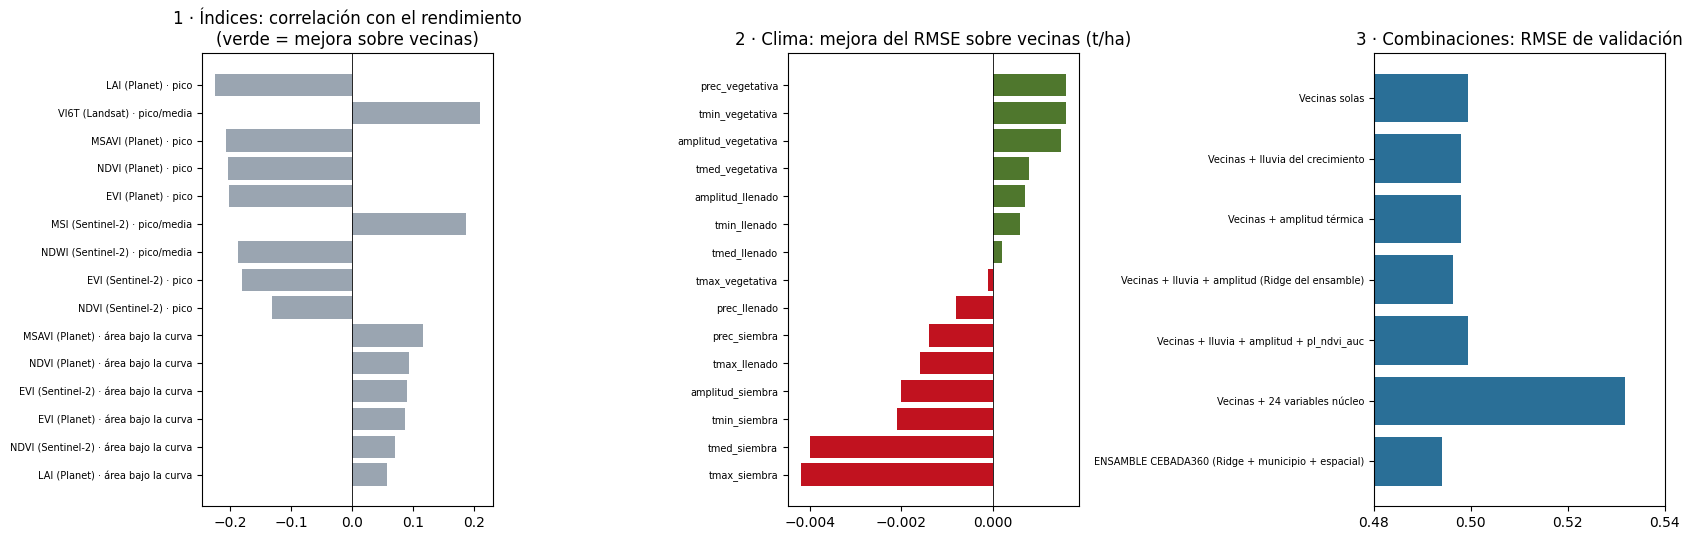

In [70]:
# Paso D · Preguntas guía: cada índice o variable climática se evalúa como "vecinas + variable" con la misma validación.
# La decisión se basa en la mejora del RMSE fuera de muestra, no en la correlación.
# ------------------------------------------------------------------ PASO D · preguntas guía del reto
# Cada variable se prueba igual: vecinas + esa variable (Ridge), con la validación del equipo (evaluar, paso 13).
RMSE_VEC = evaluar(bI3, [])["RMSE"]
spear = lambda c: round(float(spearmanr(trI3[c], yI3, nan_policy="omit")[0]), 4)

# 1. ¿Qué índice es más importante?
INDICES = [("LAI (Planet)", "pico", "pl_lai_pico"), ("VI6T (Landsat)", "pico/media", "ls_vi6t_media_jul_oct"),
           ("MSAVI (Planet)", "pico", "pl_msavi_pico"), ("NDVI (Planet)", "pico", "pl_ndvi_pico"),
           ("EVI (Planet)", "pico", "pl_evi_pico"), ("MSI (Sentinel-2)", "pico/media", "s2_msi_pico"),
           ("NDWI (Sentinel-2)", "pico/media", "s2_ndwi_pico"), ("EVI (Sentinel-2)", "pico", "s2_evi_pico"),
           ("NDVI (Sentinel-2)", "pico", "s2_ndvi_pico"), ("MSAVI (Planet)", "área bajo la curva", "pl_msavi_auc"),
           ("NDVI (Planet)", "área bajo la curva", "pl_ndvi_auc"), ("EVI (Sentinel-2)", "área bajo la curva", "s2_evi_auc"),
           ("EVI (Planet)", "área bajo la curva", "pl_evi_auc"), ("NDVI (Sentinel-2)", "área bajo la curva", "s2_ndvi_auc"),
           ("LAI (Planet)", "área bajo la curva", "pl_lai_auc")]
pg1 = pd.DataFrame([{"indice": i, "metrica": m, "variable": v, "spearman": spear(v),
                     "rmse_con_vecinas": evaluar(bI3, [v])["RMSE"]} for i, m, v in INDICES if v in bI3])
pg1["mejora_vs_vecinas"] = (RMSE_VEC - pg1.rmse_con_vecinas).round(4)
pg1 = pg1.sort_values("spearman", key=abs, ascending=False).reset_index(drop=True)

# 2. ¿Qué variable climática tiene mayor peso?
CLIM = [f"clim_{v}_{e}_2025" for e in ["vegetativa", "llenado", "siembra"] for v in ["prec", "tmin", "tmax", "tmed", "amplitud"]]
pg2 = pd.DataFrame([{"variable": v, "spearman": spear(v), "rmse_con_vecinas": evaluar(bI3, [v])["RMSE"]} for v in CLIM if v in bI3])
pg2["mejora_vs_vecinas"] = (RMSE_VEC - pg2.rmse_con_vecinas).round(4)
pg2 = pg2.sort_values("rmse_con_vecinas").reset_index(drop=True)

# 3. ¿Qué combinación funciona mejor?
P, A = VARS_CLIMA
pg3 = pd.DataFrame([
    {"combinacion": "Vecinas solas", "variables": 1, "RMSE": RMSE_VEC},
    {"combinacion": "Vecinas + lluvia del crecimiento", "variables": 2, "RMSE": evaluar(bI3, [P])["RMSE"]},
    {"combinacion": "Vecinas + amplitud térmica", "variables": 2, "RMSE": evaluar(bI3, [A])["RMSE"]},
    {"combinacion": "Vecinas + lluvia + amplitud (Ridge del ensamble)", "variables": 3, "RMSE": evaluar(bI3, [P, A])["RMSE"]},
    {"combinacion": "Vecinas + lluvia + amplitud + pl_ndvi_auc", "variables": 4, "RMSE": evaluar(bI3, [P, A, "pl_ndvi_auc"])["RMSE"]},
    {"combinacion": f"Vecinas + {len(NUCLEO)} variables núcleo", "variables": len(NUCLEO) + 1, "RMSE": evaluar(bI3, NUCLEO)["RMSE"]},
    {"combinacion": "ENSAMBLE CEBADA360 (Ridge + municipio + espacial)", "variables": 5, "RMSE": float(ens.RMSE)}])

for f, t in [("preguntas_guia_1_indices.csv", pg1), ("preguntas_guia_2_clima.csv", pg2), ("preguntas_guia_3_combinaciones.csv", pg3)]:
    t.to_csv(RES / f, index=False)
print("1 · Índices (ordenados por |Spearman|):"); print(pg1.to_string(index=False))
print("\n2 · Clima (ordenado por RMSE con vecinas):"); print(pg2.to_string(index=False))
print("\n3 · Combinaciones:"); print(pg3.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))
ax[0].barh(pg1.indice + " · " + pg1.metrica, pg1.spearman, color=np.where(pg1.mejora_vs_vecinas > 0, "#4f772d", "#9aa5b1"))
ax[0].invert_yaxis(); ax[0].axvline(0, c="k", lw=.6); ax[0].set_title("1 · Índices: correlación con el rendimiento\n(verde = mejora sobre vecinas)")
ax[0].tick_params(axis="y", labelsize=7)
ax[1].barh(pg2.variable.str.replace("clim_", "").str.replace("_2025", ""), pg2.mejora_vs_vecinas,
           color=np.where(pg2.mejora_vs_vecinas > 0, "#4f772d", "#c1121f"))
ax[1].invert_yaxis(); ax[1].axvline(0, c="k", lw=.6); ax[1].set_title("2 · Clima: mejora del RMSE sobre vecinas (t/ha)")
ax[1].tick_params(axis="y", labelsize=7)
ax[2].barh(pg3.combinacion, pg3.RMSE, color="#2a6f97"); ax[2].invert_yaxis(); ax[2].set_xlim(.48, max(.54, pg3.RMSE.max() + .005))
ax[2].set_title("3 · Combinaciones: RMSE de validación"); ax[2].tick_params(axis="y", labelsize=7)
fig.tight_layout(); fig.savefig(FIG_I3 / "preguntas_guia.png", dpi=150); plt.show()


### Paso E · Modelo final y predicciones
**Intervalo predictivo empírico de referencia** (nominal 80 % y 90 %): predicción ± cuantiles de |error| fuera de fold, porque los errores no son normales (paso 17). su cobertura se calibra con los mismos errores fuera de fold, así que **no tiene garantía de cobertura en parcelas nuevas** ni es un intervalo conformal con garantía formal; es una banda orientativa.

Semáforo (orientativo): probabilidad **aproximada** de rendimiento menor a 3.0 t/ha, calculada **suponiendo errores normales** (el paso 17 rechaza esa normalidad; por eso la app usa la probabilidad con errores reales del paso 24). ≥ 0.5 rojo, ≥ 0.2 amarillo, si no verde.

### Explicación

1. El ensamble se entrena con **las 138 parcelas** y predice las 59 de PREDICCION. Se guarda en `modelo.joblib` y se comprueba que el archivo guardado reproduce la misma predicción.
2. Para las 138 se guarda su predicción **fuera de fold** (repetición 0 de la validación), no la del modelo final, porque esa es la honesta para revisar errores (el modelo final ya "vio" esas parcelas).
3. **Intervalo empírico simétrico:** predicción ± el cuantil 80 % (o 90 %) del error absoluto fuera de fold. Se usó en lugar de ± z·σ porque los errores no son normales (paso 17). Es una banda orientativa: se calibró con los mismos errores, así que no garantiza la cobertura en parcelas nuevas.
4. **Probabilidad aproximada de rendimiento < 3.0 t/ha** y semáforo (≥ 0.5 rojo, ≥ 0.2 amarillo, si no verde), calculados suponiendo error normal con σ = RMSE. Es orientativo; la app usa el semáforo de crédito del paso 24, que usa los errores reales.

**Cómo leer los resultados.** La celda imprime el ancho de los intervalos (± t/ha al 80 % y 90 %) y cuántas de las 59 quedan en cada color del semáforo orientativo. En la corrida de referencia el intervalo es ±0.55 t/ha al 80 %: en 8 de cada 10 parcelas de entrenamiento el rendimiento real cayó a menos de 0.55 t/ha de lo predicho. Para el crédito, la referencia es el semáforo del paso 24.

**Archivos.** `predicciones.csv` (197 filas, con `tipo_prediccion` para distinguir fuera de fold vs modelo final) y `predicciones_59_entrega.csv` (solo ID y rendimiento con 4 decimales). La versión que se entrega a la plataforma es la que vuelve a generar y verificar el paso 19 en `resultados_I3/ENTREGA/`.

In [71]:
# Paso E · Entrena el ensamble con las 138, predice las 59, guarda modelo.joblib y construye intervalos empíricos
# (cuantiles del |error| fuera de fold) y un semáforo orientativo. Las 138 llevan su predicción FUERA DE FOLD.
# ------------------------------------------------------------------ PASO E · modelo final y predicciones
# Se entrena con las 138 y se predicen las 59. Para las 138 se guarda su predicción FUERA DE FOLD (repetición 0),
# que es la que usa el paso 17 para revisar los supuestos. Intervalos con los cuantiles de |error| fuera de fold.
# Modelo final: mismas reglas que en la validación, ahora con las 138 parcelas con rendimiento.
modelo_final = ModeloCebada360().fit(trI3)
modelo_final.guardar(RES / "modelo.joblib")
pred59_E = modelo_final.predict(prI3)
E_ens = yI3[None, :] - OOF_ENS
RMSE_E = float(np.sqrt((E_ens ** 2).mean()))
# Semiancho del intervalo = cuantil del |error| fuera de fold (no supone normalidad).
q80, q90 = (float(np.quantile(np.abs(E_ens), lv)) for lv in (.8, .9))
pred = pd.concat([trI3[["ID_POLIGONO", "CONJUNTO"]].assign(y_pred=OOF_ENS[0]),
                  prI3[["ID_POLIGONO", "CONJUNTO"]].assign(y_pred=pred59_E)], ignore_index=True)
pred = pred.assign(y_lo80=pred.y_pred - q80, y_hi80=pred.y_pred + q80, y_lo90=pred.y_pred - q90, y_hi90=pred.y_pred + q90,
                   # P aproximada de rendimiento < 3 t/ha suponiendo error normal: solo orientativa (el paso 17
                   # rechaza la normalidad).
                   p_bajo=norm.cdf((Y_CORTE - pred.y_pred) / RMSE_E))
pred["semaforo"] = np.select([pred.p_bajo >= .5, pred.p_bajo >= .2], ["rojo", "amarillo"], "verde")
pred["fuente"] = "ENSAMBLE CEBADA360 v1 (paso E)"
pred["tipo_prediccion"] = np.where(pred.CONJUNTO == "ENTRENAMIENTO",
                                   "fuera de fold (validación cruzada, repetición 0)", "modelo final (entrenado con las 138)")
pred = pred.sort_values("ID_POLIGONO").round(4).reset_index(drop=True)
pred.to_csv(RES / "predicciones.csv", index=False)
pred.loc[pred.CONJUNTO == "PREDICCION", ["ID_POLIGONO", "y_pred"]].rename(columns={"y_pred": "rendimiento_t_ha"}) \
    .to_csv(RES / "predicciones_59_entrega.csv", index=False, float_format="%.4f")

# el modelo guardado se vuelve a cargar como lo haría la app
_rec = modelo_cebada360.predecir(prI3, RES / "modelo.joblib")
# Control: el modelo guardado, cargado como lo haría la app, debe dar exactamente lo mismo.
assert np.abs(_rec - np.round(pred59_E, 4)).max() < 1e-9, "modelo.joblib no reproduce la predicción"
p59 = pred[pred.CONJUNTO == "PREDICCION"]
print(f"Modelo final: Ridge alfa = {modelo_final.ridge_.named_steps['ridgecv'].alpha_:.3g} · GP {modelo_final.gp_.kernel_}")
print(f"59 predicciones: media {p59.y_pred.mean():.4f} · mín {p59.y_pred.min():.4f} · máx {p59.y_pred.max():.4f} t/ha")
print(f"Intervalo predictivo empírico de referencia (cuantiles de |error| fuera de fold): ±{q80:.3f} t/ha (nominal 80 %) · "
      f"±{q90:.3f} t/ha (nominal 90 %). Calibrado con los mismos errores fuera de fold: sin garantía de cobertura en parcelas nuevas.")
print(f"Semáforo orientativo (P aproximada [rendimiento < {Y_CORTE}] con supuesto normal; ≥ 0.5 rojo, ≥ 0.2 amarillo): "
      + str(p59.semaforo.value_counts().to_dict()))
print("Guardado: predicciones.csv (197, para la app), predicciones_59_entrega.csv, modelo.joblib, modelo_cebada360.py")


Modelo final: Ridge alfa = 1.17 · GP 0.727**2 * RBF(length_scale=9.81) + WhiteKernel(noise_level=0.339)
59 predicciones: media 3.9372 · mín 2.8297 · máx 4.6928 t/ha
Intervalo predictivo empírico de referencia (cuantiles de |error| fuera de fold): ±0.552 t/ha (nominal 80 %) · ±0.689 t/ha (nominal 90 %). Calibrado con los mismos errores fuera de fold: sin garantía de cobertura en parcelas nuevas.
Semáforo orientativo (P aproximada [rendimiento < 3.0] con supuesto normal; ≥ 0.5 rojo, ≥ 0.2 amarillo): {'verde': 37, 'amarillo': 15, 'rojo': 7}
Guardado: predicciones.csv (197, para la app), predicciones_59_entrega.csv, modelo.joblib, modelo_cebada360.py


### Paso F · Factores de cada predicción (para la app)
Promedio de entrenamiento + suma de las 5 contribuciones = predicción **del modelo final** (exacto salvo redondeo). En las 59 es la predicción entregada. En las 138 explica el ajuste del modelo final, **no** su predicción fuera de fold de `predicciones.csv` (pueden diferir hasta ~0.4 t/ha porque son procedimientos distintos); las columnas `prediccion_modelo_final` y `tipo_explicacion` de `factores.csv`, y `tipo_prediccion` de `predicciones.csv`, lo indican.

**Importante:** es una **descomposición aditiva contable** del ensamble, no un valor SHAP exacto ni un efecto causal. Vecinas, promedio del municipio y patrón espacial dependen todos de la ubicación, así que no son factores independientes. Sirve para explicar de dónde sale cada predicción.

**Cómo leer los resultados.**

Para cada parcela, la predicción se descompone de forma **exacta y aditiva**:

predicción = promedio de entrenamiento (≈ 3.955 t/ha) + vecinas + lluvia + amplitud + municipio + patrón espacial

Las tres primeras contribuciones salen del Ridge (coeficiente × valor estandarizado ÷ 3) y las otras dos son la diferencia del promedio municipal y del GP respecto a la media, también divididas entre 3. En la corrida de referencia la contribución media absoluta fue: municipio 0.226, patrón espacial 0.216, vecinas 0.194, amplitud 0.027 y lluvia 0.021 t/ha.

**Cuidado al interpretar.** Es una descomposición contable, **no** valores SHAP ni efectos causales. Vecinas, municipio y patrón espacial dependen todos de la ubicación y están muy relacionados entre sí, así que repartir el crédito entre ellos es en parte arbitrario. En las 138 los factores explican el ajuste del modelo final, no su predicción fuera de fold (por eso las columnas `prediccion_modelo_final` y `tipo_explicacion`).

factores.csv: 985 filas (197 parcelas × 5 factores)
En las 138 el modelo final y la predicción fuera de fold difieren hasta 0.398 t/ha (procedimientos distintos, es lo esperado): sus factores explican el modelo final, como indica la columna tipo_explicacion.
Comprobación en las 59: promedio 3.9554 + suma de contribuciones − predicción → máx |dif| 0.0002 t/ha

Importancia (contribución media absoluta, t/ha):
etiqueta
Lluvia en el crecimiento               0.0210
Amplitud térmica en el crecimiento     0.0273
Rendimiento de las parcelas vecinas    0.1944
Patrón espacial de la zona             0.2156
Promedio del municipio                 0.2264


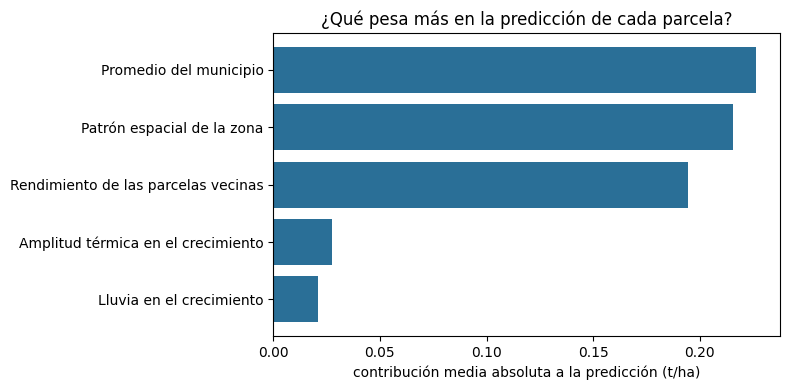

In [72]:
# Paso F · Descomposición aditiva de cada predicción del modelo final (para la app). No es SHAP ni efecto causal.
# ------------------------------------------------------------------ PASO F · factores de cada predicción (para la app)
# Descomposición aditiva contable: promedio de entrenamiento + suma de contribuciones = predicción (exacta salvo redondeo).
# No es SHAP ni efecto causal: vecinas, municipio y GP dependen todos de la ubicación.
# las contribuciones explican SIEMPRE el modelo final (entrenado con las 138). En las 59 reconstruyen
# la predicción entregada; en las 138 reconstruyen el ajuste del modelo final, NO la predicción fuera de fold que guarda
# predicciones.csv para validación (pueden diferir varias décimas). Por eso se agregan dos columnas que lo dicen.
factores = modelo_final.factores(bI3.sort_values("ID_POLIGONO"))
_s = factores.groupby("ID_POLIGONO").contribucion.sum() + modelo_final.media_
_conj = bI3.set_index("ID_POLIGONO").CONJUNTO
factores["prediccion_modelo_final"] = factores.ID_POLIGONO.map(_s).round(4)
factores["tipo_explicacion"] = np.where(factores.ID_POLIGONO.map(_conj) == "PREDICCION",
                                        "explica la predicción entregada (modelo final)",
                                        "explica el ajuste del modelo final; NO la predicción fuera de fold de predicciones.csv")
factores.to_csv(RES / "factores.csv", index=False)
_chk = (_s.reindex(prI3.ID_POLIGONO).values - np.round(pred59_E, 4))
print(f"factores.csv: {len(factores)} filas ({factores.ID_POLIGONO.nunique()} parcelas × 5 factores)")
_oof = pd.read_csv(RES / "predicciones.csv").set_index("ID_POLIGONO").y_pred
_d138 = float((_s.reindex(trI3.ID_POLIGONO) - _oof.reindex(trI3.ID_POLIGONO)).abs().max())
print(f"En las 138 el modelo final y la predicción fuera de fold difieren hasta {_d138:.3f} t/ha (procedimientos distintos, "
      f"es lo esperado): sus factores explican el modelo final, como indica la columna tipo_explicacion.")
print(f"Comprobación en las 59: promedio {modelo_final.media_:.4f} + suma de contribuciones − predicción → máx |dif| {np.abs(_chk).max():.4f} t/ha")
imp = factores.groupby("etiqueta").contribucion.apply(lambda s: s.abs().mean()).sort_values()
print("\nImportancia (contribución media absoluta, t/ha):"); print(imp.round(4).to_string())
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.index, imp.values, color="#2a6f97"); ax.set_xlabel("contribución media absoluta a la predicción (t/ha)")
ax.set_title("¿Qué pesa más en la predicción de cada parcela?"); fig.tight_layout()
fig.savefig(FIG_I3 / "importancia_factores.png", dpi=150); plt.show()


### Paso G · Gráfica de modelos y versiones

### Explicación

Grafica el RMSE de todos los modelos del paso B con su desviación entre repeticiones (azul = elegido, gris = componentes y referencias, rojo = descartados) y guarda `VERSIONES.txt` con las versiones de Python y librerías, porque `modelo.joblib` solo se garantiza con la misma versión de scikit-learn.

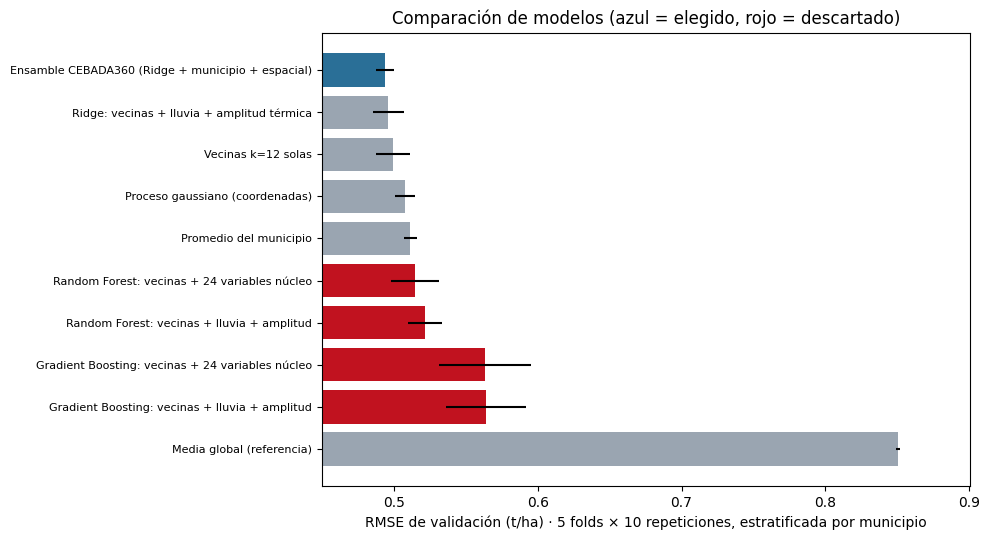

python 3.13.16
scikit-learn 1.6.1
numpy 2.1.3
pandas 2.2.3
scipy 1.16.3

Archivos del Integrante 3 en /content/resultados_I3 : ['VERIFICACION_FINAL.txt', 'VERSIONES.txt', 'alerta_dano_59.csv', 'atipicos_diagnostico.csv', 'atipicos_resumen.csv', 'barrido_resumen.csv', 'barrido_variables.csv', 'criterios_informacion.csv', 'curva_aprendizaje.csv', 'curva_aprendizaje_atipicas.csv', 'curva_aprendizaje_resumen.csv', 'curva_aprendizaje_tramos.csv', 'eleccion_k_vecinas.csv', 'ensamble_no_lineal.csv', 'error_por_distancia.csv', 'factores.csv', 'intervalos_normal_vs_empirico.csv', 'metricas_modelos.csv', 'metricas_respaldo.csv', 'modelo.joblib', 'modelo_cebada360.py', 'pesos_ensamble_comparacion.csv', 'pesos_ensamble_por_fold.csv', 'pesos_ensamble_por_repeticion.csv', 'predicciones.csv', 'predicciones_59_entrega.csv', 'preguntas_guia_1_indices.csv', 'preguntas_guia_2_clima.csv', 'preguntas_guia_3_combinaciones.csv', 'requirements.txt', 'residuales_diagnostico.csv', 'supuestos_resumen.csv', 'vali

In [73]:
# Paso G · Gráfica comparativa de modelos y registro de versiones de librerías (reproducibilidad de modelo.joblib).
# ------------------------------------------------------------------ PASO G · gráfica de modelos y versiones
m = metricas.sort_values("RMSE", ascending=False)
col = m.familia.map({"seleccionado": "#2a6f97", "componente / referencia": "#9aa5b1", "descartado (ML de árboles)": "#c1121f"})
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(m.modelo, m.RMSE, xerr=m.RMSE_sd, color=col)
ax.set_xlabel("RMSE de validación (t/ha) · 5 folds × 10 repeticiones, estratificada por municipio")
ax.set_xlim(.45, m.RMSE.max() + .05); ax.tick_params(axis="y", labelsize=8)
ax.set_title("Comparación de modelos (azul = elegido, rojo = descartado)")
fig.tight_layout(); fig.savefig(FIG_I3 / "comparacion_modelos.png", dpi=150); plt.show()

import sklearn, scipy
(RES / "VERSIONES.txt").write_text(
    f"python {platform.python_version()}\nscikit-learn {sklearn.__version__}\nnumpy {np.__version__}\n"
    f"pandas {pd.__version__}\nscipy {scipy.__version__}\n", encoding="utf-8")
print((RES / "VERSIONES.txt").read_text())
print("Archivos del Integrante 3 en", RES, ":", sorted(p.name for p in RES.iterdir() if p.is_file()))


## Paso 17 · Verificación de supuestos de los residuales

Residuales: e_i = y_i − ŷ_i con ŷ_i = predicción FUERA DE FOLD del ensamble (validación cruzada), en las 138 parcelas de entrenamiento. Es la mejor aproximación a los errores del modelo en parcelas que no vio.
Supuestos (α = 0.05):
1 media cero
2 varianza constante
3 normalidad
4 independencia (espacial)
5 especificación y multicolinealidad (regresión MCO **auxiliar**, no el ensamble)
6 atípicos e influencia (sobre la misma regresión auxiliar)
7 consecuencia para los intervalos de predicción

**Cómo leer las pruebas:** con p ≥ 0.05 se dice **«no se rechaza H₀»**: no hay evidencia en contra del supuesto con estos datos, pero eso **no demuestra** que se cumpla. Con p < 0.05, **«se rechaza H₀»**. Las pruebas 1-4 usan los residuales fuera de fold del ensamble; las 5-6, una regresión MCO auxiliar (vecinas + lluvia + amplitud) que no es el ensamble. Durbin-Watson y Ljung-Box se calculan con las parcelas ordenadas de oeste a este: son una referencia espacial complementaria, **no** un análisis temporal; la prueba espacial principal es el índice de Moran.

### Explicación

Aunque el ensamble no es una regresión clásica, los supuestos sobre sus **errores fuera de fold** tienen consecuencias prácticas: si los errores no son normales, los intervalos ± z·σ no cubren lo que prometen; si hay autocorrelación espacial en los errores, quedaría información de ubicación sin aprovechar.

**Pruebas que corre la celda.**
- *Media cero:* prueba t de una muestra (calculada a mano y con su valor p).
- *Varianza constante:* Breusch-Pagan contra los valores ajustados y contra el municipio, White contra el clima y Levene/Brown-Forsythe por municipio.
- *Normalidad:* Anderson-Darling, Jarque-Bera, Shapiro-Wilk y Lilliefors, más histograma y QQ-plot.
- *Independencia espacial:* índice de Moran con 8 vecinas y 999 permutaciones (prueba principal). Durbin-Watson y Ljung-Box se calculan ordenando las parcelas de oeste a este: son solo una referencia espacial, no un análisis temporal.
- *Especificación y multicolinealidad:* RESET de Ramsey y VIF sobre una **regresión MCO auxiliar** (vecinas + lluvia + amplitud), que no es el ensamble.
- *Atípicos e influencia:* residuales studentizados y distancia de Cook sobre la misma regresión auxiliar.
- *Consecuencia:* comparación de intervalos normales contra empíricos.

**Resultados de la corrida de referencia.** Media cero: no se rechaza. Varianza constante: no se rechaza. **Normalidad: se rechaza** (cola de siniestros con errores negativos grandes), por eso los intervalos son empíricos. Independencia espacial: Moran p = 0.13, no se rechaza: las vecinas, el municipio y el GP ya absorben la estructura espacial. RESET p = 0.001 (indicio de no linealidad leve en el MCO auxiliar; el paso 18 muestra que los términos no lineales no mejoran fuera de muestra). VIF ≈ 1.9 (sin multicolinealidad relevante). 7 parcelas atípicas, que **no** se eliminan: son siniestros reales que el modelo debe enfrentar.

**Cómo leer "no se rechaza H₀".** Significa que no hay evidencia en contra del supuesto con estos datos, no que se haya demostrado.

*Nota técnica:* esta celda vuelve a definir `BASE`, `RES` y `FIG` para poder correr sola. Por eso la celda final del notebook restablece `FIG` antes de imprimir el resumen.

Datos de: /content/outputs · resultados en: /content/resultados_I3
Residuales fuera de fold: n = 138 · media = -0.0017 · desv. est. = 0.5045 · min = -2.203 · max = 1.119


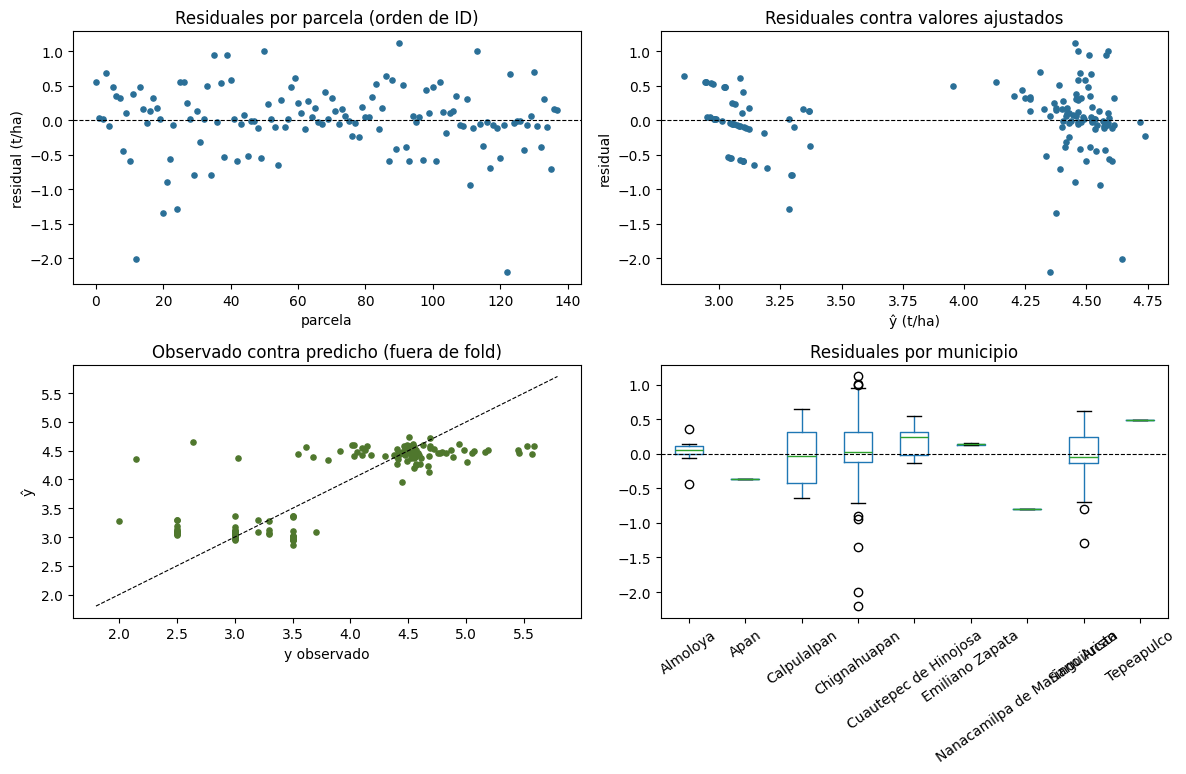


SUPUESTO 1 · Errores con media cero
  Forma manual: t0 = -0.0400 · t crítico (α/2, 137 gl) = 1.9774
  Prueba t de una muestra: estadístico = -0.0400 · p-valor = 0.9682
    H0: μ_e = 0
    p ≥ α → no se rechaza H0 · sin evidencia en contra del supuesto (no lo demuestra)

SUPUESTO 2 · Varianza constante (homocedasticidad)
  Breusch-Pagan (contra ajustados): estadístico = 1.0041 · p-valor = 0.3163
    H0: homocedasticidad
    p ≥ α → no se rechaza H0 · sin evidencia en contra del supuesto (no lo demuestra)
  Breusch-Pagan (contra municipio): estadístico = 4.3014 · p-valor = 0.636
    H0: misma varianza en todos los municipios
    p ≥ α → no se rechaza H0 · sin evidencia en contra del supuesto (no lo demuestra)
  White (contra clima, con cuadrados y cruces): estadístico = 2.2139 · p-valor = 0.8188
    H0: homocedasticidad
    p ≥ α → no se rechaza H0 · sin evidencia en contra del supuesto (no lo demuestra)
  Levene/Brown-Forsythe (por municipio): estadístico = 1.4113 · p-valor = 0.215
   

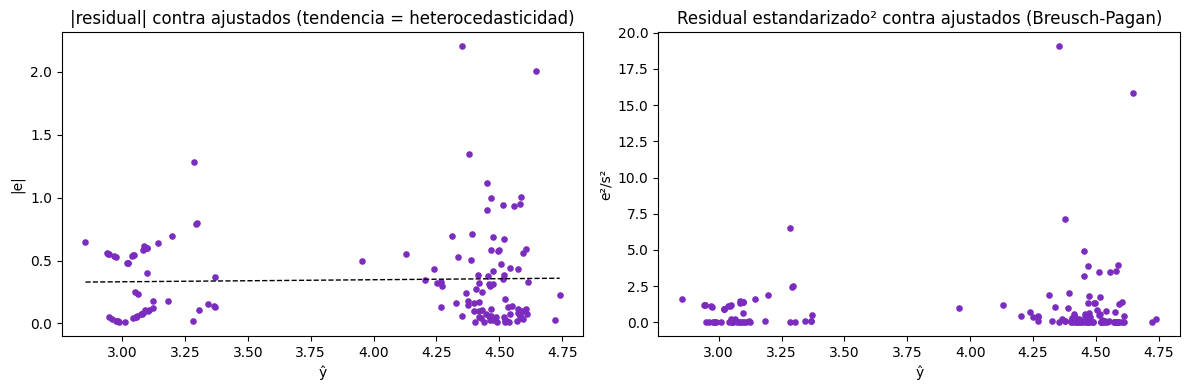


SUPUESTO 3 · Errores con distribución normal
  Anderson-Darling: estadístico = 2.6409 · p-valor = 1.083e-06
    H0: los errores son normales
    p < α → se rechaza H0 · evidencia en contra del supuesto
  Jarque-Bera: estadístico = 100.6106 · p-valor = 1.421e-22
    H0: asimetría = 0 y curtosis = 3
    p < α → se rechaza H0 · evidencia en contra del supuesto
  Shapiro-Wilk: estadístico = 0.9223 · p-valor = 7.603e-07
    H0: los errores son normales
    p < α → se rechaza H0 · evidencia en contra del supuesto
  Kolmogorov-Smirnov (Lilliefors): estadístico = 0.1663 · p-valor = 0.001
    H0: los errores son normales
    p < α → se rechaza H0 · evidencia en contra del supuesto
  Asimetría = -1.142 (normal: 0) · curtosis en exceso = 3.505 (normal: 0)


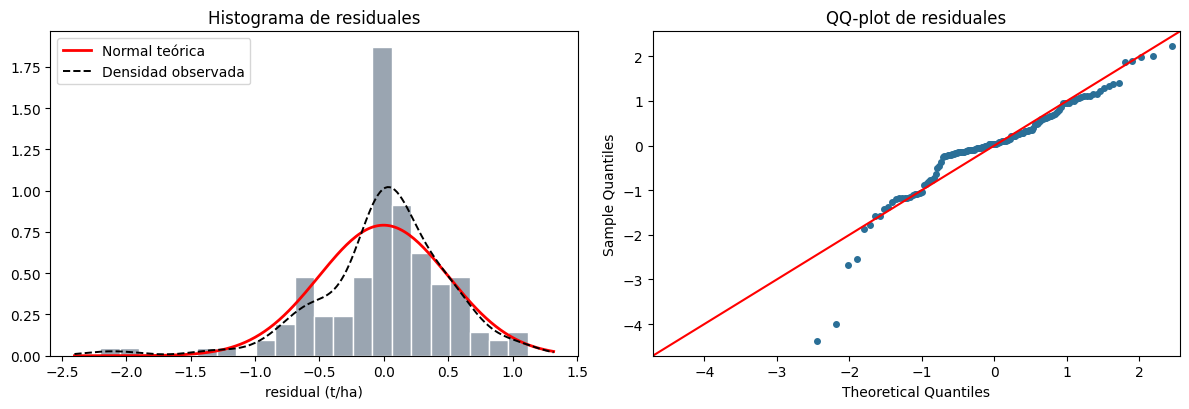


SUPUESTO 4 · Independencia de los errores
  En series de tiempo se usa Ljung-Box (correlación entre t y t−k). Aquí los datos son parcelas, así que la
  dependencia relevante es ESPACIAL: ¿el error de una parcela se parece al de sus vecinas? → Índice de Moran (prueba principal).
  Durbin-Watson y Ljung-Box se calculan con las parcelas ordenadas de oeste a este: son solo una referencia ESPACIAL
  complementaria, NO un análisis temporal (no hay una serie de rendimientos por parcela a lo largo de los años).
  E[I] bajo H0 = -0.0073
  Índice de Moran (8 vecinas, 999 permutaciones): estadístico = -0.0626 · p-valor = 0.13
    H0: no hay autocorrelación espacial
    p ≥ α → no se rechaza H0 · sin evidencia en contra del supuesto (no lo demuestra)
  Referencia espacial (no temporal): Durbin-Watson con las parcelas ordenadas de oeste a este = 2.081 (≈ 2: sin dependencia en ese orden)
  Ljung-Box sobre el orden espacial oeste→este (referencia, no temporal; rezago 10): estadístico = 8.5947 · p-va

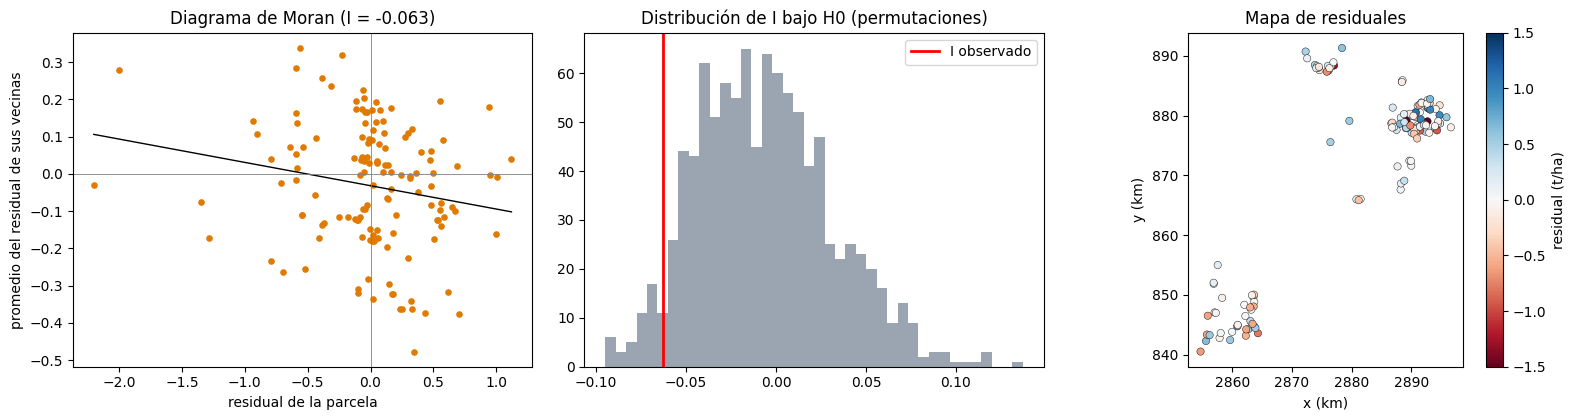


SUPUESTO 5 · Especificación y multicolinealidad (regresión MCO AUXILIAR: vecinas + lluvia + amplitud)
  OJO: estas pruebas son de la regresión auxiliar, NO del ensamble (que además promedia municipio y proceso gaussiano).
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             2.0881      1.115      1.872      0.063      -0.118       4.294
vecinas_k12                       0.8873      0.082     10.878      0.000       0.726       1.049
clim_prec_vegetativa_2025        -0.0009      0.000     -1.862      0.065      -0.002    5.32e-05
clim_amplitud_vegetativa_2025    -0.1494      0.088     -1.690      0.093      -0.324       0.025
  R² = 0.6714 · R² ajustado = 0.6640 · F = 91.26 (p = 3.17e-32) · AIC = 200.6 · BIC = 212.3
  RESET de Ramsey (potencias 2 y 3 de ŷ, MCO auxiliar): estadístico = 7.1681 · p-valor = 0.001108

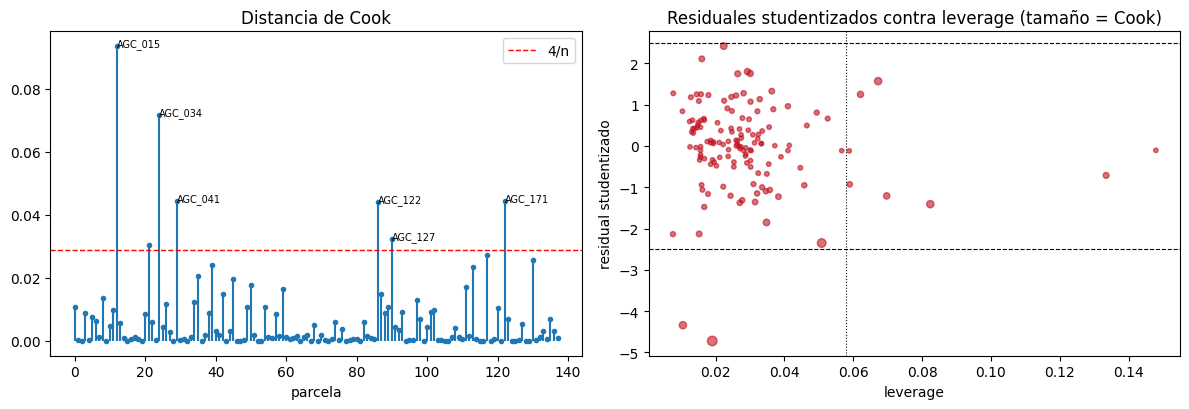


CONSECUENCIA · Intervalos de predicción: normal (ŷ ± z·σ) contra empírico (cuantiles de |e|)
nivel  semiancho_normal  cobertura_normal  semiancho_empirico  cobertura_empirica
 80 %             0.644             0.862               0.581               0.797
 90 %             0.827             0.920               0.703               0.899
 95 %             0.985             0.949               0.956               0.949
  Como se rechaza la normalidad, el intervalo normal no tiene la cobertura que dice. El empírico usa la distribución real
  de los errores, pero su cobertura se mide aquí con LOS MISMOS errores con que se construyó (calibración aparente):
  NO es una garantía de cobertura en parcelas nuevas ni un intervalo conformal con garantía formal.

================ RESUMEN DE SUPUESTOS ================
             supuesto                                                                            prueba                         modelo_evaluado  estadistico p_valor                   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [74]:
# Paso 17 · Supuestos de los residuales FUERA DE FOLD del ensamble (pruebas 1-4) y de una regresión MCO auxiliar
# (pruebas 5-6). Esta celda puede correr sola: si no existen los resultados del paso E, los recalcula.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import cdist
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, normal_ad, lilliefors, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.stattools import durbin_watson

# ------------------------------------------------------------------ preparación (funciona sola o después del paso G)
import zipfile
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

BASE = Path.cwd()
if "VARS_CLIMA" not in globals():
    VARS_CLIMA = ["clim_prec_vegetativa_2025", "clim_amplitud_vegetativa_2025"]
if "idw_vecinas" not in globals():
    def idw_vecinas(XY_dest, XY_or, y_or, k=12, excluir=None):
        D = cdist(XY_dest, XY_or)
        if excluir is not None: D = np.where(excluir, np.inf, D)
        idx = np.argsort(D, 1)[:, :k]
        w = 1 / np.maximum(np.take_along_axis(D, idx, 1), .05)
        return (w * y_or[idx]).sum(1) / w.sum(1)
if "OUT" not in globals() or not (Path(OUT) / "base_maestra_v3.csv").exists():
    hits = sorted(BASE.rglob("base_maestra_v3.csv"))
    assert hits, "No encuentro base_maestra_v3.csv: corre antes el notebook de los Integrantes 1 y 2 o sube su zip de resultados."
    OUT = hits[0].parent
OUT = Path(OUT)
if "RES" not in globals():
    RES = BASE / "resultados_I3"
RES = Path(RES); RES.mkdir(exist_ok=True)
FIG = RES / "figs"; FIG.mkdir(exist_ok=True)
print("Datos de:", OUT, "· resultados en:", RES)

if not (RES / "predicciones.csv").exists():
    print("No hay predicciones.csv: calculo las predicciones fuera de fold del ensamble (≈1 min)...")
    _b = pd.read_csv(OUT / "base_maestra_v3.csv").merge(pd.read_csv(OUT / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km"]], on="ID_POLIGONO")
    _tr = _b[_b.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
    _XY, _y = _tr[["x_km", "y_km"]].values.astype(float), _tr.y.values.astype(float)
    _est = _tr.Municipio.where(_tr.Municipio.map(_tr.Municipio.value_counts()) >= 5, "Otros")
    _oof = np.zeros(len(_tr))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(_tr, _est):
        va = idw_vecinas(_XY[a], _XY[a], _y[a], excluir=np.eye(len(a), dtype=bool)); vb = idw_vecinas(_XY[b], _XY[a], _y[a])
        rid = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
        rid.fit(np.c_[va, _tr.loc[a, VARS_CLIMA].values.astype(float)], _y[a])
        p1 = rid.predict(np.c_[vb, _tr.loc[b, VARS_CLIMA].values.astype(float)])
        p2 = _tr.loc[b, "Municipio"].map(_tr.loc[a].groupby("Municipio").y.mean()).fillna(_y[a].mean()).values
        gp = GaussianProcessRegressor(ConstantKernel(0.5) * RBF(3.0, (0.1, 50)) + WhiteKernel(0.2), normalize_y=True, random_state=0).fit(_XY[a], _y[a])
        _oof[b] = (p1 + p2 + gp.predict(_XY[b])) / 3
    pd.DataFrame({"ID_POLIGONO": _tr.ID_POLIGONO, "CONJUNTO": "ENTRENAMIENTO", "y_pred": _oof.round(4)}).to_csv(RES / "predicciones.csv", index=False)

ALFA = 0.05
FIG17 = FIG / "paso17_supuestos"; FIG17.mkdir(exist_ok=True)
resumen = []
# Qué se está evaluando en cada prueba: las pruebas 1-4 usan los residuales FUERA
# DE FOLD del ensamble; las 5-6 usan una regresión MCO AUXILIAR (vecinas + lluvia + amplitud) que NO es el ensamble.
MODELO_EVALUADO = "residuales fuera de fold del ensamble"

def concluir(supuesto, prueba, h0, estadistico, p, se_cumple_si_no_rechaza=True, nota=""):
    """Imprime H0, estadístico, p-valor y la decisión estadística, y guarda la fila del resumen.
    Corrección de la auditoría: con p ≥ α solo se puede decir «no se rechaza H0» (no hay evidencia en contra del
    supuesto); eso NO demuestra que el supuesto se cumpla. Con p < α «se rechaza H0» (hay evidencia en contra)."""
    rechaza = p < ALFA
    decision = "se rechaza H0" if rechaza else "no se rechaza H0"
    lectura = ("evidencia en contra del supuesto" if rechaza else "sin evidencia en contra del supuesto (no lo demuestra)") \
        if se_cumple_si_no_rechaza else ("evidencia a favor" if rechaza else "sin evidencia suficiente")
    print(f"  {prueba}: estadístico = {estadistico:.4f} · p-valor = {p:.4g}")
    print(f"    H0: {h0}")
    print(f"    {'p < α' if rechaza else 'p ≥ α'} → {decision} · {lectura}" + (f" · {nota}" if nota else ""))
    resumen.append({"supuesto": supuesto, "prueba": prueba, "modelo_evaluado": MODELO_EVALUADO, "H0": h0,
                    "estadistico": round(float(estadistico), 4), "p_valor": float(p), "conclusion": decision,
                    "lectura": lectura, "nota": nota})

# ------------------------------------------------------------------ 0. residuales
pred = pd.read_csv(RES / "predicciones.csv")
bm17 = pd.read_csv(OUT / "base_maestra_v3.csv")
co17 = pd.read_csv(OUT / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km"]]
d = (pred[pred.CONJUNTO == "ENTRENAMIENTO"][["ID_POLIGONO", "y_pred"]]
     .merge(bm17[["ID_POLIGONO", "y", "Municipio", "rend_redondo"] + VARS_CLIMA], on="ID_POLIGONO")
     .merge(co17, on="ID_POLIGONO").reset_index(drop=True))
d["e"] = d.y - d.y_pred
e, yhat, n = d.e.values, d.y_pred.values, len(d)
s_e = e.std(ddof=1)
d["e_std"] = e / s_e
print(f"Residuales fuera de fold: n = {n} · media = {e.mean():.4f} · desv. est. = {s_e:.4f} · min = {e.min():.3f} · max = {e.max():.3f}")

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].scatter(range(n), e, s=14, c="#2a6f97"); ax[0, 0].axhline(0, ls="--", c="k", lw=.8)
ax[0, 0].set_title("Residuales por parcela (orden de ID)"); ax[0, 0].set_xlabel("parcela"); ax[0, 0].set_ylabel("residual (t/ha)")
ax[0, 1].scatter(yhat, e, s=14, c="#2a6f97"); ax[0, 1].axhline(0, ls="--", c="k", lw=.8)
ax[0, 1].set_title("Residuales contra valores ajustados"); ax[0, 1].set_xlabel("ŷ (t/ha)"); ax[0, 1].set_ylabel("residual")
ax[1, 0].scatter(d.y, yhat, s=14, c="#4f772d"); lim = [d.y.min() - .2, d.y.max() + .2]
ax[1, 0].plot(lim, lim, "k--", lw=.8); ax[1, 0].set_title("Observado contra predicho (fuera de fold)"); ax[1, 0].set_xlabel("y observado"); ax[1, 0].set_ylabel("ŷ")
d.boxplot(column="e", by="Municipio", ax=ax[1, 1], rot=35, grid=False); ax[1, 1].axhline(0, ls="--", c="k", lw=.8)
ax[1, 1].set_title("Residuales por municipio"); ax[1, 1].set_xlabel(""); fig.suptitle("")
fig.tight_layout(); fig.savefig(FIG17 / "17_0_residuales.png", dpi=150); plt.show()

# ------------------------------------------------------------------ 1. media cero
print("\nSUPUESTO 1 · Errores con media cero")
# Supuesto 1: si el modelo no tiene sesgo, el error promedio debería ser 0.
t_manual = (e.mean() - 0) / (s_e / np.sqrt(n))                         # t0 = x̄ / (s/√n) ~ t(n−1)
p_manual = 2 * stats.t.sf(abs(t_manual), df=n - 1)
print(f"  Forma manual: t0 = {t_manual:.4f} · t crítico (α/2, {n-1} gl) = {stats.t.ppf(1 - ALFA/2, n-1):.4f}")
concluir("1. Media cero", "Prueba t de una muestra", "μ_e = 0", t_manual, p_manual)

# ------------------------------------------------------------------ 2. varianza constante
print("\nSUPUESTO 2 · Varianza constante (homocedasticidad)")
X_aj = sm.add_constant(pd.DataFrame({"ajustados": yhat}))
# Supuesto 2: ¿el tamaño del error crece con el rendimiento predicho?
bp = het_breuschpagan(e, X_aj)
concluir("2. Varianza constante", "Breusch-Pagan (contra ajustados)", "homocedasticidad", bp[0], bp[1])
X_mun = sm.add_constant(pd.get_dummies(d.Municipio.where(d.Municipio.map(d.Municipio.value_counts()) >= 3, "Otros"),
                                       drop_first=True).astype(float))
bp_m = het_breuschpagan(e, X_mun)
concluir("2. Varianza constante", "Breusch-Pagan (contra municipio)", "misma varianza en todos los municipios", bp_m[0], bp_m[1])
X_cl = sm.add_constant(d[VARS_CLIMA].astype(float))
wh = het_white(e, X_cl)
concluir("2. Varianza constante", "White (contra clima, con cuadrados y cruces)", "homocedasticidad", wh[0], wh[1])
grupos = [g.e.values for _, g in d.groupby(d.Municipio.where(d.Municipio.map(d.Municipio.value_counts()) >= 3, "Otros"))]
lev = stats.levene(*grupos, center="median")
concluir("2. Varianza constante", "Levene/Brown-Forsythe (por municipio)", "varianzas iguales entre municipios", lev.statistic, lev.pvalue)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(yhat, np.abs(e), s=14, c="#7b2cbf")
z = np.polyfit(yhat, np.abs(e), 1); xx = np.linspace(yhat.min(), yhat.max(), 50); ax[0].plot(xx, np.polyval(z, xx), "k--", lw=1)
ax[0].set_title("|residual| contra ajustados (tendencia = heterocedasticidad)"); ax[0].set_xlabel("ŷ"); ax[0].set_ylabel("|e|")
ax[1].scatter(yhat, d.e_std ** 2, s=14, c="#7b2cbf"); ax[1].set_title("Residual estandarizado² contra ajustados (Breusch-Pagan)")
ax[1].set_xlabel("ŷ"); ax[1].set_ylabel("e²/s²")
fig.tight_layout(); fig.savefig(FIG17 / "17_2_varianza.png", dpi=150); plt.show()

# ------------------------------------------------------------------ 3. normalidad
print("\nSUPUESTO 3 · Errores con distribución normal")
# Supuesto 3: varias pruebas de normalidad; con la cola de siniestros se espera rechazo.
ad = normal_ad(e)
concluir("3. Normalidad", "Anderson-Darling", "los errores son normales", ad[0], ad[1])
jb = stats.jarque_bera(e)
concluir("3. Normalidad", "Jarque-Bera", "asimetría = 0 y curtosis = 3", jb.statistic, jb.pvalue)
sw = stats.shapiro(e)
concluir("3. Normalidad", "Shapiro-Wilk", "los errores son normales", sw.statistic, sw.pvalue)
ks = lilliefors(e, dist="norm")
concluir("3. Normalidad", "Kolmogorov-Smirnov (Lilliefors)", "los errores son normales", ks[0], ks[1])
print(f"  Asimetría = {stats.skew(e):.3f} (normal: 0) · curtosis en exceso = {stats.kurtosis(e):.3f} (normal: 0)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(e, bins=22, density=True, color="#9aa5b1", edgecolor="white")
xx = np.linspace(e.min() - .2, e.max() + .2, 200); ax[0].plot(xx, stats.norm.pdf(xx, e.mean(), s_e), "r-", lw=2, label="Normal teórica")
ax[0].plot(xx, stats.gaussian_kde(e)(xx), "k--", lw=1.4, label="Densidad observada"); ax[0].legend()
ax[0].set_title("Histograma de residuales"); ax[0].set_xlabel("residual (t/ha)")
sm.qqplot(e, line="45", fit=True, ax=ax[1], markerfacecolor="#2a6f97", markeredgecolor="#2a6f97", markersize=4)
ax[1].set_title("QQ-plot de residuales")
fig.tight_layout(); fig.savefig(FIG17 / "17_3_normalidad.png", dpi=150); plt.show()

# ------------------------------------------------------------------ 4. independencia (espacial)
print("\nSUPUESTO 4 · Independencia de los errores")
print("  En series de tiempo se usa Ljung-Box (correlación entre t y t−k). Aquí los datos son parcelas, así que la")
print("  dependencia relevante es ESPACIAL: ¿el error de una parcela se parece al de sus vecinas? → Índice de Moran (prueba principal).")
print("  Durbin-Watson y Ljung-Box se calculan con las parcelas ordenadas de oeste a este: son solo una referencia ESPACIAL")
print("  complementaria, NO un análisis temporal (no hay una serie de rendimientos por parcela a lo largo de los años).")
XY = d[["x_km", "y_km"]].values
D = cdist(XY, XY); np.fill_diagonal(D, np.inf)
K_MORAN = 8
W = np.zeros_like(D); idx = np.argsort(D, 1)[:, :K_MORAN]
for i in range(n): W[i, idx[i]] = 1
W = W / W.sum(1, keepdims=True)                                         # matriz de pesos estandarizada por filas
zc = e - e.mean()
moran = lambda v: (n / W.sum()) * (v @ W @ v) / (v @ v)
# Supuesto 4: Moran de los residuales con 8 vecinas; p por 999 permutaciones (bilateral).
I_obs = moran(zc)
rng = np.random.default_rng(0); I_perm = np.array([moran(rng.permutation(zc)) for _ in range(999)])
p_moran = (np.sum(np.abs(I_perm - I_perm.mean()) >= abs(I_obs - I_perm.mean())) + 1) / 1000   # bilateral
print(f"  E[I] bajo H0 = {-1/(n-1):.4f}")
concluir("4. Independencia", f"Índice de Moran (8 vecinas, 999 permutaciones)", "no hay autocorrelación espacial", I_obs, p_moran)
orden = np.lexsort((d.y_km.values, d.x_km.values))                      # recorrido oeste → este
dw = durbin_watson(e[orden])
print(f"  Referencia espacial (no temporal): Durbin-Watson con las parcelas ordenadas de oeste a este = {dw:.3f} (≈ 2: sin dependencia en ese orden)")
lb_sorted = sm.stats.acorr_ljungbox(e[orden], lags=[1, 5, 10], return_df=True)
concluir("4. Independencia", "Ljung-Box sobre el orden espacial oeste→este (referencia, no temporal; rezago 10)",
         "no hay autocorrelación en ese orden", lb_sorted.lb_stat.iloc[-1], lb_sorted.lb_pvalue.iloc[-1],
         nota="complementaria; la prueba espacial principal es Moran")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
lag = W @ zc
ax[0].scatter(zc, lag, s=14, c="#e07a00"); b_ = np.polyfit(zc, lag, 1)
xx = np.linspace(zc.min(), zc.max(), 50); ax[0].plot(xx, np.polyval(b_, xx), "k-", lw=1)
ax[0].axhline(0, c="gray", lw=.6); ax[0].axvline(0, c="gray", lw=.6)
ax[0].set_title(f"Diagrama de Moran (I = {I_obs:.3f})"); ax[0].set_xlabel("residual de la parcela"); ax[0].set_ylabel("promedio del residual de sus vecinas")
ax[1].hist(I_perm, bins=40, color="#9aa5b1"); ax[1].axvline(I_obs, c="r", lw=2, label="I observado")
ax[1].set_title("Distribución de I bajo H0 (permutaciones)"); ax[1].legend()
sc = ax[2].scatter(d.x_km, d.y_km, c=e, cmap="RdBu", vmin=-1.5, vmax=1.5, s=28, edgecolor="k", lw=.3)
plt.colorbar(sc, ax=ax[2], label="residual (t/ha)"); ax[2].set_title("Mapa de residuales"); ax[2].set_xlabel("x (km)"); ax[2].set_ylabel("y (km)")
ax[2].set_aspect("equal")
fig.tight_layout(); fig.savefig(FIG17 / "17_4_independencia.png", dpi=150); plt.show()

# ------------------------------------------------------------------ 5. especificación y multicolinealidad
print("\nSUPUESTO 5 · Especificación y multicolinealidad (regresión MCO AUXILIAR: vecinas + lluvia + amplitud)")
print("  OJO: estas pruebas son de la regresión auxiliar, NO del ensamble (que además promedia municipio y proceso gaussiano).")
MODELO_EVALUADO = "regresión MCO auxiliar (no el ensamble)"
XYall = XY
vec_loo = idw_vecinas(XYall, XYall, d.y.values, excluir=np.eye(n, dtype=bool))   # vecinas sin la propia parcela
Xols = sm.add_constant(pd.DataFrame({"vecinas_k12": vec_loo, **{v: d[v].astype(float).values for v in VARS_CLIMA}}))
ols = sm.OLS(d.y.values, Xols).fit()
print(ols.summary().tables[1])
print(f"  R² = {ols.rsquared:.4f} · R² ajustado = {ols.rsquared_adj:.4f} · F = {ols.fvalue:.2f} (p = {ols.f_pvalue:.3g}) · AIC = {ols.aic:.1f} · BIC = {ols.bic:.1f}")
# Supuesto 5: RESET sobre el MCO AUXILIAR (no sobre el ensamble).
reset = linear_reset(ols, power=3, use_f=True)
concluir("5. Especificación", "RESET de Ramsey (potencias 2 y 3 de ŷ, MCO auxiliar)", "la forma lineal del MCO auxiliar es adecuada",
         reset.fvalue, reset.pvalue, nota="indicio sobre el MCO auxiliar; no diagnostica directamente el ensamble (ver paso 18)")
vif = pd.DataFrame({"variable": Xols.columns[1:], "VIF": [variance_inflation_factor(Xols.values, i) for i in range(1, Xols.shape[1])]}).round(3)
print("  Factores de inflación de varianza (VIF > 10 = multicolinealidad grave; > 5 = atención):"); print(vif.to_string(index=False))
resumen.append({"supuesto": "5. Multicolinealidad", "prueba": "VIF máximo (MCO auxiliar)", "modelo_evaluado": MODELO_EVALUADO, "H0": "—",
                "estadistico": float(vif.VIF.max()), "p_valor": np.nan,
                "conclusion": "VIF < 5: sin multicolinealidad relevante" if vif.VIF.max() < 5 else "VIF ≥ 5: multicolinealidad a revisar",
                "lectura": "regla práctica, no prueba de hipótesis", "nota": "umbral VIF 5"})

# ------------------------------------------------------------------ 6. atípicos e influencia
print("\nSUPUESTO 6 · Atípicos e influencia (sobre la regresión MCO)")
infl = OLSInfluence(ols)
cook, lev_h, rstud = infl.cooks_distance[0], infl.hat_matrix_diag, infl.resid_studentized_external
umbral_cook, umbral_lev = 4 / n, 2 * Xols.shape[1] / n
d["cook"], d["leverage"], d["e_student"] = cook, lev_h, rstud
atip = d[(np.abs(rstud) > 2.5) | (cook > umbral_cook)].sort_values("cook", ascending=False)
print(f"  Umbrales: |residual studentizado| > 2.5 · Cook > 4/n = {umbral_cook:.3f} · leverage > 2p/n = {umbral_lev:.3f}")
print(f"  Parcelas a revisar: {len(atip)}")
print(atip[["ID_POLIGONO", "Municipio", "y", "y_pred", "e", "e_student", "cook", "rend_redondo"]].round(3).to_string(index=False))
resumen.append({"supuesto": "6. Atípicos", "prueba": "Residual studentizado > 2.5 o Cook > 4/n (MCO auxiliar)", "modelo_evaluado": MODELO_EVALUADO,
                "H0": "—", "estadistico": float(len(atip)), "p_valor": np.nan,
                "conclusion": "revisar" if len(atip) else "sin parcelas sobre los umbrales", "lectura": "regla práctica, no prueba de hipótesis",
                "nota": f"{len(atip)} parcelas: " + ", ".join(atip.ID_POLIGONO.head(8))})
d[["ID_POLIGONO", "Municipio", "y", "y_pred", "e", "e_std", "e_student", "cook", "leverage", "rend_redondo"]].round(4).to_csv(RES / "residuales_diagnostico.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].stem(range(n), cook, markerfmt=".", basefmt=" "); ax[0].axhline(umbral_cook, c="r", ls="--", lw=1, label="4/n")
for _, r in atip.head(6).iterrows(): ax[0].annotate(r.ID_POLIGONO, (d.index[d.ID_POLIGONO == r.ID_POLIGONO][0], r.cook), fontsize=7)
ax[0].set_title("Distancia de Cook"); ax[0].set_xlabel("parcela"); ax[0].legend()
ax[1].scatter(lev_h, rstud, s=10 + 400 * cook, c="#c1121f", alpha=.6)
ax[1].axhline(2.5, ls="--", c="k", lw=.8); ax[1].axhline(-2.5, ls="--", c="k", lw=.8); ax[1].axvline(umbral_lev, ls=":", c="k", lw=.8)
ax[1].set_title("Residuales studentizados contra leverage (tamaño = Cook)"); ax[1].set_xlabel("leverage"); ax[1].set_ylabel("residual studentizado")
fig.tight_layout(); fig.savefig(FIG17 / "17_6_influencia.png", dpi=150); plt.show()

# ------------------------------------------------------------------ 7. consecuencia para los intervalos de predicción
print("\nCONSECUENCIA · Intervalos de predicción: normal (ŷ ± z·σ) contra empírico (cuantiles de |e|)")
sig = np.sqrt((e ** 2).mean())
filas_int = []
for nivel in (.80, .90, .95):
    z_ = stats.norm.ppf(.5 + nivel / 2); q_ = np.quantile(np.abs(e), nivel)
    filas_int.append({"nivel": f"{int(nivel*100)} %", "semiancho_normal": z_ * sig, "cobertura_normal": np.mean(np.abs(e) <= z_ * sig),
                      "semiancho_empirico": q_, "cobertura_empirica": np.mean(np.abs(e) <= q_)})
# Intervalo normal vs empírico: cobertura medida con los mismos errores (calibración aparente, no garantía).
tint = pd.DataFrame(filas_int).round(3); print(tint.to_string(index=False))
print("  Como se rechaza la normalidad, el intervalo normal no tiene la cobertura que dice. El empírico usa la distribución real")
print("  de los errores, pero su cobertura se mide aquí con LOS MISMOS errores con que se construyó (calibración aparente):")
print("  NO es una garantía de cobertura en parcelas nuevas ni un intervalo conformal con garantía formal.")
tint.to_csv(RES / "intervalos_normal_vs_empirico.csv", index=False)

# ------------------------------------------------------------------ resumen
res17 = pd.DataFrame(resumen)
res17["p_valor"] = res17.p_valor.map(lambda p: "" if pd.isna(p) else (f"{p:.4f}" if p >= 1e-4 else f"{p:.1e}"))
res17.to_csv(RES / "supuestos_resumen.csv", index=False)
print("\n================ RESUMEN DE SUPUESTOS ================")
print(res17[["supuesto", "prueba", "modelo_evaluado", "estadistico", "p_valor", "conclusion"]].to_string(index=False))
print("Lectura: «no se rechaza H0» = no hay evidencia en contra del supuesto con estos datos; no demuestra que se cumpla.")
print(f"\nGráficas en {FIG17} · tablas: supuestos_resumen.csv, residuales_diagnostico.csv, intervalos_normal_vs_empirico.csv")

# ------------------------------------------------------------------ volver a empaquetar (incluye lo del paso 17)
zip_res = BASE / "resultados_I3.zip"
with zipfile.ZipFile(zip_res, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in RES.rglob("*"):
        if f.is_file(): zf.write(f, f.relative_to(RES.parent))
try:
    from google.colab import files; files.download(str(zip_res))
except ImportError:
    print("Zip actualizado:", zip_res)

## Paso 18 · Criterios de información (AIC, AICc, BIC) y validación cruzada

1. Compara modelos lineales (MCO) candidatos con AIC, AICc y BIC, y con el RMSE de validación cruzada (5 folds × 10 repeticiones, estratificada por municipio, vecinas calculadas dentro de cada fold).
2. Prueba si un término no lineal del clima (amplitud², lluvia × amplitud), sugerido por el RESET del paso 17, mejora el ENSAMBLE final (0.494). Solo se adopta si baja el RMSE más que el ruido entre repeticiones.

**Cómo leer los resultados.**

**Criterios de información.** AIC = −2·log-verosimilitud + 2k y BIC = −2·log-verosimilitud + k·ln(n) premian el buen ajuste y castigan el número de parámetros *k* (BIC castiga más). AICc corrige el AIC para muestras chicas como la nuestra. Se aplican a regresiones MCO candidatas (M1-M8). Regla de Burnham y Anderson: Δ < 2 respecto al mejor = modelos equivalentes.

**Por qué también validación cruzada.** Los criterios de información se calculan sobre los mismos datos de ajuste y suponen un modelo lineal correcto; el RMSE de validación mide directamente el error en parcelas no vistas, que es lo que califica el reto.

**Resultados de la corrida de referencia.** AIC/AICc prefieren M4 + amplitud² (equivalentes a M4), BIC prefiere vecinas solas y la validación cruzada prefiere M4 (0.4963), el modelo actual. Al probar los términos no lineales dentro del ensamble: con amplitud² 0.4942 y con lluvia × amplitud 0.4938 contra 0.4940 del actual. La mejora máxima (0.0002 t/ha) está muy por debajo del umbral de 0.002 y del ruido entre repeticiones, así que **se queda el modelo actual**.

Datos: 138 parcelas de entrenamiento · validación 10 repeticiones × 5 folds

CRITERIOS DE INFORMACIÓN (MCO, menor es mejor) Y ERROR DE VALIDACIÓN (Ridge)
                                          modelo  parametros      AIC     AICc      BIC  R2_ajustado  RMSE_validacion    ΔAIC   ΔAICc    ΔBIC
                                    M1 · Vecinas           2 202.4177 202.5968 208.2722       0.6546           0.4995  2.2911  1.8290  0.0000
                           M2 · Vecinas + lluvia           3 201.4773 201.7781 210.2591       0.6594           0.4979  1.3508  1.0103  1.9869
                         M3 · Vecinas + amplitud           3 202.0902 202.3910 210.8720       0.6579           0.4980  1.9637  1.6232  2.5998
M4 · Vecinas + lluvia + amplitud (modelo actual)           4 200.5669 201.0214 212.2759       0.6640           0.4963  0.4404  0.2537  4.0037
                             M5 · M4 + amplitud²           5 200.1265 200.7677 214.7628       0.6674           0.4983  0.0000  0.0000  6

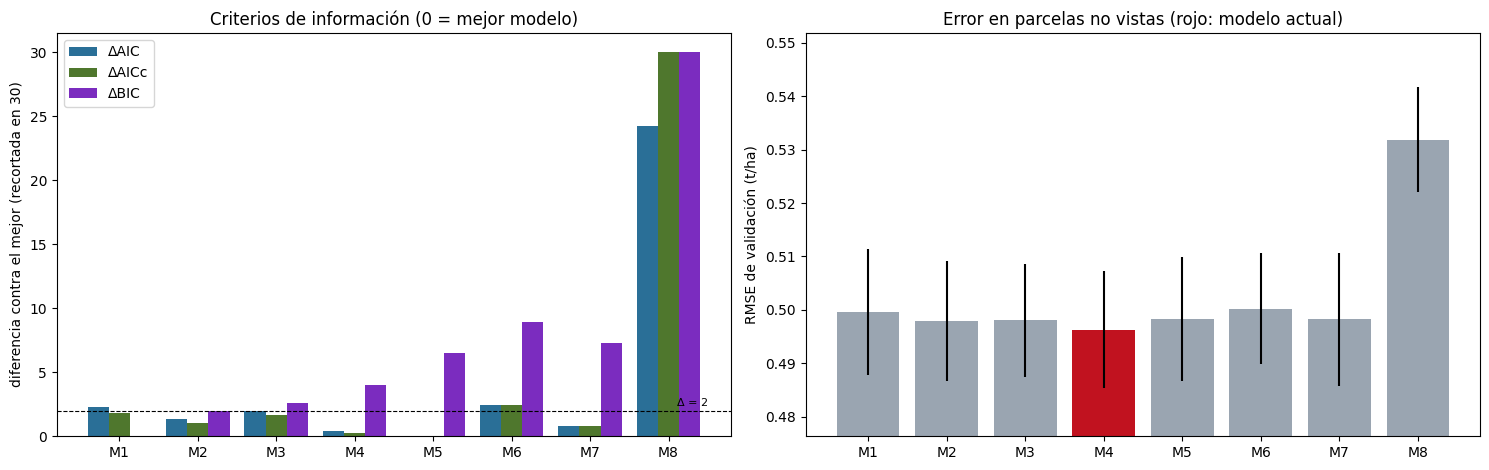


Modelos: M1 · Vecinas · M2 · Vecinas + lluvia · M3 · Vecinas + amplitud · M4 · Vecinas + lluvia + amplitud (modelo actual) · M5 · M4 + amplitud² · M6 · M4 + lluvia² · M7 · M4 + lluvia × amplitud · M8 · Vecinas + 24 variables núcleo


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [75]:
# Paso 18 · AIC, AICc y BIC de regresiones MCO candidatas + RMSE de validación; y prueba de términos no lineales
# dentro del ensamble. Solo se adoptaría un término si baja el RMSE más que el umbral (0.002 t/ha).
import numpy as np, pandas as pd, matplotlib.pyplot as plt, zipfile
from pathlib import Path
from scipy.spatial.distance import cdist
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

# ------------------------------------------------------------------ preparación
BASE = Path.cwd()
if "OUT" not in globals() or not (Path(OUT) / "base_maestra_v3.csv").exists():
    hits = sorted(BASE.rglob("base_maestra_v3.csv"))
    assert hits, "No encuentro base_maestra_v3.csv: corre antes el notebook de los Integrantes 1 y 2 o sube su zip de resultados."
    OUT = hits[0].parent
OUT = Path(OUT)
RES = Path(globals().get("RES", BASE / "resultados_I3")); RES.mkdir(exist_ok=True)
FIG18 = RES / "figs" / "paso18_criterios"; FIG18.mkdir(parents=True, exist_ok=True)
REPS = int(globals().get("REPETICIONES", 10))

def idw(XY_dest, XY_or, y_or, k=12, excluir=None):
    D = cdist(XY_dest, XY_or)
    if excluir is not None: D = np.where(excluir, np.inf, D)
    idx = np.argsort(D, 1)[:, :k]
    w = 1 / np.maximum(np.take_along_axis(D, idx, 1), .05)
    return (w * y_or[idx]).sum(1) / w.sum(1)

P, A = "clim_prec_vegetativa_2025", "clim_amplitud_vegetativa_2025"
b18 = pd.read_csv(OUT / "base_maestra_v3.csv").merge(pd.read_csv(OUT / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km"]], on="ID_POLIGONO")
tr18 = b18[b18.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True).copy()
NUC = [v for v in pd.read_csv(OUT / "variables_nucleo.csv").variable if v in tr18.columns]
extra = pd.DataFrame({"amplitud2": tr18[A] ** 2, "lluvia_x_amplitud": tr18[P] * tr18[A], "lluvia2": tr18[P] ** 2})
tr18 = pd.concat([tr18, extra], axis=1)
XY18, y18, n18 = tr18[["x_km", "y_km"]].values.astype(float), tr18.y.values.astype(float), len(tr18)
tr18["vecinas"] = idw(XY18, XY18, y18, excluir=np.eye(n18, dtype=bool))          # para el MCO (sin la propia parcela)
EST18 = tr18.Municipio.where(tr18.Municipio.map(tr18.Municipio.value_counts()) >= 5, "Otros")
print(f"Datos: {n18} parcelas de entrenamiento · validación {REPS} repeticiones × 5 folds")

# ------------------------------------------------------------------ 1. criterios de información + validación cruzada
CANDIDATOS = {
    "M1 · Vecinas": [],
    "M2 · Vecinas + lluvia": [P],
    "M3 · Vecinas + amplitud": [A],
    "M4 · Vecinas + lluvia + amplitud (modelo actual)": [P, A],
    "M5 · M4 + amplitud²": [P, A, "amplitud2"],
    "M6 · M4 + lluvia²": [P, A, "lluvia2"],
    "M7 · M4 + lluvia × amplitud": [P, A, "lluvia_x_amplitud"],
    f"M8 · Vecinas + {len(NUC)} variables núcleo": NUC,
}

def rmse_cv_ridge(cols):
    """RMSE de validación de Ridge con [vecinas dentro del fold] + cols."""
    errs, por_rep = [], []
    for s in range(REPS):
        e = np.zeros(n18)
        for a, b in StratifiedKFold(5, shuffle=True, random_state=s).split(tr18, EST18):
            va = idw(XY18[a], XY18[a], y18[a], excluir=np.eye(len(a), dtype=bool)); vb = idw(XY18[b], XY18[a], y18[a])
            if cols:
                m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
                m.fit(np.c_[va, tr18.loc[a, cols].values.astype(float)], y18[a])
                e[b] = y18[b] - m.predict(np.c_[vb, tr18.loc[b, cols].values.astype(float)])
            else:
                e[b] = y18[b] - vb
        errs.append(e); por_rep.append(np.sqrt((e ** 2).mean()))
    e = np.concatenate(errs)
    return np.sqrt((e ** 2).mean()), np.std(por_rep)

filas = []
for nombre, cols in CANDIDATOS.items():
    X = sm.add_constant(tr18[["vecinas"] + cols].astype(float).fillna(tr18[["vecinas"] + cols].median()))
    ols = sm.OLS(y18, X).fit()
    k = X.shape[1] + 1                                       # coeficientes + varianza del error
    # AICc: con n = 138 y pocos parámetros la corrección es pequeña pero conviene reportarla.
    aicc = ols.aic + 2 * k * (k + 1) / (n18 - k - 1)         # AIC corregido para muestras chicas
    rm, sd = rmse_cv_ridge(cols)
    filas.append({"modelo": nombre, "parametros": X.shape[1], "AIC": ols.aic, "AICc": aicc, "BIC": ols.bic,
                  "R2_ajustado": ols.rsquared_adj, "RMSE_validacion": rm, "RMSE_sd": sd})
crit = pd.DataFrame(filas)
for c in ["AIC", "AICc", "BIC"]:
    crit[f"Δ{c}"] = crit[c] - crit[c].min()                  # diferencia contra el mejor (Δ < 2: equivalentes)
crit["ΔRMSE"] = crit.RMSE_validacion - crit.RMSE_validacion.min()
crit = crit.round(4)
crit.to_csv(RES / "criterios_informacion.csv", index=False)
print("\nCRITERIOS DE INFORMACIÓN (MCO, menor es mejor) Y ERROR DE VALIDACIÓN (Ridge)")
print(crit[["modelo", "parametros", "AIC", "AICc", "BIC", "R2_ajustado", "RMSE_validacion", "ΔAIC", "ΔAICc", "ΔBIC"]].to_string(index=False))
for c in ["AIC", "AICc", "BIC", "RMSE_validacion"]:
    print(f"  Mejor según {c:<16}: {crit.loc[crit[c].idxmin(), 'modelo']}")
print("  Regla (Burnham y Anderson): Δ < 2 → modelos equivalentes; 4-7 → menos apoyo; > 10 → sin apoyo.")

# ------------------------------------------------------------------ 2. ¿el término no lineal mejora el ensamble?
def ensamble_cv(cols_ridge):
    """RMSE del ensamble (Ridge[vecinas + cols] + municipio + proceso gaussiano, pesos 1/3) con la validación del equipo."""
    errs, por_rep = [], []
    for s in range(REPS):
        e = np.zeros(n18)
        for a, b in StratifiedKFold(5, shuffle=True, random_state=s).split(tr18, EST18):
            va = idw(XY18[a], XY18[a], y18[a], excluir=np.eye(len(a), dtype=bool)); vb = idw(XY18[b], XY18[a], y18[a])
            rid = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
            rid.fit(np.c_[va, tr18.loc[a, cols_ridge].values.astype(float)], y18[a])
            p1 = rid.predict(np.c_[vb, tr18.loc[b, cols_ridge].values.astype(float)])
            p2 = tr18.loc[b, "Municipio"].map(tr18.loc[a].groupby("Municipio").y.mean()).fillna(y18[a].mean()).values
            gp = GaussianProcessRegressor(ConstantKernel(0.5) * RBF(3.0, (0.1, 50)) + WhiteKernel(0.2), normalize_y=True,
                                          random_state=0).fit(XY18[a], y18[a])
            e[b] = y18[b] - (p1 + p2 + gp.predict(XY18[b])) / 3
        errs.append(e); por_rep.append(np.sqrt((e ** 2).mean()))
    e = np.concatenate(errs)
    return {"RMSE": np.sqrt((e ** 2).mean()), "RMSE_sd": np.std(por_rep), "MAE": np.abs(e).mean(), "R2": 1 - (e ** 2).mean() / y18.var()}

print("\n¿MEJORA EL ENSAMBLE CON UN TÉRMINO NO LINEAL? (≈1-2 min)")
ens = pd.DataFrame([{"ensamble": n, **ensamble_cv(c)} for n, c in {
    "Actual: Ridge(vecinas + lluvia + amplitud)": [P, A],
    "Con amplitud²": [P, A, "amplitud2"],
    "Con lluvia × amplitud": [P, A, "lluvia_x_amplitud"]}.items()]).round(4)
print(ens.to_string(index=False))
ens.to_csv(RES / "ensamble_no_lineal.csv", index=False)
base_rmse, ruido = ens.RMSE.iloc[0], ens.RMSE_sd.iloc[0]
mejor = ens.iloc[ens.RMSE.idxmin()]
mejora = base_rmse - mejor.RMSE
# Umbral fijado antes de ver el resultado para no adoptar mejoras que son puro ruido.
UMBRAL = 0.002   # t/ha: mejoras menores que esto están dentro del ruido de la validación
if mejor.ensamble.startswith("Actual") or mejora < UMBRAL:
    print(f"\nDECISIÓN: se queda el modelo actual. La mejor alternativa baja el RMSE solo {mejora:.4f} t/ha "
          f"(< {UMBRAL}), dentro del ruido (desv. entre repeticiones {ruido:.4f}). Agregar parámetros sin mejora real no se justifica.")
else:
    print(f"\nDECISIÓN: '{mejor.ensamble}' baja el RMSE {mejora:.4f} t/ha (≥ {UMBRAL}). Vale la pena incorporarlo al modelo final "
          f"(avisar al equipo: cambia predicciones.csv y factores.csv).")

# ------------------------------------------------------------------ gráficas
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
etiquetas = crit.modelo.str.split(" · ").str[0]
x = np.arange(len(crit)); w = .27
for i, (c, col) in enumerate([("ΔAIC", "#2a6f97"), ("ΔAICc", "#4f772d"), ("ΔBIC", "#7b2cbf")]):
    ax[0].bar(x + (i - 1) * w, crit[c].clip(upper=30), w, label=c, color=col)
ax[0].axhline(2, ls="--", c="k", lw=.8); ax[0].text(len(crit) - .5, 2.4, "Δ = 2", ha="right", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels(etiquetas); ax[0].set_ylabel("diferencia contra el mejor (recortada en 30)")
ax[0].set_title("Criterios de información (0 = mejor modelo)"); ax[0].legend()
ax[1].bar(x, crit.RMSE_validacion, yerr=crit.RMSE_sd, color=np.where(crit.modelo.str.contains("actual"), "#c1121f", "#9aa5b1"))
ax[1].set_xticks(x); ax[1].set_xticklabels(etiquetas); ax[1].set_ylim(crit.RMSE_validacion.min() - .02, crit.RMSE_validacion.max() + .02)
ax[1].set_ylabel("RMSE de validación (t/ha)"); ax[1].set_title("Error en parcelas no vistas (rojo: modelo actual)")
fig.tight_layout(); fig.savefig(FIG18 / "18_criterios_y_validacion.png", dpi=150); plt.show()
print("\nModelos: " + " · ".join(crit.modelo))

# ------------------------------------------------------------------ volver a empaquetar
zip_res = BASE / "resultados_I3.zip"
with zipfile.ZipFile(zip_res, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in RES.rglob("*"):
        if f.is_file(): zf.write(f, f.relative_to(RES.parent))
try:
    from google.colab import files; files.download(str(zip_res))
except ImportError:
    print("Zip actualizado:", zip_res)

## Paso 19 · Predicción final y control de calidad

1. Reentrena el ensamble final DESDE CERO (sin depender de los pasos anteriores) y predice las 59.
2. Compara contra predicciones.csv del paso E (si existe): deben coincidir → reproducibilidad.
3. Validación cruzada 5 × 10 para los errores (RMSE esperado e intervalos por parcela).
4. Calibración: ¿las predicciones están sesgadas o "aplanadas"? (regresión de y sobre ŷ fuera de fold)
5. Estabilidad: bootstrap del entrenamiento, sensibilidad a k vecinas y a la semilla del proceso gaussiano.
6. Coherencia de cada predicción contra sus vecinas, su municipio y las banderas de calidad.
7. Rango esperado de la calificación (RMSE, MAE, R²) en 59 parcelas nuevas.

### Explicación

Este es el paso que produce el archivo que se sube a la plataforma.

**Qué información usa cada predicción.** Para cada una de las 59 parcelas el modelo usa sus coordenadas, su municipio y su lluvia y amplitud térmica de la etapa vegetativa de 2025, junto con el rendimiento de las 138 parcelas de entrenamiento (para las vecinas, el promedio municipal y el GP). **Nunca** usa un rendimiento de las 59 (no existe) y el primer control lo verifica.

**Procedimiento.**
1. **Controles de entrada:** 197 parcelas, 138 con rendimiento, 59 sin rendimiento, que las 59 coincidan con la lista oficial del reto, clima y coordenadas completos, y municipios de las 59 presentes en el entrenamiento.
2. **Modelo final reentrenado desde cero** con una implementación independiente (`ajustar19`/`predecir19`), idéntica en método a `modelo_cebada360.py`.
3. **Reproducibilidad:** compara contra `predicciones.csv` del paso E y comprueba que dos entrenamientos seguidos den exactamente lo mismo.
4. **Validación cruzada 10 × 5** para obtener los errores y comprobar que el RMSE sea el reportado (0.494 ± 0.002).
5. **Calibración:** regresión del rendimiento observado sobre la predicción fuera de fold. Una pendiente compatible con 1 y sesgo ≈ 0 indican que las predicciones no están sistemáticamente "aplanadas" ni corridas.
6. **Estabilidad:** 200 remuestreos bootstrap del entrenamiento (con ID únicos para que una parcela duplicada no se excluya a sí misma), sensibilidad a *k* = 8 y 16 y a la semilla del GP.
7. **Coherencia parcela por parcela** contra sus vecinas, su municipio y sus banderas de calidad; las que no cumplen se anotan para revisión manual (**no se cambian a mano**).
8. **Calificación esperada:** 10 000 remuestreos de 59 parcelas con los errores de validación para ver el rango plausible del RMSE, MAE y R² que podría obtener el jurado.
9. **Archivo de entrega** releído como texto: 59 filas, ID `AGC_###` ordenados e iguales a la lista oficial, 4 decimales exactos, sin vacíos ni negativos, dentro de un rango plausible. Se guarda su huella **SHA-256**, que garantiza que nadie modificó el archivo después.

**Resultados de la corrida de referencia.** 59 predicciones con media 3.9372 t/ha (de 2.8297 a 4.6928). Controles 24 de 25 OK y un aviso (AGC_120, en Nanacamilpa, municipio con muy pocas parcelas con dato; es la predicción menos confiable). Calificación esperada en 59 parcelas: RMSE entre 0.369 y 0.620 (percentiles 5 y 95), mediana 0.483. SHA-256 `21955b71…`.

**Limitaciones.** El RMSE real dependerá de las 59 parcelas concretas: unas pocas con siniestro pueden moverlo mucho. Los intervalos son orientativos y no son una garantía de rendimiento.

Datos: /content/outputs
Resultados: /content/resultados_I3
Entrega: /content/resultados_I3/ENTREGA

CONTROLES DE ENTRADA
  [OK   ] 197 parcelas, sin IDs repetidos · 197 filas
  [OK   ] 138 de entrenamiento con rendimiento · 138 parcelas
  [OK   ] 59 de predicción SIN rendimiento (no hay fuga) · 59 parcelas
  [OK   ] Las 59 coinciden con la lista oficial (archivo oficial ID_area_rendimiento_70_30_Reto_AgroCebada.csv) · faltan 0 · sobran 0
  [OK   ] Coordenadas y clima completos en las 197
  [OK   ] Municipios de las 59 existen en entrenamiento · todos

1 · MODELO FINAL (entrenado con las 138)
  Ridge: alfa = 1.17 · coeficientes (estandarizados) = [ 0.6198 -0.078  -0.1031]
  Proceso gaussiano: 0.727**2 * RBF(length_scale=9.81) + WhiteKernel(noise_level=0.339)
  59 predicciones: media 3.9372 · mín 2.8297 · máx 4.6928 t/ha

2 · REPRODUCIBILIDAD
  [OK   ] Coincide con predicciones.csv del paso E · diferencia máxima 0.000000 t/ha
  [OK   ] Dos entrenamientos seguidos dan exactamente lo mismo

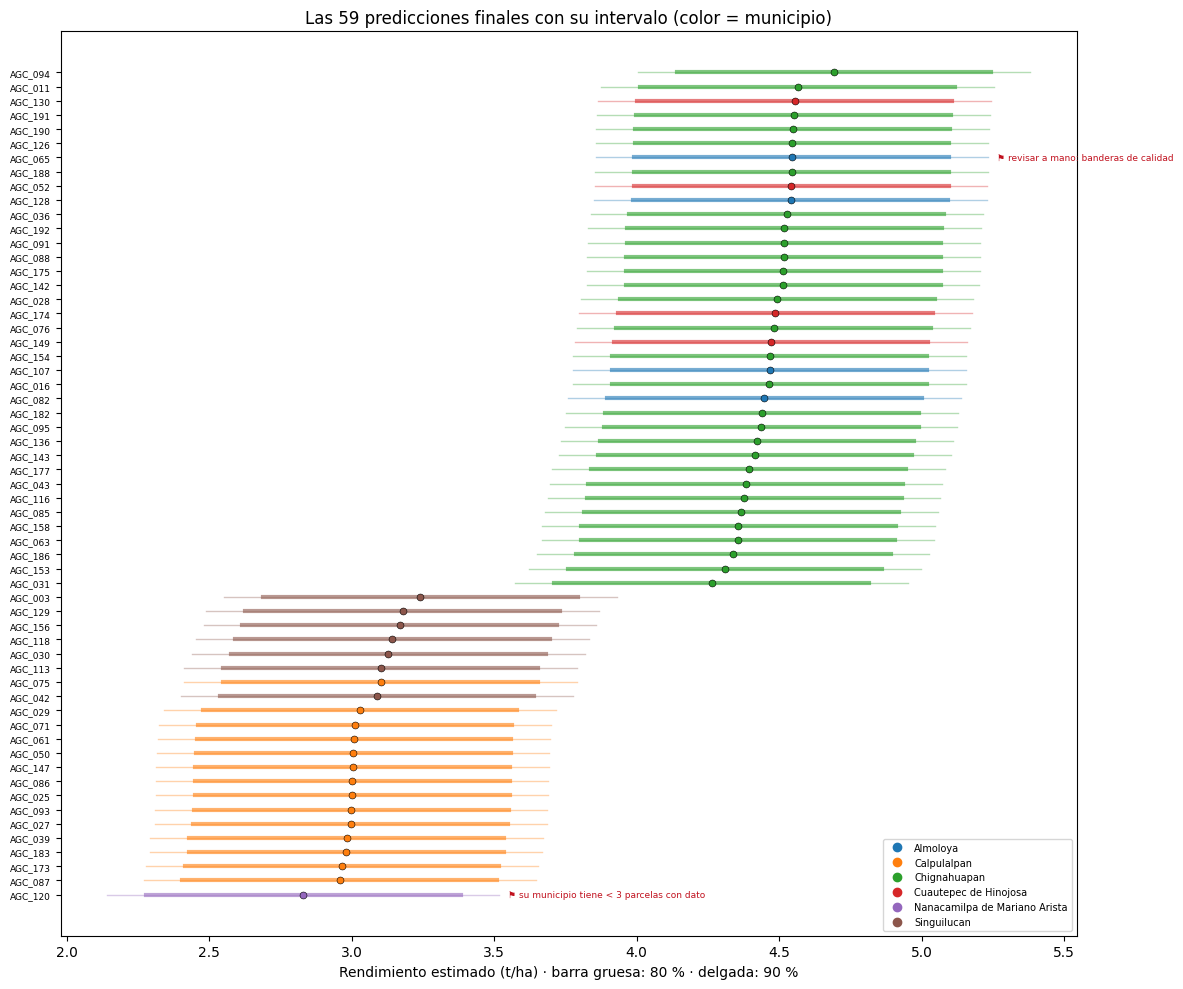

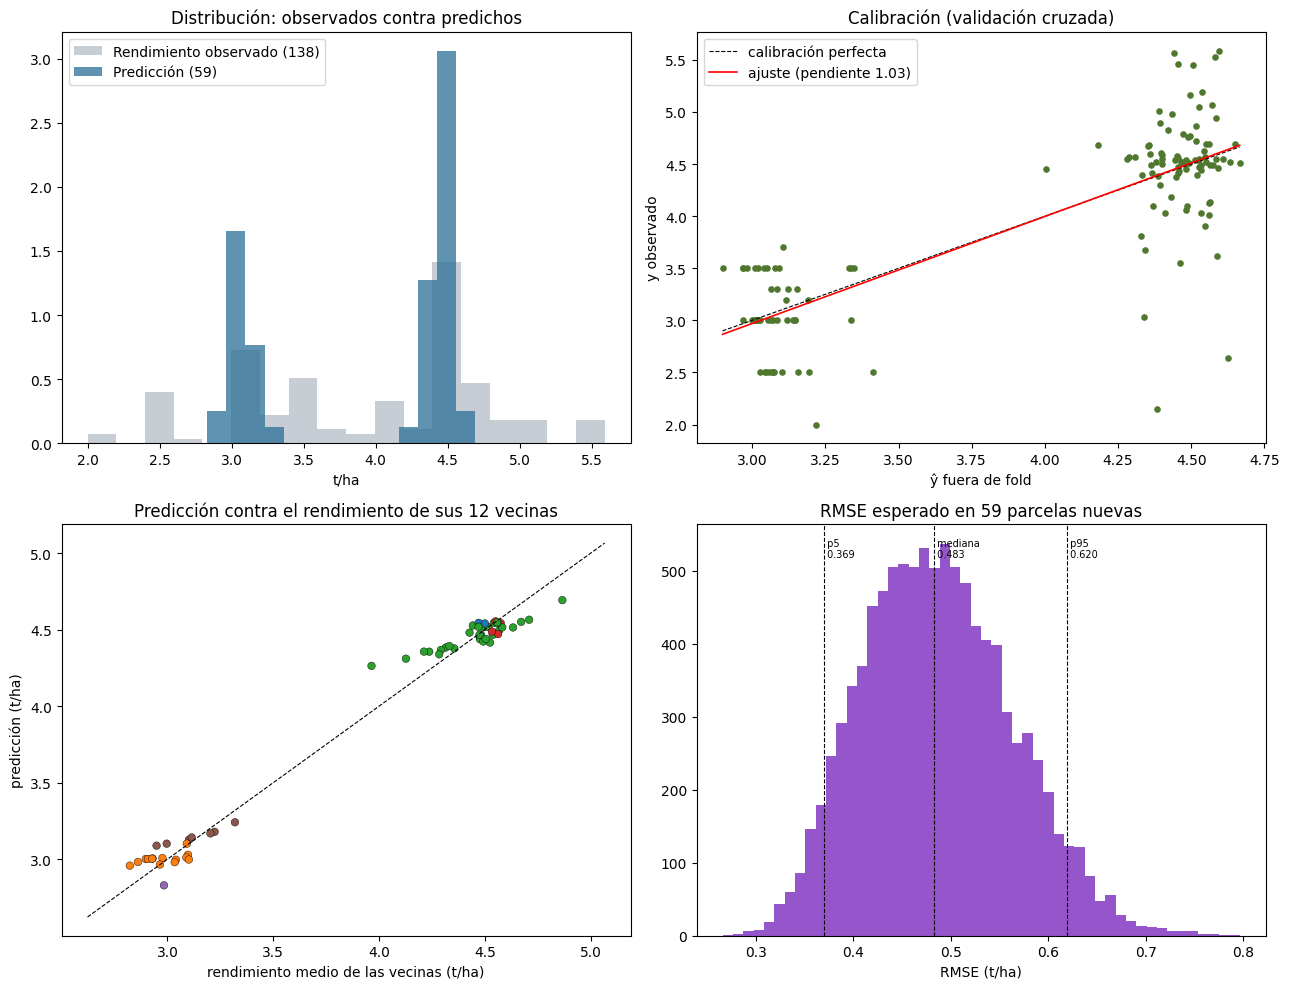

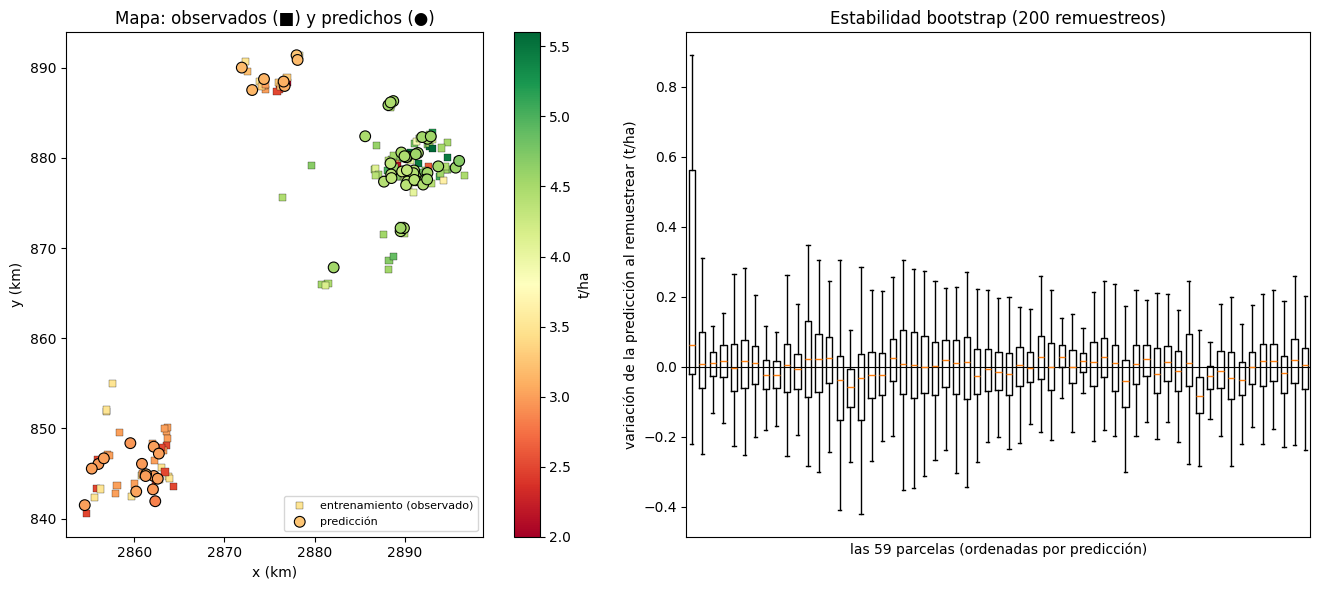


CEBADA360 · PREDICCIÓN FINAL (paso 19) · 2026-10-20 04:44
Modelo: ensamble con pesos 1/3 de (1) Ridge [rendimiento de 12 vecinas IDW + lluvia y amplitud térmica del crecimiento],
        (2) promedio del municipio, (3) proceso gaussiano sobre coordenadas. Entrenado con 138 parcelas.
Validación cruzada 10×5 estratificada por municipio: RMSE 0.4940 ± 0.0062 · MAE 0.3381 · R² 0.6607
Calibración: y = -0.112 + 1.027·ŷ (IC 95 % pendiente [0.903, 1.151]); sesgo -0.0040 t/ha
Estabilidad: desviación bootstrap de cada predicción, mediana 0.097 t/ha (máx 0.316)
59 predicciones: media 3.9372 · mín 2.8297 · máx 4.6928 t/ha
Intervalos empíricos: ±0.552 t/ha (80 %) · ±0.689 t/ha (90 %)
Calificación esperada en 59 parcelas (p5 – mediana – p95): RMSE 0.369 – 0.483 – 0.620 ·
  MAE 0.265 – 0.335 – 0.419 · R² 0.490 – 0.667 – 0.788
Predicción media por municipio: Almoloya 4.50; Calpulalpan 3.00; Chignahuapan 4.46; Cuautepec de Hinojosa 4.51; Nanacamilpa de Mariano Arista 2.83; Singuilucan 3.15
Parcelas pa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
# Paso 19 · Predicción final de las 59 y control de calidad: reentrena desde cero, verifica reproducibilidad,
# calibración y estabilidad, revisa cada predicción, simula la calificación esperada y escribe el archivo de entrega
# en resultados_I3/ENTREGA/ con su huella SHA-256. Si un control crítico falla, se detiene y NO hay que entregar.
import numpy as np, pandas as pd, matplotlib.pyplot as plt, zipfile, hashlib, re, time, warnings
from pathlib import Path
from scipy import stats
from scipy.spatial.distance import cdist
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ configuración (no cambiar salvo prisa)
REPS_19 = 10        # repeticiones de la validación 5-fold (10 = lo del equipo)
BOOT_19 = 200       # remuestreos bootstrap para la estabilidad (200 ≈ 1 min)
SEMILLA_19 = 2026
K_19 = 12           # vecinas del modelo final (decidido en el paso A; NO se ajusta aquí)
VARS_19 = ["clim_prec_vegetativa_2025", "clim_amplitud_vegetativa_2025"]
T0_19 = time.time()

# ------------------------------------------------------------------ rutas
BASE = Path.cwd()
if "OUT" not in globals() or not (Path(OUT) / "base_maestra_v3.csv").exists():
    _hits = sorted(BASE.rglob("base_maestra_v3.csv"))
    assert _hits, "No encuentro base_maestra_v3.csv: corre antes el notebook de los Integrantes 1 y 2 o sube su zip de resultados."
    OUT = _hits[0].parent
OUT = Path(OUT)
RES = Path(globals().get("RES", BASE / "resultados_I3")); RES.mkdir(exist_ok=True)
ENT = RES / "ENTREGA"; ENT.mkdir(exist_ok=True)
FIG19 = RES / "figs" / "paso19_prediccion_final"; FIG19.mkdir(parents=True, exist_ok=True)
print(f"Datos: {OUT}\nResultados: {RES}\nEntrega: {ENT}\n")


# ------------------------------------------------------------------ el modelo final (idéntico a modelo_cebada360.py)
def idw19(XY_dest, XY_or, y_or, k=K_19, excluir=None):
    D = cdist(XY_dest, XY_or)
    if excluir is not None:
        D = np.where(excluir, np.inf, D)
    idx = np.argsort(D, 1)[:, :k]
    w = 1 / np.maximum(np.take_along_axis(D, idx, 1), .05)
    return (w * y_or[idx]).sum(1) / w.sum(1)


def ajustar19(tr, k=K_19, semilla_gp=0):
    """Ensamble con pesos 1/3: Ridge[vecinas + lluvia + amplitud] + promedio del municipio + proceso gaussiano."""
    ids = np.asarray(tr.ID_POLIGONO, dtype=str)
    XY = np.asarray(tr[["x_km", "y_km"]], dtype=float); y = np.asarray(tr.y, dtype=float)
    v = idw19(XY, XY, y, k, excluir=ids[:, None] == ids[None, :])
    rid = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
    rid.fit(np.c_[v, np.asarray(tr[VARS_19], dtype=float)], y)
    gp = GaussianProcessRegressor(ConstantKernel(0.5) * RBF(3.0, (0.1, 50)) + WhiteKernel(0.2), normalize_y=True,
                                  random_state=semilla_gp).fit(XY, y)
    return {"ids": ids, "XY": XY, "y": y, "k": k, "rid": rid, "gp": gp, "mun": tr.groupby("Municipio").y.mean().to_dict(),
            "media": float(y.mean())}


def predecir19(m, df, componentes=False):
    XY = np.asarray(df[["x_km", "y_km"]], dtype=float)
    ids = np.asarray(df.ID_POLIGONO, dtype=str)
    v = idw19(XY, m["XY"], m["y"], m["k"], excluir=ids[:, None] == m["ids"][None, :])    # nunca su propio dato
    p1 = m["rid"].predict(np.c_[v, np.asarray(df[VARS_19], dtype=float)])
    p2 = np.asarray(df.Municipio.map(m["mun"]).fillna(m["media"]), dtype=float)
    p3 = m["gp"].predict(XY)
    ens = (p1 + p2 + p3) / 3
    return (ens, pd.DataFrame({"vecinas": v, "ridge": p1, "municipio": p2, "espacial": p3})) if componentes else ens


# ------------------------------------------------------------------ datos y controles de entrada
bm19 = pd.read_csv(OUT / "base_maestra_v3.csv")
co19 = pd.read_csv(OUT / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km", "lon", "lat"]]
b19 = bm19.merge(co19, on="ID_POLIGONO", how="left")
tr19 = b19[b19.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
pr19 = b19[b19.CONJUNTO == "PREDICCION"].reset_index(drop=True)

# Lista oficial de las 59: del archivo original del reto si está en la sesión; si no, de la tabla limpia del paso 1
_ofi = sorted(BASE.rglob("*ID_area_rendimiento_70_30_Reto_AgroCebada*.csv"))
if _ofi:
    _o = pd.read_csv(_ofi[0], encoding="utf-8-sig")
    _o.columns = [c.strip() for c in _o.columns]
    _idc = next(c for c in _o.columns if c.upper().startswith("ID_POLIGON"))
    _cc = next(c for c in _o.columns if c.upper().startswith("CONJUNTO"))
    IDS_OFICIALES = set(_o.loc[_o[_cc].astype(str).str.upper().str.startswith("PRED"), _idc].astype(str))
    FUENTE_IDS = f"archivo oficial {_ofi[0].name}"
else:
    _t = pd.read_csv(OUT / "tabla_principal_limpia.csv")
    IDS_OFICIALES = set(_t.loc[_t.CONJUNTO == "PREDICCION", "ID_POLIGONO"].astype(str))
    FUENTE_IDS = "tabla_principal_limpia.csv (Integrante 1)"

controles = []
def control(nombre, ok, detalle="", critico=True):
    controles.append({"control": nombre, "resultado": "OK" if ok else ("FALLA" if critico else "AVISO"), "detalle": detalle,
                      "critico": critico})
    print(f"  [{'OK   ' if ok else ('FALLA' if critico else 'AVISO')}] {nombre}" + (f" · {detalle}" if detalle else ""))

print("CONTROLES DE ENTRADA")
control("197 parcelas, sin IDs repetidos", len(b19) == 197 and b19.ID_POLIGONO.is_unique, f"{len(b19)} filas")
control("138 de entrenamiento con rendimiento", len(tr19) == 138 and tr19.y.notna().all(), f"{len(tr19)} parcelas")
# Control clave: las 59 no deben traer rendimiento; si lo trajeran habría fuga de información.
control("59 de predicción SIN rendimiento (no hay fuga)", len(pr19) == 59 and pr19.y.isna().all(), f"{len(pr19)} parcelas")
control(f"Las 59 coinciden con la lista oficial ({FUENTE_IDS})", set(pr19.ID_POLIGONO.astype(str)) == IDS_OFICIALES,
        f"faltan {len(IDS_OFICIALES - set(pr19.ID_POLIGONO))} · sobran {len(set(pr19.ID_POLIGONO) - IDS_OFICIALES)}")
control("Coordenadas y clima completos en las 197", b19[["x_km", "y_km"] + VARS_19].notna().all().all())
control("Municipios de las 59 existen en entrenamiento", pr19.Municipio.isin(tr19.Municipio).all(),
        ", ".join(sorted(set(pr19.Municipio) - set(tr19.Municipio))) or "todos")

# ------------------------------------------------------------------ 1. modelo final y predicción de las 59
print("\n1 · MODELO FINAL (entrenado con las 138)")
# Modelo final entrenado con las 138 parcelas; mismo método que modelo_cebada360.py.
m19 = ajustar19(tr19)
pred59, comp59 = predecir19(m19, pr19, componentes=True)
pred59_4 = np.round(pred59, 4)
alfa_ridge = m19["rid"].named_steps["ridgecv"].alpha_
print(f"  Ridge: alfa = {alfa_ridge:.3g} · coeficientes (estandarizados) = {np.round(m19['rid'].named_steps['ridgecv'].coef_, 4)}")
print(f"  Proceso gaussiano: {m19['gp'].kernel_}")
print(f"  59 predicciones: media {pred59.mean():.4f} · mín {pred59.min():.4f} · máx {pred59.max():.4f} t/ha")

# ------------------------------------------------------------------ 2. reproducibilidad contra el paso E
print("\n2 · REPRODUCIBILIDAD")
_pe = RES / "predicciones.csv"
_pe_ok = _pe.exists() and set(pr19.ID_POLIGONO).issubset(set(pd.read_csv(_pe).ID_POLIGONO))   # el del paso 17 solo trae las 138
if _pe_ok:
    _p = pd.read_csv(_pe).set_index("ID_POLIGONO")
    _dif = np.abs(_p.loc[pr19.ID_POLIGONO, "y_pred"].values - pred59_4).max()
    control("Coincide con predicciones.csv del paso E", _dif < 5e-4, f"diferencia máxima {_dif:.6f} t/ha")
else:
    control("Coincide con predicciones.csv del paso E", True, "no existe (paso E no corrido); se usa esta predicción", critico=False)
_m2 = ajustar19(tr19)
control("Dos entrenamientos seguidos dan exactamente lo mismo", np.allclose(predecir19(_m2, pr19), pred59, atol=1e-10))

# ------------------------------------------------------------------ 3. validación cruzada (errores fuera de fold)
print(f"\n3 · VALIDACIÓN CRUZADA ({REPS_19} × 5 folds, estratificada por municipio)")
y19 = tr19.y.values
EST19 = tr19.Municipio.where(tr19.Municipio.map(tr19.Municipio.value_counts()) >= 5, "Otros")
OOF = np.zeros((REPS_19, len(tr19)))
for s in range(REPS_19):
    for a, b in StratifiedKFold(5, shuffle=True, random_state=s).split(tr19, EST19):
        OOF[s, b] = predecir19(ajustar19(tr19.iloc[a].reset_index(drop=True)), tr19.iloc[b].reset_index(drop=True))
E = y19[None, :] - OOF
rmse_rep = np.sqrt((E ** 2).mean(1))
RMSE_CV, MAE_CV = float(np.sqrt((E ** 2).mean())), float(np.abs(E).mean())
R2_CV = float(1 - (E ** 2).mean() / y19.var())
print(f"  RMSE {RMSE_CV:.4f} ± {rmse_rep.std():.4f} · MAE {MAE_CV:.4f} · R² {R2_CV:.4f}")
control("RMSE de validación igual al reportado (0.494 ± 0.002)", abs(RMSE_CV - 0.494) < 0.002, f"{RMSE_CV:.4f}")

# ------------------------------------------------------------------ 4. calibración
print("\n4 · CALIBRACIÓN (regresión de y observado sobre ŷ fuera de fold)")
oof_media = OOF.mean(0)
# Calibración: y = a + b·ŷ. Pendiente ≈ 1 y sesgo ≈ 0 indican predicciones sin distorsión sistemática.
_lr = stats.linregress(oof_media, y19)
_tcrit = stats.t.ppf(.975, len(y19) - 2)
ic_pend = (_lr.slope - _tcrit * _lr.stderr, _lr.slope + _tcrit * _lr.stderr)
sesgo = float((y19 - oof_media).mean())
print(f"  y = {_lr.intercept:.3f} + {_lr.slope:.3f}·ŷ · IC 95 % de la pendiente [{ic_pend[0]:.3f}, {ic_pend[1]:.3f}] · sesgo medio {sesgo:+.4f}")
control("Pendiente de calibración compatible con 1 (no hace falta recalibrar)", ic_pend[0] <= 1 <= ic_pend[1],
        f"IC [{ic_pend[0]:.3f}, {ic_pend[1]:.3f}]", critico=False)
control("Sin sesgo sistemático (|sesgo| < 0.05 t/ha)", abs(sesgo) < .05, f"{sesgo:+.4f}")

# ------------------------------------------------------------------ 5. estabilidad
print(f"\n5 · ESTABILIDAD")
rng = np.random.default_rng(SEMILLA_19)
BOOT = np.zeros((BOOT_19, 59))
for i in range(BOOT_19):
    idx = rng.choice(len(tr19), len(tr19), replace=True)
    trb = tr19.iloc[idx].reset_index(drop=True)
    # Bootstrap: IDs únicos para que una parcela repetida sí cuente como vecina de su copia.
    trb["ID_POLIGONO"] = [f"B{j}" for j in range(len(trb))]       # IDs únicos: el duplicado no se excluye a sí mismo
    BOOT[i] = predecir19(ajustar19(trb), pr19)
sd_boot = BOOT.std(0)
print(f"  Bootstrap ({BOOT_19}): desviación de la predicción por parcela · mediana {np.median(sd_boot):.3f} · máx {sd_boot.max():.3f} t/ha")
print(f"  (la incertidumbre del MODELO es chica frente al error típico {RMSE_CV:.3f}: lo que domina es el ruido de cada parcela)")
_inest = pr19.ID_POLIGONO[sd_boot >= .25].tolist()
control("Predicciones estables al remuestrear (desv. bootstrap < 0.25 t/ha)", not _inest,
        f"máx {sd_boot.max():.3f}" + (f" · menos estables: {', '.join(_inest)} (su municipio tiene muy pocas parcelas con dato)" if _inest else ""),
        critico=False)
control("Estabilidad global: desv. bootstrap mediana < 0.15 t/ha", np.median(sd_boot) < .15, f"mediana {np.median(sd_boot):.3f}")
_k8, _k16 = predecir19(ajustar19(tr19, k=8), pr19), predecir19(ajustar19(tr19, k=16), pr19)
print(f"  Sensibilidad a k vecinas: |ŷ(k=8) − ŷ(k=12)| máx {np.abs(_k8 - pred59).max():.3f} · |ŷ(k=16) − ŷ(k=12)| máx {np.abs(_k16 - pred59).max():.3f} t/ha")
control("Predicciones poco sensibles a k (cambio máx < 0.3 t/ha)", max(np.abs(_k8 - pred59).max(), np.abs(_k16 - pred59).max()) < .3,
        critico=False)
_gp7 = predecir19(ajustar19(tr19, semilla_gp=7), pr19)
control("Independiente de la semilla del proceso gaussiano", np.abs(_gp7 - pred59).max() < 1e-3, f"máx {np.abs(_gp7 - pred59).max():.2e}")

# ------------------------------------------------------------------ 6. coherencia parcela por parcela
print("\n6 · COHERENCIA DE CADA PREDICCIÓN")
q = {lv: float(np.quantile(np.abs(E), lv)) for lv in (.8, .9)}
det = pr19[["ID_POLIGONO", "Municipio", "lon", "lat"]].copy()
det["rendimiento_t_ha"] = pred59_4
det["y_lo80"], det["y_hi80"] = pred59 - q[.8], pred59 + q[.8]
det["y_lo90"], det["y_hi90"] = pred59 - q[.9], pred59 + q[.9]
det["sd_bootstrap"] = sd_boot
det["rend_vecinas_k12"] = comp59.vecinas.values
det["rend_medio_municipio"] = comp59.municipio.values
det["comp_ridge"], det["comp_municipio"], det["comp_espacial"] = comp59.ridge.values, comp59.municipio.values, comp59.espacial.values
det["dist_media_vecinas_km"] = np.sort(cdist(pr19[["x_km", "y_km"]].values, m19["XY"]), 1)[:, :K_19].mean(1)
_bq = OUT / "banderas_calidad.csv"
if _bq.exists():
    det = det.merge(pd.read_csv(_bq)[["ID_POLIGONO", "bq_total", "bq_revisar"]], on="ID_POLIGONO", how="left")
else:
    det["bq_total"], det["bq_revisar"] = 0, "sin dato"
det["dif_vs_vecinas"] = det.rendimiento_t_ha - det.rend_vecinas_k12
det["dispersion_componentes"] = det[["comp_ridge", "comp_municipio", "comp_espacial"]].std(1)
lim_lo, lim_hi = y19.min() - .5, y19.max() + .5
det["n_entrenamiento_municipio"] = det.Municipio.map(tr19.Municipio.value_counts()).fillna(0).astype(int)
det["nota"] = np.select(
    [det.bq_revisar.eq("revisar"), det.n_entrenamiento_municipio < 3, det.sd_bootstrap >= .25, det.dif_vs_vecinas.abs() > .75,
     det.dispersion_componentes > .5, det.dist_media_vecinas_km > 5],
    ["revisar a mano: banderas de calidad", "su municipio tiene < 3 parcelas con dato", "predicción poco estable",
     "predicción lejos de sus vecinas", "los 3 componentes discrepan", "lejos de parcelas con dato"], "ok")
det = det.round(4)
print(det.nota.value_counts().to_string())
control("Ninguna predicción > 0.75 t/ha lejos de sus vecinas", (det.dif_vs_vecinas.abs() <= .75).all(),
        f"{(det.dif_vs_vecinas.abs() > .75).sum()} parcelas", critico=False)
_mun = det.groupby("Municipio").rendimiento_t_ha.mean()
_dm = (_mun - tr19.groupby("Municipio").y.mean().reindex(_mun.index)).abs()
control("Promedio de cada municipio cercano al del entrenamiento (< 0.35 t/ha)", (_dm[_mun.index.map(pr19.Municipio.value_counts()) >= 3] < .35).all(),
        "; ".join(f"{k}: {v:+.2f}" for k, v in (_mun - tr19.groupby('Municipio').y.mean().reindex(_mun.index)).round(2).items()), critico=False)

# ------------------------------------------------------------------ 7. calificación esperada en 59 parcelas nuevas
print("\n7 · ¿QUÉ CALIFICACIÓN ESPERAR? (remuestreo de 59 parcelas de la validación)")
sim = []
# Calificación esperada: se simulan 10 000 conjuntos de 59 parcelas con los errores fuera de fold.
for _ in range(10000):
    i = rng.choice(len(tr19), 59, replace=True); s = rng.integers(REPS_19)
    yy, ee = y19[i], E[s, i]
    sim.append((np.sqrt((ee ** 2).mean()), np.abs(ee).mean(), 1 - (ee ** 2).mean() / yy.var()))
sim = np.array(sim)
esperado = pd.DataFrame({"métrica": ["RMSE", "MAE", "R²"], "p5": np.percentile(sim, 5, 0), "mediana": np.median(sim, 0),
                         "p95": np.percentile(sim, 95, 0)}).round(3)
print(esperado.to_string(index=False))
print("  La calificación real dependerá también de la suerte: con 59 parcelas, unas pocas con siniestro mueven mucho el RMSE.")

# ------------------------------------------------------------------ 8. archivos de entrega + controles del archivo
print("\n8 · ARCHIVO DE ENTREGA")
entrega = det[["ID_POLIGONO", "rendimiento_t_ha"]].sort_values("ID_POLIGONO").reset_index(drop=True)
f_csv = ENT / "predicciones_59_entrega.csv"
entrega.to_csv(f_csv, index=False, float_format="%.4f", encoding="utf-8")
try:
    entrega.to_excel(ENT / "predicciones_59_entrega.xlsx", index=False)
except Exception:
    pass
det.drop(columns=["lon", "lat"]).to_csv(ENT / "predicciones_59_detalle.csv", index=False)

# Se revisa el archivo tal como lo leerá la plataforma (texto), no la tabla en memoria.
relee = pd.read_csv(f_csv, dtype=str)                                          # se relee como TEXTO para revisar el formato
control("Archivo con 59 filas y 2 columnas", relee.shape == (59, 2), str(relee.shape))
control("IDs con formato AGC_###, únicos y ordenados", relee.ID_POLIGONO.str.fullmatch(r"AGC_\d{3}").all()
        and relee.ID_POLIGONO.is_unique and relee.ID_POLIGONO.is_monotonic_increasing)
control("IDs exactamente iguales a la lista oficial", set(relee.ID_POLIGONO) == IDS_OFICIALES)
control("Todas las predicciones con 4 decimales exactos", relee.rendimiento_t_ha.str.fullmatch(r"\d+\.\d{4}").all())
_v = relee.rendimiento_t_ha.astype(float)
control("Sin vacíos, infinitos ni negativos", np.isfinite(_v).all() and (_v > 0).all())
control(f"Todas dentro del rango plausible [{lim_lo:.2f}, {lim_hi:.2f}] t/ha", _v.between(lim_lo, lim_hi).all(), f"{_v.min():.4f} a {_v.max():.4f}")
control("El archivo coincide con la predicción del modelo", np.allclose(_v.values, entrega.rendimiento_t_ha.values, atol=1e-9))
control("Predicciones no redondeadas a 0.5 (se pierde precisión)", (np.abs(_v * 2 - np.round(_v * 2)) > 1e-6).mean() > .9, critico=False)

# predicciones.csv para la app (solo si no existe el del paso E)
if not _pe_ok:
    full = pd.concat([tr19[["ID_POLIGONO", "CONJUNTO"]].assign(y_pred=OOF[0]), pr19[["ID_POLIGONO", "CONJUNTO"]].assign(y_pred=pred59)])
    full = full.assign(y_lo80=full.y_pred - q[.8], y_hi80=full.y_pred + q[.8], y_lo90=full.y_pred - q[.9], y_hi90=full.y_pred + q[.9],
                       p_bajo=stats.norm.cdf((3.0 - full.y_pred) / RMSE_CV), fuente="ENSAMBLE CEBADA360 v1 (paso 19)")
    full["semaforo"] = np.select([full.p_bajo >= .5, full.p_bajo >= .2], ["rojo", "amarillo"], "verde")
    full["tipo_prediccion"] = np.where(full.CONJUNTO == "ENTRENAMIENTO", "fuera de fold (validación cruzada, repetición 0)",
                                       "modelo final (entrenado con las 138)")
    full.sort_values("ID_POLIGONO").round(4).to_csv(RES / "predicciones.csv", index=False)
    print("  (se creó predicciones.csv completo para la app, porque no existía el del paso E)")

# ------------------------------------------------------------------ 9. gráficas
cm = plt.get_cmap("tab10"); munis = sorted(det.Municipio.unique()); col = {m: cm(i) for i, m in enumerate(munis)}
d_ord = det.sort_values("rendimiento_t_ha").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 10))
for i, r in d_ord.iterrows():
    ax.plot([r.y_lo90, r.y_hi90], [i, i], c=col[r.Municipio], lw=1, alpha=.35)
    ax.plot([r.y_lo80, r.y_hi80], [i, i], c=col[r.Municipio], lw=3, alpha=.6)
    ax.plot(r.rendimiento_t_ha, i, "o", c=col[r.Municipio], ms=5, mec="k", mew=.4)
    if r.nota != "ok": ax.text(r.y_hi90 + .03, i, "⚑ " + r.nota, fontsize=6.5, va="center", color="#c1121f")
ax.set_yticks(range(len(d_ord))); ax.set_yticklabels(d_ord.ID_POLIGONO, fontsize=6.5)
ax.set_xlabel("Rendimiento estimado (t/ha) · barra gruesa: 80 % · delgada: 90 %")
ax.set_title("Las 59 predicciones finales con su intervalo (color = municipio)")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", c=col[m], label=m) for m in munis], fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(FIG19 / "19_1_predicciones_59.png", dpi=160); plt.show()

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
ax[0, 0].hist(y19, bins=18, alpha=.55, density=True, label="Rendimiento observado (138)", color="#9aa5b1")
ax[0, 0].hist(pred59, bins=14, alpha=.75, density=True, label="Predicción (59)", color="#2a6f97")
ax[0, 0].set_title("Distribución: observados contra predichos"); ax[0, 0].set_xlabel("t/ha"); ax[0, 0].legend()
ax[0, 1].scatter(oof_media, y19, s=14, c="#4f772d"); _x = np.linspace(oof_media.min(), oof_media.max(), 20)
ax[0, 1].plot(_x, _x, "k--", lw=.8, label="calibración perfecta"); ax[0, 1].plot(_x, _lr.intercept + _lr.slope * _x, "r-", lw=1.2,
                                                                                    label=f"ajuste (pendiente {_lr.slope:.2f})")
ax[0, 1].set_title("Calibración (validación cruzada)"); ax[0, 1].set_xlabel("ŷ fuera de fold"); ax[0, 1].set_ylabel("y observado"); ax[0, 1].legend()
ax[1, 0].scatter(det.rend_vecinas_k12, det.rendimiento_t_ha, c=[col[m] for m in det.Municipio], s=30, edgecolor="k", lw=.3)
_l = [det[["rend_vecinas_k12", "rendimiento_t_ha"]].min().min() - .2, det[["rend_vecinas_k12", "rendimiento_t_ha"]].max().max() + .2]
ax[1, 0].plot(_l, _l, "k--", lw=.8); ax[1, 0].set_title("Predicción contra el rendimiento de sus 12 vecinas")
ax[1, 0].set_xlabel("rendimiento medio de las vecinas (t/ha)"); ax[1, 0].set_ylabel("predicción (t/ha)")
ax[1, 1].hist(sim[:, 0], bins=50, color="#7b2cbf", alpha=.8)
for p_, t_ in zip(np.percentile(sim[:, 0], [5, 50, 95]), ["p5", "mediana", "p95"]):
    ax[1, 1].axvline(p_, c="k", ls="--", lw=.8); ax[1, 1].text(p_, ax[1, 1].get_ylim()[1] * .92, f" {t_}\n {p_:.3f}", fontsize=7)
ax[1, 1].set_title("RMSE esperado en 59 parcelas nuevas"); ax[1, 1].set_xlabel("RMSE (t/ha)")
fig.tight_layout(); fig.savefig(FIG19 / "19_2_controles.png", dpi=160); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].scatter(tr19.x_km, tr19.y_km, c=y19, cmap="RdYlGn", vmin=2, vmax=5.6, s=26, marker="s", edgecolor="k", lw=.2, label="entrenamiento (observado)")
sc = ax[0].scatter(pr19.x_km, pr19.y_km, c=pred59, cmap="RdYlGn", vmin=2, vmax=5.6, s=60, marker="o", edgecolor="k", lw=.8, label="predicción")
plt.colorbar(sc, ax=ax[0], label="t/ha"); ax[0].set_aspect("equal"); ax[0].legend(fontsize=8)
ax[0].set_title("Mapa: observados (■) y predichos (●)"); ax[0].set_xlabel("x (km)"); ax[0].set_ylabel("y (km)")
ax[1].boxplot([BOOT[:, j] - pred59[j] for j in np.argsort(pred59)], showfliers=False, widths=.6)
ax[1].axhline(0, c="k", lw=.8); ax[1].set_xticks([]); ax[1].set_xlabel("las 59 parcelas (ordenadas por predicción)")
ax[1].set_ylabel("variación de la predicción al remuestrear (t/ha)"); ax[1].set_title(f"Estabilidad bootstrap ({BOOT_19} remuestreos)")
fig.tight_layout(); fig.savefig(FIG19 / "19_3_mapa_y_estabilidad.png", dpi=160); plt.show()

# ------------------------------------------------------------------ 10. resumen, huella y veredicto
ctl = pd.DataFrame(controles); ctl.to_csv(ENT / "control_calidad.csv", index=False)
fallas = ctl[(ctl.resultado == "FALLA")]; avisos = ctl[ctl.resultado == "AVISO"]
# Huella SHA-256: si cambia un solo carácter del archivo, la huella cambia.
sha = hashlib.sha256(f_csv.read_bytes()).hexdigest()
(ENT / "SHA256.txt").write_text(f"{sha}  predicciones_59_entrega.csv\n")
revisar = det[det.nota != "ok"][["ID_POLIGONO", "Municipio", "rendimiento_t_ha", "rend_vecinas_k12", "nota"]]
resumen_txt = f"""CEBADA360 · PREDICCIÓN FINAL (paso 19) · {time.strftime('%Y-%m-%d %H:%M')}
Modelo: ensamble con pesos 1/3 de (1) Ridge [rendimiento de 12 vecinas IDW + lluvia y amplitud térmica del crecimiento],
        (2) promedio del municipio, (3) proceso gaussiano sobre coordenadas. Entrenado con 138 parcelas.
Validación cruzada {REPS_19}×5 estratificada por municipio: RMSE {RMSE_CV:.4f} ± {rmse_rep.std():.4f} · MAE {MAE_CV:.4f} · R² {R2_CV:.4f}
Calibración: y = {_lr.intercept:.3f} + {_lr.slope:.3f}·ŷ (IC 95 % pendiente [{ic_pend[0]:.3f}, {ic_pend[1]:.3f}]); sesgo {sesgo:+.4f} t/ha
Estabilidad: desviación bootstrap de cada predicción, mediana {np.median(sd_boot):.3f} t/ha (máx {sd_boot.max():.3f})
59 predicciones: media {pred59.mean():.4f} · mín {pred59.min():.4f} · máx {pred59.max():.4f} t/ha
Intervalos empíricos: ±{q[.8]:.3f} t/ha (80 %) · ±{q[.9]:.3f} t/ha (90 %)
Calificación esperada en 59 parcelas (p5 – mediana – p95): RMSE {esperado.p5[0]:.3f} – {esperado.mediana[0]:.3f} – {esperado.p95[0]:.3f} ·
  MAE {esperado.p5[1]:.3f} – {esperado.mediana[1]:.3f} – {esperado.p95[1]:.3f} · R² {esperado.p5[2]:.3f} – {esperado.mediana[2]:.3f} – {esperado.p95[2]:.3f}
Predicción media por municipio: {'; '.join(f'{k} {v:.2f}' for k, v in _mun.round(2).items())}
Parcelas para revisión manual: {', '.join(revisar.ID_POLIGONO) or 'ninguna'}
Variables adicionales: >250 probadas (S2, Planet, Landsat, topografía, historial, std); ninguna mejora significativa (paso 20).
Controles: {len(ctl)} · OK {int((ctl.resultado == 'OK').sum())} · avisos {len(avisos)} · fallas {len(fallas)}
Archivo: predicciones_59_entrega.csv · SHA-256 {sha}
"""
(ENT / "resumen_prediccion_final.txt").write_text(resumen_txt, encoding="utf-8")

print("\n" + "=" * 92)
print(resumen_txt)
if len(revisar):
    print("Parcelas para revisar a mano con el Integrante 1 (NO se cambian a mano; se documentan):")
    print(revisar.to_string(index=False))
if len(avisos):
    print("\nAvisos (no impiden entregar):"); print(avisos[["control", "detalle"]].to_string(index=False))
print("=" * 92)
if len(fallas):
    print("❌ NO ENTREGAR TODAVÍA. Fallas críticas:"); print(fallas[["control", "detalle"]].to_string(index=False))
else:
    print("✅ TODO CORRECTO: el archivo resultados_I3/ENTREGA/predicciones_59_entrega.csv está listo para la plataforma.")
print(f"(tiempo: {time.time() - T0_19:.0f} s)")

# ------------------------------------------------------------------ volver a empaquetar
zip_res = BASE / "resultados_I3.zip"
with zipfile.ZipFile(zip_res, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in RES.rglob("*"):
        if f.is_file(): zf.write(f, f.relative_to(RES.parent))
try:
    from google.colab import files; files.download(str(zip_res))
except ImportError:
    print("Zip actualizado:", zip_res)
if len(fallas):
    raise RuntimeError("Hay fallas críticas en el control de calidad: revisa la lista de arriba antes de entregar.")


## Paso 20 · Barrido de variables no usadas
Prueba **todas** las variables numéricas del dataset que no están en el modelo (fenología Planet y Sentinel-2, los 22 índices de Sentinel-2 por temporada, Landsat VI6T 2023-2025, topografía, historial NDVI 2022-2024, columnas std, otras etapas de clima, interacciones), una por una sobre la referencia (vecinas + lluvia + amplitud). Luego revisa si la mejor mejora es real: confirmación con otras particiones, permutación + Bonferroni y validación anidada de "barrer y quedarse con la mejor". **No cambia el modelo ni las predicciones.** Tarda ~5 min. Salidas: `barrido_variables.csv`, `barrido_resumen.csv`, `figs/paso20_barrido/20_barrido.png`.

**Cómo leer los resultados.**

**El riesgo que controlamos.** Si probamos cientos de variables, alguna va a "mejorar" el RMSE solo por azar (la maldición del ganador). Por eso el barrido no termina en "la que más bajó el error", sino en tres pruebas adicionales: otras particiones, permutación con corrección de Bonferroni (multiplicar el valor p por el número de pruebas) y validación anidada del proceso completo de "barrer y elegir".

**Resultados de la corrida de referencia.** 272 candidatas. La mejor fue la media de DSWI2 de Sentinel-2 en la temporada (Δ ≈ −0.0068 t/ha), pero con Bonferroni p = 1.00 y, en la validación anidada, "barrer y elegir" empeoró de 0.4961 a 0.5131. **No entra ninguna variable.** El barrido confirma que la información satelital disponible no agrega señal estable sobre la ubicación y el clima.

Candidatas: 272
Planet (fenología)                                         89
Sentinel-2 (fenología y humedad)                           67
Sentinel-2 · 22 índices (media, máximo, heterogeneidad)    66
Clima (otras etapas y anomalías)                           22
Heterogeneidad (columnas std)                               8
Historial NDVI 2022-2024                                    5
Interacciones vegetación × lluvia                           5
Landsat VI6T (2025 e histórico)                             5
Topografía                                                  4
Otras                                                       1

1 · Barrido terminado (131 s). Referencia RMSE 0.4963. Mejoran (ΔRMSE < 0): 20 de 272
              variable                                                 familia   RMSE  delta_RMSE  spearman_y
      n_s2_dswi2_media Sentinel-2 · 22 índices (media, máximo, heterogeneidad) 0.4895     -0.0068      0.3054
       n_s2_mcrc_media Sentinel-2 · 22 índices (media, má

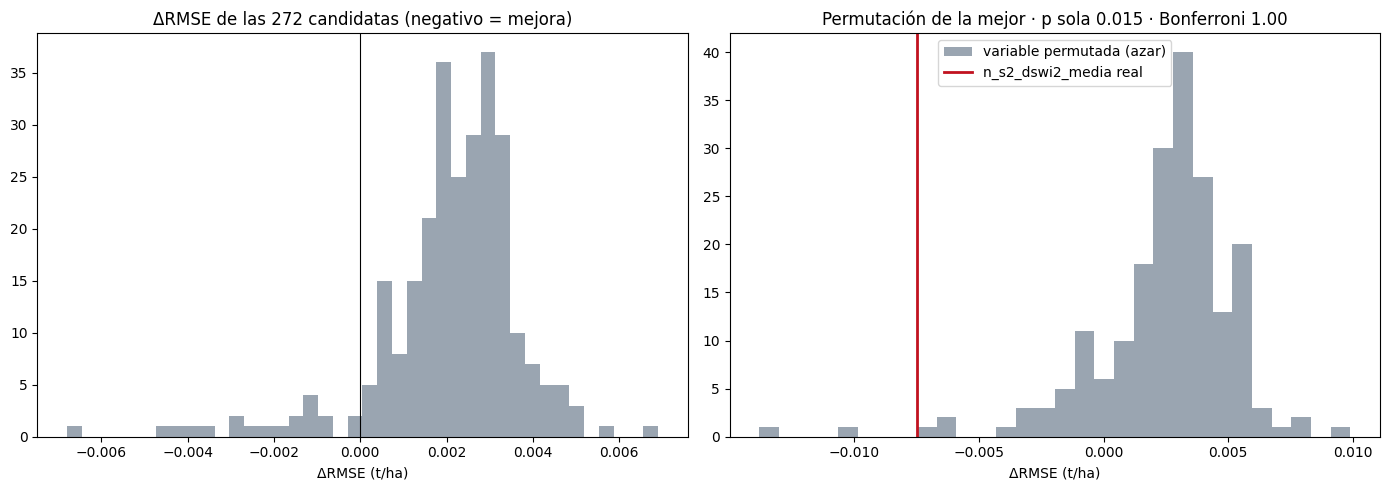

In [77]:
# Paso 20 · Barrido de >250 variables no usadas sobre la referencia (vecinas + lluvia + amplitud), con confirmación,
# permutación + Bonferroni y validación anidada. Es diagnóstico: NO cambia el modelo ni las 59.
# =====================================================================================
# PASO 20 · Barrido de variables no usadas
# ¿Alguna variable del dataset que NO está en el modelo lo mejoraría? Se prueban todas una por una sobre la referencia
# (vecinas + lluvia + amplitud, Ridge) y luego se revisa si la mejor mejora es real o suerte:
#   1. barrido: ΔRMSE de cada candidata con la validación del equipo (evaluar, 5 × 10)
#   2. confirmación de las 5 mejores con otras particiones (semillas 100-109)
#   3. prueba de permutación de la mejor + corrección de Bonferroni por el número de pruebas
#   4. validación anidada de "barrer y quedarse con la mejor": ¿mejora en parcelas que el barrido no vio?
# =====================================================================================
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
t0 = time.time()
REF20 = ["clim_prec_vegetativa_2025", "clim_amplitud_vegetativa_2025"]
b20 = cargar_base(OUT)

# ---- candidatas nuevas: los 22 índices de Sentinel-2 en la temporada de cada parcela y Landsat de otros años ----
s2 = pd.read_csv(OUT / "s2_clean_nub20.csv", parse_dates=["fecha"])
s2 = s2[(~s2.caida_brusca) & (s2.fecha.dt.year == 2025)]
_f = lambda doy: pd.Timestamp("2024-12-31") + pd.to_timedelta(doy, unit="D")
fe = b20[["ID_POLIGONO"]].assign(sub=_f(b20.pl_ndvi_doy_subida), sec=_f(b20.pl_ndvi_doy_secado))
s2 = s2.merge(fe, on="ID_POLIGONO"); s2 = s2[(s2.fecha >= s2["sub"]) & (s2.fecha <= s2.sec)]
IDX22 = [c[:-9] for c in s2.columns if c.endswith("_promedio")]
g = s2.groupby("ID_POLIGONO")
nuevas = pd.DataFrame(index=b20.ID_POLIGONO)
n_img = g.size().reindex(nuevas.index).fillna(0)
for ix in IDX22:
    nuevas[f"n_s2_{ix}_media"] = g[f"{ix}_promedio"].mean().reindex(nuevas.index).where(n_img >= 3)
    nuevas[f"n_s2_{ix}_max"] = g[f"{ix}_promedio"].max().reindex(nuevas.index).where(n_img >= 3)
    nuevas[f"n_s2_{ix}_std"] = g[f"{ix}_std"].mean().reindex(nuevas.index).where(n_img >= 3)   # heterogeneidad dentro de la parcela
ls = pd.read_csv(OUT / "landsat_clean_nub20.csv", parse_dates=["fecha"])
ls = ls[ls.fecha.dt.month.between(7, 10)]
for a in (2023, 2024):
    nuevas[f"n_ls_vi6t_media_{a}"] = ls[ls.fecha.dt.year == a].groupby("ID_POLIGONO").vi6t_promedio.mean().reindex(nuevas.index)
nuevas[f"n_ls_vi6t_std_2025"] = ls[ls.fecha.dt.year == 2025].groupby("ID_POLIGONO").vi6t_std.mean().reindex(nuevas.index)
b20 = b20.merge(nuevas.reset_index(), on="ID_POLIGONO", how="left")

# ---- lista de candidatas: todo lo numérico que no está en el modelo (sin calidad de imagen ni identificadores) ----
FUERA = {"ID_POLIGONO", "y", "rend_redondo", "x_km", "y_km", *REF20}
tr20 = b20[b20.CONJUNTO == "ENTRENAMIENTO"]
CAND = [c for c in b20.columns if c not in FUERA and not c.startswith("cal_") and pd.api.types.is_numeric_dtype(b20[c])
        and tr20[c].notna().sum() >= 100 and b20[c].nunique(dropna=True) > 1]

def familia20(c):
    if c.startswith("n_s2_"): return "Sentinel-2 · 22 índices (media, máximo, heterogeneidad)"
    if "vi6t" in c: return "Landsat VI6T (2025 e histórico)"
    if c.startswith("topo_"): return "Topografía"
    if c.startswith("hist_"): return "Historial NDVI 2022-2024"
    if "_std" in c: return "Heterogeneidad (columnas std)"
    if c.startswith("pl_"): return "Planet (fenología)"
    if c.startswith("s2_"): return "Sentinel-2 (fenología y humedad)"
    if c.startswith("clim_"): return "Clima (otras etapas y anomalías)"
    if c.startswith("int_"): return "Interacciones vegetación × lluvia"
    return "Otras"
print(f"Candidatas: {len(CAND)}")
print(pd.Series([familia20(c) for c in CAND]).value_counts().to_string())

# ---- 1. barrido ----
ref20 = evaluar(b20, REF20)
filas = []
for c in CAND:
    r = evaluar(b20, REF20 + [c])
    filas.append({"variable": c, "familia": familia20(c), "RMSE": r["RMSE"], "delta_RMSE": round(r["RMSE"] - ref20["RMSE"], 4),
                  "spearman_y": round(float(tr20[c].corr(tr20.y, method="spearman")), 4)})
barrido = pd.DataFrame(filas).sort_values("RMSE").reset_index(drop=True)
print(f"\n1 · Barrido terminado ({time.time() - t0:.0f} s). Referencia RMSE {ref20['RMSE']:.4f}. "
      f"Mejoran (ΔRMSE < 0): {(barrido.delta_RMSE < 0).sum()} de {len(barrido)}")
print(barrido.head(10).to_string(index=False))
print("\nMejor ΔRMSE por familia:"); print(barrido.groupby("familia").delta_RMSE.min().sort_values().to_string())

# ---- 2. confirmación con otras particiones ----
ref_b = evaluar(b20, REF20, semilla0=100)["RMSE"]
barrido["delta_semillas_100"] = np.nan
for i in barrido.index[:5]:
    barrido.loc[i, "delta_semillas_100"] = round(evaluar(b20, REF20 + [barrido.variable[i]], semilla0=100)["RMSE"] - ref_b, 4)
print("\n2 · Las 5 mejores con otras particiones (semillas 100-109):")
print(barrido.head(5)[["variable", "delta_RMSE", "delta_semillas_100"]].to_string(index=False))

# ---- 3. permutación de la mejor + Bonferroni ----
mejor = barrido.variable[0]; N_PERM = 199; rng = np.random.default_rng(2026)
ref5 = evaluar(b20, REF20, repeticiones=5)["RMSE"]
d_obs = evaluar(b20, REF20 + [mejor], repeticiones=5)["RMSE"] - ref5
d_perm = []
es_tr = b20.CONJUNTO.eq("ENTRENAMIENTO").values
for _ in range(N_PERM):
    bp = b20.copy(); bp.loc[es_tr, mejor] = rng.permutation(bp.loc[es_tr, mejor].values)
    d_perm.append(evaluar(bp, REF20 + [mejor], repeticiones=5)["RMSE"] - ref5)
p_sola = (1 + np.sum(np.array(d_perm) <= d_obs)) / (N_PERM + 1)
# Bonferroni: con muchas pruebas, el valor p de la mejor se multiplica por el número de candidatas.
p_bonf = min(1.0, p_sola * len(CAND))
print(f"\n3 · Mejor variable: {mejor} (ΔRMSE {d_obs:+.4f} con 5 repeticiones)")
print(f"    p de permutación si fuera la ÚNICA probada: {p_sola:.3f} · corregido por {len(CAND)} pruebas (Bonferroni): {p_bonf:.2f}")

# ---- 4. validación anidada: barrer y elegir dentro de cada fold ----
def ajustar_pred(tr_df, te_df, cols):
    XYa, ya = tr_df[["x_km", "y_km"]].values, tr_df.y.values
    va = _idw(XYa, XYa, ya, excluir_diag=True); vb = _idw(te_df[["x_km", "y_km"]].values, XYa, ya)
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
    m.fit(np.c_[va, tr_df[cols].values], ya)
    return m.predict(np.c_[vb, te_df[cols].values])

trn = b20[b20.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
est = trn.Municipio.where(trn.Municipio.map(trn.Municipio.value_counts()) >= 5, "Otros")
e_ref, e_sel, elegidas = [], [], []
# Validación anidada: dentro de cada fold externo se repite el barrido completo y se elige la mejor variable sin ver
# el fold.
for s in range(2):
    for a, v in StratifiedKFold(5, shuffle=True, random_state=s).split(trn, est):
        A, V = trn.iloc[a].reset_index(drop=True), trn.iloc[v].reset_index(drop=True)
        base_in = evaluar(A, REF20, repeticiones=1)["RMSE"]
        sc = {c: evaluar(A, REF20 + [c], repeticiones=1)["RMSE"] for c in CAND}
        c_best = min(sc, key=sc.get); elegidas.append(c_best)
        cols = REF20 + ([c_best] if sc[c_best] < base_in else [])
        e_ref.extend(V.y - ajustar_pred(A, V, REF20)); e_sel.extend(V.y - ajustar_pred(A, V, cols))
rm = lambda e: float(np.sqrt(np.mean(np.square(e))))
print(f"\n4 · Validación anidada (10 folds externos): referencia {rm(e_ref):.4f} → barrer y elegir la mejor {rm(e_sel):.4f}")
print(f"    Variable elegida en cada fold ({len(set(elegidas))} distintas en {len(elegidas)} folds): {', '.join(elegidas)}")

# ---- decisión y salidas ----
decision = ("NO entra ninguna variable: la mejor mejora no sobrevive a la corrección por pruebas múltiples "
            "y elegir por barrido empeora fuera de muestra (maldición del ganador)."
            if (p_bonf >= .05 or rm(e_sel) >= rm(e_ref)) else "Revisar: la mejor variable sobrevive a las pruebas.")
print("\nDECISIÓN:", decision, f"({time.time() - t0:.0f} s)")
barrido.to_csv(RES / "barrido_variables.csv", index=False)
pd.DataFrame([{"candidatas": len(CAND), "rmse_referencia": ref20["RMSE"], "mejor_variable": mejor,
               "delta_mejor": barrido.delta_RMSE[0], "p_permutacion_sola": round(p_sola, 3), "p_bonferroni": round(p_bonf, 3),
               "anidada_referencia": round(rm(e_ref), 4), "anidada_barrer_y_elegir": round(rm(e_sel), 4),
               "variables_distintas_elegidas": len(set(elegidas)), "decision": decision}]).to_csv(RES / "barrido_resumen.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(barrido.delta_RMSE, bins=40, color="#9aa5b1"); ax[0].axvline(0, c="k", lw=.8)
ax[0].set_title(f"ΔRMSE de las {len(CAND)} candidatas (negativo = mejora)"); ax[0].set_xlabel("ΔRMSE (t/ha)")
ax[1].hist(d_perm, bins=30, color="#9aa5b1", label="variable permutada (azar)"); ax[1].axvline(d_obs, c="#c1121f", lw=2, label=f"{mejor} real")
ax[1].set_title(f"Permutación de la mejor · p sola {p_sola:.3f} · Bonferroni {p_bonf:.2f}"); ax[1].set_xlabel("ΔRMSE (t/ha)"); ax[1].legend()
fig.tight_layout(); FIG20 = RES / "figs" / "paso20_barrido"; FIG20.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG20 / "20_barrido.png", dpi=150); plt.show()


## Paso 21 · Validación espacial del ensamble final
¿Qué pasa si la parcela está **lejos** de parcelas con dato conocido? Se valida el **mismo ensamble** con 4 esquemas: estratificada por municipio (la del equipo), bloques espaciales de 15 y de 8 grupos, y dejar un municipio fuera. En cada fold las vecinas, el promedio del municipio y el proceso gaussiano se calculan solo con el entrenamiento del fold. Luego mide el error según la distancia a la parcela conocida más cercana (contra un modelo sin ubicación) y estima el RMSE esperado para las 59 con **su** distancia real.

**Por qué la métrica principal sigue siendo la estratificada:** las 59 a calificar están a 0.35 km de mediana del entrenamiento (máx 1.9 km) y en municipios conocidos, igual que en la estratificada (0.41 km). Los bloques espaciales responden otra pregunta: qué pasaría en una región nueva. **No cambia el modelo ni las predicciones.** Tarda ~2 min. Salidas: `validacion_espacial.csv`, `error_por_distancia.csv`, `figs/paso21_validacion_espacial/`.

### Explicación

**Qué cambia entre esquemas.** En la validación estratificada, cada parcela que se valida suele tener una vecina de entrenamiento a unos cientos de metros (como las 59 reales). En los **bloques espaciales** (k-means de las coordenadas en 15 u 8 grupos) se dejan fuera zonas completas, y en **dejar un municipio fuera** se predice un municipio sin ninguna parcela suya en el entrenamiento: es la situación de "región nueva".

**Resultados de la corrida de referencia (mismo ensamble).** Estratificada 0.494 (distancia mediana 0.41 km) · bloques 15 → 0.577 (2.3 km) · bloques 8 → 0.672 (3.4 km) · dejar un municipio fuera → 0.749 (4.8 km). Las 59 están a 0.35 km de mediana (máximo 1.91 km) y todas en municipios con entrenamiento. Ponderando el error de cada rango de distancia por cuántas de las 59 caen en él, el **RMSE esperado para las 59 es ≈ 0.509**. El ensamble supera al modelo sin ubicación en todos los rangos.

**Cómo leer los resultados.** En la gráfica de la izquierda, cada barra es el mismo ensamble validado de forma cada vez más difícil (de vecinas conocidas a región nueva); la distancia junto a cada barra es la mediana a la parcela de entrenamiento más cercana. En la de la derecha se compara el error por rango de distancia contra un modelo sin ubicación: si la barra del ensamble es más baja en todos los rangos, la ubicación ayuda incluso lejos. El dato clave es el RMSE esperado para las 59 (≈ 0.509), que confirma el 0.494 principal.

**Conclusión.** No hay un problema metodológico: la validación estratificada sí corresponde a la situación del reto. El aumento del error con la distancia se reporta como **límite de uso**: la herramienta funciona bien rodeada de parcelas conocidas y pierde precisión en zonas nuevas.

  Estratificada por municipio (la del equipo)    RMSE 0.4940  (49 s)
  Bloques espaciales k-means (15 bloques)        RMSE 0.5770  (97 s)
  Bloques espaciales k-means (8 bloques)         RMSE 0.6714  (146 s)
  Dejar un municipio fuera                       RMSE 0.7487  (154 s)

1 · Mismo ensamble, distintas validaciones:
                                    esquema  distancia_mediana_km   RMSE  RMSE_sd    MAE     R2
Estratificada por municipio (la del equipo)                 0.411 0.4940   0.0062 0.3381 0.6607
    Bloques espaciales k-means (15 bloques)                 2.267 0.5770   0.0690 0.3963 0.5372
     Bloques espaciales k-means (8 bloques)                 3.354 0.6714   0.0111 0.4895 0.3732
                   Dejar un municipio fuera                 4.847 0.7487   0.0000 0.6083 0.2207
          REAL: las 59 parcelas a calificar                 0.349    NaN      NaN    NaN    NaN
   Las 59: distancia a la parcela de entrenamiento más cercana · mediana 0.35 km · P90 1.07 · máx 1.9

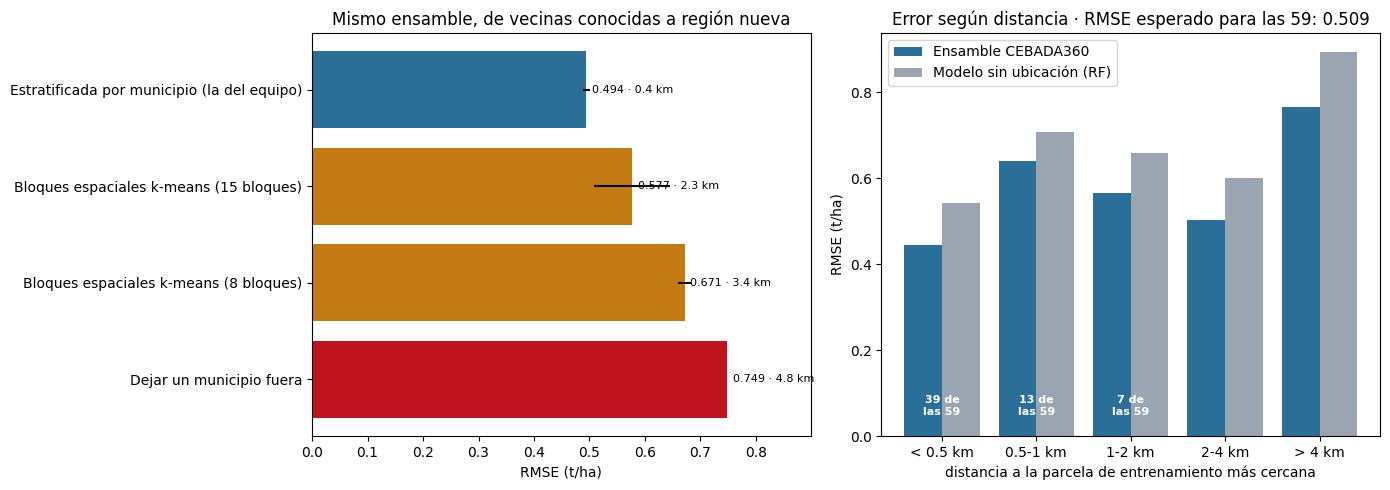

Guardado: validacion_espacial.csv, error_por_distancia.csv, figs/paso21_validacion_espacial/ (155 s)


In [78]:
# Paso 21 · El mismo ensamble con 4 validaciones (de vecinas conocidas a región nueva), error según distancia
# y RMSE esperado para las 59 según su distancia real. Diagnóstico: NO cambia el modelo ni las 59.
# =====================================================================================
# PASO 21 · Validación espacial del ensamble final
# ¿Qué tan bien predice el modelo si la parcela está LEJOS de parcelas con dato conocido?
#   1. El MISMO ensamble final con 4 esquemas de validación, de "parcelas vecinas conocidas" a "región nueva".
#      Las vecinas, el promedio del municipio y el proceso gaussiano se recalculan en cada fold solo con el
#      entrenamiento de ese fold (nunca con el rendimiento de las parcelas que se validan).
#   2. Error según la distancia a la parcela de entrenamiento más cercana, contra un modelo sin ubicación.
#   3. RMSE esperado para las 59 parcelas a calificar, ponderando por SU distancia real.
# No cambia el modelo ni las predicciones: es una prueba de sensibilidad para el reporte.
# =====================================================================================
import time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
t0 = time.time()
b21 = cargar_base(OUT)
tr21 = b21[b21.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
pr21 = b21[b21.CONJUNTO == "PREDICCION"].reset_index(drop=True)
y21, XY21 = tr21.y.values, tr21[["x_km", "y_km"]].values
NUC21 = [v for v in pd.read_csv(OUT / "variables_nucleo.csv").variable if v in tr21]
EST21 = tr21.Municipio.where(tr21.Municipio.map(tr21.Municipio.value_counts()) >= 5, "Otros")
REPS21 = 10

ESQUEMAS = {
    "Estratificada por municipio (la del equipo)": (lambda s: StratifiedKFold(5, shuffle=True, random_state=s).split(tr21, EST21), REPS21),
    "Bloques espaciales k-means (15 bloques)": (lambda s: GroupKFold(5).split(tr21, groups=KMeans(15, n_init=10, random_state=s).fit(XY21).labels_), REPS21),
    "Bloques espaciales k-means (8 bloques)": (lambda s: GroupKFold(5).split(tr21, groups=KMeans(8, n_init=10, random_state=s).fit(XY21).labels_), REPS21),
    "Dejar un municipio fuera": (lambda s: GroupKFold(tr21.Municipio.nunique()).split(tr21, groups=tr21.Municipio), 1),
}

filas, puntos = [], []
for nombre, (gen, reps) in ESQUEMAS.items():
    errs, rmses, dists = [], [], []
    for s in range(reps):
        e = np.full(len(tr21), np.nan)
        for a, v in gen(s):
            d = cdist(XY21[v], XY21[a]).min(1); dists.extend(d)
            p_ens = ModeloCebada360().fit(tr21.iloc[a]).predict(tr21.iloc[v])
            imp = SimpleImputer(strategy="median").fit(tr21.iloc[a][NUC21])
            rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1)
            p_rf = rf.fit(imp.transform(tr21.iloc[a][NUC21]), y21[a]).predict(imp.transform(tr21.iloc[v][NUC21]))
            e[v] = y21[v] - p_ens
            if nombre != "Dejar un municipio fuera":
                puntos += [{"dist": di, "e_ens": y21[i] - pe, "e_sin_ubic": y21[i] - pf} for i, di, pe, pf in zip(v, d, p_ens, p_rf)]
        errs.append(e); rmses.append(np.sqrt(np.mean(e ** 2)))
    E = np.concatenate(errs)
    filas.append({"esquema": nombre, "distancia_mediana_km": round(float(np.median(dists)), 3),
                  "RMSE": round(float(np.sqrt(np.mean(E ** 2))), 4), "RMSE_sd": round(float(np.std(rmses)), 4),
                  "MAE": round(float(np.mean(np.abs(E))), 4), "R2": round(float(1 - np.mean(E ** 2) / y21.var()), 4)})
    print(f"  {nombre:<46} RMSE {filas[-1]['RMSE']:.4f}  ({time.time() - t0:.0f} s)")
d59 = cdist(pr21[["x_km", "y_km"]].values, XY21).min(1)
esquemas21 = pd.DataFrame(filas)
esquemas21 = pd.concat([esquemas21, pd.DataFrame([{"esquema": "REAL: las 59 parcelas a calificar", "distancia_mediana_km": round(float(np.median(d59)), 3)}])],
                       ignore_index=True)
print("\n1 · Mismo ensamble, distintas validaciones:")
print(esquemas21.to_string(index=False))
print(f"   Las 59: distancia a la parcela de entrenamiento más cercana · mediana {np.median(d59):.2f} km · "
      f"P90 {np.percentile(d59, 90):.2f} · máx {d59.max():.2f} km · todas en municipios con entrenamiento: {pr21.Municipio.isin(tr21.Municipio).all()}")

# ---- 2. error según distancia ----
t = pd.DataFrame(puntos)
CORTES, ETQ = [0, .5, 1, 2, 4, np.inf], ["< 0.5 km", "0.5-1 km", "1-2 km", "2-4 km", "> 4 km"]
t["rango"] = pd.cut(t.dist, CORTES, labels=ETQ, right=False)
rm = lambda e: float(np.sqrt(np.mean(np.square(e))))
por_dist = t.groupby("rango", observed=False).agg(n_validaciones=("dist", "size"), RMSE_ensamble=("e_ens", rm),
                                                    RMSE_sin_ubicacion=("e_sin_ubic", rm)).round(3)
por_dist["parcelas_de_las_59"] = pd.Series(pd.cut(d59, CORTES, labels=ETQ, right=False)).value_counts().reindex(ETQ).fillna(0).astype(int).values
print("\n2 · Error según la distancia a la parcela conocida más cercana (estratificada + bloques 15 y 8):")
print(por_dist.to_string())

# ---- 3. RMSE esperado para las 59 ----
w = por_dist.parcelas_de_las_59
# RMSE esperado para las 59: se pondera el error de cada rango de distancia por cuántas de las 59 caen ahí.
rmse_59 = float(np.sqrt((por_dist.RMSE_ensamble ** 2 * w).sum() / w.sum()))
print(f"\n3 · RMSE esperado para las 59 (error de cada rango de distancia × cuántas de las 59 caen ahí): {rmse_59:.3f} t/ha")
gana = (por_dist.RMSE_ensamble < por_dist.RMSE_sin_ubicacion).all()
print(f"    El ensamble supera al modelo sin ubicación en todos los rangos de distancia: {gana}")
print("\nCONCLUSIÓN: para parcelas rodeadas de parcelas conocidas (el caso del reto) el error es ~0.49-0.51 t/ha; "
      "en una región nueva sube a 0.58-0.75. Para usar la herramienta en otra zona se necesitan algunas parcelas de referencia ahí.")
print("DECISIÓN: no revela un problema metodológico. Las 59 están en la situación de la validación del equipo (vecinas a ~0.35 km, "
      "municipios conocidos), así que esa sigue siendo la métrica principal. Las 59 predicciones NO cambian; los bloques espaciales "
      "se reportan como límite de uso en regiones nuevas.")
esquemas21.to_csv(RES / "validacion_espacial.csv", index=False)
por_dist.assign(RMSE_esperado_59=round(rmse_59, 3)).to_csv(RES / "error_por_distancia.csv")

# ---- figura ----
FIG21 = RES / "figs" / "paso21_validacion_espacial"; FIG21.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
e21 = esquemas21.dropna(subset=["RMSE"])
ax[0].barh(e21.esquema, e21.RMSE, xerr=e21.RMSE_sd.fillna(0), color=["#2a6f97", "#c47a12", "#c47a12", "#c1121f"])
for i, r in enumerate(e21.itertuples()):
    ax[0].text(r.RMSE + .01, i, f"{r.RMSE:.3f} · {r.distancia_mediana_km:.1f} km", va="center", fontsize=8)
ax[0].invert_yaxis(); ax[0].set_xlim(0, e21.RMSE.max() + .15); ax[0].set_xlabel("RMSE (t/ha)")
ax[0].set_title("Mismo ensamble, de vecinas conocidas a región nueva")
x = np.arange(len(ETQ))
ax[1].bar(x - .2, por_dist.RMSE_ensamble, .4, label="Ensamble CEBADA360", color="#2a6f97")
ax[1].bar(x + .2, por_dist.RMSE_sin_ubicacion, .4, label="Modelo sin ubicación (RF)", color="#9aa5b1")
for i, n in enumerate(por_dist.parcelas_de_las_59):
    if n: ax[1].text(i, .05, f"{n} de\nlas 59", ha="center", fontsize=8, color="w", weight="bold")
ax[1].set_xticks(x); ax[1].set_xticklabels(ETQ); ax[1].set_xlabel("distancia a la parcela de entrenamiento más cercana")
ax[1].set_ylabel("RMSE (t/ha)"); ax[1].legend(); ax[1].set_title(f"Error según distancia · RMSE esperado para las 59: {rmse_59:.3f}")
fig.tight_layout(); fig.savefig(FIG21 / "21_validacion_espacial.png", dpi=150); plt.show()
print(f"Guardado: validacion_espacial.csv, error_por_distancia.csv, figs/paso21_validacion_espacial/ ({time.time() - t0:.0f} s)")


## Paso 22 · Validación anidada de la elección del modelo
El 0.494 del ensamble salió de comparar 10 modelos con la **misma** validación (paso B), lo que puede ser optimista. Aquí se repite **todo** el proceso de elección dentro de cada fold externo: con 4/5 de las parcelas se comparan los 10 modelos y se elige el mejor; el elegido se califica en el 1/5 que no participó. 3 repeticiones × 5 folds = 15 elecciones completas.

**Regla de decisión, fijada antes de ver el resultado:** las 59 predicciones **no cambian** salvo que esto revele un problema metodológico real o que otro modelo gane de forma estable y por más que el ruido entre repeticiones. Tarda ~3 min. Salidas: `validacion_anidada_elecciones.csv`, `validacion_anidada_resumen.csv`, `figs/paso22_validacion_anidada/`.

> **Cómo reportar:** el RMSE ≈ 0.511 es del **procedimiento** "elegir el mejor de 10 modelos dentro de cada fold", no del ensamble final. El ensamble **fijo**, evaluado en esos mismos folds externos, da ≈ 0.500: esa es su estimación conservadora. Que el ensamble se elija en 7 de 15 folds es una **pluralidad** (la opción más elegida), no una mayoría.

**Cómo leer los resultados.**

Distingue dos cosas que es fácil confundir:
- **El procedimiento "elegir el mejor de 10 modelos"**, evaluado honestamente: RMSE ≈ 0.511 en la corrida de referencia. Es más alto porque a veces gana por azar un modelo que no generaliza mejor.
- **El ensamble fijo**, evaluado en esos mismos folds externos: RMSE ≈ 0.500, MAE ≈ 0.344, R² ≈ 0.653. Es la estimación conservadora del modelo que entregamos.

El ensamble fue el elegido en 7 de 15 elecciones (pluralidad, no mayoría); cuando no ganó, ganaron modelos casi empatados (vecinas, Ridge o Random Forest). Elegir un ganador cuesta ≈ +0.011 t/ha frente a promediar, lo que apoya usar el ensamble. **Las 59 no cambian.** Para el reporte: 0.494 (paso B) con una estimación conservadora de ≈ 0.50-0.51.

  repetición 1/3 lista (85 s)
  repetición 2/3 lista (171 s)
  repetición 3/3 lista (257 s)

Elecciones completas: 15 (3 repeticiones × 5 folds externos)
Modelo elegido en cada fold externo:
elegido
Ensamble CEBADA360 (Ridge + municipio + espacial)    7
Vecinas k=12 solas                                   3
Ridge: vecinas + lluvia + amplitud térmica           3
Random Forest: vecinas + lluvia + amplitud           1
Random Forest: vecinas + 24 variables núcleo         1
Posición del ensamble dentro de cada elección interna: {1: 7, 2: 3, 3: 4, 5: 1}

Métricas globales con las predicciones de los folds externos (parcelas que NO participaron en la elección):
                          procedimiento   RMSE    MAE     R2
Elegir el mejor de 10 modelos (anidada) 0.5107 0.3632 0.6374
      Ensamble fijo, mismas particiones 0.4997 0.3441 0.6528
     Ensamble en el paso B (no anidado) 0.4940 0.3381 0.6607
  → costo de 'elegir el mejor' frente al ensamble fijo (mismas particiones): +0.0109 t/ha
  →

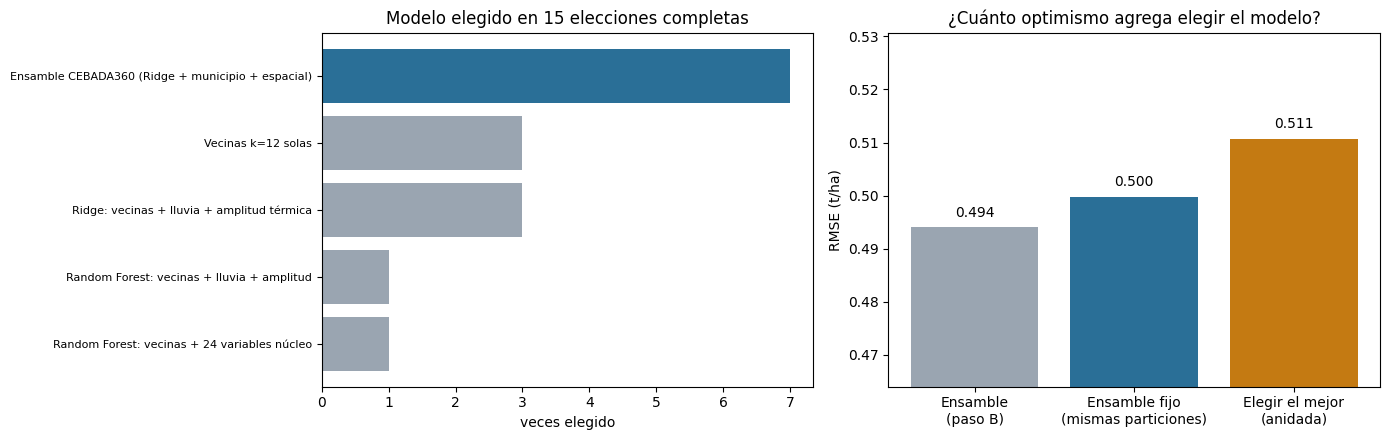

Guardado: validacion_anidada_elecciones.csv, validacion_anidada_resumen.csv, figs/paso22_validacion_anidada/ (257 s)


In [79]:
# Paso 22 · Validación anidada: se repite TODO el proceso de elección de modelo dentro de cada fold externo
# (3 repeticiones × 5 folds). Regla fijada antes de ver el resultado. NO cambia las 59.
# =====================================================================================
# PASO 22 · Validación anidada de la elección del modelo
# El RMSE 0.494 del ensamble salió de comparar 10 modelos con la MISMA validación (paso B). Elegir "el mejor"
# con los mismos datos que lo califican puede dar un número optimista. Aquí se repite TODO el proceso de elección
# dentro de cada fold externo:
#   - fold externo: se esconde 1/5 de las parcelas;
#   - con el 4/5 restante se comparan los 10 modelos con su propia validación interna (5 folds) y se elige el mejor;
#   - el elegido se entrena con el 4/5 y se califica en el 1/5 escondido, que no participó en la elección.
# Se reporta (a) el RMSE de "elegir y predecir" y (b) cuántas veces se elige cada modelo.
# REGLA DE DECISIÓN (fijada antes de ver el resultado): las 59 predicciones NO cambian salvo que esto revele un
# problema metodológico (p. ej. que el ensamble casi nunca gane dentro de los folds) o que otro modelo gane de forma
# estable y por más que el ruido entre repeticiones.
# =====================================================================================
import time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
t0 = time.time()
REPS22 = 3                                    # repeticiones del fold externo (3 × 5 = 15 elecciones completas)
CAND22 = [(n, f) for n, _, f in modelos]      # los 10 modelos del paso B, con las mismas funciones
NOMBRE_ENS = "Ensamble CEBADA360 (Ridge + municipio + espacial)"
rm = lambda e: float(np.sqrt(np.mean(np.square(e))))

e_anid, e_ens, filas = [], [], []
for s in range(REPS22):
    for k, (a, b) in enumerate(StratifiedKFold(5, shuffle=True, random_state=1000 + s).split(trI3, ESTI3)):
        # ---- elección interna: solo con las parcelas a (índices globales de trI3) ----
        est_a = ESTI3.iloc[a].values
        est_a = np.where(pd.Series(est_a).map(pd.Series(est_a).value_counts()) >= 5, est_a, "Otros")
        err_int = {n: [] for n, _ in CAND22}
        for ia, ib in StratifiedKFold(5, shuffle=True, random_state=s).split(a, est_a):
            A, B = a[ia], a[ib]
            for n, f in CAND22:
                err_int[n].extend(yI3[B] - f(A, B))
        rmse_int = {n: rm(v) for n, v in err_int.items()}
        elegido = min(rmse_int, key=rmse_int.get)
        f_el = dict(CAND22)[elegido]
        # ---- calificación en las parcelas b, que no participaron en la elección ----
        e_anid.extend(yI3[b] - f_el(a, b))
        e_ens.extend(yI3[b] - dict(CAND22)[NOMBRE_ENS](a, b))
        orden = sorted(rmse_int, key=rmse_int.get)
        filas.append({"repeticion": s, "fold": k, "elegido": elegido, "rmse_interno_elegido": round(rmse_int[elegido], 4),
                      "segundo": orden[1], "rmse_interno_segundo": round(rmse_int[orden[1]], 4),
                      "posicion_ensamble": orden.index(NOMBRE_ENS) + 1,
                      "rmse_externo_elegido": round(rm(yI3[b] - f_el(a, b)), 4)})
    print(f"  repetición {s + 1}/{REPS22} lista ({time.time() - t0:.0f} s)")

elec = pd.DataFrame(filas)
veces = elec.elegido.value_counts()
rmse_anid, rmse_ens = rm(e_anid), rm(e_ens)
rmse_B = float(metricas.loc[metricas.modelo == NOMBRE_ENS, "RMSE"].iloc[0])
print(f"\nElecciones completas: {len(elec)} ({REPS22} repeticiones × 5 folds externos)")
print("Modelo elegido en cada fold externo:"); print(veces.to_string())
print(f"Posición del ensamble dentro de cada elección interna: {elec.posicion_ensamble.value_counts().sort_index().to_dict()}")
_m = lambda e: (float(np.sqrt(np.mean(np.square(e)))), float(np.mean(np.abs(e))), float(1 - np.mean(np.square(e)) / yI3.var()))
tabla22 = pd.DataFrame([("Elegir el mejor de 10 modelos (anidada)", *_m(e_anid)), ("Ensamble fijo, mismas particiones", *_m(e_ens)),
                        ("Ensamble en el paso B (no anidado)", rmse_B,
                         float(metricas.loc[metricas.modelo == NOMBRE_ENS, "MAE"].iloc[0]), float(metricas.loc[metricas.modelo == NOMBRE_ENS, "R2"].iloc[0]))],
                       columns=["procedimiento", "RMSE", "MAE", "R2"]).round(4)
print("\nMétricas globales con las predicciones de los folds externos (parcelas que NO participaron en la elección):")
print(tabla22.to_string(index=False))
optimismo = rmse_anid - rmse_ens
print(f"  → costo de 'elegir el mejor' frente al ensamble fijo (mismas particiones): {optimismo:+.4f} t/ha")
print(f"  → diferencia del ensamble entre particiones (paso B vs estas): {rmse_ens - rmse_B:+.4f} t/ha (ruido de partición)")

# ---- decisión con la regla fijada arriba ----
frac_ens = veces.get(NOMBRE_ENS, 0) / len(elec)
n_ens = int(veces.get(NOMBRE_ENS, 0))
otro = veces.index[0] if veces.index[0] != NOMBRE_ENS else None
# 7 de 15 es PLURALIDAD (la opción más elegida), no mayoría; y 0.5107 es el RMSE del
# PROCEDIMIENTO "elegir el mejor de 10 en cada fold", no del ensamble fijo (que en esos mismos folds da ~0.4997).
frecuencia = ("mayoría" if frac_ens > .5 else
              "pluralidad: fue la opción elegida con más frecuencia, sin llegar a la mayoría" if veces.index[0] == NOMBRE_ENS else
              "no fue la opción más elegida")
if otro and frac_ens < .5 and rmse_anid < rmse_ens - .01:
    decision = (f"REVISAR: '{otro}' es la opción más elegida y elegir mejora por más que el ruido. Confirmar con más "
                f"repeticiones antes de cambiar nada; las 59 NO se cambian automáticamente.")
elif rmse_ens <= rmse_anid:
    decision = (f"Sin problema metodológico. El ensamble fue elegido en {n_ens} de {len(elec)} folds ({frecuencia}); cuando no gana, gana "
                f"un modelo casi empatado ({', '.join(dict.fromkeys(n.split(':')[0] for n in veces.index if n != NOMBRE_ENS))}). "
                f"El PROCEDIMIENTO de elegir un ganador en cada fold da RMSE {rmse_anid:.3f}; el ENSAMBLE FIJO, en esos mismos folds "
                f"externos, da {rmse_ens:.3f}: promediar modelos casi empatados es más robusto que escoger uno. Las 59 predicciones NO "
                f"cambian. Para el reporte: ensamble fijo 0.494 (paso B, elegido con esos mismos datos, puede ser algo optimista) y "
                f"{rmse_ens:.3f} en los folds externos de esta validación anidada (estimación más conservadora del ensamble). "
                f"{rmse_anid:.3f} corresponde al procedimiento de selección, no al ensamble final.")
else:
    decision = (f"El procedimiento de elegir dentro de cada fold da {rmse_anid:.3f} frente a {rmse_ens:.3f} del ensamble fijo en los mismos "
                f"folds; la diferencia está dentro del ruido. Las 59 predicciones NO cambian; para el ensamble fijo se reporta {rmse_ens:.3f}.")
print("\nDECISIÓN:", decision)
elec.to_csv(RES / "validacion_anidada_elecciones.csv", index=False)
tabla22.to_csv(RES / "validacion_anidada_metricas.csv", index=False)
pd.DataFrame([{"elecciones": len(elec), "veces_ensamble": int(veces.get(NOMBRE_ENS, 0)), "rmse_anidado": round(rmse_anid, 4),
               "mae_anidado": tabla22.MAE[0], "r2_anidado": tabla22.R2[0],
               "rmse_ensamble_mismas_particiones": round(rmse_ens, 4), "rmse_ensamble_paso_B": rmse_B,
               "optimismo": round(optimismo, 4), "decision": decision}]).to_csv(RES / "validacion_anidada_resumen.csv", index=False)

FIG22 = RES / "figs" / "paso22_validacion_anidada"; FIG22.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(veces.index, veces.values, color=["#2a6f97" if n == NOMBRE_ENS else "#9aa5b1" for n in veces.index])
ax[0].invert_yaxis(); ax[0].set_xlabel("veces elegido"); ax[0].set_title(f"Modelo elegido en {len(elec)} elecciones completas")
ax[0].tick_params(axis="y", labelsize=8)
v = [rmse_B, rmse_ens, rmse_anid]; lab = ["Ensamble\n(paso B)", "Ensamble fijo\n(mismas particiones)", "Elegir el mejor\n(anidada)"]
ax[1].bar(lab, v, color=["#9aa5b1", "#2a6f97", "#c47a12"])
for i, x in enumerate(v): ax[1].text(i, x + .002, f"{x:.3f}", ha="center")
ax[1].set_ylim(min(v) - .03, max(v) + .02); ax[1].set_ylabel("RMSE (t/ha)"); ax[1].set_title("¿Cuánto optimismo agrega elegir el modelo?")
fig.tight_layout(); fig.savefig(FIG22 / "22_validacion_anidada.png", dpi=150); plt.show()
print(f"Guardado: validacion_anidada_elecciones.csv, validacion_anidada_resumen.csv, figs/paso22_validacion_anidada/ ({time.time() - t0:.0f} s)")


## Paso 23 · ¿Pesos optimizados en vez de 1/3?
El ensamble usa ŷ = ⅓·Ridge + ⅓·Municipio + ⅓·GP. Aquí se prueba aprender los pesos minimizando (1/n) Σ (y − w₁ŷ₁ − w₂ŷ₂ − w₃ŷ₃)² + λ Σ (wⱼ − ⅓)², con Σw = 1 y w ≥ 0. Los pesos **y** λ se aprenden solo con el entrenamiento de cada fold (predicciones internas fuera de fold, λ por validación interna) y se califican en el fold externo, con las mismas particiones que los pesos iguales. Se evalúa en la validación del equipo **y** en bloques espaciales.

**Regla de adopción, fijada antes de ver el resultado:** los pesos optimizados se adoptan solo si bajan el RMSE en **ambas** validaciones, en al menos 80 % de las repeticiones y por más de 0.005 t/ha en promedio. Si no, se conservan los pesos iguales y las 59 predicciones **no cambian**. Tarda ~30 s. Salidas: `pesos_ensamble_comparacion.csv`, `pesos_ensamble_por_fold.csv`, `pesos_ensamble_por_repeticion.csv`, `figs/paso23_pesos/`.

**Cómo leer los resultados.**

Se prueba aprender los pesos minimizando el error cuadrático más una penalización λ·Σ(wⱼ − ⅓)² que los jala hacia ⅓, con pesos no negativos que suman 1. Pesos y λ se aprenden con predicciones fuera de fold **internas**, sin tocar el fold externo con que se califican. La búsqueda se hace en una malla fina del triángulo de pesos (paso 0.02).

**Resultados de la corrida de referencia.** Estratificada: iguales 0.4959 vs optimizados 0.4974 (los optimizados solo mejoraron en 1 de 5 repeticiones). Bloques espaciales: 0.6104 vs 0.6158. Los pesos aprendidos fueron muy inestables entre folds (Ridge entre 0 y 0.72, municipio entre 0.06 y 0.60, GP entre 0 y 0.94) y λ elegido fue casi siempre 1, es decir, "encoger hacia ⅓". **Se conservan los pesos iguales.**

  Estratificada por municipio (la del equipo): listo (13 s)
  Bloques espaciales (15): listo (25 s)

                                 validacion                                       ensamble   RMSE    MAE     R2
Estratificada por municipio (la del equipo)                   Pesos iguales (1/3) · actual 0.4959 0.3378 0.6581
Estratificada por municipio (la del equipo) Pesos optimizados (aprendidos dentro del fold) 0.4974 0.3389 0.6560
                    Bloques espaciales (15)                   Pesos iguales (1/3) · actual 0.6011 0.4140 0.4976
                    Bloques espaciales (15) Pesos optimizados (aprendidos dentro del fold) 0.6047 0.4166 0.4916

Pesos aprendidos en cada fold externo (media · mín · máx):
      w_ridge  w_municipio   w_gp
mean    0.399         0.33  0.271
min     0.320         0.08  0.000
max     0.920         0.60  0.380
λ elegido: {0.0: 4, 0.003: 1, 0.01: 3, 0.03: 3, 0.1: 3, 0.3: 6, 1.0: 29, 3.0: 1}

Mejora del RMSE por repetición (positivo = optimizados mejor)

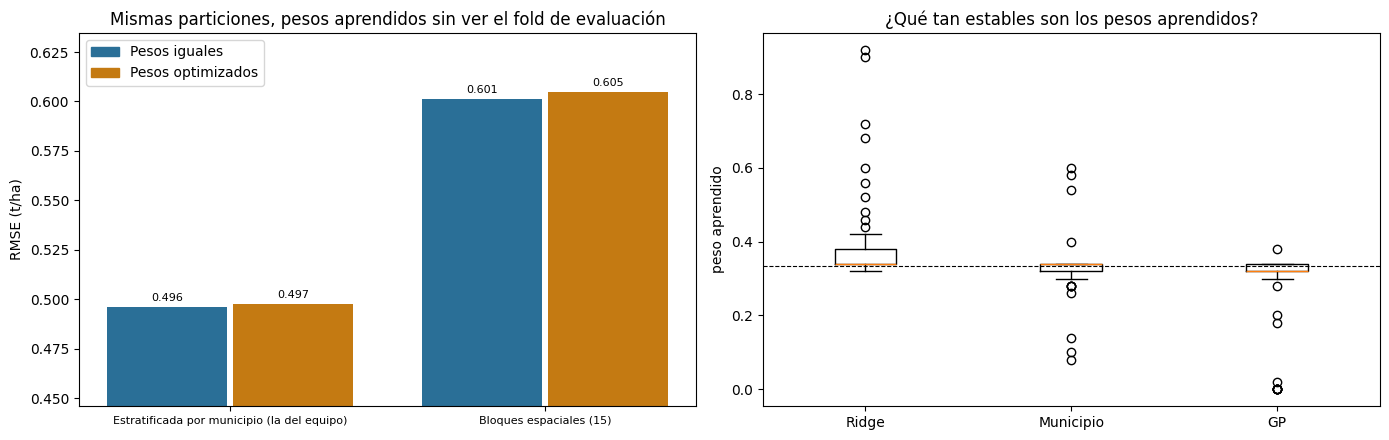

Guardado: pesos_ensamble_*.csv, figs/paso23_pesos/ (26 s)


In [80]:
# Paso 23 · ¿Mejoran pesos aprendidos en vez de 1/3? Pesos y λ se aprenden SOLO dentro de cada fold; regla de
# adopción fijada antes de ver el resultado. Diagnóstico: NO cambia el modelo ni las 59.
# =====================================================================================
# PASO 23 · ¿Pesos optimizados en vez de 1/3?
# Ensamble actual: ŷ = 1/3·Ridge + 1/3·Municipio + 1/3·GP. Aquí se prueba aprender los pesos:
#     min_w  (1/n) Σ (y − w1·ŷ_Ridge − w2·ŷ_Mun − w3·ŷ_GP)²  +  λ Σ (w_j − 1/3)²     con  Σw = 1,  w ≥ 0
# SIN FUGA, en tres niveles dentro de cada fold externo (que nunca se usa para aprender nada):
#   1. con el entrenamiento externo se generan predicciones FUERA DE FOLD de los 3 componentes (5 folds internos);
#   2. λ se elige con esas predicciones dejando fuera un fold interno a la vez (los pesos se aprenden con los otros 4);
#   3. con el λ elegido se aprenden los pesos con todas las predicciones internas; los componentes se reentrenan con
#      todo el entrenamiento externo y se califican en el fold externo. Mismas particiones para pesos iguales.
# Se evalúa en la validación del equipo (estratificada) Y en bloques espaciales (15).
# REGLA DE ADOPCIÓN (fijada antes de ver el resultado): se adoptan los pesos optimizados solo si bajan el RMSE
# en AMBAS validaciones, en al menos 80 % de las repeticiones y por más de 0.005 t/ha en promedio. Si no, se
# conservan los pesos iguales y las 59 predicciones NO cambian.
# =====================================================================================
import time, warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.cluster import KMeans
t0 = time.time()
REPS23 = 5
LAMBDAS = [0, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]   # λ grande = casi pesos iguales
PASO_W = 0.02
_g = np.arange(0, 1 + 1e-9, PASO_W)
W_GRID = np.clip(np.array([(a, b, 1 - a - b) for a in _g for b in _g if a + b <= 1 + 1e-9]), 0, 1)   # todo el triángulo Σw=1, w≥0
COMP = ["ridge", "municipio", "espacial"]


# Búsqueda exhaustiva en la malla del triángulo (Σw = 1, w >= 0) con penalización hacia 1/3.
def pesos_optimos(P, y, lam):
    """P: n×3 predicciones de los componentes. Busca en una malla fina del triángulo (exacto a ±0.01)."""
    mse = ((y[:, None] - P @ W_GRID.T) ** 2).mean(0) + lam * ((W_GRID - 1 / 3) ** 2).sum(1)
    return W_GRID[mse.argmin()]


def componentes_oof(idx, est, semilla):
    """Predicciones fuera de fold de los 3 componentes para las parcelas idx (índices de trI3)."""
    P = np.zeros((len(idx), 3)); folds = np.zeros(len(idx), int)
    for k, (ia, ib) in enumerate(StratifiedKFold(5, shuffle=True, random_state=semilla).split(idx, est)):
        c = ModeloCebada360().fit(trI3.iloc[idx[ia]]).componentes(trI3.iloc[idx[ib]])
        P[ib] = c[COMP].values; folds[ib] = k
    return P, folds


def evaluar_pesos(generador, nombre):
    filas = []
    for s in range(REPS23):
        e_eq, e_op = np.full(len(trI3), np.nan), np.full(len(trI3), np.nan)
        for a, b in generador(s):
            est_a = ESTI3.iloc[a].values
            est_a = np.where(pd.Series(est_a).map(pd.Series(est_a).value_counts()) >= 5, est_a, "Otros")
            P, folds = componentes_oof(a, est_a, s)
            ya = yI3[a]
            # λ por validación interna: pesos con 4 folds internos, error en el quinto
            score = {lam: np.mean([((ya[folds == k] - P[folds == k] @ pesos_optimos(P[folds != k], ya[folds != k], lam)) ** 2).mean()
                                   for k in range(5)]) for lam in LAMBDAS}
            lam = min(score, key=score.get)
            w = pesos_optimos(P, ya, lam)
            cb = ModeloCebada360().fit(trI3.iloc[a]).componentes(trI3.iloc[b])[COMP].values
            e_eq[b] = yI3[b] - cb.mean(1)
            e_op[b] = yI3[b] - cb @ w
            filas.append({"validacion": nombre, "repeticion": s, "lambda": lam, "w_ridge": w[0], "w_municipio": w[1], "w_gp": w[2]})
        yield s, e_eq, e_op, filas[-5:]


def met(e):
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e))), "R2": float(1 - np.mean(e ** 2) / yI3.var())}


VALIDACIONES = {
    "Estratificada por municipio (la del equipo)": lambda s: StratifiedKFold(5, shuffle=True, random_state=2000 + s).split(trI3, ESTI3),
    "Bloques espaciales (15)": lambda s: GroupKFold(5).split(trI3, groups=KMeans(15, n_init=10, random_state=2000 + s).fit(XYI3).labels_),
}
res, pesos, por_rep = [], [], []
for nombre, gen in VALIDACIONES.items():
    E_eq, E_op = [], []
    for s, e_eq, e_op, f in evaluar_pesos(gen, nombre):
        E_eq.append(e_eq); E_op.append(e_op); pesos += f
        por_rep.append({"validacion": nombre, "repeticion": s, "RMSE_iguales": met(e_eq)["RMSE"], "RMSE_optimizados": met(e_op)["RMSE"]})
    E_eq, E_op = np.concatenate(E_eq), np.concatenate(E_op)
    for etq, E in [("Pesos iguales (1/3) · actual", E_eq), ("Pesos optimizados (aprendidos dentro del fold)", E_op)]:
        res.append({"validacion": nombre, "ensamble": etq, **{k: round(v, 4) for k, v in met(E).items()}})
    print(f"  {nombre}: listo ({time.time() - t0:.0f} s)")

res = pd.DataFrame(res); pesos = pd.DataFrame(pesos); por_rep = pd.DataFrame(por_rep)
por_rep["mejora"] = por_rep.RMSE_iguales - por_rep.RMSE_optimizados
print("\n" + res.to_string(index=False))
print("\nPesos aprendidos en cada fold externo (media · mín · máx):")
print(pesos[["w_ridge", "w_municipio", "w_gp"]].agg(["mean", "min", "max"]).round(3).to_string())
print("λ elegido:", pesos["lambda"].value_counts().sort_index().to_dict())
print("\nMejora del RMSE por repetición (positivo = optimizados mejor):")
print(por_rep.groupby("validacion").mejora.agg(media="mean", desv="std", reps_que_mejoran=lambda x: int((x > 0).sum())).round(4).to_string())

# ---- decisión con la regla fijada arriba ----
ok = []
for v, g in por_rep.groupby("validacion"):
    ok.append(g.mejora.mean() > 0.005 and (g.mejora > 0).mean() >= .8)
if all(ok):
    decision = ("Los pesos optimizados mejoran de forma consistente en ambas validaciones: REVISAR con el equipo antes de adoptarlos "
                "(las 59 no se cambian automáticamente).")
else:
    m = por_rep.groupby("validacion").mejora.mean()
    decision = (f"Se conservan los pesos iguales. La mejora media es {m[list(VALIDACIONES)[0]]:+.4f} t/ha en la estratificada y "
                f"{m[list(VALIDACIONES)[1]]:+.4f} t/ha en la espacial (negativo = los optimizados son peores), por debajo del umbral de 0.005 o inestable entre repeticiones. Los pesos aprendidos "
                f"cambian de fold a fold, así que fijarlos agregaría ruido. Las 59 predicciones NO cambian.")
print("\nDECISIÓN:", decision)
res.to_csv(RES / "pesos_ensamble_comparacion.csv", index=False)
pesos.to_csv(RES / "pesos_ensamble_por_fold.csv", index=False)
por_rep.assign(decision=decision).to_csv(RES / "pesos_ensamble_por_repeticion.csv", index=False)

FIG23 = RES / "figs" / "paso23_pesos"; FIG23.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, (v, g) in enumerate(res.groupby("validacion", sort=False)):
    ax[0].bar([i - .2, i + .2], g.RMSE, .38, color=["#2a6f97", "#c47a12"])
    for x, r in zip([i - .2, i + .2], g.RMSE): ax[0].text(x, r + .003, f"{r:.3f}", ha="center", fontsize=8)
ax[0].set_xticks(range(2)); ax[0].set_xticklabels(res.validacion.unique(), fontsize=8); ax[0].set_ylabel("RMSE (t/ha)")
ax[0].set_ylim(res.RMSE.min() - .05, res.RMSE.max() + .03)
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#2a6f97", "#c47a12"]], labels=["Pesos iguales", "Pesos optimizados"])
ax[0].set_title("Mismas particiones, pesos aprendidos sin ver el fold de evaluación")
ax[1].boxplot([pesos.w_ridge, pesos.w_municipio, pesos.w_gp]); ax[1].set_xticks([1, 2, 3]); ax[1].set_xticklabels(["Ridge", "Municipio", "GP"])
ax[1].axhline(1 / 3, c="k", ls="--", lw=.8); ax[1].set_ylabel("peso aprendido"); ax[1].set_title("¿Qué tan estables son los pesos aprendidos?")
fig.tight_layout(); fig.savefig(FIG23 / "23_pesos_ensamble.png", dpi=150); plt.show()
print(f"Guardado: pesos_ensamble_*.csv, figs/paso23_pesos/ ({time.time() - t0:.0f} s)")


> **Nota sobre los pesos del ensamble.** Por la prueba del paso 23 se conservan los **pesos iguales (⅓, ⅓, ⅓)**. Los pesos optimizados, aprendidos solo dentro de cada fold de validación, **no mejoraron** el RMSE ni en la validación del equipo ni en la validación espacial, y cambiaban mucho de un fold a otro; los pesos iguales son más estables y no se ajustan con los datos que se evalúan. **Este paso no modifica el modelo ni las 59 predicciones de la entrega** (`resultados_I3/ENTREGA/`): solo lee los datos y escribe sus propios archivos (`pesos_ensamble_*.csv` y su gráfica).

## Paso 24 · Crédito y riesgo por parcela
Convierte la predicción en lo que necesita un intermediario financiero: ingreso esperado y pesimista, **crédito sugerido**, capacidad de pago, **probabilidad modelada de ingreso insuficiente** y un **indicador exploratorio de riesgo** con su motivo. Supuestos con fuente (`supuestos_credito.csv`): precio de la cebada maltera 7,500 MXN/t (acuerdos Grupo Modelo y Heineken con productores, mayo 2025) y costo, porcentaje financiado e intereses de **FIRA Agrocostos, Cebada TMF Hidalgo PV 2025** (zona Altiplano; aplica a Hidalgo, Tlaxcala, Estado de México y Puebla).

- **Intervalo asimétrico** con los errores fuera de muestra del modelo (el límite inferior es el que importa para prestar).
- **Crédito sugerido** = la cuota FIRA, salvo que en el escenario pesimista no alcance para pagarla.
- **Escenario retrospectivo simulado:** con las 138 parcelas de rendimiento real, se decide el crédito con la predicción fuera de muestra y se revisa si el ingreso de cosecha *simulado* (rendimiento real × área × precio supuesto) alcanzaría para pagar; se compara contra dar la cuota FIRA a todas.
- **Sensibilidad:** precio y costo ±20 % (el precio −20 % representa grano castigado por calidad).

**Este paso no modifica el modelo ni las 59 predicciones:** solo lee `resultados_I3/` y `outputs/` y escribe en `resultados_I4/`. Tarda ~20 s. Salidas: `credito_por_parcela.csv` (para la app), `supuestos_credito.csv`, `retrospectiva_138.csv`, `retrospectiva_resumen.csv`, `sensibilidad_credito.csv`, `credito_y_riesgo.png`.

> **Cómo leer este paso.** No hay datos de préstamos otorgados, morosidad ni recuperación: todo es un **escenario simulado** con supuestos fijos de precio, costo e intereses. Por eso se habla de **"ingreso insuficiente simulado"** y **"brecha de cobertura simulada"**, no de impago ni de dinero no recuperado; y la probabilidad es **modelada bajo supuestos**, no una probabilidad calibrada de incumplimiento. Además, el ajuste presta menos por diseño, lo que reduce la brecha en parte de forma mecánica: el resultado no prueba que el modelo reduzca el riesgo crediticio real. El costo de FIRA es un presupuesto de referencia, no una medición de cada parcela. No se proponen reglas automáticas de aprobación o rechazo de créditos.

**Resultados de nuestra corrida de referencia.** Con los supuestos del recuadro anterior, el rendimiento mínimo para pagar crédito + intereses es ≈ 2.95 t/ha y para cubrir todo el costo ≈ 3.23 t/ha. Los percentiles 10 y 90 de los errores fuera de muestra son ≈ −0.60 y +0.56 t/ha, por eso el intervalo es asimétrico. En las 59: riesgo bajo 25, medio 32 y alto 2 (AGC_120 por rendimiento esperado bajo y AGC_065 por banderas de calidad); 37 con la cuota FIRA completa y 22 con crédito reducido. En el escenario retrospectivo simulado, dar la cuota FIRA a todas deja 14 de 138 parcelas (10.1 %) con ingreso insuficiente; con el ajuste de CEBADA360, 10 (7.2 %).

**Por qué hay un solo semáforo en la app.** La app muestra el semáforo de crédito de este paso y no el del paso E, porque está ligado a una decisión concreta, usa los errores reales del modelo en lugar de suponer normalidad y explica su motivo en palabras.

Rendimiento mínimo para pagar el crédito FIRA + intereses: 2.95 t/ha
Rendimiento mínimo para cubrir todo el costo + intereses:  3.23 t/ha
Errores fuera de muestra: p10 -0.595 · p90 +0.555 t/ha (intervalo asimétrico al 80 %)

Las 59 a calificar · indicador exploratorio de riesgo (no es probabilidad de incumplimiento): {'bajo': 25, 'medio': 32, 'alto': 2}
  crédito FIRA completo: 37 · reducido: 22 · monto sugerido 6.97 de 7.43 millones MXN

Escenario retrospectivo simulado (138 parcelas con rendimiento real; ingreso insuficiente simulado, no impago real):
                          regla  parcelas_ingreso_insuficiente  pct_ingreso_insuficiente  credito_colocado_mxn  brecha_cobertura_simulada_mxn  pct_brecha_simulada
Cuota FIRA a todas (sin modelo)                             14                      10.1              17132587                         426564                 2.49
 Crédito ajustado con CEBADA360                             10                       7.2              16177847    

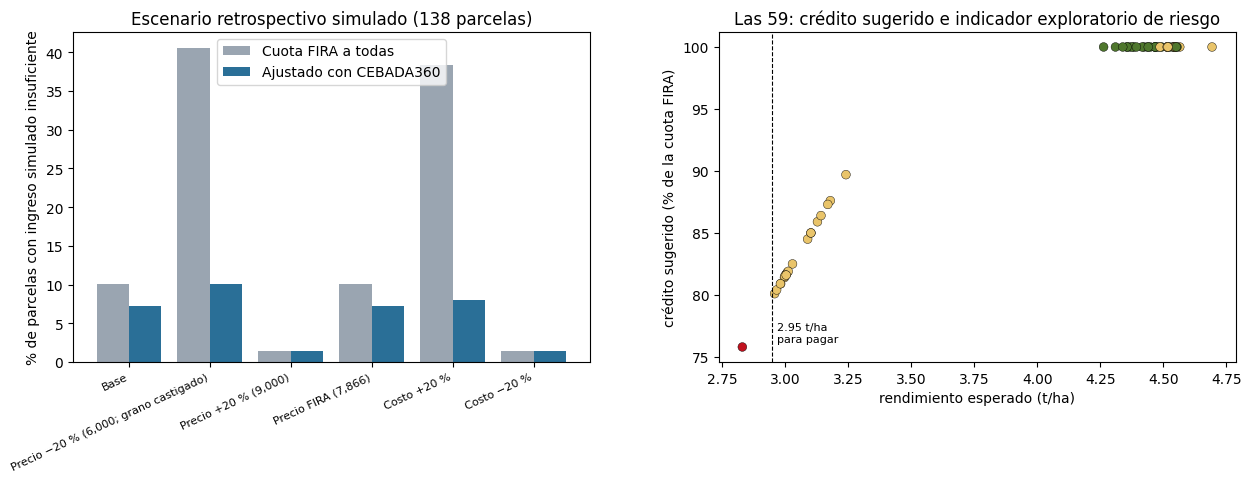


Guardado en resultados_I4/: supuestos_credito.csv, credito_por_parcela.csv, retrospectiva_138.csv, retrospectiva_resumen.csv, sensibilidad_credito.csv, credito_y_riesgo.png


In [81]:
# Paso 24 · Crédito y riesgo por parcela : crédito sugerido, probabilidad modelada de ingreso
# insuficiente con errores reales del modelo, escenario retrospectivo SIMULADO y sensibilidad. NO cambia las 59.
# =====================================================================================
# CEBADA360 · Crédito y riesgo por parcela
# Convierte la predicción de rendimiento del modelo en: ingreso esperado y pesimista, crédito sugerido,
# capacidad de pago y un INDICADOR EXPLORATORIO de riesgo productivo. Escenario retrospectivo SIMULADO con las 138 parcelas de
# rendimiento conocido.
# NO modifica el modelo ni las 59 predicciones: solo lee resultados_I3/ y outputs/ y escribe en resultados_I4/.
# =====================================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

BASE = Path(globals().get("BASE", Path.cwd()))
OUT, RES3 = BASE / "outputs", BASE / "resultados_I3"
RES4 = BASE / "resultados_I4"; RES4.mkdir(exist_ok=True)

# ---------------------------------------------------------------- 1. supuestos (cada uno con su fuente)
FIRA = "FIRA Agrocostos, Cebada TMF Hidalgo PV 2025 (zona Altiplano; aplica a Hidalgo, Tlaxcala, Edo. Méx. y Puebla)"
PRECIO = 7500.0                      # MXN/t
COSTO_HA = 20977.0                   # MXN/ha, costo financiable total (sin renta de la tierra)
PCT_FINANCIADO = 0.90                # créditos de hasta 160,000 UDIS (todas las parcelas quedan debajo)
CREDITO_HA = 18878.0                 # MXN/ha = 90 % del costo (FIRA)
INTERESES_HA = 3242.0                # MXN/ha de intereses sobre el crédito (FIRA, 2 ministraciones, vence 31-mar-2026)
FACTOR_PAGO = (CREDITO_HA + INTERESES_HA) / CREDITO_HA      # 1 peso prestado -> 1.1717 a pagar
TASA_IMPLICITA = INTERESES_HA / CREDITO_HA                  # ~17 % sobre el plazo (~18 % anual)
supuestos = pd.DataFrame([
    ("Precio de la cebada maltera, PV 2025", PRECIO, "MXN/t",
     "Acuerdos Grupo Modelo (7,500) y Heineken (7,513 + bonificaciones) con productores; La Jornada San Luis 04-may-2025, Excélsior 14-may-2025. "
     "SIAP aún no publica el precio medio rural PV 2025. FIRA supone 7,866."),
    ("Costo de producción financiable", COSTO_HA, "MXN/ha", FIRA + ". No incluye renta de la tierra (5,000 MXN/ha/ciclo)."),
    ("Porcentaje financiado", PCT_FINANCIADO, "fracción", FIRA + ". Créditos de hasta 160,000 UDIS; la parcela mayor (64 ha) queda debajo."),
    ("Crédito por hectárea (cuota FIRA)", CREDITO_HA, "MXN/ha", FIRA),
    ("Intereses por hectárea", INTERESES_HA, "MXN/ha", FIRA + ". Ministraciones abr-2025 y ago-2025; vencimiento 31-mar-2026."),
    ("Factor de pago (crédito + intereses) / crédito", round(FACTOR_PAGO, 4), "—", "Calculado con las cifras de FIRA (tasa implícita ~18 % anual)."),
    ("Seguro agrícola", 2736.0, "MXN/ha", FIRA + ". Incluido dentro del costo."),
], columns=["concepto", "valor", "unidad", "fuente"])
supuestos["fecha_consulta"] = "13-oct-2026"
supuestos.to_csv(RES4 / "supuestos_credito.csv", index=False, encoding="utf-8-sig")
# Rendimiento de equilibrio: (crédito por ha × factor de pago) / precio.
REND_EQ_CREDITO = CREDITO_HA * FACTOR_PAGO / PRECIO          # t/ha para pagar crédito + intereses
REND_EQ_TOTAL = (COSTO_HA + INTERESES_HA) / PRECIO           # t/ha para cubrir todo el costo + intereses
print(f"Rendimiento mínimo para pagar el crédito FIRA + intereses: {REND_EQ_CREDITO:.2f} t/ha")
print(f"Rendimiento mínimo para cubrir todo el costo + intereses:  {REND_EQ_TOTAL:.2f} t/ha")

# ---------------------------------------------------------------- 2. datos
pred = pd.read_csv(RES3 / "predicciones.csv")[["ID_POLIGONO", "CONJUNTO", "y_pred", "semaforo"]]
bm = pd.read_csv(OUT / "base_maestra_v3.csv")[["ID_POLIGONO", "Municipio", "Estado", "area_ha", "y"]]
rie = pd.read_csv(OUT / "senales_riesgo.csv")[["ID_POLIGONO", "riesgo_nivel", "riesgo_lluvia_cosecha_oct_pct"]]
bq = pd.read_csv(OUT / "banderas_calidad.csv")[["ID_POLIGONO", "bq_revisar"]]
d = pred.merge(bm, on="ID_POLIGONO").merge(rie, on="ID_POLIGONO", how="left").merge(bq, on="ID_POLIGONO", how="left")
assert len(d) == 197
tr = d[d.CONJUNTO == "ENTRENAMIENTO"]
ERR = (tr.y - tr.y_pred).values                               # errores FUERA DE MUESTRA del ensamble (paso E)
P10, P90 = np.quantile(ERR, [.10, .90])
print(f"Errores fuera de muestra: p10 {P10:+.3f} · p90 {P90:+.3f} t/ha (intervalo asimétrico al 80 %)")


def calcular(df, errores, precio=PRECIO, costo_ha=COSTO_HA):
    """Indicadores de crédito de cada parcela con los errores del modelo (intervalo empírico asimétrico)."""
    p10, p90 = np.quantile(errores, [.10, .90])
    credito_ha = costo_ha * PCT_FINANCIADO
    rend_pago = credito_ha * FACTOR_PAGO / precio
    o = pd.DataFrame({"ID_POLIGONO": df.ID_POLIGONO.values})
    o["rend_esperado"] = df.y_pred.values
    o["rend_lim_inf_80"] = (df.y_pred + p10).clip(lower=0).values
    o["rend_lim_sup_80"] = (df.y_pred + p90).values
    o["ingreso_esperado"] = o.rend_esperado * df.area_ha.values * precio
    o["ingreso_pesimista"] = o.rend_lim_inf_80 * df.area_ha.values * precio
    o["costo_produccion"] = costo_ha * df.area_ha.values
    o["credito_cuota_fira"] = credito_ha * df.area_ha.values
    o["pago_cuota_fira"] = o.credito_cuota_fira * FACTOR_PAGO
    # crédito sugerido: la cuota FIRA, salvo que en el escenario pesimista no alcance para pagarla
    # Crédito sugerido: la cuota FIRA o, si es menor, lo que el ingreso pesimista alcanzaría a pagar con intereses.
    o["credito_sugerido"] = np.minimum(o.credito_cuota_fira, o.ingreso_pesimista / FACTOR_PAGO)
    o["pct_de_cuota_fira"] = o.credito_sugerido / o.credito_cuota_fira
    o["cobertura_pesimista"] = o.ingreso_pesimista / o.pago_cuota_fira       # > 1: paga la cuota FIRA aun en el escenario malo
    # probabilidad de NO poder pagar la cuota FIRA: con los errores reales del modelo (no supone normalidad)
    # Probabilidad empírica: con qué fracción de los errores reales del modelo el rendimiento no alcanzaría para
    # pagar.
    o["prob_ingreso_insuficiente"] = [(yp + errores < rend_pago).mean() for yp in df.y_pred.values]
    return o


# ---------------------------------------------------------------- 3. tabla por parcela (las 197)
c = calcular(d, ERR)
c = d[["ID_POLIGONO", "CONJUNTO", "Municipio", "Estado", "area_ha", "semaforo", "riesgo_nivel", "bq_revisar"]].rename(columns={"semaforo": "semaforo_rendimiento_I3"}).merge(c, on="ID_POLIGONO")
motivo = []
for r in c.itertuples():
    m = []
    if r.prob_ingreso_insuficiente >= .5: m.append("rendimiento esperado bajo el necesario para pagar")
    elif r.prob_ingreso_insuficiente >= .2: m.append("probabilidad modelada relevante de que el ingreso no cubra el crédito")
    if r.bq_revisar == "revisar": m.append("dato satelital a revisar")
    if r.riesgo_nivel >= 1: m.append("señal de riesgo climático 2025")
    motivo.append("; ".join(m) if m else "sin alertas")
c["motivo"] = motivo
c["nivel_riesgo"] = np.select([(c.prob_ingreso_insuficiente >= .5) | (c.bq_revisar == "revisar"),
                               (c.prob_ingreso_insuficiente >= .2) | (c.riesgo_nivel >= 1)], ["alto", "medio"], "bajo")
# semáforo ÚNICO para la app (el semáforo de rendimiento del paso E sigue en predicciones.csv, pero mide solo rendimiento < 3 t/ha con supuesto normal)
c["semaforo_credito"] = c.nivel_riesgo.map({"bajo": "verde", "medio": "amarillo", "alto": "rojo"})
c = c.round({"rend_esperado": 3, "rend_lim_inf_80": 3, "rend_lim_sup_80": 3, "ingreso_esperado": 0, "ingreso_pesimista": 0,
             "costo_produccion": 0, "credito_cuota_fira": 0, "pago_cuota_fira": 0, "credito_sugerido": 0, "pct_de_cuota_fira": 3,
             "cobertura_pesimista": 3, "prob_ingreso_insuficiente": 3})
c.sort_values("ID_POLIGONO").to_csv(RES4 / "credito_por_parcela.csv", index=False, encoding="utf-8-sig")
p59 = c[c.CONJUNTO == "PREDICCION"]
print(f"\nLas 59 a calificar · indicador exploratorio de riesgo (no es probabilidad de incumplimiento): {p59.nivel_riesgo.value_counts().reindex(['bajo','medio','alto']).fillna(0).astype(int).to_dict()}")
print(f"  crédito FIRA completo: {(p59.pct_de_cuota_fira >= .999).sum()} · reducido: {(p59.pct_de_cuota_fira < .999).sum()} "
      f"· monto sugerido {p59.credito_sugerido.sum()/1e6:.2f} de {p59.credito_cuota_fira.sum()/1e6:.2f} millones MXN")

# ---------------------------------------------------------------- 4. escenario retrospectivo SIMULADO (las 138 con rendimiento real)
# Para cada parcela: crédito decidido con su predicción FUERA DE MUESTRA y con los errores de las OTRAS 137 (sin fuga);
# luego se revisa con el rendimiento REAL si el ingreso SIMULADO (rendimiento × área × precio supuesto) alcanzaría para pagar.
def retrospectiva(precio=PRECIO, costo_ha=COSTO_HA):
    filas = []
    for i, r in enumerate(tr.itertuples()):
        # Retrospectiva sin fuga: cada parcela se evalúa con los errores de las OTRAS 137.
        o = calcular(tr.iloc[[i]], np.delete(ERR, i), precio, costo_ha).iloc[0]
        ingreso_real = r.y * r.area_ha * precio
        filas.append({"ID_POLIGONO": r.ID_POLIGONO, "y_real": r.y, "area_ha": r.area_ha,
                      "credito_fira": o.credito_cuota_fira, "credito_modelo": o.credito_sugerido,
                      "insuf_fira": ingreso_real < o.pago_cuota_fira,
                      "insuf_modelo": ingreso_real < o.credito_sugerido * FACTOR_PAGO,
                      "brecha_fira": max(0, o.pago_cuota_fira - ingreso_real),
                      "brecha_modelo": max(0, o.credito_sugerido * FACTOR_PAGO - ingreso_real)})
    return pd.DataFrame(filas)


bt = retrospectiva()
res = pd.DataFrame([
    {"regla": "Cuota FIRA a todas (sin modelo)", "parcelas_ingreso_insuficiente": int(bt.insuf_fira.sum()),
     "pct_ingreso_insuficiente": round(100 * bt.insuf_fira.mean(), 1), "credito_colocado_mxn": round(bt.credito_fira.sum()),
     "brecha_cobertura_simulada_mxn": round(bt.brecha_fira.sum())},
    {"regla": "Crédito ajustado con CEBADA360", "parcelas_ingreso_insuficiente": int(bt.insuf_modelo.sum()),
     "pct_ingreso_insuficiente": round(100 * bt.insuf_modelo.mean(), 1), "credito_colocado_mxn": round(bt.credito_modelo.sum()),
     "brecha_cobertura_simulada_mxn": round(bt.brecha_modelo.sum())}])
res["pct_brecha_simulada"] = (100 * res.brecha_cobertura_simulada_mxn / res.credito_colocado_mxn).round(2)
bt.to_csv(RES4 / "retrospectiva_138.csv", index=False)
res.to_csv(RES4 / "retrospectiva_resumen.csv", index=False)
print("\nEscenario retrospectivo simulado (138 parcelas con rendimiento real; ingreso insuficiente simulado, no impago real):")
print(res.to_string(index=False))
print("  OJO (corrección del 14-oct): no son impagos observados. Es una SIMULACIÓN: si el ingreso de cosecha (rendimiento real × "
      "área × precio supuesto) alcanzaría para pagar un crédito hipotético. No hay datos de préstamos, morosidad ni recuperación. "
      "Además, el ajuste presta MENOS por diseño, lo que reduce la brecha en parte de forma mecánica: no prueba menor riesgo crediticio real.")

# ---------------------------------------------------------------- 5. sensibilidad: precio y costo ±20 %
sens = []
for etq, pr_, co_ in [("Base", PRECIO, COSTO_HA), ("Precio −20 % (6,000; grano castigado)", 6000., COSTO_HA),
                      ("Precio +20 % (9,000)", 9000., COSTO_HA), ("Precio FIRA (7,866)", 7866., COSTO_HA),
                      ("Costo +20 %", PRECIO, COSTO_HA * 1.2), ("Costo −20 %", PRECIO, COSTO_HA * .8)]:
    b = retrospectiva(pr_, co_)
    c59 = calcular(d[d.CONJUNTO == "PREDICCION"], ERR, pr_, co_)
    sens.append({"escenario": etq, "precio": pr_, "costo_ha": round(co_),
                 "rend_minimo_pago_t_ha": round(co_ * PCT_FINANCIADO * FACTOR_PAGO / pr_, 2),
                 "insuf_sin_modelo_pct": round(100 * b.insuf_fira.mean(), 1), "insuf_con_modelo_pct": round(100 * b.insuf_modelo.mean(), 1),
                 "brecha_sin_modelo_pct": round(100 * b.brecha_fira.sum() / b.credito_fira.sum(), 2),
                 "brecha_con_modelo_pct": round(100 * b.brecha_modelo.sum() / b.credito_modelo.sum(), 2),
                 "las_59_con_credito_reducido": int((c59.pct_de_cuota_fira < .999).sum())})
sens = pd.DataFrame(sens); sens.to_csv(RES4 / "sensibilidad_credito.csv", index=False)
print("\nSensibilidad:"); print(sens.to_string(index=False))

# ---------------------------------------------------------------- 6. gráfica
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
x = np.arange(len(sens))
ax[0].bar(x - .2, sens.insuf_sin_modelo_pct, .4, label="Cuota FIRA a todas", color="#9aa5b1")
ax[0].bar(x + .2, sens.insuf_con_modelo_pct, .4, label="Ajustado con CEBADA360", color="#2a6f97")
ax[0].set_xticks(x); ax[0].set_xticklabels(sens.escenario, rotation=25, ha="right", fontsize=8)
ax[0].set_ylabel("% de parcelas con ingreso simulado insuficiente"); ax[0].legend(loc="upper center"); ax[0].set_title("Escenario retrospectivo simulado (138 parcelas)")
col = {"bajo": "#4f772d", "medio": "#e9c46a", "alto": "#c1121f"}
ax[1].scatter(p59.rend_esperado, p59.pct_de_cuota_fira * 100, c=p59.nivel_riesgo.map(col), s=40, edgecolor="k", lw=.3)
ax[1].axvline(REND_EQ_CREDITO, ls="--", c="k", lw=.8); ax[1].text(REND_EQ_CREDITO + .02, .06, f"{REND_EQ_CREDITO:.2f} t/ha\npara pagar", fontsize=8, transform=ax[1].get_xaxis_transform())
ax[1].set_xlabel("rendimiento esperado (t/ha)"); ax[1].set_ylabel("crédito sugerido (% de la cuota FIRA)")
ax[1].set_title("Las 59: crédito sugerido e indicador exploratorio de riesgo")
fig.subplots_adjust(bottom=.28, wspace=.25); fig.savefig(RES4 / "credito_y_riesgo.png", dpi=150, bbox_inches="tight"); plt.show()
print("\nGuardado en resultados_I4/: supuestos_credito.csv, credito_por_parcela.csv, retrospectiva_138.csv, "
      "retrospectiva_resumen.csv, sensibilidad_credito.csv, credito_y_riesgo.png")


## Paso 25 · Diagnóstico exploratorio de variabilidad residual y meseta predictiva
¿Cuánta variación del rendimiento queda sin explicar por la ubicación (vecinas, municipio, patrón espacial)? Se compara el RMSE del ensamble contra varias estimaciones del "ruido" de los datos.

> **Importante:** este paso **no estima un error irreducible ni una cota inferior del RMSE**. El ruido que estima un proceso gaussiano depende del kernel y de la especificación (puede absorber señal agronómica no modelada), y el nugget del semivariograma es muy incierto con 138 parcelas. Es un diagnóstico **exploratorio**, compatible (o no) con una meseta de los modelos basados en ubicación.

Estimaciones, ninguna perfecta:
- **GP dentro de municipio:** mismo kernel del modelo, sobre el rendimiento menos la media de su municipio, con las 138 y en los 50 folds de la validación del equipo. En simulaciones con ruido conocido **sobrestimó** ~0.06 t/ha.
- **Nugget del semivariograma:** cuánto difieren parcelas prácticamente pegadas (modelo exponencial, bootstrap por parcelas). En simulaciones **subestimó** ~0.05 t/ha; si su intervalo es demasiado ancho no se usa.
- **Pares a menos de 0.5 km** (sin modelo) y **GP sobre el rendimiento crudo:** incluyen variación espacial real; dependen del modelo o de la distancia.
- **Redondeo a 0.5 t/ha** (`rend_redondo`, paso 1): σ = 0.5/√12 en cada parcela redondeada.
- **Error del ensamble en parcelas redondeadas vs medidas**, con un valor por parcela (las repeticiones no cuentan como independientes).

√(RMSE² − σ²) se reporta solo como escala **hipotética** de variación no explicada bajo esos supuestos, no como la reducción de RMSE disponible. **No cambia el modelo, los pesos ni las 59 predicciones.** Tarda ~1 min. Salidas: `variabilidad_residual_resumen.csv`, `variabilidad_residual_semivariograma.csv`, `variabilidad_residual_por_grupo.csv`, `figs/paso25_variabilidad_residual/25_variabilidad_residual.png`.

**Cómo leer los resultados.**

Este paso compara el RMSE del ensamble con varias estimaciones del "ruido" de los datos. La clave para interpretarlo: **ninguna estimación es una cota inferior demostrada**. El ruido del GP depende del kernel (puede absorber señal agronómica que no modelamos) y el *nugget* del semivariograma —la semivarianza que queda a distancia casi cero— es muy incierto con 138 parcelas. Por eso la conclusión se formula como "compatible con una meseta" y no como "ya no se puede mejorar". Los resultados de la corrida de referencia están en la celda de conclusión después del paso 26.

Entrenamiento: 138 parcelas · rendimiento redondeado a 0.5: 45 · medido: 93
1 · Ensamble oficial, errores fuera de fold de paso B (10 repeticiones × 5 folds): RMSE 0.4940 t/ha
2 · Proceso gaussiano sobre el rendimiento crudo (como en el modelo): 0.727**2 * RBF(length_scale=9.81) + WhiteKernel(noise_level=0.339)
    ruido σ = 0.4935 t/ha · escala 9.81 km (incluye los saltos entre municipios: sobreestima)
    Proceso gaussiano dentro de municipio (rendimiento − media municipal): 0.132**2 * RBF(length_scale=1) + WhiteKernel(noise_level=0.982)
    ruido σ = 0.4869 t/ha · escala 1.00 km · en los 50 folds: mediana 0.4957, P5-P95 [0.4351, 0.5202]
3 · Semivariograma: varianza total del rendimiento 0.7192 (desv. 0.8481 t/ha)
 desde_km  hasta_km  pares  dist_media_km  semivarianza
     0.00      0.25     23         0.1473        0.0897
     0.25      0.50     66         0.3939        0.1947
     0.50      0.75     58         0.6536        0.3174
     0.75      1.00     79         0.8723        0

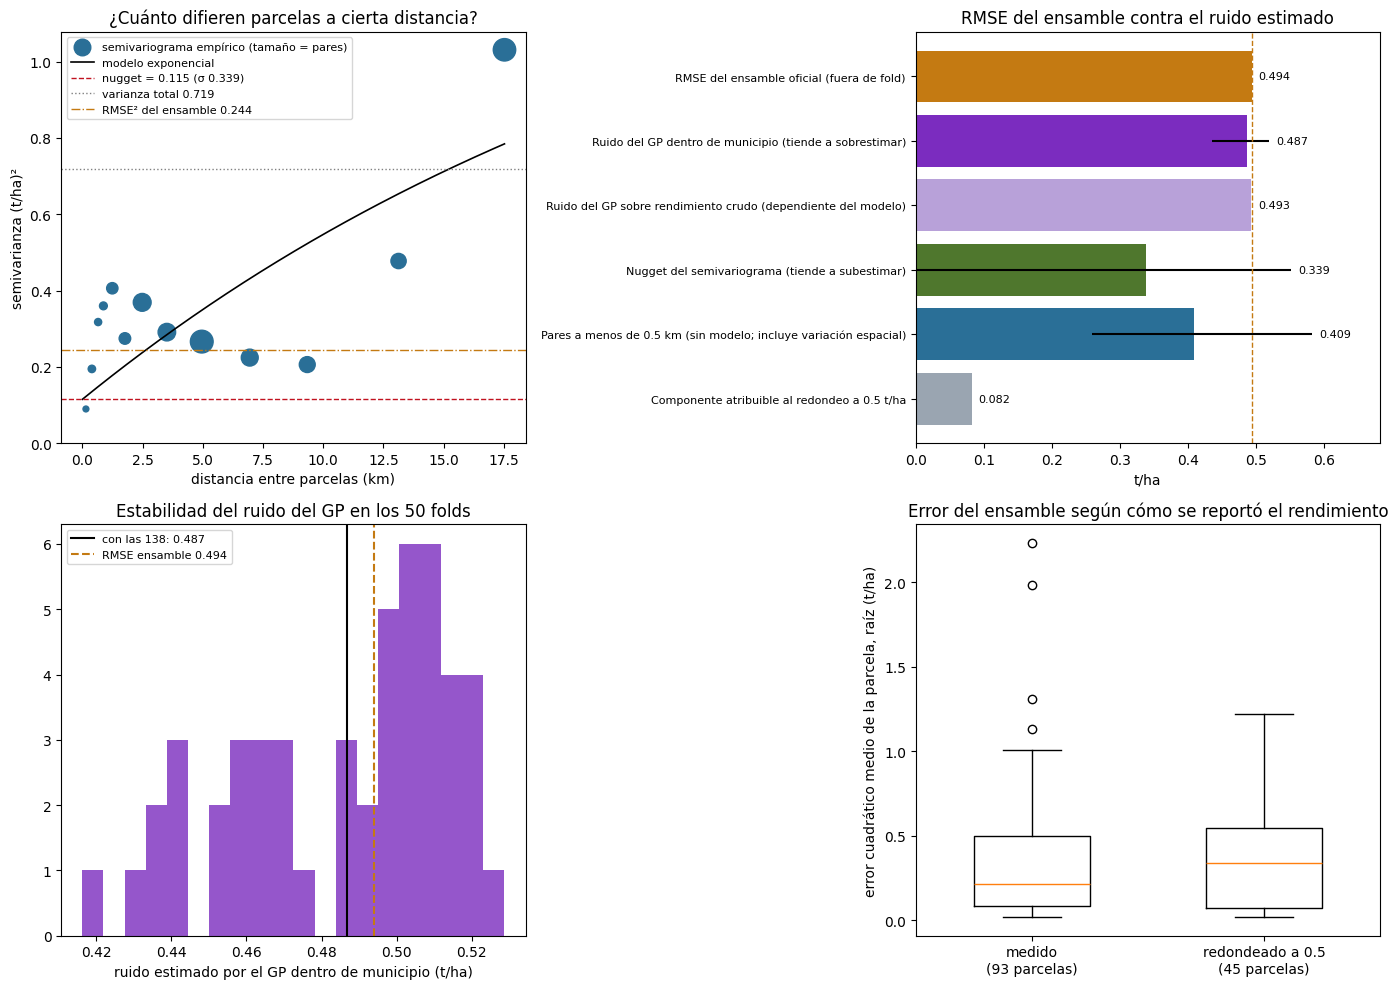

Guardado: variabilidad_residual_resumen.csv, variabilidad_residual_semivariograma.csv, variabilidad_residual_por_grupo.csv, figs/paso25_variabilidad_residual/25_variabilidad_residual.png (16 s)


In [82]:
# Paso 25 · Diagnóstico exploratorio: RMSE del ensamble vs. varias estimaciones del ruido (GP, semivariograma,
# pares cercanos, redondeo a 0.5). No estima un error irreducible. NO cambia el modelo ni las 59.
# =====================================================================================
# PASO 25 · Diagnóstico exploratorio de variabilidad residual y meseta predictiva
# Pregunta: ¿cuánta variación del rendimiento queda sin explicar por la ubicación (vecinas, municipio, patrón espacial)?
# este paso NO estima un "error irreducible" ni una cota inferior del RMSE.
# El ruido que estima un proceso gaussiano depende del kernel y de la especificación (puede absorber señal agronómica
# no modelada), y el nugget del semivariograma es muy incierto con 138 parcelas. Es un diagnóstico EXPLORATORIO.
#   1. Errores fuera de fold del ensamble oficial (los del paso B; no se reentrena nada).
#   2. Ruido estimado por un proceso gaussiano con el mismo kernel del modelo (WhiteKernel), sobre el rendimiento
#      menos la media de su municipio (el ensamble ya tiene ese componente), con las 138 y en cada fold.
#   3. Semivariograma empírico del rendimiento: el "nugget" es la diferencia que queda entre parcelas
#      prácticamente pegadas. Se ajusta un modelo exponencial y se da un intervalo bootstrap por parcelas.
#   4. Pares de parcelas a menos de 0.5 km: estimación directa sin modelo (incluye algo de variación espacial real).
#   5. Variación que mete el redondeo a múltiplos de 0.5 t/ha (rend_redondo del paso 1).
#   6. Error del ensamble en parcelas con rendimiento redondeado vs medido (pareado por parcela, bootstrap).
# √(RMSE² − σ²) se reporta solo como escala HIPOTÉTICA de variación no explicada bajo esos supuestos, no como la
# reducción de RMSE disponible. NO cambia el modelo, los pesos ni las 59 predicciones. Tarda ~1 min.
# =====================================================================================
import time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial.distance import pdist
from scipy.optimize import curve_fit
from sklearn.model_selection import StratifiedKFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
t0 = time.time()

# ---------------------------------------------------------------- rutas y datos
BASE = Path(globals().get("BASE", Path.cwd()))
if "OUT" not in globals() or not (Path(OUT) / "base_maestra_v3.csv").exists():
    _hits = sorted(BASE.rglob("base_maestra_v3.csv"))
    assert _hits, "No encuentro base_maestra_v3.csv: corre antes los pasos 1 a 12."
    OUT = _hits[0].parent
OUT = Path(OUT)
RES = BASE / "resultados_I3"; RES.mkdir(exist_ok=True)
FIG25 = RES / "figs" / "paso25_variabilidad_residual"; FIG25.mkdir(parents=True, exist_ok=True)
REDONDEO = 0.5                       # los rendimientos reportados son múltiplos de 0.5 t/ha (paso 1)
B_BOOT = 200
SEMILLA_25 = 2026
rng25 = np.random.default_rng(SEMILLA_25)

b25 = pd.read_csv(OUT / "base_maestra_v3.csv").merge(
    pd.read_csv(OUT / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km"]], on="ID_POLIGONO", how="left")
tr25 = b25[b25.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
y25 = tr25.y.values.astype(float)
XY25 = tr25[["x_km", "y_km"]].values.astype(float)
n25 = len(tr25)
red25 = tr25.rend_redondo.fillna(0).astype(int).values
assert n25 == 138 and np.isfinite(y25).all(), "Se esperaban 138 parcelas de entrenamiento con rendimiento."
print(f"Entrenamiento: {n25} parcelas · rendimiento redondeado a 0.5: {red25.sum()} · medido: {n25 - red25.sum()}")

# ---------------------------------------------------------------- 1. errores fuera de fold del ensamble oficial
if ("OOF_ENS" in globals() and "trI3" in globals() and np.ndim(OOF_ENS) == 2
        and list(trI3.ID_POLIGONO) == list(tr25.ID_POLIGONO)):
    OOF25 = np.asarray(OOF_ENS, dtype=float)
    fuente_oof = f"paso B ({OOF25.shape[0]} repeticiones × 5 folds)"
else:                                # el notebook no se corrió completo: se usa la repetición 0 guardada en el paso E
    _p = pd.read_csv(RES / "predicciones.csv").set_index("ID_POLIGONO")
    OOF25 = _p.loc[tr25.ID_POLIGONO, "y_pred"].values.astype(float)[None, :]
    fuente_oof = "predicciones.csv (1 repetición; RESPALDO: solo si no se corrió el paso B en esta sesión)"
E25 = y25[None, :] - OOF25
RMSE25 = float(np.sqrt((E25 ** 2).mean()))
mse_parcela = (E25 ** 2).mean(0)                 # un valor por parcela: las repeticiones NO cuentan como independientes
print(f"1 · Ensamble oficial, errores fuera de fold de {fuente_oof}: RMSE {RMSE25:.4f} t/ha")

# ---------------------------------------------------------------- 2. ruido estimado por el proceso gaussiano del modelo
def ruido_gp(XY, y, escala_min=0.1):
    """Mismo kernel que ModeloCebada360. Con normalize_y=True el ruido sale en unidades de y estandarizada:
    σ_ruido (t/ha) = sqrt(noise_level) · desv(y) (sklearn usa la desviación con ddof=0).
    escala_min: con una escala espacial más chica que la distancia entre parcelas, el RBF se vuelve ruido y la
    estimación se rompe (ruido ≈ 0). Para medir el ruido se exige que lo "espacial" varíe en ≥ 1 km."""
    k = ConstantKernel(0.5) * RBF(length_scale=3.0, length_scale_bounds=(escala_min, 50)) + WhiteKernel(0.2)
    gp = GaussianProcessRegressor(k, normalize_y=True, random_state=0).fit(XY, y)
    return float(np.sqrt(gp.kernel_.k2.noise_level) * np.std(y)), float(gp.kernel_.k1.k2.length_scale), gp.kernel_

def ruido_gp_mun(XY, y, mun):
    """GP sobre el rendimiento menos la media de SU municipio (el ensamble ya tiene ese componente). Así los saltos
    entre municipios no se cuentan como ruido. Corrección por grados de libertad: restar la media de cada municipio
    reduce la varianza del ruido en (1 − 1/n_m)."""
    mun = pd.Series(np.asarray(mun))
    r = y - mun.map(pd.Series(y).groupby(mun).mean()).values
    corr = np.sqrt(len(y) / max(len(y) - mun.nunique(), 1))
    s_, ls_, k_ = ruido_gp(XY, r, escala_min=1.0)
    return s_ * corr, ls_, k_


sig_gp_bruto, ls_gp_bruto, kern_gp_bruto = ruido_gp(XY25, y25)
sig_gp, ls_gp, kern_gp = ruido_gp_mun(XY25, y25, tr25.Municipio)
est25 = tr25.Municipio.where(tr25.Municipio.map(tr25.Municipio.value_counts()) >= 5, "Otros")
sig_gp_folds = []
for s in range(10):
    for a, _b in StratifiedKFold(5, shuffle=True, random_state=s).split(tr25, est25):
        sig_gp_folds.append(ruido_gp_mun(XY25[a], y25[a], tr25.Municipio.values[a])[0])   # medias solo del fold
sig_gp_folds = np.array(sig_gp_folds)
print(f"2 · Proceso gaussiano sobre el rendimiento crudo (como en el modelo): {kern_gp_bruto}")
print(f"    ruido σ = {sig_gp_bruto:.4f} t/ha · escala {ls_gp_bruto:.2f} km (incluye los saltos entre municipios: sobreestima)")
print(f"    Proceso gaussiano dentro de municipio (rendimiento − media municipal): {kern_gp}")
print(f"    ruido σ = {sig_gp:.4f} t/ha · escala {ls_gp:.2f} km · en los 50 folds: "
      f"mediana {np.median(sig_gp_folds):.4f}, P5-P95 [{np.percentile(sig_gp_folds, 5):.4f}, {np.percentile(sig_gp_folds, 95):.4f}]")

# ---------------------------------------------------------------- 3. semivariograma empírico y nugget
BORDES = np.array([0, .25, .5, .75, 1, 1.5, 2, 3, 4, 6, 8, 11, 15, 20, 30])


def semivariograma(XY, y):
    d = pdist(XY); g = pdist(y[:, None], "sqeuclidean") / 2
    ok = d > 1e-9                                     # en el bootstrap, una parcela repetida no se compara consigo misma
    d, g = d[ok], g[ok]
    bordes = BORDES[BORDES <= d.max() / 2 + 1e-9]
    filas = []
    for lo, hi in zip(bordes[:-1], bordes[1:]):
        m = (d >= lo) & (d < hi)
        if m.sum():
            filas.append({"desde_km": lo, "hasta_km": hi, "pares": int(m.sum()), "dist_media_km": d[m].mean(), "semivarianza": g[m].mean()})
    return pd.DataFrame(filas)


def exponencial(h, nugget, sill_parcial, alcance):
    return nugget + sill_parcial * (1 - np.exp(-h / alcance))


def ajustar_nugget(sv, var_y):
    sv = sv[sv.pares >= 15]
    if len(sv) < 4:
        return np.nan, None
    try:
        p, _ = curve_fit(exponencial, sv.dist_media_km, sv.semivarianza, p0=[sv.semivarianza.iloc[0] / 2, var_y / 2, 3],
                         sigma=1 / np.sqrt(sv.pares), bounds=([0, 0, .05], [2 * var_y, 2 * var_y, 50]), maxfev=20000)
        return float(p[0]), p
    except Exception:
        return np.nan, None


sv25 = semivariograma(XY25, y25)
nug25, par25 = ajustar_nugget(sv25, y25.var())
nug_boot = []
for _ in range(B_BOOT):
    i = rng25.choice(n25, n25, replace=True)
    nug_boot.append(ajustar_nugget(semivariograma(XY25[i], y25[i]), y25[i].var())[0])
nug_boot = np.array(nug_boot)
sig_nug = np.sqrt(nug25) if np.isfinite(nug25) else np.nan
ic_nug = np.sqrt(np.nanpercentile(nug_boot, [5, 95])) if np.isfinite(nug_boot).sum() >= 20 else (np.nan, np.nan)
print(f"3 · Semivariograma: varianza total del rendimiento {y25.var():.4f} (desv. {y25.std():.4f} t/ha)")
print(sv25.round(4).to_string(index=False))
if par25 is not None:
    print(f"    modelo exponencial: nugget {par25[0]:.4f} · meseta parcial {par25[1]:.4f} · alcance {par25[2]:.2f} km")
print(f"    ruido σ = √nugget = {sig_nug:.4f} t/ha · bootstrap por parcelas ({B_BOOT}) P5-P95 [{ic_nug[0]:.4f}, {ic_nug[1]:.4f}] "
      f"· ajustes fallidos {int(np.isnan(nug_boot).sum())}")

# ---------------------------------------------------------------- 4. pares de parcelas muy cercanas (sin modelo)
D_CERCA = 0.5
iu, ju = np.triu_indices(n25, 1)
dpar = np.sqrt(((XY25[iu] - XY25[ju]) ** 2).sum(1))
cerca = dpar < D_CERCA
gpar = (y25[iu] - y25[ju]) ** 2 / 2


def sigma_cerca(mask):
    """√(semivarianza media) de los pares cercanos, con IC bootstrap remuestreando PARCELAS (los pares no son independientes)."""
    if mask.sum() < 10:
        return np.nan, (np.nan, np.nan), int(mask.sum())
    est = float(np.sqrt(gpar[mask].mean()))
    bs = []
    for _ in range(B_BOOT):
        w = np.bincount(rng25.choice(n25, n25, replace=True), minlength=n25).astype(float)
        wp = w[iu] * w[ju] * mask
        if wp.sum() > 0:
            bs.append(np.sqrt((gpar * wp).sum() / wp.sum()))
    return est, tuple(np.percentile(bs, [5, 95])), int(mask.sum())


sig_cerca, ic_cerca, n_cerca = sigma_cerca(cerca)
print(f"4 · Pares a menos de {D_CERCA} km: {n_cerca} · σ = {sig_cerca:.4f} t/ha · P5-P95 [{ic_cerca[0]:.4f}, {ic_cerca[1]:.4f}] "
      f"(cota superior del ruido: incluye algo de variación espacial real)")
grupos_cerca = {}
for etq, m in [("ambas medidas (2 decimales)", cerca & (red25[iu] == 0) & (red25[ju] == 0)),
               ("ambas redondeadas a 0.5", cerca & (red25[iu] == 1) & (red25[ju] == 1))]:
    grupos_cerca[etq] = sigma_cerca(m)
    s_, ic_, np_ = grupos_cerca[etq]
    print(f"    {etq:<28} pares {np_:>4} · σ = {s_:.4f} · P5-P95 [{ic_[0]:.4f}, {ic_[1]:.4f}]" if np.isfinite(s_)
          else f"    {etq:<28} pares {np_:>4} · muy pocos pares para estimar")

# ---------------------------------------------------------------- 5. ruido del redondeo a 0.5 t/ha
# Varianza de un error uniforme en un intervalo de ancho h: h²/12. Con h = 0.5 da σ ≈ 0.144 t/ha por parcela
# redondeada.
sig_red_parcela = REDONDEO / np.sqrt(12)              # error uniforme en ±0.25 al redondear al 0.5 más cercano
sig_red_global = float(np.sqrt(red25.mean() * sig_red_parcela ** 2))
print(f"5 · Redondeo a {REDONDEO} t/ha: σ = {sig_red_parcela:.4f} en cada parcela redondeada · "
      f"promediado sobre las 138 ({red25.mean():.0%} redondeadas): {sig_red_global:.4f} t/ha (parte estrictamente impredecible)")

# ---------------------------------------------------------------- 6. error del ensamble: redondeadas vs medidas
grupo = np.where(red25 == 1, "redondeado a 0.5", "medido (2 decimales)")
por_grupo = pd.DataFrame({"tipo_de_dato": grupo, "mse": mse_parcela, "Municipio": tr25.Municipio}).groupby("tipo_de_dato") \
    .agg(parcelas=("mse", "size"), RMSE_ensamble=("mse", lambda v: np.sqrt(v.mean())))
dif_bs = []
for _ in range(B_BOOT):
    i = rng25.choice(n25, n25, replace=True); g_ = red25[i]
    if g_.min() == g_.max():
        continue
    dif_bs.append(np.sqrt(mse_parcela[i][g_ == 1].mean()) - np.sqrt(mse_parcela[i][g_ == 0].mean()))
ic_dif = np.percentile(dif_bs, [5, 95]) if dif_bs else (np.nan, np.nan)
por_mun = pd.DataFrame({"Municipio": tr25.Municipio, "mse": mse_parcela, "redondeo": red25}).groupby("Municipio") \
    .agg(parcelas=("mse", "size"), pct_redondeado=("redondeo", "mean"), RMSE_ensamble=("mse", lambda v: np.sqrt(v.mean()))) \
    .sort_values("RMSE_ensamble", ascending=False)
print("6 · Error del ensamble por tipo de dato:"); print(por_grupo.round(4).to_string())
print(f"    diferencia (redondeado − medido) P5-P95 bootstrap por parcelas: [{ic_dif[0]:+.4f}, {ic_dif[1]:+.4f}] t/ha")
print("    por municipio:"); print(por_mun.round(3).to_string())

# ---------------------------------------------------------------- 7. resumen e interpretación
def margen(sig):
    return float(np.sqrt(max(RMSE25 ** 2 - sig ** 2, 0))) if np.isfinite(sig) else np.nan


resumen25 = pd.DataFrame([
    {"estimacion": "RMSE del ensamble oficial (fuera de fold)", "sigma_t_ha": RMSE25, "p5": np.nan, "p95": np.nan},
    {"estimacion": "Ruido del GP dentro de municipio (tiende a sobrestimar)", "sigma_t_ha": sig_gp,
     "p5": np.percentile(sig_gp_folds, 5), "p95": np.percentile(sig_gp_folds, 95)},
    {"estimacion": "Ruido del GP sobre rendimiento crudo (dependiente del modelo)", "sigma_t_ha": sig_gp_bruto, "p5": np.nan, "p95": np.nan},
    {"estimacion": "Nugget del semivariograma (tiende a subestimar)", "sigma_t_ha": sig_nug, "p5": ic_nug[0], "p95": ic_nug[1]},
    {"estimacion": f"Pares a menos de {D_CERCA} km (sin modelo; incluye variación espacial)", "sigma_t_ha": sig_cerca, "p5": ic_cerca[0], "p95": ic_cerca[1]},
    {"estimacion": "Componente atribuible al redondeo a 0.5 t/ha", "sigma_t_ha": sig_red_global, "p5": np.nan, "p95": np.nan},
])
resumen25["fraccion_del_RMSE"] = resumen25.sigma_t_ha / RMSE25
resumen25["raiz_RMSE2_menos_sigma2_hipotetica"] = resumen25.sigma_t_ha.map(margen)      # escala hipotética, no reducción disponible
resumen25.loc[0, ["fraccion_del_RMSE", "raiz_RMSE2_menos_sigma2_hipotetica"]] = np.nan
resumen25 = resumen25.round(4)
print("\n================ VARIABILIDAD RESIDUAL (diagnóstico exploratorio) ================")
print(resumen25.to_string(index=False))

# En simulaciones con ruido conocido (0.25, 0.40 y 0.55 t/ha) el GP dentro de municipio lo sobrestimó ~0.06 t/ha y el
# nugget del semivariograma lo subestimó ~0.05 (con más dispersión). Por eso se usan como los dos extremos del rango.
# Si el intervalo del nugget es demasiado ancho (> 0.20 t/ha, pocos pares cercanos), no es informativo y se descarta.
nug_util = np.isfinite(sig_nug) and np.all(np.isfinite(ic_nug)) and (ic_nug[1] - ic_nug[0]) <= 0.20
if not nug_util:
    print(f"\nEl nugget del semivariograma se descarta para la conclusión: su intervalo P5-P95 [{ic_nug[0]:.3f}, {ic_nug[1]:.3f}] "
          f"es demasiado ancho (pocos pares de parcelas cercanas). Se usa el ruido del GP dentro de municipio.")
_ext = [v for v in ((sig_nug if nug_util else np.nan), sig_gp) if np.isfinite(v)]
piso_lo, piso_hi = min(_ext), max(_ext)
piso = float(np.mean(_ext))
frac = piso / RMSE25
print(f"\nRuido estimado (dependiente del modelo): entre {piso_lo:.3f} y {piso_hi:.3f} t/ha (punto medio {piso:.3f}) · "
      f"RMSE del ensamble {RMSE25:.3f}")
if frac >= .9:
    lectura = (f"El ruido que estima el proceso gaussiano ({piso:.3f} t/ha) equivale al {frac:.0%} del RMSE del ensamble ({RMSE25:.3f}): "
               f"queda poca variación espacial suave que la ubicación pueda explicar, lo que es COMPATIBLE con una meseta de los "
               f"modelos basados en ubicación con estas variables. No es una cota inferior demostrada del error: esa estimación depende "
               f"del kernel y de la especificación, y variables nuevas a nivel parcela podrían reducir el error.")
elif frac >= .75:
    lectura = (f"El ruido estimado ({piso:.3f} t/ha) equivale al {frac:.0%} del RMSE ({RMSE25:.3f}): queda algo de variación que la "
               f"ubicación podría explicar, pero el diagnóstico es exploratorio y dependiente del modelo.")
else:
    lectura = (f"El ruido estimado ({piso:.3f} t/ha) es solo el {frac:.0%} del RMSE ({RMSE25:.3f}): una parte importante del error "
               f"podría ser explicable; vale la pena seguir buscando mejoras.")
if not nug_util:
    lectura += (f" El nugget del semivariograma no se usa en esta lectura porque su intervalo es demasiado ancho; además, en "
                f"simulaciones el GP sobrestimó el ruido unos 0.05 t/ha, así que la variación sin explicar podría ser mayor.")
print("\nLECTURA:", lectura)
print("RECORDATORIO: la variación residual junta error de reporte, redondeo y diferencias reales entre parcelas vecinas "
      "(manejo, siniestros). Solo el redondeo es imposible de predecir; el resto podría bajar con información propia de cada "
      "parcela, que el paso 20 buscó sin éxito con >250 variables. Este diagnóstico no demuestra un error irreducible.")
print("Este paso NO cambia el modelo, los pesos ni las 59 predicciones.")

resumen25.assign(lectura=lectura).to_csv(RES / "variabilidad_residual_resumen.csv", index=False)
sv25.round(5).to_csv(RES / "variabilidad_residual_semivariograma.csv", index=False)
pd.concat([por_grupo.reset_index().rename(columns={"tipo_de_dato": "grupo"}).assign(nivel="tipo de dato"),
           por_mun.reset_index().rename(columns={"Municipio": "grupo"}).assign(nivel="municipio")], ignore_index=True) \
    .round(4).to_csv(RES / "variabilidad_residual_por_grupo.csv", index=False)

# ---------------------------------------------------------------- 8. gráficas
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
a.scatter(sv25.dist_media_km, sv25.semivarianza, s=12 + sv25.pares / 4, c="#2a6f97", label="semivariograma empírico (tamaño = pares)")
if par25 is not None:
    hh = np.linspace(0, sv25.dist_media_km.max(), 200)
    a.plot(hh, exponencial(hh, *par25), "k-", lw=1.2, label="modelo exponencial")
    a.axhline(par25[0], c="#c1121f", ls="--", lw=1, label=f"nugget = {par25[0]:.3f} (σ {sig_nug:.3f})")
a.axhline(y25.var(), c="gray", ls=":", lw=1, label=f"varianza total {y25.var():.3f}")
a.axhline(RMSE25 ** 2, c="#c47a12", ls="-.", lw=1, label=f"RMSE² del ensamble {RMSE25 ** 2:.3f}")
a.set_xlabel("distancia entre parcelas (km)"); a.set_ylabel("semivarianza (t/ha)²"); a.set_ylim(0)
a.set_title("¿Cuánto difieren parcelas a cierta distancia?"); a.legend(fontsize=8)

a = ax[0, 1]
r = resumen25.iloc[::-1]
col = ["#c47a12", "#7b2cbf", "#b8a1d9", "#4f772d", "#2a6f97", "#9aa5b1"][::-1]
xerr = np.vstack([(r.sigma_t_ha - r.p5).fillna(0).clip(lower=0), (r.p95 - r.sigma_t_ha).fillna(0).clip(lower=0)])
a.barh(r.estimacion, r.sigma_t_ha, xerr=xerr, color=col)
for i, (v, hi) in enumerate(zip(r.sigma_t_ha, r.p95)):
    a.text(np.nanmax([v, hi]) + .01, i, f"{v:.3f}", va="center", fontsize=8)
a.axvline(RMSE25, c="#c47a12", ls="--", lw=1)
a.set_xlabel("t/ha"); a.tick_params(axis="y", labelsize=8); a.set_xlim(0, max(r.sigma_t_ha.max(), np.nanmax(r.p95)) + .1)
a.set_title("RMSE del ensamble contra el ruido estimado")

a = ax[1, 0]
a.hist(sig_gp_folds, bins=20, color="#7b2cbf", alpha=.8)
a.axvline(sig_gp, c="k", lw=1.5, label=f"con las 138: {sig_gp:.3f}")
a.axvline(RMSE25, c="#c47a12", ls="--", lw=1.5, label=f"RMSE ensamble {RMSE25:.3f}")
a.set_xlabel("ruido estimado por el GP dentro de municipio (t/ha)"); a.set_title("Estabilidad del ruido del GP en los 50 folds"); a.legend(fontsize=8)

a = ax[1, 1]
datos = [np.sqrt(mse_parcela[red25 == 0]), np.sqrt(mse_parcela[red25 == 1])]
a.boxplot(datos, showfliers=True, widths=.5)
a.set_xticks([1, 2]); a.set_xticklabels([f"medido\n({(red25 == 0).sum()} parcelas)", f"redondeado a 0.5\n({(red25 == 1).sum()} parcelas)"])
a.set_ylabel("error cuadrático medio de la parcela, raíz (t/ha)")
a.set_title("Error del ensamble según cómo se reportó el rendimiento")
fig.tight_layout(); fig.savefig(FIG25 / "25_variabilidad_residual.png", dpi=150); plt.show()
print(f"Guardado: variabilidad_residual_resumen.csv, variabilidad_residual_semivariograma.csv, variabilidad_residual_por_grupo.csv, "
      f"figs/paso25_variabilidad_residual/25_variabilidad_residual.png ({time.time() - t0:.0f} s)")


## Paso 26 · Parcelas atípicas: ¿el satélite detecta los siniestros?
El paso 25 mostró que queda poca variación espacial que la ubicación pueda explicar (diagnóstico exploratorio) y que unas pocas parcelas con errores enormes concentran buena parte del error. Aquí se revisa si el satélite las delata:
1. **Parcelas atípicas:** residual fuera de fold > 2.5 desviaciones robustas; cuánto pesan en el RMSE.
2. **Índice de daño:** cada parcela contra sus 12 vecinas más cercanas (de las 197, sin usar rendimiento) en 4 variables de vigor **fijadas de antemano**: pico de NDVI Planet, área bajo la curva, NDVI ~30 días después del pico y pico de NDVI Sentinel-2. Negativo = se ve peor que sus vecinas.
3. **¿Las separa?** AUC con prueba de permutación y Spearman contra el residual.
4. **Ajuste por daño con validación anidada:** ŷ + β·min(índice − (−2), 0). β se aprende solo con residuales internos del entrenamiento de cada fold; comparación pareada por parcela.
5. **Alertas para las 59** que se ven claramente peor que sus vecinas.

**Regla fijada antes de ver el resultado:** el ajuste solo se recomienda si la AUC es significativa (p < 0.05) **y** baja el RMSE en ≥ 80 % de las repeticiones por más de 0.005 t/ha. Aun así, **este paso no cambia las 59 predicciones**: se documenta y se decide con el equipo. Probado con datos simulados: detecta el daño cuando el satélite lo muestra y lo rechaza cuando no. Tarda ~2 min. Salidas: `atipicos_diagnostico.csv`, `alerta_dano_59.csv`, `atipicos_resumen.csv`, `figs/paso26_atipicos/26_atipicos.png`.

**Cómo leer los resultados.**

El índice de daño compara cada parcela con sus 12 vecinas (de las 197, sin usar rendimiento) en cuatro variables de vigor fijadas de antemano, usando z robustos (diferencia con la mediana de las vecinas dividida entre la MAD). La AUC mide si ese índice ordena primero a las parcelas que rindieron mucho menos de lo predicho (0.5 = azar). El ajuste por daño se prueba con validación anidada y comparación pareada por parcela. Resultados y decisión en la celda de conclusión que sigue.

Variables de vigor (fijadas de antemano): ['pl_ndvi_pico', 'pl_ndvi_auc', 'pl_ndvi_post30', 's2_ndvi_pico']

1 · Ensamble, errores fuera de fold de paso B (10 repeticiones): RMSE 0.4940 · desviación robusta del residual 0.2865
    Parcelas atípicas (|residual| > 2.5 desv. robustas): 12 · concentran 58.8 % del error cuadrático · RMSE sin ellas 0.3316
ID_POLIGONO                     Municipio    y  y_pred  residual  pct_error_cuadratico            atipico  indice_dano  vars_bajo_menos2  z_pl_ndvi_pico  z_pl_ndvi_auc  z_pl_ndvi_post30  z_s2_ndvi_pico  rend_redondo bq_revisar
    AGC_171                  Chignahuapan 2.15    4.38     -2.23                 14.80 rindió mucho MENOS        -0.36                 0           -0.56          -0.15             -0.16           -0.59           0.0   atención
    AGC_015                  Chignahuapan 2.64    4.63     -1.99                 11.71 rindió mucho MENOS        -0.57                 0           -0.38          -0.81             -0.59         

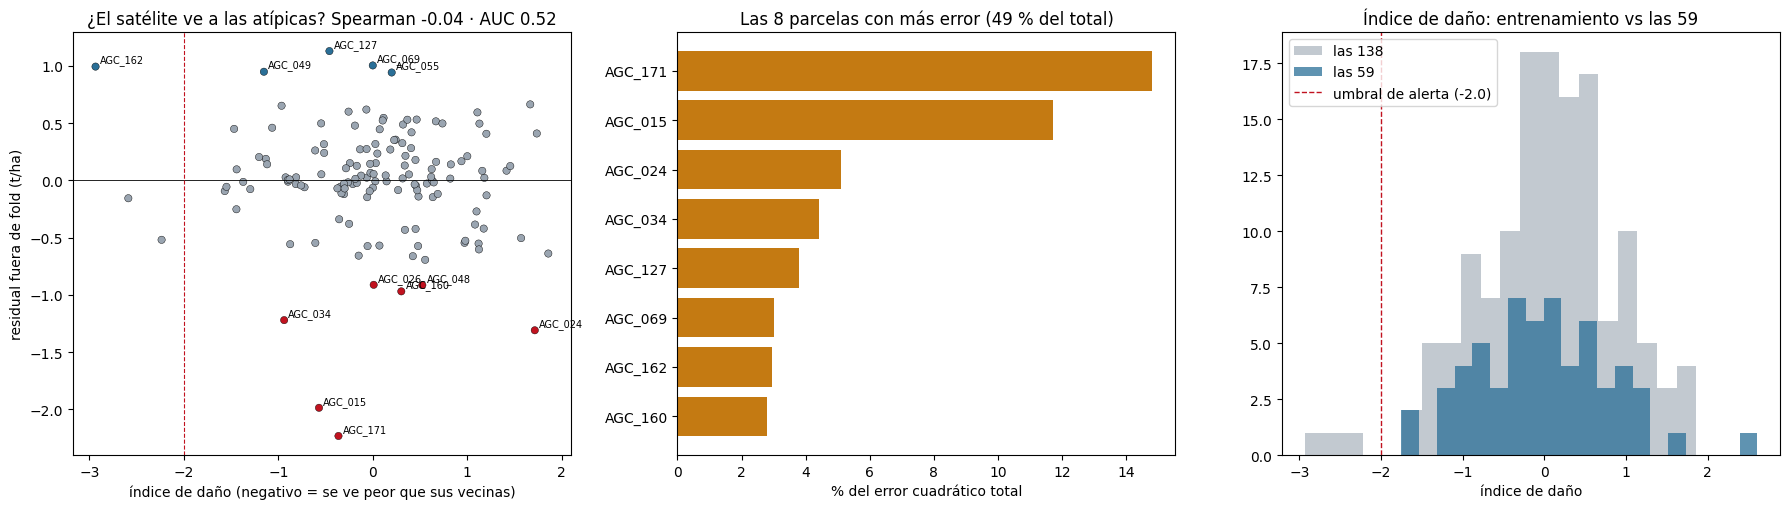

Guardado: atipicos_diagnostico.csv, alerta_dano_59.csv, atipicos_resumen.csv, figs/paso26_atipicos/26_atipicos.png (15 s)


In [83]:
# Paso 26 · ¿El satélite delata a las parcelas con errores grandes (siniestros)? Índice de daño contra las vecinas,
# AUC con permutación y ajuste por daño con validación anidada. NO cambia las 59.
# =====================================================================================
# PASO 26 · Parcelas atípicas: ¿el satélite detecta los siniestros?
# El paso 25 mostró que unas pocas parcelas concentran buena parte del error del ensamble. Aquí:
#   1. Se identifican las parcelas atípicas (error fuera de fold muy grande) y cuánto pesan en el RMSE.
#   2. Se mide cada parcela contra sus 12 vecinas más cercanas (de las 197; no usa rendimiento → sin fuga)
#      en 4 variables de vigor FIJADAS ANTES DE VER LOS RESULTADOS: pico de NDVI Planet, área bajo la curva
#      NDVI Planet, NDVI Planet ~30 días después del pico (llenado) y pico de NDVI Sentinel-2. Un daño
#      (helada, granizo, sequía, siembra fallida) debería bajar las cuatro. indice_dano = promedio de sus z
#      robustos; negativo = la parcela se ve peor que sus vecinas.
#   3. ¿El índice separa a las parcelas que rindieron MUCHO MENOS de lo predicho? (AUC con prueba de
#      permutación y Spearman contra el residual en las 138).
#   4. Ajuste por daño con validación anidada: ŷ + β·min(indice_dano − C, 0). β se aprende SOLO con residuales
#      fuera de fold internos del entrenamiento de cada fold; se califica en el fold externo con las mismas
#      particiones que el ensamble sin ajuste. Comparación pareada por parcela.
#   5. Alertas para las 59: parcelas cuyo satélite se ve claramente peor que sus vecinas.
# REGLA (fijada antes de ver el resultado): el ajuste solo se recomienda si (a) la AUC es significativa
# (permutación p < 0.05), (b) baja el RMSE en ≥ 80 % de las repeticiones y (c) por más de 0.005 t/ha en promedio.
# Aunque se cumpla, las 59 predicciones NO se cambian aquí: se documenta y se decide con el equipo.
# Tarda ~2 min.
# =====================================================================================
import time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
t0 = time.time()

BASE = Path(globals().get("BASE", Path.cwd()))
if "OUT" not in globals() or not (Path(OUT) / "base_maestra_v3.csv").exists():
    _hits = sorted(BASE.rglob("base_maestra_v3.csv"))
    assert _hits, "No encuentro base_maestra_v3.csv: corre antes los pasos 1 a 12."
    OUT = _hits[0].parent
OUT = Path(OUT)
RES = BASE / "resultados_I3"; RES.mkdir(exist_ok=True)
FIG26 = RES / "figs" / "paso26_atipicos"; FIG26.mkdir(parents=True, exist_ok=True)
K26 = 12                      # vecinas para comparar (mismo k que el modelo)
Z_ATIPICO = 2.5               # |residual| > 2.5 desviaciones robustas = parcela atípica
C_DANO = -2.0                 # el ajuste solo actúa si la parcela se ve > 2 desviaciones robustas peor que sus vecinas
REPS26 = 5
N_PERM = 999
VARS_DANO = ["pl_ndvi_pico", "pl_ndvi_auc", "pl_ndvi_post30", "s2_ndvi_pico"]
rng26 = np.random.default_rng(2026)

# ---------------------------------------------------------------- datos
b26 = pd.read_csv(OUT / "base_maestra_v3.csv").merge(
    pd.read_csv(OUT / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km"]], on="ID_POLIGONO", how="left")
VARS_DANO = [v for v in VARS_DANO if v in b26]
assert VARS_DANO, "No están las variables de vigor en base_maestra_v3.csv"
tr26 = b26[b26.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
pr26 = b26[b26.CONJUNTO == "PREDICCION"].reset_index(drop=True)
y26 = tr26.y.values.astype(float)
n26 = len(tr26)

# ---------------------------------------------------------------- 2. cada parcela contra sus 12 vecinas (sin rendimiento)
XYall = b26[["x_km", "y_km"]].values.astype(float)
Dall = cdist(XYall, XYall); np.fill_diagonal(Dall, np.inf)
vec_idx = np.argsort(Dall, 1)[:, :K26]
Z = pd.DataFrame({"ID_POLIGONO": b26.ID_POLIGONO})
for v in VARS_DANO:
    x = b26[v].values.astype(float)
    rel = x - np.nanmedian(x[vec_idx], 1)
    mad = 1.4826 * np.nanmedian(np.abs(rel - np.nanmedian(rel)))
    Z[f"z_{v}"] = rel / mad if mad > 0 else np.nan
zcols = [f"z_{v}" for v in VARS_DANO]
Z["indice_dano"] = Z[zcols].mean(1)
Z["vars_bajo_menos2"] = (Z[zcols] < -2).sum(1)
idx_dano = Z.set_index("ID_POLIGONO").indice_dano
print(f"Variables de vigor (fijadas de antemano): {VARS_DANO}")

# ---------------------------------------------------------------- 1. errores fuera de fold y parcelas atípicas
if ("OOF_ENS" in globals() and "trI3" in globals() and np.ndim(OOF_ENS) == 2
        and list(trI3.ID_POLIGONO) == list(tr26.ID_POLIGONO)):
    OOF26 = np.asarray(OOF_ENS, dtype=float); fuente = f"paso B ({OOF26.shape[0]} repeticiones)"
else:
    _p = pd.read_csv(RES / "predicciones.csv").set_index("ID_POLIGONO")
    OOF26 = _p.loc[tr26.ID_POLIGONO, "y_pred"].values.astype(float)[None, :]; fuente = "predicciones.csv (1 repetición; RESPALDO: solo si no se corrió el paso B en esta sesión)"
yhat26 = OOF26.mean(0)
e26 = y26 - yhat26                                   # residual medio por parcela (positivo = rindió más de lo predicho)
se2 = ((y26[None, :] - OOF26) ** 2).mean(0)          # error cuadrático medio por parcela
s_rob = 1.4826 * np.median(np.abs(e26 - np.median(e26)))
RMSE26 = float(np.sqrt(se2.mean()))
d = tr26[["ID_POLIGONO", "Municipio", "y"]].assign(y_pred=yhat26, residual=e26, residual_z=e26 / s_rob,
                                                   pct_error_cuadratico=100 * se2 / se2.sum())
d = d.merge(Z, on="ID_POLIGONO", how="left")
for extra, cols in [("banderas_calidad.csv", ["ID_POLIGONO", "bq_revisar", "bq_doble_joroba", "bq_pocas_imagenes"])]:
    if (OUT / extra).exists():
        d = d.merge(pd.read_csv(OUT / extra)[cols], on="ID_POLIGONO", how="left")
if "rend_redondo" in tr26:
    d["rend_redondo"] = tr26.rend_redondo.values
d["atipico"] = np.where(d.residual_z < -Z_ATIPICO, "rindió mucho MENOS", np.where(d.residual_z > Z_ATIPICO, "rindió mucho MÁS", ""))
at = d[d.atipico != ""].sort_values("pct_error_cuadratico", ascending=False)
sin_at = ~d.ID_POLIGONO.isin(at.ID_POLIGONO)
rmse_sin = float(np.sqrt(se2[sin_at.values].mean()))
print(f"\n1 · Ensamble, errores fuera de fold de {fuente}: RMSE {RMSE26:.4f} · desviación robusta del residual {s_rob:.4f}")
print(f"    Parcelas atípicas (|residual| > {Z_ATIPICO} desv. robustas): {len(at)} · concentran "
      f"{at.pct_error_cuadratico.sum():.1f} % del error cuadrático · RMSE sin ellas {rmse_sin:.4f}")
cols_show = ["ID_POLIGONO", "Municipio", "y", "y_pred", "residual", "pct_error_cuadratico", "atipico", "indice_dano",
             "vars_bajo_menos2"] + zcols + [c for c in ["rend_redondo", "bq_revisar"] if c in d]
print(at[cols_show].round(2).to_string(index=False))
top8 = d.sort_values("pct_error_cuadratico", ascending=False).head(8)
print(f"    Las 8 parcelas con más error aportan {top8.pct_error_cuadratico.sum():.1f} % del error cuadrático.")

# ---------------------------------------------------------------- 3. ¿el satélite separa a las que rindieron mucho menos?
print("\n3 · ¿El satélite las ve?")
lab = (d.residual_z < -Z_ATIPICO).values.astype(int)
score = -d.indice_dano.values                        # más alto = se ve peor que sus vecinas
ok = np.isfinite(score)
rho, p_rho = spearmanr(d.indice_dano[ok], d.residual[ok])
print(f"    Spearman(indice_dano, residual) en las 138: {rho:+.3f} (p = {p_rho:.3f}) · se espera positivo si el satélite ve el daño")
auc = p_auc = np.nan
if 0 < lab[ok].sum() < ok.sum():
    auc = roc_auc_score(lab[ok], score[ok])
    perm = np.array([roc_auc_score(rng26.permutation(lab[ok]), score[ok]) for _ in range(N_PERM)])
    p_auc = (1 + np.sum(perm >= auc)) / (N_PERM + 1)
    print(f"    AUC para detectar las {lab[ok].sum()} que rindieron mucho menos: {auc:.3f} (0.5 = azar, 1 = perfecto) · "
          f"permutación p = {p_auc:.3f}")
    for v in VARS_DANO:
        s_ = -d[f"z_{v}"].values; m_ = np.isfinite(s_)
        print(f"      {v:<16} AUC {roc_auc_score(lab[m_], s_[m_]):.3f}" if 0 < lab[m_].sum() < m_.sum() else f"      {v}: sin datos")
else:
    print("    No hay parcelas que rindieran mucho menos de lo predicho: no hay nada que detectar.")

# ---------------------------------------------------------------- 4. ajuste por daño con validación anidada
print(f"\n4 · Ajuste ŷ + β·min(indice_dano − ({C_DANO}), 0), β aprendido solo dentro de cada fold ({REPS26} × 5 folds)")
hinge = lambda ids: np.minimum(idx_dano.reindex(ids).fillna(0).values - C_DANO, 0)    # 0 si no se ve dañada
est26 = tr26.Municipio.where(tr26.Municipio.map(tr26.Municipio.value_counts()) >= 5, "Otros")
filas4, SE_base, SE_adj, betas = [], [], [], []
if "ModeloCebada360" not in globals():
    print("    (se omite: falta la clase ModeloCebada360; corre antes la celda de herramientas del Integrante 3)")
else:
    for s in range(REPS26):
        e_b, e_a = np.zeros(n26), np.zeros(n26)
        for a, b in StratifiedKFold(5, shuffle=True, random_state=3000 + s).split(tr26, est26):
            A = tr26.iloc[a].reset_index(drop=True)
            p_b = ModeloCebada360().fit(A).predict(tr26.iloc[b])
            # residuales fuera de fold DENTRO del entrenamiento externo (el fold b nunca se usa)
            est_a = A.Municipio.where(A.Municipio.map(A.Municipio.value_counts()) >= 5, "Otros")
            r_a = np.zeros(len(A))
            for ia, ib in StratifiedKFold(5, shuffle=True, random_state=s).split(A, est_a):
                r_a[ib] = A.y.values[ib] - ModeloCebada360().fit(A.iloc[ia]).predict(A.iloc[ib])
            h_a = hinge(A.ID_POLIGONO)
            beta = float(max((h_a @ r_a) / (h_a @ h_a), 0)) if (h_a != 0).sum() >= 2 else 0.0   # solo puede bajar la predicción
            betas.append(beta)
            e_b[b] = y26[b] - p_b
            e_a[b] = y26[b] - (p_b + beta * hinge(tr26.ID_POLIGONO.iloc[b]))
        SE_base.append(e_b ** 2); SE_adj.append(e_a ** 2)
        filas4.append({"repeticion": s, "RMSE_sin_ajuste": np.sqrt((e_b ** 2).mean()), "RMSE_con_ajuste": np.sqrt((e_a ** 2).mean())})
        print(f"    repetición {s + 1}/{REPS26} ({time.time() - t0:.0f} s)")
    rep4 = pd.DataFrame(filas4); rep4["mejora"] = rep4.RMSE_sin_ajuste - rep4.RMSE_con_ajuste
    SE_base, SE_adj = np.mean(SE_base, 0), np.mean(SE_adj, 0)        # un valor por parcela
    dif_bs = []
    for _ in range(2000):
        i = rng26.integers(0, n26, n26)
        dif_bs.append(np.sqrt(SE_base[i].mean()) - np.sqrt(SE_adj[i].mean()))
    ic4 = np.percentile(dif_bs, [5, 95])
    print(rep4.round(4).to_string(index=False))
    print(f"    β aprendidos: mediana {np.median(betas):.3f} · rango [{np.min(betas):.3f}, {np.max(betas):.3f}] · "
          f"parcelas con ajuste ≠ 0 (indice < {C_DANO}): {(idx_dano.reindex(tr26.ID_POLIGONO) < C_DANO).sum()} de {n26}")
    print(f"    Mejora pareada por parcela (bootstrap, P5-P95): [{ic4[0]:+.4f}, {ic4[1]:+.4f}] t/ha")

# ---------------------------------------------------------------- decisión
if not filas4:
    decision = "No se pudo evaluar el ajuste (falta ModeloCebada360). Solo se reportan las alertas."
elif (np.isfinite(p_auc) and p_auc < .05 and (rep4.mejora > 0).mean() >= .8 and rep4.mejora.mean() > .005):
    decision = (f"El satélite SÍ detecta parte de los siniestros (AUC {auc:.2f}, p {p_auc:.3f}) y el ajuste baja el RMSE "
                f"{rep4.mejora.mean():.4f} t/ha de forma consistente. Vale la pena discutir con el equipo aplicarlo a las alertas "
                f"de las 59; aquí NO se cambia ninguna predicción.")
else:
    razones = []
    if not (np.isfinite(p_auc) and p_auc < .05):
        razones.append(f"el índice de daño no separa a las parcelas que rindieron mucho menos (AUC {auc:.2f}, p {p_auc:.3f})")
    if rep4.mejora.mean() <= .005 or (rep4.mejora > 0).mean() < .8:
        razones.append(f"el ajuste no baja el RMSE de forma consistente (mejora media {rep4.mejora.mean():+.4f} t/ha, "
                       f"mejora en {(rep4.mejora > 0).sum()} de {len(rep4)} repeticiones)")
    decision = ("NO se recomienda ajustar: " + "; ".join(razones) + ". Esos errores grandes no se ven desde el satélite con "
                "estos datos: el modelo se queda como está y las alertas solo sirven como aviso en la app.")
print("\nDECISIÓN:", decision)

# ---------------------------------------------------------------- 5. alertas para las 59
al = pr26[["ID_POLIGONO", "Municipio"]].merge(Z, on="ID_POLIGONO", how="left")
_p = RES / "predicciones.csv"
if _p.exists():
    al = al.merge(pd.read_csv(_p)[["ID_POLIGONO", "y_pred"]], on="ID_POLIGONO", how="left")
al["alerta_dano_satelital"] = np.where(al.indice_dano < C_DANO, "sí", "no")
al = al.sort_values("indice_dano").round(3)
print(f"\n5 · Las 59: {int((al.alerta_dano_satelital == 'sí').sum())} se ven más de {abs(C_DANO):.0f} desviaciones robustas peor que sus vecinas")
_al_si = al[al.alerta_dano_satelital == "sí"][[c for c in ["ID_POLIGONO", "Municipio", "y_pred", "indice_dano", "vars_bajo_menos2"] + zcols if c in al]]
print(_al_si.to_string(index=False) if len(_al_si) else "    ninguna")
print("    Estas alertas NO cambian las predicciones; la app puede mostrarlas como 'revisar en campo'.")

# ---------------------------------------------------------------- salidas
d.round(4).to_csv(RES / "atipicos_diagnostico.csv", index=False)
al.to_csv(RES / "alerta_dano_59.csv", index=False)
pd.DataFrame([{"rmse_ensamble": RMSE26, "n_atipicos": len(at), "pct_error_atipicos": at.pct_error_cuadratico.sum(),
               "rmse_sin_atipicos": rmse_sin, "spearman_indice_residual": rho, "auc": auc, "p_auc": p_auc,
               "mejora_media_ajuste": rep4.mejora.mean() if filas4 else np.nan, "alertas_59": int((al.alerta_dano_satelital == "sí").sum()),
               "decision": decision}]).round(4).to_csv(RES / "atipicos_resumen.csv", index=False)

# ---------------------------------------------------------------- gráficas
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
c = np.where(d.residual_z < -Z_ATIPICO, "#c1121f", np.where(d.residual_z > Z_ATIPICO, "#2a6f97", "#9aa5b1"))
ax[0].scatter(d.indice_dano, d.residual, c=c, s=28, edgecolor="k", lw=.3)
for r in at.itertuples():
    ax[0].annotate(r.ID_POLIGONO, (r.indice_dano, r.residual), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].axhline(0, c="k", lw=.6); ax[0].axvline(C_DANO, c="#c1121f", ls="--", lw=.8)
ax[0].set_xlabel("índice de daño (negativo = se ve peor que sus vecinas)"); ax[0].set_ylabel("residual fuera de fold (t/ha)")
ax[0].set_title(f"¿El satélite ve a las atípicas? Spearman {rho:+.2f}" + (f" · AUC {auc:.2f}" if np.isfinite(auc) else ""))
ax[1].barh(top8.ID_POLIGONO[::-1], top8.pct_error_cuadratico[::-1], color="#c47a12")
ax[1].set_xlabel("% del error cuadrático total"); ax[1].set_title(f"Las 8 parcelas con más error ({top8.pct_error_cuadratico.sum():.0f} % del total)")
ax[2].hist(d.indice_dano.dropna(), bins=20, color="#9aa5b1", alpha=.6, label="las 138")
ax[2].hist(al.indice_dano.dropna(), bins=20, color="#2a6f97", alpha=.75, label="las 59")
ax[2].axvline(C_DANO, c="#c1121f", ls="--", lw=1, label=f"umbral de alerta ({C_DANO})")
ax[2].set_xlabel("índice de daño"); ax[2].legend(); ax[2].set_title("Índice de daño: entrenamiento vs las 59")
fig.tight_layout(); fig.savefig(FIG26 / "26_atipicos.png", dpi=150); plt.show()
print(f"Guardado: atipicos_diagnostico.csv, alerta_dano_59.csv, atipicos_resumen.csv, figs/paso26_atipicos/26_atipicos.png "
      f"({time.time() - t0:.0f} s)")


## Conclusión de los pasos 25 y 26 · ¿Se puede mejorar el modelo?
*Resultados de nuestra corrida de referencia con los datos reales. Ninguno de estos pasos cambia el modelo, los pesos ni las 59 predicciones.*

**1. Queda poca variación espacial que la ubicación pueda explicar (paso 25, diagnóstico exploratorio).**

| Estimación | t/ha |
|---|---|
| RMSE del ensamble (fuera de fold) | 0.494 |
| Ruido del GP dentro de municipio (50 folds: ~0.42–0.53) | 0.487 |
| Ruido del GP sobre rendimiento crudo | 0.493 |
| Pares de parcelas a menos de 0.5 km (sin modelo) | 0.409 |
| Nugget del semivariograma (intervalo demasiado ancho, no concluyente) | 0.339 |
| Componente atribuible al redondeo a 0.5 t/ha (45 de 138 parcelas) | 0.082 |

El ruido estimado por el GP (0.487) es casi igual al RMSE (0.494): es **compatible con una meseta** de los modelos basados en ubicación con estas variables, junto con la curva de aprendizaje (paso 28). **No es una cota inferior demostrada**: el ruido del GP depende del kernel y de la especificación, en simulaciones lo sobrestimó ~0.05 t/ha, y el nugget es demasiado incierto. Información nueva a nivel parcela podría reducir el error.

**2. El error restante lo concentran pocas parcelas que el satélite no ve (paso 26).**
- 12 parcelas (10 de ellas en Chignahuapan) concentran el **58.8 %** del error cuadrático; sin ellas el RMSE sería **0.33**.
- El índice de daño satelital (NDVI Planet y Sentinel-2 contra las 12 vecinas) **no las distingue**: AUC 0.52, permutación p = 0.44; Spearman con el residual −0.04 (p = 0.66).
- Hay casos al revés: AGC_162 es la que peor se ve contra sus vecinas y rindió más de lo esperado; AGC_024 se ve mejor y rindió menos.
- El ajuste por daño **empeora** el RMSE en las 5 repeticiones (−0.008 t/ha en promedio). Ninguna de las 59 tiene alerta de daño.

**3. Decisión.** Se conserva el **ENSAMBLE CEBADA360 v1** (Ridge + municipio + GP-RBF, pesos ⅓) y las 59 predicciones de `resultados_I3/ENTREGA/` sin cambios.

**4. Para el reporte.**
> El ensamble fue el mejor de los modelos evaluados con validación rigurosa (RMSE 0.494 t/ha en validación cruzada estratificada repetida; ≈0.500 en los folds externos de la validación anidada). Varios experimentos posteriores no dieron evidencia sólida de mejoras fuera de muestra, lo que es compatible con una meseta de desempeño con estas variables; no demuestra un error irreducible. El error restante lo concentran pocas parcelas, principalmente en Chignahuapan, cuyas diferencias no se observan en el vigor satelital ni en el clima (celdas de ~5 km, iguales para parcelas vecinas). Para mejorar la predicción no hace falta un modelo más complejo, sino información de campo por parcela: fecha de siembra y cosecha, variedad, fertilización, siniestros (helada en floración, granizo, acame) y pérdidas de cosecha.

**Limitaciones:** no se conocen los rendimientos de las 59; con 138 parcelas el RMSE estimado tiene incertidumbre (rango esperado en el paso 19); no se probaron todos los enfoques posibles (p. ej. modelos jerárquicos espaciales formales), aunque los diagnósticos sugieren que la ganancia sería pequeña. Los intervalos y escenarios de crédito son orientativos y dependen de sus supuestos. En la app el intervalo de Chignahuapan se amplía de forma precautoria (paso 27).

## Paso 27 · Intervalos de error por municipio para el crédito
El paso 26 mostró que el error **no es igual en todos los municipios**: 10 de las 12 parcelas atípicas son de Chignahuapan. El paso 24 usa un solo intervalo para todas las parcelas, así que en Chignahuapan promete más precisión de la que tiene.

1. **Error por municipio:** RMSE con IC bootstrap y prueba de Brown-Forsythe (¿la dispersión del error difiere?).
2. **Intervalo conservador:** un municipio con ≥ 20 parcelas de entrenamiento usa **sus** errores solo si su intervalo es **al menos 5 % más ancho** que el común **y** su RMSE es mayor; si no, se queda con el del paso 24. (Ajustamos esta regla porque la regla anterior ampliaba Calpulalpan por una diferencia de 0.0002 t/ha aunque su error es menor que el promedio.) Con los datos reales solo se amplía Chignahuapan, de forma precautoria: la diferencia no es estadísticamente significativa (Brown-Forsythe p = 0.136) y no cambia el nivel de riesgo de ninguna de las 59. El intervalo solo se ensancha donde el error es mayor y nunca se angosta (angostarlo con 20-30 parcelas daría más crédito con un intervalo poco confiable).
3. **Cobertura exploratoria:** del intervalo nominal 80 % dejando cada parcela fuera (su propio error no se usa ni para construir el intervalo ni para decidir la regla).
4. **Crédito recalculado** con las mismas reglas y supuestos del paso 24, más el escenario retrospectivo simulado en las 138.

*La cobertura se mide sobre las mismas 138 parcelas con que se construyen los intervalos: es exploratoria y no garantiza 80 % por municipio en parcelas nuevas. "Ingreso insuficiente simulado", no impago (ver nota del paso 24).*

**No cambia ninguna predicción, ni el paso 24, ni sus archivos.** Escribe `resultados_I4/credito_por_parcela_intervalo_municipio.csv` (la app puede usarlo en lugar de `credito_por_parcela.csv`), `error_por_municipio.csv`, `cobertura_intervalos_municipio.csv`, `retrospectiva_intervalo_municipio.csv` e `intervalos_por_municipio.png`. Requiere haber corrido el paso 24 en la misma sesión. Tarda ~10 s.

> **Sobre las fuentes de los supuestos de crédito (paso 24).** Los costos, el porcentaje financiado y los intereses provienen del reporte *Cebada TMF Hidalgo PV 2025* del sistema FIRA Agrocostos (ciclos cerrados). El precio de 7,500 MXN/t se tomó de notas de prensa de mayo de 2025 sobre los acuerdos de Grupo Modelo y Heineken con productores; una nota de *Excélsior* del 11-may-2026 reporta un acuerdo de 7,000 MXN/t con Grupo Modelo. Como el precio es el supuesto más incierto, el análisis de sensibilidad del paso 24 cubre precios entre 6,000 y 9,000 MXN/t.

**Cómo leer los resultados.**

La regla es asimétrica a propósito: el intervalo de un municipio solo se **ensancha** (cuando su error es claramente mayor) y nunca se angosta. Con 20-30 parcelas por municipio, un intervalo más angosto daría más crédito con una estimación de error poco confiable. En la corrida de referencia solo se amplió Chignahuapan, y como la diferencia no es estadísticamente significativa (Brown-Forsythe p = 0.136) se presenta como ampliación **precautoria**; ninguna de las 59 cambió de nivel de riesgo.

Municipios con intervalo propio (≥ 20 parcelas con dato): ['Calpulalpan', 'Chignahuapan']

1 · Error del ensamble por municipio (fuera de muestra):
                    Municipio  parcelas  RMSE  IC90_lo  IC90_hi  p10_error  p90_error
Nanacamilpa de Mariano Arista         1 0.797    0.797    0.797     -0.797     -0.797
                 Chignahuapan        71 0.582    0.451    0.707     -0.587      0.673
                   Tepeapulco         1 0.495    0.495    0.495      0.495      0.495
                  Singuilucan        16 0.490    0.306    0.652     -0.745      0.479
                  Calpulalpan        30 0.410    0.347    0.468     -0.596      0.554
                         Apan         1 0.370    0.370    0.370     -0.370     -0.370
        Cuautepec de Hinojosa         5 0.309    0.164    0.440     -0.085      0.455
                     Almoloya        10 0.193    0.081    0.273     -0.095      0.161
              Emiliano Zapata         3 0.142    0.133    0.151      0.132    

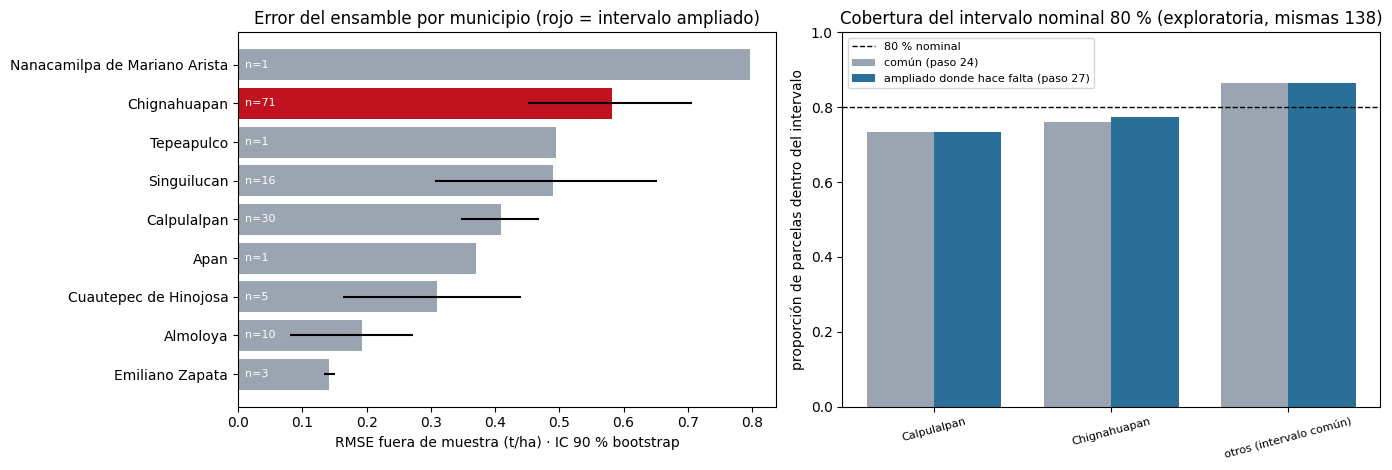


Guardado en resultados_I4/: credito_por_parcela_intervalo_municipio.csv, error_por_municipio.csv, cobertura_intervalos_municipio.csv, retrospectiva_intervalo_municipio.csv, intervalos_por_municipio.png
Las predicciones NO cambian; solo el margen de error y, con él, el crédito sugerido y el indicador exploratorio de riesgo.
La cobertura medida aquí es exploratoria (mismas 138 parcelas): no se garantiza 80 % por municipio en parcelas nuevas.


In [84]:
# Paso 27 · Intervalos por municipio (solo se ensanchan donde el error es claramente mayor) y crédito recalculado.
# Requiere el paso 24 en la misma sesión. NO cambia predicciones ni los archivos del paso 24.
# =====================================================================================
# PASO 27 · Intervalos de error por municipio para el crédito
# El paso 26 mostró que el error del ensamble NO es igual en todas partes: 10 de las 12 parcelas atípicas son de
# Chignahuapan. El paso 24 usa un solo intervalo (errores de las 138 juntas) para todas las parcelas.
# Aquí, SIN CAMBIAR NINGUNA PREDICCIÓN NI EL PASO 24:
#   1. ¿El error es distinto por municipio? RMSE por municipio con IC bootstrap y prueba de Brown-Forsythe.
#   2. Intervalos por municipio, CONSERVADORES: un municipio con ≥ MIN_N parcelas de entrenamiento usa SUS errores
#      solo si su intervalo es al menos 5 % MÁS ANCHO que el común y su RMSE es mayor; si no, se queda con el común del paso 24. Así el intervalo
#      solo se ensancha donde el error es mayor (p. ej. Chignahuapan) y nunca se angosta: angostarlo con ~20-30
#      parcelas daría más crédito con un intervalo poco confiable.
#   3. ¿Cubren mejor? Cobertura del intervalo al 80 % dejando cada parcela fuera (su propio error no se usa).
#   4. Crédito recalculado con esos intervalos y escenario retrospectivo SIMULADO en las 138, contra el paso 24.
#   La cobertura del punto 3 se mide sobre las mismas 138 parcelas: es exploratoria, no garantiza 80 % en parcelas nuevas.
# Salida: resultados_I4/credito_por_parcela_intervalo_municipio.csv (la app puede usarla en lugar de la del paso 24).
# Requiere haber corrido el paso 24 en esta sesión (usa su función calcular() y sus supuestos). Tarda ~10 s.
# =====================================================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

assert "calcular" in globals() and "FACTOR_PAGO" in globals(), "Corre antes el paso 24 (crédito y riesgo) en esta sesión."
BASE = Path(globals().get("BASE", Path.cwd()))
RES4 = BASE / "resultados_I4"; RES4.mkdir(exist_ok=True)
MIN_N = 20                     # parcelas de entrenamiento mínimas para que un municipio tenga su propio intervalo
rng27 = np.random.default_rng(2026)

# Se reconstruye desde los archivos (los pasos 25 y 26 reutilizan los nombres d y c del paso 24 en memoria)
OUT27 = BASE / "outputs"; RES3_27 = BASE / "resultados_I3"
d27 = (pd.read_csv(RES3_27 / "predicciones.csv")[["ID_POLIGONO", "CONJUNTO", "y_pred", "semaforo"]]
       .merge(pd.read_csv(OUT27 / "base_maestra_v3.csv")[["ID_POLIGONO", "Municipio", "Estado", "area_ha", "y"]], on="ID_POLIGONO")
       .merge(pd.read_csv(OUT27 / "senales_riesgo.csv")[["ID_POLIGONO", "riesgo_nivel", "riesgo_lluvia_cosecha_oct_pct"]], on="ID_POLIGONO", how="left")
       .merge(pd.read_csv(OUT27 / "banderas_calidad.csv")[["ID_POLIGONO", "bq_revisar"]], on="ID_POLIGONO", how="left"))
assert len(d27) == 197
c24 = pd.read_csv(RES4 / "credito_por_parcela.csv")   # resultado del paso 24, para comparar
tr27 = d27[d27.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
err27 = (tr27.y - tr27.y_pred).values                  # mismos errores fuera de muestra que el paso 24
cuenta = tr27.Municipio.value_counts()
PROPIOS = sorted(cuenta[cuenta >= MIN_N].index)
grupo = lambda m: m if m in PROPIOS else "otros (intervalo común)"
tr27["grupo"] = tr27.Municipio.map(grupo)
d27["grupo"] = d27.Municipio.map(grupo)
print(f"Municipios con intervalo propio (≥ {MIN_N} parcelas con dato): {PROPIOS}")

# ---------------------------------------------------------------- 1. ¿el error cambia por municipio?
filas = []
for m, g in tr27.groupby("Municipio"):
    e = (g.y - g.y_pred).values
    bs = [np.sqrt(np.mean(rng27.choice(e, len(e)) ** 2)) for _ in range(2000)]
    filas.append({"Municipio": m, "parcelas": len(e), "RMSE": np.sqrt(np.mean(e ** 2)), "IC90_lo": np.percentile(bs, 5),
                  "IC90_hi": np.percentile(bs, 95), "p10_error": np.quantile(e, .1), "p90_error": np.quantile(e, .9)})
por_mun = pd.DataFrame(filas).sort_values("RMSE", ascending=False).round(3)
print("\n1 · Error del ensamble por municipio (fuera de muestra):"); print(por_mun.to_string(index=False))
grupos_bf = [g.y.values - g.y_pred.values for _, g in tr27.groupby("grupo")]
if len(grupos_bf) >= 2:
    bf = stats.levene(*grupos_bf, center="median")
    print(f"   Brown-Forsythe (¿misma dispersión del error entre {', '.join(sorted(tr27.grupo.unique()))}?): "
          f"estadístico {bf.statistic:.2f} · p = {bf.pvalue:.4f}" + (" → la dispersión SÍ difiere" if bf.pvalue < .05 else " → no hay evidencia de diferencia"))

# ---------------------------------------------------------------- 2-3. cobertura dejando cada parcela fuera
ancho = lambda e: np.subtract(*np.quantile(e, [.9, .1]))


MARGEN_ANCHO = 1.05            # el intervalo propio debe ser al menos 5 % más ancho que el común


def elegir(e_grupo, e_comun):
    """Regla conservadora: los errores del municipio solo si su intervalo es CLARAMENTE más ancho que el común
    (≥ 5 %) Y su error típico (RMSE) es mayor. Evita que una diferencia mínima de cuantiles (p. ej. 0.0002 t/ha) cambie
    el intervalo de un municipio cuyo error en realidad es MENOR que el promedio."""
    rm = lambda e: np.sqrt(np.mean(np.square(e)))
    return e_grupo if (ancho(e_grupo) >= MARGEN_ANCHO * ancho(e_comun) and rm(e_grupo) > rm(e_comun)) else e_comun


def errores_de(i, por_grupo):
    """Errores para el intervalo de la parcela i de entrenamiento, SIN usar su propio error (también al decidir la regla)."""
    fuera = np.ones(len(tr27), bool); fuera[i] = False
    if not (por_grupo and tr27.grupo[i] in PROPIOS):
        return err27[fuera]
    return elegir(err27[fuera & (tr27.grupo == tr27.grupo[i]).values], err27[fuera])

cob = []
for i in range(len(tr27)):
    for etq, pg in [("común (paso 24)", False), ("ampliado donde hace falta (paso 27)", True)]:
        lo, hi = np.quantile(errores_de(i, pg), [.1, .9])
        cob.append({"grupo": tr27.grupo[i], "intervalo": etq, "cubre": lo <= err27[i] <= hi, "ancho": hi - lo})
cob = pd.DataFrame(cob)
tab_cob = cob.groupby(["grupo", "intervalo"]).agg(cobertura_80=("cubre", "mean"), ancho_medio_t_ha=("ancho", "mean"),
                                                   parcelas=("cubre", "size")).round(3)
tab_cob = pd.concat([tab_cob, cob.groupby("intervalo").agg(cobertura_80=("cubre", "mean"), ancho_medio_t_ha=("ancho", "mean"),
                     parcelas=("cubre", "size")).round(3).assign(grupo="TODAS").set_index("grupo", append=True).swaplevel()])
print("\n3 · Cobertura del intervalo al 80 % (cada parcela evaluada con un intervalo que NO usa su propio error):")
print(tab_cob.to_string())

# ---------------------------------------------------------------- 4. crédito con intervalos por municipio
partes = []
ENSANCHADOS = []
for gname, g in d27.groupby("grupo"):
    e_g = elegir(err27[(tr27.grupo == gname).values], err27) if gname in PROPIOS else err27
    if gname in PROPIOS and e_g is not err27: ENSANCHADOS.append(gname)
    partes.append(calcular(g, e_g))
print(f"\nIntervalo común (paso 24): {ancho(err27):.3f} t/ha de ancho al 80 %. Municipios con intervalo ampliado "
      f"(≥ {MARGEN_ANCHO:.2f}× y error mayor): {ENSANCHADOS or 'ninguno'} " + "; ".join(f"{m}: {ancho(err27[(tr27.grupo == m).values]):.3f}" for m in ENSANCHADOS))
for m in ENSANCHADOS:
    _x, _r = err27[(tr27.grupo == m).values], err27[(tr27.grupo != m).values]
    _p = stats.levene(_x, _r, center="median").pvalue
    print(f"   {m} contra el resto: Brown-Forsythe p = {_p:.3f}" + (" → diferencia significativa" if _p < .05 else
          " → NO significativa: la ampliación es PRECAUTORIA (el intervalo solo se ensancha, nunca se angosta)"))
c27 = pd.concat(partes).set_index("ID_POLIGONO").reindex(d27.ID_POLIGONO).reset_index()
c27 = d27[["ID_POLIGONO", "CONJUNTO", "Municipio", "Estado", "area_ha", "riesgo_nivel", "bq_revisar", "grupo"]].merge(c27, on="ID_POLIGONO")
motivo = []
for r in c27.itertuples():                              # mismas reglas que el paso 24
    m = []
    if r.prob_ingreso_insuficiente >= .5: m.append("rendimiento esperado bajo el necesario para pagar")
    elif r.prob_ingreso_insuficiente >= .2: m.append("probabilidad modelada relevante de que el ingreso no cubra el crédito")
    if r.bq_revisar == "revisar": m.append("dato satelital a revisar")
    if r.riesgo_nivel >= 1: m.append("señal de riesgo climático 2025")
    motivo.append("; ".join(m) if m else "sin alertas")
c27["motivo"] = motivo
c27["nivel_riesgo"] = np.select([(c27.prob_ingreso_insuficiente >= .5) | (c27.bq_revisar == "revisar"),
                                 (c27.prob_ingreso_insuficiente >= .2) | (c27.riesgo_nivel >= 1)], ["alto", "medio"], "bajo")
c27["semaforo_credito"] = c27.nivel_riesgo.map({"bajo": "verde", "medio": "amarillo", "alto": "rojo"})
c27["intervalo"] = np.where(c27.grupo.isin(ENSANCHADOS), "ampliado (error propio del municipio)", "común (138 parcelas, paso 24)")
c27 = c27.round({"rend_esperado": 3, "rend_lim_inf_80": 3, "rend_lim_sup_80": 3, "ingreso_esperado": 0, "ingreso_pesimista": 0,
                 "costo_produccion": 0, "credito_cuota_fira": 0, "pago_cuota_fira": 0, "credito_sugerido": 0, "pct_de_cuota_fira": 3,
                 "cobertura_pesimista": 3, "prob_ingreso_insuficiente": 3})
assert np.allclose(c27.set_index("ID_POLIGONO").rend_esperado.reindex(c24.ID_POLIGONO).values, c24.rend_esperado.values), \
    "La predicción cambió: no debería pasar"
c27.sort_values("ID_POLIGONO").to_csv(RES4 / "credito_por_parcela_intervalo_municipio.csv", index=False, encoding="utf-8-sig")

cmp = c24[["ID_POLIGONO", "CONJUNTO", "Municipio", "rend_lim_inf_80", "credito_sugerido", "nivel_riesgo"]].merge(
    c27[["ID_POLIGONO", "rend_lim_inf_80", "credito_sugerido", "nivel_riesgo"]], on="ID_POLIGONO", suffixes=("_p24", "_p27"))
p59 = cmp[cmp.CONJUNTO == "PREDICCION"]
print("\n4 · Las 59 a calificar (la predicción es la misma; solo cambia el intervalo):")
print(p59.groupby("Municipio").agg(parcelas=("ID_POLIGONO", "size"), lim_inf_p24=("rend_lim_inf_80_p24", "mean"),
      lim_inf_p27=("rend_lim_inf_80_p27", "mean"), credito_p24=("credito_sugerido_p24", "sum"),
      credito_p27=("credito_sugerido_p27", "sum")).round(2).to_string())
camb = p59[p59.nivel_riesgo_p24 != p59.nivel_riesgo_p27]
print(f"   Parcelas que cambian de nivel de riesgo: {len(camb)}")
if len(camb):
    print(camb[["ID_POLIGONO", "Municipio", "nivel_riesgo_p24", "nivel_riesgo_p27"]].to_string(index=False))

# ---------------------------------------------------------------- escenario retrospectivo simulado (138, sin usar el error propio)
def retro(por_grupo):
    filas = []
    for i in range(len(tr27)):
        o = calcular(tr27.iloc[[i]], errores_de(i, por_grupo)).iloc[0]
        ing = tr27.y[i] * tr27.area_ha[i] * PRECIO
        filas.append({"grupo": tr27.grupo[i], "credito": o.credito_sugerido, "ingreso_insuficiente": ing < o.credito_sugerido * FACTOR_PAGO,
                      "brecha": max(0, o.credito_sugerido * FACTOR_PAGO - ing)})
    return pd.DataFrame(filas)

r24, r27 = retro(False), retro(True)
resumen_r = pd.DataFrame([{"regla": n, "parcelas_ingreso_insuficiente": int(r.ingreso_insuficiente.sum()), "pct_ingreso_insuficiente": round(100 * r.ingreso_insuficiente.mean(), 1),
                           "credito_colocado_mxn": round(r.credito.sum()), "brecha_cobertura_simulada_mxn": round(r.brecha.sum()),
                           "pct_brecha_simulada": round(100 * r.brecha.sum() / r.credito.sum(), 2)}
                          for n, r in [("Intervalo común (paso 24)", r24), ("Intervalo ampliado donde hace falta (paso 27)", r27)]])
print("\nEscenario retrospectivo simulado en las 138 (ingreso insuficiente simulado, no impago real):"); print(resumen_r.to_string(index=False))
por_g = pd.concat([r24.groupby("grupo").agg(insuf_p24=("ingreso_insuficiente", "sum"), credito_p24=("credito", "sum")),
                   r27.groupby("grupo").agg(insuf_p27=("ingreso_insuficiente", "sum"), credito_p27=("credito", "sum"))], axis=1).round(0)
print(por_g.to_string())
por_mun.to_csv(RES4 / "error_por_municipio.csv", index=False)
tab_cob.reset_index().to_csv(RES4 / "cobertura_intervalos_municipio.csv", index=False)
resumen_r.to_csv(RES4 / "retrospectiva_intervalo_municipio.csv", index=False)

# ---------------------------------------------------------------- gráfica
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
pm = por_mun.sort_values("RMSE")
ax[0].barh(pm.Municipio, pm.RMSE, xerr=[pm.RMSE - pm.IC90_lo, pm.IC90_hi - pm.RMSE],
           color=["#c1121f" if m in ENSANCHADOS else "#9aa5b1" for m in pm.Municipio])
for i, (v, n) in enumerate(zip(pm.RMSE, pm.parcelas)):
    ax[0].text(0.01, i, f"n={n}", va="center", fontsize=8, color="w")
ax[0].set_xlabel("RMSE fuera de muestra (t/ha) · IC 90 % bootstrap"); ax[0].set_title("Error del ensamble por municipio (rojo = intervalo ampliado)")
tc = tab_cob.reset_index()
tc = tc[tc.grupo != "TODAS"]
gs = list(dict.fromkeys(tc.grupo)); x = np.arange(len(gs))
for k, (etq, col) in enumerate([("común (paso 24)", "#9aa5b1"), ("ampliado donde hace falta (paso 27)", "#2a6f97")]):
    v = tc[tc.intervalo == etq].set_index("grupo").cobertura_80.reindex(gs)
    ax[1].bar(x + (k - .5) * .38, v, .38, label=etq, color=col)
ax[1].axhline(.8, c="k", ls="--", lw=1, label="80 % nominal")
ax[1].set_xticks(x); ax[1].set_xticklabels(gs, fontsize=8, rotation=15); ax[1].set_ylim(0, 1)
ax[1].set_ylabel("proporción de parcelas dentro del intervalo"); ax[1].legend(fontsize=8); ax[1].set_title("Cobertura del intervalo nominal 80 % (exploratoria, mismas 138)")
fig.tight_layout(); fig.savefig(RES4 / "intervalos_por_municipio.png", dpi=150); plt.show()
print("\nGuardado en resultados_I4/: credito_por_parcela_intervalo_municipio.csv, error_por_municipio.csv, "
      "cobertura_intervalos_municipio.csv, retrospectiva_intervalo_municipio.csv, intervalos_por_municipio.png")
print("Las predicciones NO cambian; solo el margen de error y, con él, el crédito sugerido y el indicador exploratorio de riesgo.")
print("La cobertura medida aquí es exploratoria (mismas 138 parcelas): no se garantiza 80 % por municipio en parcelas nuevas.")


## Paso 28 · Curva de aprendizaje: ¿más parcelas bajarían el error?
Si tuviéramos más parcelas con rendimiento, ¿el ensamble seguiría mejorando o ya está en una **meseta** con estas variables? Este paso **no demuestra un error irreducible**: describe la tendencia del error con los datos disponibles.

- **Mismo fold de evaluación para todos los tamaños** (5 folds × 5 repeticiones, estratificada por municipio), así las curvas se comparan parcela por parcela.
- Dentro del entrenamiento de cada fold se usan submuestras de **30, 50, 70 y 90** parcelas (5 submuestras estratificadas por municipio) y el entrenamiento completo (~110). El ensamble se **reentrena desde cero** en cada submuestra: vecinas, promedio municipal, imputación, escalamiento, Ridge y GP solo con esa submuestra (sin fuga).
- **Incertidumbre:** bootstrap por parcela (un valor por parcela; las repeticiones no cuentan como independientes) y, como contraste, bootstrap por 15 bloques espaciales.
- **Parcelas atípicas del paso 26:** ¿su error baja con más datos?
- **Extrapolación exploratoria** con una ley de potencia inversa, MSE(n) = a + b·n^(−c), con intervalo bootstrap. Solo orienta; no es la base de la conclusión.

**Regla de conclusión, fijada antes de ver el resultado** (Δ = RMSE(90) − RMSE(completo), IC 90 % pareado por parcela; cuenta el tamaño de la ganancia, no solo si es distinta de cero):
- **A · compatible con una meseta:** el límite superior del IC de Δ es < 0.02 t/ha y la curva sí bajó entre 30 y 70 parcelas.
- **B · margen de mejora:** el IC de Δ queda por encima de 0 y puede llegar a ≥ 0.02 t/ha.
- **C · evidencia insuficiente:** cualquier otro caso.

**No cambia el modelo, los pesos ni las 59 predicciones.** Tarda ~3-5 min. Salidas: `curva_aprendizaje.csv`, `curva_aprendizaje_tramos.csv`, `curva_aprendizaje_atipicas.csv`, `curva_aprendizaje_resumen.csv`, `figs/paso28_curva_aprendizaje/28_curva_aprendizaje.png`.

**Cómo leer los resultados.**

Una curva de aprendizaje muestra cómo baja el error de validación al aumentar el tamaño del entrenamiento. Si sigue bajando con fuerza al final, conseguir más parcelas ayudaría; si se aplana, estamos en rendimientos decrecientes con estas variables. Lo importante es que el fold de evaluación es el mismo para todos los tamaños, así que las diferencias se comparan parcela por parcela. La conclusión (A, B o C) la imprime la celda con la regla fijada de antemano; la extrapolación con ley de potencia es solo orientativa. Los resultados numéricos de este paso no están en este archivo (se guardó sin salidas): al ejecutar se imprimen y quedan en `curva_aprendizaje_resumen.csv`.

  repetición 1/5 (9 s)
  repetición 2/5 (16 s)
  repetición 3/5 (25 s)
  repetición 4/5 (32 s)
  repetición 5/5 (41 s)

1 · Curva de aprendizaje del ensamble (mismo fold de evaluación para todos los tamaños):
tamano_entrenamiento  n_medio  RMSE_validacion  IC90_parcelas_lo  IC90_parcelas_hi  IC90_bloques_lo  IC90_bloques_hi  desv_entre_repeticiones  RMSE_entrenamiento  R2_validacion
                  30     30.0           0.5199            0.4404            0.5981           0.4416           0.5679                   0.0106              0.4472         0.6242
                  50     50.0           0.5068            0.4246            0.5874           0.4279           0.5537                   0.0049              0.4540         0.6428
                  70     70.0           0.5019            0.4202            0.5810           0.4229           0.5491                   0.0061              0.4714         0.6498
                  90     90.0           0.4961            0.4142            0.5764 

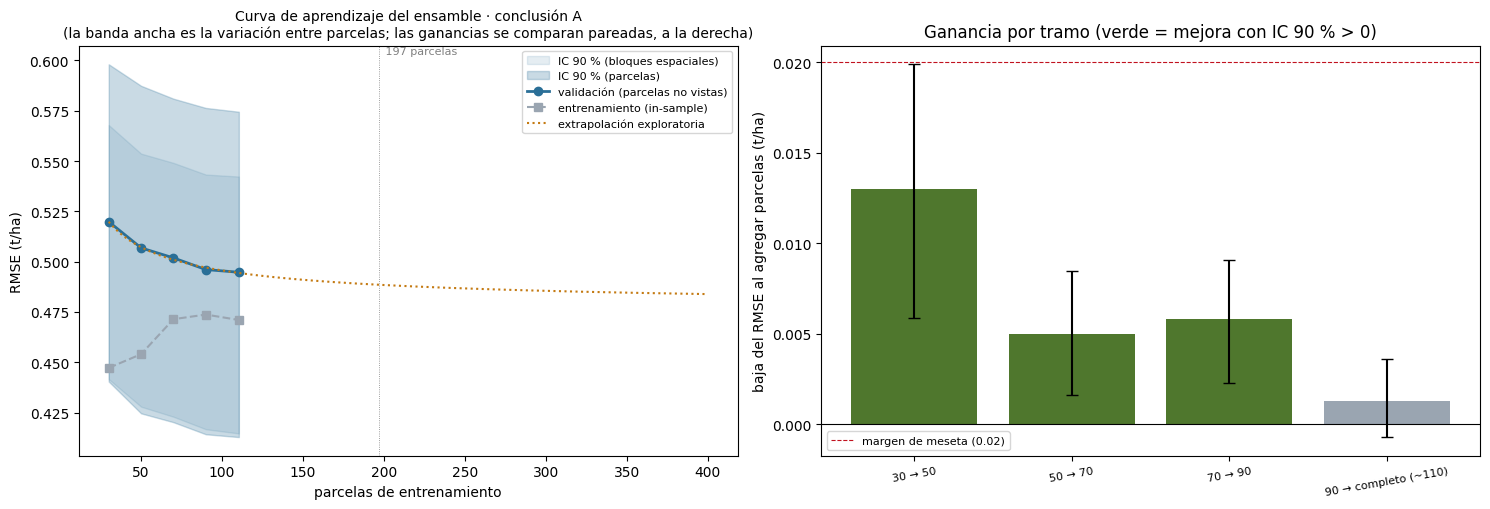

Guardado: curva_aprendizaje.csv, curva_aprendizaje_tramos.csv, curva_aprendizaje_resumen.csv, curva_aprendizaje_atipicas.csv, figs/paso28_curva_aprendizaje/ (52 s)


In [85]:
# Paso 28 · Curva de aprendizaje del ensamble (30, 50, 70, 90 y ~110 parcelas), reentrenando desde cero en cada
# submuestra (sin fuga). Regla de conclusión fijada antes de ver el resultado. NO cambia el modelo ni las 59.
# =====================================================================================
# PASO 28 · Curva de aprendizaje: ¿más parcelas bajarían el error?
# Pregunta: si tuviéramos más parcelas con rendimiento, ¿el ensamble seguiría mejorando o ya está en una meseta
# con estas variables? (No demuestra un "error irreducible": solo describe la tendencia con los datos disponibles.)
#   1. Validación externa repetida (5 folds × REPS28, estratificada por municipio). El fold de evaluación es el MISMO
#      para todos los tamaños, así las curvas son comparables parcela por parcela.
#   2. Dentro del entrenamiento de cada fold se toman submuestras de 30, 50, 70 y 90 parcelas (SEMILLAS28 submuestras
#      distintas, estratificadas por municipio) y el entrenamiento completo (~110). El ensamble se reentrena DESDE CERO
#      en cada submuestra: vecinas, promedio municipal, imputación, escalamiento, Ridge y GP solo con esa submuestra.
#   3. Incertidumbre: bootstrap por parcela (un valor por parcela, promediando repeticiones; las repeticiones no
#      cuentan como independientes) y bootstrap por bloques espaciales (15 grupos k-means) como contraste.
#   4. Clave: ganancia del último tramo, RMSE(90) − RMSE(completo), con intervalo.
#   5. Errores de las parcelas atípicas del paso 26 según el tamaño del entrenamiento.
#   6. Extrapolación EXPLORATORIA con una ley de potencia inversa, MSE(n) = a + b·n^(−c) (forma estándar de curvas de
#      aprendizaje), con intervalo bootstrap. Solo orienta; no es la base de la conclusión.
# REGLA DE CONCLUSIÓN (fijada antes de ver el resultado), con Δ = RMSE(90) − RMSE(completo) e IC 90 % por parcela.
# Cuenta el TAMAÑO de la ganancia, no solo si es distinta de 0 (con comparaciones pareadas, ganancias diminutas salen
# "significativas"):
#   A · compatible con meseta:  el límite superior del IC de Δ es < 0.02 t/ha Y la curva sí bajó antes (30 → 70):
#                               las últimas ~20 parcelas aportan, como mucho, una mejora pequeña (rendimientos decrecientes).
#   B · margen de mejora:      el IC de Δ queda por encima de 0 Y su límite superior llega a ≥ 0.02 t/ha.
#   C · evidencia insuficiente: cualquier otro caso.
# NO cambia el modelo, los pesos ni las 59 predicciones. Tarda ~3-5 min.
# =====================================================================================
import time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import curve_fit
from sklearn.model_selection import StratifiedKFold
from sklearn.cluster import KMeans
t0 = time.time()

assert "ModeloCebada360" in globals(), "Corre antes la celda de herramientas del Integrante 3 (define ModeloCebada360)."
BASE = Path(globals().get("BASE", Path.cwd()))
if "OUT" not in globals() or not (Path(OUT) / "base_maestra_v3.csv").exists():
    _hits = sorted(BASE.rglob("base_maestra_v3.csv"))
    assert _hits, "No encuentro base_maestra_v3.csv: corre antes los pasos 1 a 12."
    OUT = _hits[0].parent
OUT = Path(OUT)
RES = BASE / "resultados_I3"; RES.mkdir(exist_ok=True)
FIG28 = RES / "figs" / "paso28_curva_aprendizaje"; FIG28.mkdir(parents=True, exist_ok=True)
REPS28 = 5
SEMILLAS28 = 5
TAMANOS = [30, 50, 70, 90]          # + el entrenamiento completo de cada fold
MARGEN_MESETA = 0.02                # t/ha: una ganancia menor que esto en el último tramo se considera meseta
B_BOOT28 = 2000
rng28 = np.random.default_rng(2026)

b28 = pd.read_csv(OUT / "base_maestra_v3.csv").merge(
    pd.read_csv(OUT / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km"]], on="ID_POLIGONO", how="left")
tr28 = b28[b28.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
y28 = tr28.y.values.astype(float); n28 = len(tr28)
EST28 = tr28.Municipio.where(tr28.Municipio.map(tr28.Municipio.value_counts()) >= 5, "Otros").values


def submuestra(idx, n, semilla):
    """n parcelas de idx, estratificadas por municipio (asignación proporcional, al menos 1 por estrato si cabe)."""
    if n >= len(idx):
        return idx
    r = np.random.default_rng(semilla)
    est = pd.Series(EST28[idx], index=idx)
    cuota = (est.value_counts() / len(idx) * n)
    k = np.floor(cuota).astype(int).clip(lower=1)
    while k.sum() > n: k[k.idxmax()] -= 1
    resto = (cuota - np.floor(cuota)).sort_values(ascending=False)
    for e in resto.index:
        if k.sum() >= n: break
        if k[e] < (est == e).sum(): k[e] += 1
    elegidos = [r.choice(est.index[est == e], min(k[e], (est == e).sum()), replace=False) for e in k.index if k[e] > 0]
    return np.concatenate(elegidos)


# ---------------------------------------------------------------- 1-2. curvas
SE = {}                               # (tamaño) -> matriz reps × parcelas con el error cuadrático de validación (NaN si no tocó)
TRAIN = {}                            # (tamaño) -> lista de RMSE en el propio entrenamiento
n_full = []
for s in range(REPS28):
    for a, b in StratifiedKFold(5, shuffle=True, random_state=4000 + s).split(tr28, EST28):
        n_full.append(len(a))
        for n in TAMANOS + ["completo"]:
            semillas = [0] if n == "completo" else range(SEMILLAS28)
            se_b, rm_tr = [], []
            for m in semillas:
                sub = a if n == "completo" else submuestra(a, n, 10_000 * s + 100 * m + (n if n != "completo" else 0))
                mod = ModeloCebada360().fit(tr28.iloc[sub])
                se_b.append((y28[b] - mod.predict(tr28.iloc[b])) ** 2)
                rm_tr.append(np.sqrt(np.mean((y28[sub] - mod.predict(tr28.iloc[sub])) ** 2)))
            SE.setdefault(n, np.full((REPS28, n28), np.nan))[s, b] = np.mean(se_b, 0)   # promedio sobre submuestras
            TRAIN.setdefault(n, []).extend(rm_tr)
    print(f"  repetición {s + 1}/{REPS28} ({time.time() - t0:.0f} s)")
ETQ = [str(n) for n in TAMANOS] + [f"completo (~{int(np.mean(n_full))})"]
NS = TAMANOS + [float(np.mean(n_full))]
claves = TAMANOS + ["completo"]
# un valor por parcela: error cuadrático medio sobre repeticiones
P = np.vstack([np.nanmean(SE[k], 0) for k in claves])            # tamaños × parcelas
rmse = np.sqrt(P.mean(1))
rmse_rep = np.array([[np.sqrt(np.nanmean(SE[k][s])) for s in range(REPS28)] for k in claves])

# ---------------------------------------------------------------- 3. incertidumbre
boot_p = np.array([np.sqrt(P[:, i].mean(1)) for i in (rng28.integers(0, n28, n28) for _ in range(B_BOOT28))])
grupos = KMeans(15, n_init=10, random_state=0).fit(tr28[["x_km", "y_km"]].values).labels_
gid = [np.where(grupos == g)[0] for g in range(15)]
boot_g = []
for _ in range(B_BOOT28):
    i = np.concatenate([gid[g] for g in rng28.integers(0, 15, 15)])
    boot_g.append(np.sqrt(P[:, i].mean(1)))
boot_g = np.array(boot_g)
curva = pd.DataFrame({"tamano_entrenamiento": ETQ, "n_medio": np.round(NS, 1), "RMSE_validacion": rmse,
                      "IC90_parcelas_lo": np.percentile(boot_p, 5, 0), "IC90_parcelas_hi": np.percentile(boot_p, 95, 0),
                      "IC90_bloques_lo": np.percentile(boot_g, 5, 0), "IC90_bloques_hi": np.percentile(boot_g, 95, 0),
                      "desv_entre_repeticiones": rmse_rep.std(1),
                      "RMSE_entrenamiento": [np.mean(TRAIN[k]) for k in claves],
                      "R2_validacion": 1 - P.mean(1) / y28.var()}).round(4)
print("\n1 · Curva de aprendizaje del ensamble (mismo fold de evaluación para todos los tamaños):")
print(curva.to_string(index=False))

# ---------------------------------------------------------------- 4. ganancias por tramo (pareadas por parcela)
def delta(i, j, boot):
    d = boot[:, i] - boot[:, j]
    return rmse[i] - rmse[j], np.percentile(d, 5), np.percentile(d, 95)

tramos = []
for i in range(len(claves) - 1):
    dp, lo_p, hi_p = delta(i, i + 1, boot_p); _, lo_g, hi_g = delta(i, i + 1, boot_g)
    tramos.append({"tramo": f"{ETQ[i]} → {ETQ[i + 1]}", "parcelas_agregadas": round(NS[i + 1] - NS[i], 1), "ganancia_RMSE": dp,
                   "IC90_parcelas": f"[{lo_p:+.4f}, {hi_p:+.4f}]", "IC90_bloques": f"[{lo_g:+.4f}, {hi_g:+.4f}]",
                   "ganancia_por_10_parcelas": dp / (NS[i + 1] - NS[i]) * 10})
tramos = pd.DataFrame(tramos).round(4)
print("\n4 · Cuánto baja el error al agregar parcelas (positivo = mejora):"); print(tramos.to_string(index=False))
i90, ifull, i30, i70 = claves.index(90), len(claves) - 1, claves.index(30), claves.index(70)
d_last, lo_last, hi_last = delta(i90, ifull, boot_p)
d_early, lo_early, hi_early = delta(i30, i70, boot_p)
_, lo_last_g, hi_last_g = delta(i90, ifull, boot_g)

# ---------------------------------------------------------------- 5. parcelas atípicas del paso 26
_at = RES / "atipicos_diagnostico.csv"
if _at.exists():
    at_ids = set(pd.read_csv(_at).query("atipico == atipico and atipico != ''").ID_POLIGONO)
    es_at = tr28.ID_POLIGONO.isin(at_ids).values
    atip = pd.DataFrame({"tamano": ETQ, "RMSE_atipicas": np.sqrt(P[:, es_at].mean(1)), "RMSE_resto": np.sqrt(P[:, ~es_at].mean(1)),
                         "pct_error_atipicas": 100 * P[:, es_at].sum(1) / P.sum(1)}).round(4)
    print(f"\n5 · Las {es_at.sum()} parcelas atípicas del paso 26 según el tamaño del entrenamiento:"); print(atip.to_string(index=False))
else:
    atip, es_at = None, None
    print("\n5 · (no está atipicos_diagnostico.csv del paso 26: se omite)")

# ---------------------------------------------------------------- 6. extrapolación exploratoria
def ley(n, a, b_, c):
    return a + b_ * n ** (-c)

def ajustar(mse):
    try:
        p, _ = curve_fit(ley, NS, mse, p0=[mse[-1] * .9, (mse[0] - mse[-1]) * 30 ** .5, .5],
                         bounds=([0, 0, .05], [np.inf, np.inf, 3]), maxfev=20000)
        return p
    except Exception:
        return None

p_ley = ajustar(rmse ** 2)
ext = []
for _ in range(500):
    i = rng28.integers(0, n28, n28); p_ = ajustar(P[:, i].mean(1))
    if p_ is not None: ext.append([np.sqrt(p_[0]), np.sqrt(ley(197, *p_)), np.sqrt(ley(400, *p_))])
ext = np.array(ext)
if p_ley is not None and len(ext) > 100:
    asin, r197, r400 = np.sqrt(p_ley[0]), np.sqrt(ley(197, *p_ley)), np.sqrt(ley(400, *p_ley))
    print(f"\n6 · Extrapolación EXPLORATORIA (MSE = a + b·n^-c, c = {p_ley[2]:.2f}):")
    for etq_, v, k in [("asíntota (n → ∞)", asin, 0), ("con 197 parcelas", r197, 1), ("con 400 parcelas", r400, 2)]:
        print(f"    RMSE {etq_:<18} {v:.3f} · IC90 bootstrap [{np.percentile(ext[:, k], 5):.3f}, {np.percentile(ext[:, k], 95):.3f}] "
              f"({len(ext)} ajustes válidos)")
    print("    Ojo: son 5 puntos con ruido; la asíntota depende mucho de la forma supuesta. No es una medida del error irreducible.")
else:
    asin = r197 = r400 = np.nan
    print("\n6 · La ley de potencia no se pudo ajustar de forma estable: no se extrapola.")

# ---------------------------------------------------------------- conclusión con la regla fijada arriba
bajo_antes = lo_early > 0
if hi_last < MARGEN_MESETA and bajo_antes:
    concl = "A"
    extra = (f" La ganancia que queda es real pero pequeña (~{d_last / (NS[-1] - NS[i90]) * 10:.4f} t/ha por cada 10 parcelas)."
             if lo_last > 0 else " La ganancia del último tramo no se distingue de cero.")
    texto = (f"A · COMPATIBLE CON UNA MESETA: el error sí bajó al pasar de 30 a 70 parcelas ({d_early:+.4f} t/ha, IC90 "
             f"[{lo_early:+.4f}, {hi_early:+.4f}]), pero el último tramo (90 → ~{NS[-1]:.0f}) aporta {d_last:+.4f} t/ha "
             f"(IC90 [{lo_last:+.4f}, {hi_last:+.4f}]), menos de {MARGEN_MESETA} t/ha.{extra} Agregar parcelas da rendimientos "
             f"decrecientes con estas variables y este modelo. NO demuestra un error irreducible: variables nuevas (manejo, "
             f"siniestros) podrían bajarlo.")
elif lo_last > 0:
    concl = "B"
    texto = (f"B · MARGEN DE MEJORA: pasar de 90 a ~{NS[-1]:.0f} parcelas todavía baja el RMSE {d_last:+.4f} t/ha "
             f"(IC90 [{lo_last:+.4f}, {hi_last:+.4f}]) y la ganancia podría ser de {MARGEN_MESETA} t/ha o más. Con más parcelas "
             f"etiquetadas el error probablemente seguiría bajando.")
else:
    concl = "C"
    texto = (f"C · EVIDENCIA INSUFICIENTE: el último tramo da {d_last:+.4f} t/ha con IC90 [{lo_last:+.4f}, {hi_last:+.4f}] "
             f"(30 → 70: {d_early:+.4f}, IC90 [{lo_early:+.4f}, {hi_early:+.4f}]). Con 138 parcelas no se puede distinguir "
             f"entre una meseta y una mejora pequeña pero real.")
if np.isfinite(r197):
    texto += (f" Orientativo (extrapolación exploratoria, NO validada): con 197 parcelas el RMSE rondaría {r197:.3f} "
              f"(IC90 [{np.percentile(ext[:, 1], 5):.3f}, {np.percentile(ext[:, 1], 95):.3f}]).")
if atip is not None:
    rel_at = 1 - atip.RMSE_atipicas.iloc[-1] / atip.RMSE_atipicas.iloc[0]        # baja proporcional de 30 a completo
    rel_re = 1 - atip.RMSE_resto.iloc[-1] / atip.RMSE_resto.iloc[0]
    texto += (f" De 30 a ~{NS[-1]:.0f} parcelas, el RMSE de las atípicas baja {100 * rel_at:.1f} % y el del resto {100 * rel_re:.1f} %"
              + (": las atípicas mejoran proporcionalmente mucho menos, así que su error no se debe principalmente a falta de "
                 "entrenamiento." if rel_at < rel_re / 2 else ": mejoran a un ritmo parecido."))
print(f"\nCONCLUSIÓN ({concl}): {texto}")
print(f"Contraste con bootstrap por bloques espaciales, último tramo: IC90 [{lo_last_g:+.4f}, {hi_last_g:+.4f}]")
print("Este paso NO cambia el modelo, los pesos ni las 59 predicciones.")

# ---------------------------------------------------------------- salidas
curva.to_csv(RES / "curva_aprendizaje.csv", index=False)
tramos.to_csv(RES / "curva_aprendizaje_tramos.csv", index=False)
if atip is not None: atip.to_csv(RES / "curva_aprendizaje_atipicas.csv", index=False)
pd.DataFrame([{"conclusion": concl, "texto": texto, "ganancia_ultimo_tramo": d_last, "IC90_lo": lo_last, "IC90_hi": hi_last,
               "IC90_bloques_lo": lo_last_g, "IC90_bloques_hi": hi_last_g, "ganancia_30_70": d_early,
               "rmse_asintota_exploratoria": asin, "rmse_197_exploratorio": r197, "rmse_400_exploratorio": r400}]).round(4) \
    .to_csv(RES / "curva_aprendizaje_resumen.csv", index=False)

# ---------------------------------------------------------------- gráfica
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
a0 = ax[0]
a0.fill_between(NS, curva.IC90_bloques_lo, curva.IC90_bloques_hi, color="#2a6f97", alpha=.12, label="IC 90 % (bloques espaciales)")
a0.fill_between(NS, curva.IC90_parcelas_lo, curva.IC90_parcelas_hi, color="#2a6f97", alpha=.25, label="IC 90 % (parcelas)")
a0.plot(NS, rmse, "o-", c="#2a6f97", lw=2, label="validación (parcelas no vistas)")
a0.plot(NS, curva.RMSE_entrenamiento, "s--", c="#9aa5b1", lw=1.5, label="entrenamiento (in-sample)")
if np.isfinite(asin):
    nn = np.linspace(NS[0], 400, 200)
    a0.plot(nn, np.sqrt(ley(nn, *p_ley)), ":", c="#c47a12", lw=1.5, label="extrapolación exploratoria")
    a0.axvline(197, c="gray", lw=.6, ls=":"); a0.text(199, a0.get_ylim()[1], " 197 parcelas", fontsize=8, color="gray", va="top")
a0.set_xlabel("parcelas de entrenamiento"); a0.set_ylabel("RMSE (t/ha)")
a0.set_title(f"Curva de aprendizaje del ensamble · conclusión {concl}\n(la banda ancha es la variación entre parcelas; las ganancias se comparan pareadas, a la derecha)", fontsize=10); a0.legend(fontsize=8)
a1 = ax[1]
g = tramos.ganancia_RMSE.values
lo = np.array([float(s.split(",")[0][1:]) for s in tramos.IC90_parcelas]); hi = np.array([float(s.split(",")[1][:-1]) for s in tramos.IC90_parcelas])
a1.bar(range(len(g)), g, yerr=[g - lo, hi - g], color=["#4f772d" if l > 0 else "#9aa5b1" for l in lo], capsize=4)
a1.axhline(0, c="k", lw=.8); a1.axhline(MARGEN_MESETA, c="#c1121f", ls="--", lw=.8, label=f"margen de meseta ({MARGEN_MESETA})")
a1.set_xticks(range(len(g))); a1.set_xticklabels(tramos.tramo, fontsize=8, rotation=10)
a1.set_ylabel("baja del RMSE al agregar parcelas (t/ha)"); a1.legend(fontsize=8)
a1.set_title("Ganancia por tramo (verde = mejora con IC 90 % > 0)")
fig.tight_layout(); fig.savefig(FIG28 / "28_curva_aprendizaje.png", dpi=150); plt.show()
print(f"Guardado: curva_aprendizaje.csv, curva_aprendizaje_tramos.csv, curva_aprendizaje_resumen.csv"
      + (", curva_aprendizaje_atipicas.csv" if atip is not None else "") + f", figs/paso28_curva_aprendizaje/ ({time.time() - t0:.0f} s)")


## Paso 29 · Visor geográfico interactivo para la app
Convierte los resultados validados del equipo en **un solo mapa interactivo** (`resultados_app/visor_cebada360.html`): un archivo que se abre en cualquier navegador, sin servidor (necesita internet solo para el mapa base satelital o de calles).

**Cuatro capas en el mismo visor**
1. **Rendimiento (t/ha):** observado en las 138 (borde punteado) y estimado por el ensamble en las 59 (borde sólido). La ficha distingue "OBSERVADO" de "ESTIMADO" y calcula la producción = rendimiento × área.
2. **Incertidumbre:** amplitud del intervalo de predicción al 80 % (paso 27 si se corrió; si no, paso 24). Solo las 59. Más ancho = menos preciso, **no** más riesgo.
3. **Vegetación y calidad satelital:** pico de NDVI y EVI, humedad (NDWI), imágenes válidas, nubosidad y banderas de calidad (paso 16). Son señales orientativas: **no diagnostican siniestros** (paso 26).
4. **Riesgo:** probabilidad de que el rendimiento no alcance para pagar el crédito FIRA, con los errores reales del modelo (paso 24/27). Solo las 59.

**Interacción:** filtro por municipio y por conjunto, búsqueda por ID (acepta "15" o "AGC_015"), clic para ver la ficha (con escenarios adverso / central / favorable, crédito sugerido y los factores del modelo del paso F), leyenda dinámica en el mapa, mapa base satelital o de calles. Colores aptos para daltonismo (viridis y rampas de un solo tono). Se adapta a celular (el mapa va primero).

**Pruebas de integridad antes de generar el visor** (si falla una crítica, no lo genera): 197 parcelas únicas, 138/59, ningún ID perdido en las uniones, polígonos válidos y en WGS84, cada polígono en su ubicación, sin rendimiento observado en las 59, **las 59 predicciones idénticas al archivo de entrega** y **huella SHA-256 sin cambios**, producción = rendimiento × área, intervalos coherentes y colores por clase.

**No cambia el modelo, los pesos ni las 59 predicciones:** solo lee los archivos de los pasos anteriores. Salidas en `resultados_app/` (se descarga como `resultados_app.zip`): el visor, `datos_visor.csv`, `pruebas_visor.csv`, `LEEME_visor.txt` y `capturas/visor_4_capas.png` para el reporte. Requiere geopandas (ya viene en Colab). Tarda ~10 s.

**Cómo leer los resultados.**

El visor es un solo archivo HTML con los datos incrustados y la librería de mapas Leaflet. Antes de escribirlo, la celda corre pruebas de integridad: si alguna crítica falla (por ejemplo, que las 59 del visor no sean idénticas al archivo de entrega o que haya cambiado la huella SHA-256), **no genera el visor**. Los textos del visor distinguen siempre lo observado de lo estimado y aclaran que el riesgo es un escenario bajo supuestos. *(La plantilla HTML y su JavaScript van dentro de una cadena de texto; no la comentamos por dentro para no cambiar el archivo que se genera.)*

ARCHIVOS
  Intervalos y riesgo tomados de: paso 27 (intervalo ampliado en municipios con más error)

PRUEBAS DE INTEGRIDAD
  [OK   ] 197 parcelas únicas en la tabla · 197 filas
  [OK   ] 138 de entrenamiento y 59 de predicción
  [OK   ] 197 polígonos únicos en parcelas.geojson · 197
  [OK   ] Mismos IDs en el mapa y en la tabla (ninguno se pierde en la unión)
  [OK   ] Polígonos válidos · inválidos: 0
  [OK   ] Coordenadas en WGS84 (lo que usa el mapa web) · EPSG:4326
  [OK   ] Cada polígono está en su ubicación (centroide = coordenadas_parcelas.csv) · máx 2.84e-14°
  [OK   ] Las 59 de predicción NO traen rendimiento observado (sin fuga)
  [OK   ] Las 138 de entrenamiento traen rendimiento observado
  [OK   ] Las 59 predicciones del visor = archivo de entrega del paso 19 · diferencia máx 0.00e+00 t/ha
  [OK   ] Huella SHA-256 del archivo de entrega sin cambios · 21955b71fdb306a1…
  [OK   ] Producción = rendimiento × área
  [OK   ] Intervalo de las 59 completo y con límite inferior ≤ pr

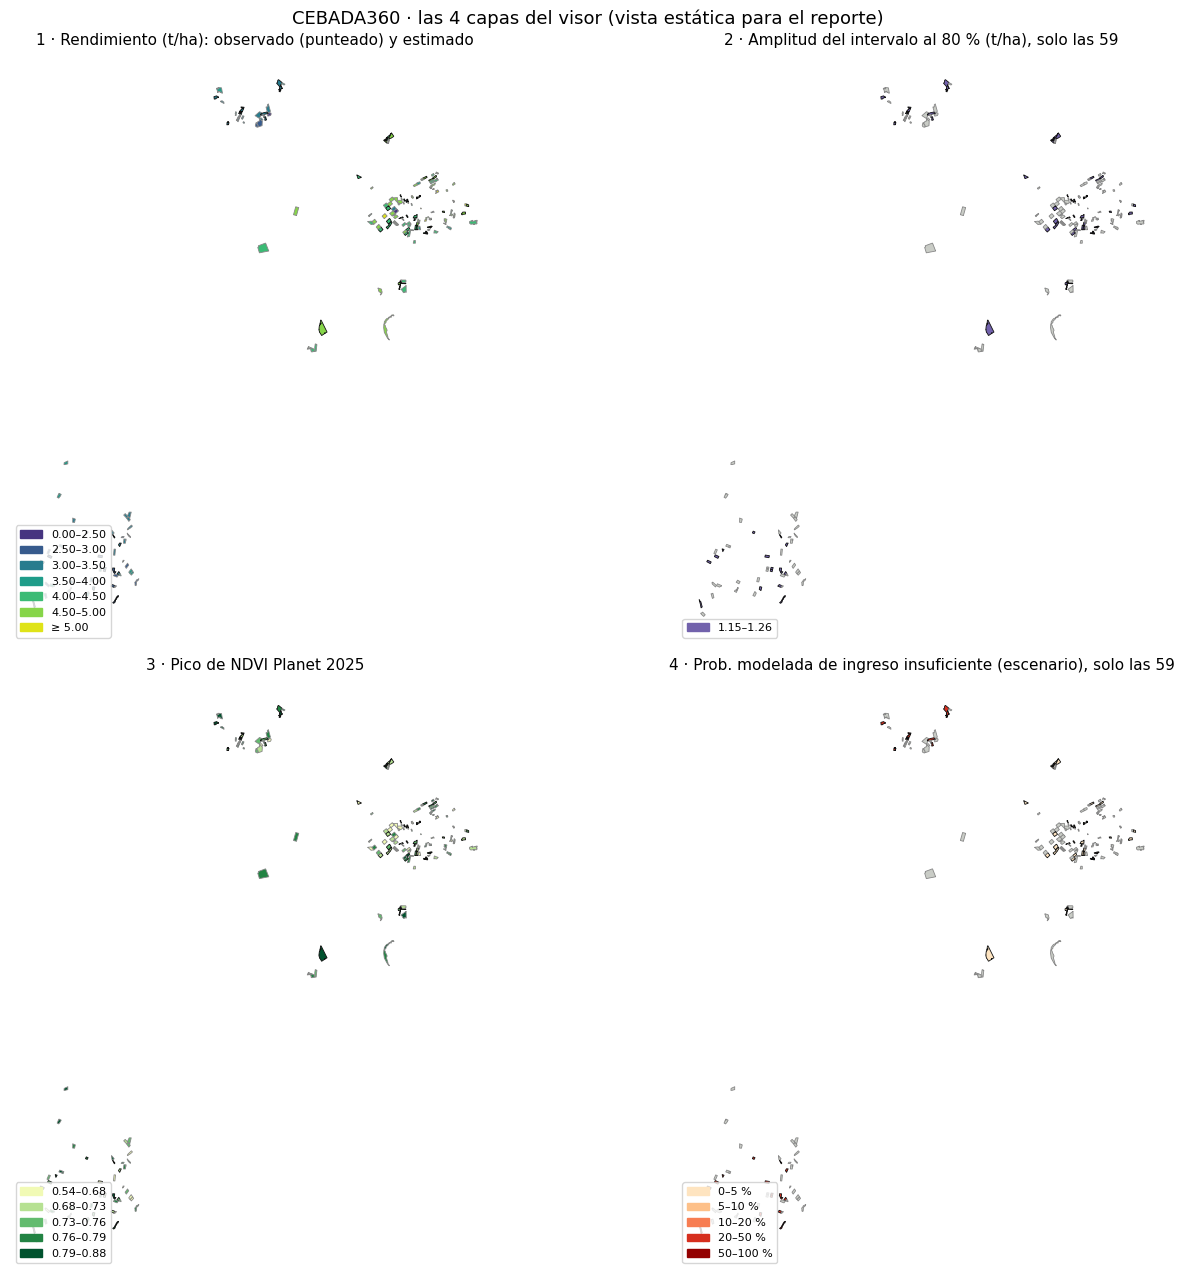


✅ Visor generado: /content/resultados_app/visor_cebada360.html (0.27 MB) · empaquetado en resultados_app.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   También: datos_visor.csv, pruebas_visor.csv, LEEME_visor.txt, capturas/visor_4_capas.png


In [86]:
# Paso 29 · Visor geográfico interactivo (HTML único) con 4 capas, pruebas de integridad previas e imágenes para el
# reporte. Solo LEE resultados validados; NO cambia el modelo ni las 59. La cadena HTML se deja intacta.
# =====================================================================================
# PASO 29 · Visor geográfico interactivo de CEBADA360 (para la app)
# Genera UN archivo HTML (resultados_app/visor_cebada360.html) con un mapa interactivo de las 197 parcelas y 4 capas:
#   1. Rendimiento: observado (138, borde punteado) o estimado por el ensamble (59, borde sólido), en t/ha.
#   2. Incertidumbre: amplitud del intervalo de predicción al 80 % (solo las 59; las 138 ya tienen rendimiento medido).
#   3. Vegetación y calidad satelital: NDVI, EVI, NDWI, imágenes válidas, nubosidad y banderas de calidad.
#   4. Riesgo: probabilidad de que el rendimiento no alcance para pagar el crédito FIRA (paso 24/27, errores reales).
# Filtros por municipio y conjunto, búsqueda por ID, ficha de cada parcela con los factores del modelo (paso F),
# leyenda dinámica, mapa base de calles o satelital. Se abre en cualquier navegador (necesita internet para el mapa base).
# Antes de escribir el visor corre PRUEBAS DE INTEGRIDAD (197/138/59, uniones, predicciones = archivo de entrega,
# huella SHA-256, producción = rendimiento × área, ubicación de los polígonos) y si falla algo crítico NO lo genera.
# También guarda imágenes PNG de las 4 capas para el reporte.
# NO cambia el modelo, los pesos ni las 59 predicciones: solo LEE los archivos que generaron los pasos anteriores.
# =====================================================================================
import json, hashlib, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from pathlib import Path
import geopandas as gpd

BASE = Path(globals().get("BASE", Path.cwd()))
OUT29, RES3, RES4 = BASE / "outputs", BASE / "resultados_I3", BASE / "resultados_I4"
APP = BASE / "resultados_app"; APP.mkdir(exist_ok=True)
pruebas = []


def prueba(nombre, ok, detalle="", critica=True):
    pruebas.append({"prueba": nombre, "resultado": "OK" if ok else ("FALLA" if critica else "AVISO"), "detalle": detalle})
    print(f"  [{'OK   ' if ok else ('FALLA' if critica else 'AVISO')}] {nombre}" + (f" · {detalle}" if detalle else ""))


def leer(ruta, obligatorio=True):
    if ruta.exists():
        return pd.read_csv(ruta)
    if obligatorio:
        raise FileNotFoundError(f"Falta {ruta}: corre antes el paso que lo genera.")
    print(f"  (no está {ruta.relative_to(BASE)}: esa parte del visor queda sin datos)")
    return None


# ---------------------------------------------------------------- 1. archivos del equipo
print("ARCHIVOS")
geo = gpd.read_file(OUT29 / "parcelas.geojson")                                  # paso 5 (WGS84)
bm = leer(OUT29 / "base_maestra_v3.csv")
pred = leer(RES3 / "predicciones.csv")
entrega = leer(RES3 / "ENTREGA" / "predicciones_59_entrega.csv")
coords = leer(OUT29 / "coordenadas_parcelas.csv")
fac = leer(RES3 / "factores.csv", False)
bq = leer(OUT29 / "banderas_calidad.csv", False)
dano = leer(RES3 / "alerta_dano_59.csv", False)
sup = leer(RES4 / "supuestos_credito.csv", False)
cred_mun = RES4 / "credito_por_parcela_intervalo_municipio.csv"
if cred_mun.exists():
    cred, fuente_int = pd.read_csv(cred_mun), "paso 27 (intervalo ampliado en municipios con más error)"
elif (RES4 / "credito_por_parcela.csv").exists():
    cred, fuente_int = pd.read_csv(RES4 / "credito_por_parcela.csv"), "paso 24 (intervalo común)"
else:
    cred, fuente_int = None, "predicciones.csv (paso E)"
print(f"  Intervalos y riesgo tomados de: {fuente_int}")

# ---------------------------------------------------------------- 2. tabla única por parcela
cols_bm = ["ID_POLIGONO", "CONJUNTO", "Municipio", "Estado", "area_ha", "y", "rend_redondo",
           "pl_ndvi_pico", "pl_evi_pico", "s2_ndwi_media_veg", "cal_pl_n_obs", "cal_s2_n_obs", "cal_pl_nub_media", "cal_pl_hueco_max_dias"]
t = bm[[c for c in cols_bm if c in bm]].merge(pred[["ID_POLIGONO", "y_pred", "y_lo80", "y_hi80"]], on="ID_POLIGONO", how="left")
if cred is not None:
    cc = ["ID_POLIGONO", "rend_lim_inf_80", "rend_lim_sup_80", "prob_ingreso_insuficiente", "nivel_riesgo", "motivo", "credito_sugerido",
          "credito_cuota_fira", "pct_de_cuota_fira"] + (["intervalo"] if "intervalo" in cred else [])
    t = t.merge(cred[cc], on="ID_POLIGONO", how="left")
    t["lo"], t["hi"] = t.rend_lim_inf_80, t.rend_lim_sup_80
else:
    t["lo"], t["hi"] = t.y_lo80, t.y_hi80
if bq is not None:
    t = t.merge(bq[[c for c in bq.columns if c.startswith("bq_") or c == "ID_POLIGONO"]], on="ID_POLIGONO", how="left")
if dano is not None:
    t = t.merge(dano[["ID_POLIGONO", "indice_dano", "alerta_dano_satelital"]], on="ID_POLIGONO", how="left")
es_pred = (t.CONJUNTO == "PREDICCION").values
t["rend_mostrado"] = np.where(es_pred, t.y_pred, t.y)                         # estimado (59) u observado (138)
t["produccion_t"] = t.rend_mostrado * t.area_ha
t["ancho"] = np.where(es_pred, t.hi - t.lo, np.nan)
REND_PAGO = np.nan
if sup is not None:
    v = sup.set_index("concepto").valor
    try:
        REND_PAGO = float(v[[k for k in v.index if k.startswith("Crédito por hectárea")][0]]
                          * v[[k for k in v.index if k.startswith("Factor de pago")][0]] / v[[k for k in v.index if k.startswith("Precio")][0]])
    except Exception:
        pass

# ---------------------------------------------------------------- 3. pruebas de integridad
print("\nPRUEBAS DE INTEGRIDAD")
prueba("197 parcelas únicas en la tabla", len(t) == 197 and t.ID_POLIGONO.is_unique, f"{len(t)} filas")
prueba("138 de entrenamiento y 59 de predicción", (t.CONJUNTO == "ENTRENAMIENTO").sum() == 138 and es_pred.sum() == 59)
prueba("197 polígonos únicos en parcelas.geojson", len(geo) == 197 and geo.ID_POLIGONO.is_unique, f"{len(geo)}")
prueba("Mismos IDs en el mapa y en la tabla (ninguno se pierde en la unión)", set(geo.ID_POLIGONO) == set(t.ID_POLIGONO))
prueba("Polígonos válidos", bool(geo.is_valid.all()), f"inválidos: {int((~geo.is_valid).sum())}")
prueba("Coordenadas en WGS84 (lo que usa el mapa web)", geo.crs is not None and geo.crs.to_epsg() == 4326, str(geo.crs))
cen = geo.to_crs(6372).centroid.to_crs(4326)
_c = coords.set_index("ID_POLIGONO").loc[geo.ID_POLIGONO]
_dist = np.hypot(cen.x.values - _c.lon.values, cen.y.values - _c.lat.values)
prueba("Cada polígono está en su ubicación (centroide = coordenadas_parcelas.csv)", _dist.max() < 1e-3, f"máx {_dist.max():.2e}°")
prueba("Las 59 de predicción NO traen rendimiento observado (sin fuga)", t.loc[es_pred, "y"].isna().all())
prueba("Las 138 de entrenamiento traen rendimiento observado", t.loc[~es_pred, "y"].notna().all())
_e = entrega.set_index(entrega.columns[0]).iloc[:, 0]
_dif = np.abs(t.loc[es_pred].set_index("ID_POLIGONO").y_pred.reindex(_e.index).values - _e.values)
prueba("Las 59 predicciones del visor = archivo de entrega del paso 19", set(_e.index) == set(t.ID_POLIGONO[es_pred]) and np.nanmax(_dif) < 5e-4,
       f"diferencia máx {np.nanmax(_dif):.2e} t/ha")
_sha = RES3 / "ENTREGA" / "SHA256.txt"
if _sha.exists():
    ref = _sha.read_text().split()[0]; act = hashlib.sha256((RES3 / "ENTREGA" / "predicciones_59_entrega.csv").read_bytes()).hexdigest()
    prueba("Huella SHA-256 del archivo de entrega sin cambios", ref == act, act[:16] + "…")
else:
    prueba("Huella SHA-256 del archivo de entrega", True, "no existe SHA256.txt (paso 19 no corrido); se omite", critica=False)
prueba("Producción = rendimiento × área", np.allclose(t.produccion_t, t.rend_mostrado * t.area_ha, equal_nan=True))
prueba("Intervalo de las 59 completo y con límite inferior ≤ predicción ≤ superior",
       t.loc[es_pred, ["lo", "hi"]].notna().all().all() and ((t.lo <= t.y_pred + 1e-9) & (t.y_pred <= t.hi + 1e-9))[es_pred].all())
prueba("Sin rendimientos faltantes en el mapa", t.rend_mostrado.notna().all(), f"faltan {int(t.rend_mostrado.isna().sum())}")
prueba("Probabilidad de riesgo disponible para las 59", cred is not None and t.loc[es_pred, "prob_ingreso_insuficiente"].notna().all(),
       "sin archivo de crédito: la capa 4 queda vacía" if cred is None else "", critica=False)
prueba("Factores del modelo disponibles (paso F)", fac is not None, critica=False)

# ---------------------------------------------------------------- 4. datos para el navegador
ETQ_BQ = {"bq_doble_joroba": "curva NDVI con doble joroba", "bq_pico_en_borde": "pico de NDVI en el borde de la ventana",
          "bq_pocas_imagenes": "pocas imágenes Planet", "bq_hueco_largo": "hueco de más de 30 días sin imágenes",
          "bq_lejos_de_entrenamiento": "lejos de parcelas con dato", "bq_ciclo_corto": "ciclo de cultivo muy corto",
          "bq_rend_atipico": "rendimiento atípico frente a sus vecinas"}
fac_top = {}
if fac is not None:
    for pid, g in fac.groupby("ID_POLIGONO"):
        g = g.reindex(g.contribucion.abs().sort_values(ascending=False).index).head(3)
        fac_top[pid] = [{"f": r.etiqueta, "c": round(float(r.contribucion), 3)} for r in g.itertuples()]
num = lambda x, d=3: None if pd.isna(x) else round(float(x), d)
props = {}
for r in t.itertuples():
    p = r._asdict()
    props[r.ID_POLIGONO] = {
        "id": r.ID_POLIGONO, "mun": r.Municipio, "edo": getattr(r, "Estado", ""), "conj": r.CONJUNTO, "area": num(r.area_ha, 2),
        "obs": r.CONJUNTO == "ENTRENAMIENTO", "rend": num(r.rend_mostrado), "prod": num(r.produccion_t, 1),
        "redondo": bool(p.get("rend_redondo") == 1),
        "lo": num(r.lo) if r.CONJUNTO == "PREDICCION" else None, "hi": num(r.hi) if r.CONJUNTO == "PREDICCION" else None,
        "ancho": num(r.ancho), "tipo_int": p.get("intervalo") if isinstance(p.get("intervalo"), str) else fuente_int,
        "ndvi": num(p.get("pl_ndvi_pico")), "evi": num(p.get("pl_evi_pico")), "ndwi": num(p.get("s2_ndwi_media_veg")),
        "nimg": num(p.get("cal_pl_n_obs"), 0), "nub": num(p.get("cal_pl_nub_media"), 1), "hueco": num(p.get("cal_pl_hueco_max_dias"), 0),
        "bq": p.get("bq_revisar") if isinstance(p.get("bq_revisar"), str) else None,
        "bq_mot": [v for k, v in ETQ_BQ.items() if p.get(k) == 1],
        "dano": p.get("alerta_dano_satelital") == "sí", "idano": num(p.get("indice_dano"), 2),
        "pnp": num(p.get("prob_ingreso_insuficiente")) if r.CONJUNTO == "PREDICCION" else None,
        "nivel": p.get("nivel_riesgo") if r.CONJUNTO == "PREDICCION" and isinstance(p.get("nivel_riesgo"), str) else None,
        "motivo": p.get("motivo") if r.CONJUNTO == "PREDICCION" and isinstance(p.get("motivo"), str) else None,
        "cred": num(p.get("credito_sugerido"), 0) if r.CONJUNTO == "PREDICCION" else None,
        "pcred": num(p.get("pct_de_cuota_fira")) if r.CONJUNTO == "PREDICCION" else None,
        "fac": fac_top.get(r.ID_POLIGONO, []) if r.CONJUNTO == "PREDICCION" else []}
gj = json.loads(geo[["ID_POLIGONO", "geometry"]].to_json(drop_id=True))
for f in gj["features"]:
    f["properties"] = props[f["properties"]["ID_POLIGONO"]]
    def redondear(c):
        return [round(c[0], 6), round(c[1], 6)] if isinstance(c[0], (int, float)) else [redondear(x) for x in c]
    f["geometry"]["coordinates"] = redondear(f["geometry"]["coordinates"])


def clases(valores, n=5, dec=2):
    """Cortes por cuantiles de los datos (solo para colorear; no son umbrales de decisión)."""
    v = pd.Series(valores).dropna()
    if v.empty: return []
    b = np.unique(np.round(np.quantile(v, np.linspace(0, 1, n + 1)), dec))
    return [float(x) for x in b]


hexs = lambda cmap, k, ini=.15: [matplotlib.colors.to_hex(c) for c in plt.get_cmap(cmap)(np.linspace(ini if k > 1 else .7, .95, k))]
CORTES_REND = [0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 99]
capas = {
    "rend": {"titulo": "Rendimiento (t/ha)", "campo": "rend", "cortes": CORTES_REND, "colores": hexs("viridis", 7), "unidad": "t/ha",
             "nota": "Borde sólido = estimado por el modelo (59) · borde punteado = observado (138)."},
    "inc": {"titulo": "Amplitud del intervalo empírico, nominal 80 % (t/ha)", "campo": "ancho", "cortes": clases(t.ancho), "unidad": "t/ha",
            "nota": "Banda orientativa calibrada con errores fuera de muestra; sin garantía de cobertura en parcelas nuevas. Más ancho = predicción menos precisa; NO significa más riesgo de pérdida. El ancho cambia por municipio solo si el paso 27 lo amplió. Solo las 59 estimadas; las 138 en gris (ya medidas).",
            "colores": None},
    "veg_ndvi": {"titulo": "Pico de NDVI Planet 2025", "campo": "ndvi", "cortes": clases(t.get("pl_ndvi_pico")), "unidad": "", "colores": None,
                 "nota": "Vigor máximo del cultivo. Señal orientativa: no diagnostica daño (paso 26)."},
    "veg_evi": {"titulo": "Pico de EVI Planet 2025", "campo": "evi", "cortes": clases(t.get("pl_evi_pico")), "unidad": "", "colores": None,
                "nota": "Vigor máximo, menos sensible a la saturación que el NDVI."},
    "veg_ndwi": {"titulo": "NDWI medio en la etapa vegetativa (Sentinel-2)", "campo": "ndwi", "cortes": clases(t.get("s2_ndwi_media_veg")),
                 "unidad": "", "colores": None, "nota": "Humedad del dosel; valores bajos pueden indicar estrés hídrico (orientativo)."},
    "veg_nimg": {"titulo": "Imágenes Planet válidas (abr-dic 2025)", "campo": "nimg", "cortes": clases(t.get("cal_pl_n_obs"), dec=0), "unidad": "imágenes",
                 "colores": None, "nota": "Calidad de la información: pocas imágenes = curva menos confiable."},
    "veg_nub": {"titulo": "Nubosidad media de las imágenes válidas", "campo": "nub", "cortes": clases(t.get("cal_pl_nub_media"), dec=1), "unidad": "%",
                "colores": None, "nota": "Calidad de la información."},
    "veg_bq": {"titulo": "Banderas de calidad (paso 16)", "campo": "bq", "categorias": {"ok": "#009E73", "atención": "#E69F00", "revisar": "#D55E00"},
               "nota": "Revisión de datos, no de daño en el cultivo."},
    "riesgo": {"titulo": "Prob. modelada de ingreso insuficiente para el crédito (escenario)", "campo": "pnp", "cortes": [0, .05, .1, .2, .5, 1.0001], "unidad": "",
               "porcentaje": True, "colores": hexs("OrRd", 5),
               "nota": (f"P modelada de que el rendimiento quede bajo {REND_PAGO:.2f} t/ha (lo necesario para pagar un crédito FIRA hipotético + "
                        f"intereses con precio y costos supuestos), usando los errores fuera de muestra del modelo. "
                        if np.isfinite(REND_PAGO) else "") + "Escenario bajo supuestos: NO es probabilidad calibrada de incumplimiento ni dato de "
                        "préstamos reales. Cortes 0.2 y 0.5 = niveles medio y alto del indicador exploratorio del paso 24. Solo las 59 estimadas."},
}
for k, cm in [("inc", "Purples"), ("veg_ndvi", "YlGn"), ("veg_evi", "YlGn"), ("veg_ndwi", "Blues"), ("veg_nimg", "Blues"), ("veg_nub", "Greys")]:
    capas[k]["colores"] = hexs(cm, max(len(capas[k]["cortes"]) - 1, 1), .4 if k == "inc" else .15)   # amplitud: sin tonos casi blancos
prueba("Cada capa tiene tantos colores como clases", all(len(c.get("colores") or []) == max(len(c.get("cortes") or []) - 1, 0)
                                                         for c in capas.values() if "cortes" in c))
resumen = {"n": 197, "n_pred": 59, "fuente_int": fuente_int, "rend_pago": num(REND_PAGO, 2),
           "municipios": sorted(t.Municipio.dropna().unique().tolist()),
           "fecha": pd.Timestamp.now().strftime("%d-%m-%Y")}

# ---------------------------------------------------------------- 5. HTML
HTML = r"""<!doctype html>
<html lang="es"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>CEBADA360 · Visor de parcelas</title>
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<style>
:root{--fondo:#f6f7f4;--panel:#fff;--txt:#1f2a1f;--suave:#5b6b5b;--linea:#dfe3dc;--acento:#2f6b3b}
*{box-sizing:border-box}body{margin:0;font-family:system-ui,-apple-system,"Segoe UI",Roboto,sans-serif;color:var(--txt);background:var(--fondo)}
#app{display:flex;height:100vh}#side{width:360px;min-width:300px;overflow-y:auto;background:var(--panel);border-right:1px solid var(--linea);padding:16px}
#map{flex:1}h1{font-size:19px;margin:0 0 2px}.sub{color:var(--suave);font-size:12.5px;margin-bottom:12px}
.bloque{border-top:1px solid var(--linea);padding:10px 0}.bloque h2{font-size:12px;text-transform:uppercase;letter-spacing:.04em;color:var(--suave);margin:0 0 8px}
label{font-size:13.5px;display:block;margin:4px 0;cursor:pointer}select,input[type=text]{width:100%;padding:7px;border:1px solid var(--linea);border-radius:6px;font-size:13.5px}
.fila{display:flex;gap:6px}.fila input{flex:1}button{background:var(--acento);color:#fff;border:0;border-radius:6px;padding:7px 12px;cursor:pointer;font-size:13.5px}
.ley-item{display:flex;align-items:center;gap:8px;font-size:12.5px;margin:2px 0}.cuadro{width:18px;height:12px;border:1px solid #0002;border-radius:2px}
.nota{font-size:11.5px;color:var(--suave);margin-top:6px;line-height:1.35}#ficha{font-size:13.5px}#ficha table{width:100%;border-collapse:collapse}
#ficha td{padding:3px 0;vertical-align:top}#ficha td:first-child{color:var(--suave);width:48%}.etq{display:inline-block;font-size:11px;padding:1px 7px;border-radius:10px;font-weight:600}
.est{background:#e8f0fb;color:#1d4f91}.obs{background:#edf6ec;color:#2f6b3b}.aviso{background:#fff4e0;color:#8a5a00;border-radius:6px;padding:6px 8px;font-size:12px;margin-top:6px}
.kpi{display:flex;gap:8px;margin-top:6px}.kpi div{flex:1;background:var(--fondo);border-radius:6px;padding:6px 8px;font-size:11.5px;color:var(--suave)}.kpi b{display:block;font-size:16px;color:var(--txt)}
.leaflet-tooltip{font-size:12px}
.leyenda-mapa{background:#fffffff0;padding:8px 10px;border-radius:8px;box-shadow:0 1px 4px #0003;max-width:260px;max-height:45vh;overflow-y:auto}
@media (max-width:760px){#app{flex-direction:column;height:auto}#side{width:100%;max-height:none;border-right:0}#map{height:65vh;order:-1}}
</style></head><body><div id="app"><div id="side">
<h1>CEBADA360 · Visor de parcelas</h1><div class="sub">Reto AgroCebada FIRA 2026 · 197 parcelas · actualizado __FECHA__</div>
<div class="bloque"><h2>Filtros</h2><select id="mun"></select>
<label style="margin-top:6px"><input type="checkbox" id="vpred" checked> Estimadas por el modelo (59)</label>
<label><input type="checkbox" id="vobs" checked> Con rendimiento observado (138)</label>
<div class="fila" style="margin-top:6px"><input type="text" id="buscar" placeholder="Buscar ID, p. ej. AGC_015"><button id="btnb">Ir</button></div>
<div class="kpi"><div>Parcelas en el mapa<b id="k1">–</b></div><div>Producción estimada (59)<b id="k2">–</b></div></div></div>
<div class="bloque"><h2>Capa</h2>
<label><input type="radio" name="capa" value="rend" checked> 1 · Rendimiento</label>
<label><input type="radio" name="capa" value="inc"> 2 · Incertidumbre de la predicción</label>
<label><input type="radio" name="capa" value="veg"> 3 · Vegetación y calidad satelital</label>
<select id="subveg" style="display:none;margin:4px 0 4px 22px;width:calc(100% - 22px)">
<option value="veg_ndvi">Pico de NDVI</option><option value="veg_evi">Pico de EVI</option><option value="veg_ndwi">Humedad (NDWI)</option>
<option value="veg_nimg">Imágenes válidas</option><option value="veg_nub">Nubosidad</option><option value="veg_bq">Banderas de calidad</option></select>
<label><input type="radio" name="capa" value="riesgo"> 4 · Riesgo productivo para el crédito (escenario)</label></div>
<div class="bloque"><h2>Ficha de la parcela</h2><div id="ficha"><span class="nota">Haz clic en una parcela del mapa.</span></div></div>
<div class="bloque nota">Predicciones: ensamble CEBADA360 (Ridge + promedio municipal + proceso gaussiano, pesos ⅓). Intervalos y riesgo: __FUENTE__.
Los índices satelitales son señales orientativas: no diagnostican granizo, helada ni enfermedad y requieren revisión en campo.
El crédito y el riesgo son escenarios con supuestos de precio, costo e intereses (FIRA Agrocostos); no hay datos de préstamos reales.
Factores: descomposición aditiva del ensamble (no SHAP, no efecto causal). El RMSE de las 59 parcelas se conocerá solo con la evaluación de FIRA.</div>
</div><div id="map"></div></div>
<script>
const DATA=__DATA__, CAPAS=__CAPAS__, RES=__RES__;
const fmt=(x,d=2)=>x==null?"–":Number(x).toLocaleString("es-MX",{minimumFractionDigits:d,maximumFractionDigits:d});
const pct=x=>x==null?"–":(100*x).toLocaleString("es-MX",{maximumFractionDigits:1})+" %";
const map=L.map("map",{preferCanvas:true});
const calles=L.tileLayer("https://{s}.tile.openstreetmap.org/{z}/{x}/{y}.png",{maxZoom:19,attribution:"© OpenStreetMap"});
const sat=L.tileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",{maxZoom:19,attribution:"Imágenes © Esri"});
const LEY=L.control({position:"bottomright"});LEY.onAdd=()=>{const d=L.DomUtil.create("div","leyenda-mapa");d.id="leyenda";L.DomEvent.disableScrollPropagation(d);return d};
sat.addTo(map);L.control.layers({"Satélite":sat,"Calles":calles},null,{position:"topright"}).addTo(map);L.control.scale({imperial:false}).addTo(map);LEY.addTo(map);
let capa="rend",capaGeo=null,sel=null,selId=null;
function claveCapa(){return capa==="veg"?document.getElementById("subveg").value:capa}
function color(p){const c=CAPAS[claveCapa()],v=p[c.campo];
 if(c.categorias)return v&&c.categorias[v]?c.categorias[v]:"#c9ccc6";
 if(v==null)return "#c9ccc6";const k=c.cortes;for(let i=0;i<k.length-1;i++){if(v<k[i+1]||i===k.length-2)return c.colores[i]}return c.colores[c.colores.length-1]}
function estilo(f){const p=f.properties;return{fillColor:color(p),fillOpacity:.85,color:p.obs?"#ffffff":"#111111",weight:p.obs?1.2:2,dashArray:p.obs?"3 3":null}}
function visible(p){const m=document.getElementById("mun").value;if(m!=="Todos"&&p.mun!==m)return false;
 if(p.obs&&!document.getElementById("vobs").checked)return false;if(!p.obs&&!document.getElementById("vpred").checked)return false;return true}
function etiquetaValor(p){const c=CAPAS[claveCapa()],v=p[c.campo];if(v==null)return "sin dato";if(c.porcentaje)return pct(v);if(c.categorias)return v;return fmt(v,c.unidad==="imágenes"?0:2)+" "+(c.unidad||"")}
function dibujar(){if(capaGeo)map.removeLayer(capaGeo);sel=null;let n=0,prod=0;
 capaGeo=L.geoJSON(DATA,{filter:f=>visible(f.properties),style:estilo,onEachFeature:(f,l)=>{const p=f.properties;n++;if(!p.obs&&p.prod!=null)prod+=p.prod;
  l.bindTooltip(`<b>${p.id}</b> · ${p.mun}<br>${CAPAS[claveCapa()].titulo}: ${etiquetaValor(p)}`,{sticky:true});
  l.on("click",()=>seleccionar(f,l));if(p.id===selId)sel=l}}).addTo(map);
 if(sel&&capaGeo.hasLayer(sel)){sel.setStyle({weight:4,color:"#ff2d55",dashArray:null});sel.bringToFront()}
 else if(selId){sel=null;selId=null;document.getElementById("ficha").innerHTML=`<span class="nota">La parcela seleccionada quedó fuera de los filtros. Haz clic en otra.</span>`}
 document.getElementById("k1").textContent=n;document.getElementById("k2").textContent=fmt(prod,0)+" t";leyenda()}
function leyenda(){const c=CAPAS[claveCapa()];let h=`<div style="font-size:12.5px;font-weight:600;margin-bottom:4px">${c.titulo}</div>`;
 if(c.categorias){for(const[k,v]of Object.entries(c.categorias))h+=`<div class="ley-item"><span class="cuadro" style="background:${v}"></span>${k}</div>`}
 else{const k=c.cortes;for(let i=0;i<k.length-1;i++){const a=c.porcentaje?pct(k[i]):fmt(k[i],2),b=c.porcentaje?pct(Math.min(k[i+1],1)):(k[i+1]>=99?"más":fmt(k[i+1],2));
  h+=`<div class="ley-item"><span class="cuadro" style="background:${c.colores[i]}"></span>${i===k.length-2&&!c.porcentaje&&k[i+1]>=99?"≥ "+a:a+" – "+b} ${c.unidad&&!c.porcentaje?c.unidad:""}</div>`}}
 h+=`<div class="ley-item"><span class="cuadro" style="background:#c9ccc6"></span>sin dato / no aplica</div>`;
 h+=`<div class="ley-item"><span class="cuadro" style="background:#fff;border:2px solid #111"></span>estimada por el modelo</div>`;
 h+=`<div class="ley-item"><span class="cuadro" style="background:#fff;border:1.5px dashed #777"></span>rendimiento observado</div>`;
 document.getElementById("leyenda").innerHTML=h+`<div class="nota">${c.nota}</div>`}
function seleccionar(f,l){if(sel)capaGeo.resetStyle(sel);sel=l;selId=f.properties.id;l.setStyle({weight:4,color:"#ff2d55",dashArray:null});l.bringToFront();
 const p=f.properties;let h=`<div style="margin-bottom:6px"><b style="font-size:15px">${p.id}</b> <span class="etq ${p.obs?"obs":"est"}">${p.obs?"OBSERVADO":"ESTIMADO"}</span></div><table>`;
 h+=`<tr><td>Municipio</td><td>${p.mun}${p.edo?", "+p.edo:""}</td></tr><tr><td>Conjunto</td><td>${p.conj}</td></tr><tr><td>Área</td><td>${fmt(p.area,2)} ha</td></tr>`;
 h+=`<tr><td>${p.obs?"Rendimiento observado":"Rendimiento esperado"}</td><td><b>${fmt(p.rend,2)} t/ha</b>${p.obs&&p.redondo?" <span class='nota'>(reportado en múltiplos de 0.5)</span>":""}</td></tr>`;
 h+=`<tr><td>${p.obs?"Producción observada":"Producción estimada"}</td><td>${fmt(p.prod,1)} t <span class="nota">(rendimiento × área)</span></td></tr>`;
 if(!p.obs){h+=`<tr><td>Intervalo empírico (nominal 80 %)</td><td>${fmt(p.lo,2)} – ${fmt(p.hi,2)} t/ha<br><span class="nota">amplitud ${fmt(p.ancho,2)} t/ha · ${p.tipo_int||""}</span></td></tr>`;
  h+=`<tr><td>Escenarios</td><td>adverso ${fmt(p.lo,2)} · central ${fmt(p.rend,2)} · favorable ${fmt(p.hi,2)} t/ha</td></tr>`;
  if(p.pnp!=null)h+=`<tr><td>Prob. modelada de ingreso insuficiente</td><td>${pct(p.pnp)} · indicador <b>${p.nivel||"–"}</b><br><span class="nota">${p.motivo||""} · escenario bajo supuestos, no probabilidad de incumplimiento</span></td></tr>`;
  if(p.cred!=null)h+=`<tr><td>Crédito sugerido</td><td>$${fmt(p.cred,0)} MXN (${pct(p.pcred)} de la cuota FIRA)</td></tr>`}
 h+=`<tr><td>Pico NDVI / EVI</td><td>${fmt(p.ndvi,2)} / ${fmt(p.evi,2)}</td></tr><tr><td>Humedad (NDWI veg.)</td><td>${fmt(p.ndwi,2)}</td></tr>`;
 h+=`<tr><td>Imágenes válidas · nubosidad</td><td>${fmt(p.nimg,0)} · ${fmt(p.nub,1)} %${p.hueco!=null?" · hueco máx "+fmt(p.hueco,0)+" d":""}</td></tr>`;
 h+=`<tr><td>Calidad de datos</td><td>${p.bq||"–"}${p.bq_mot.length?"<br><span class='nota'>"+p.bq_mot.join("; ")+"</span>":""}</td></tr></table>`;
 if(p.fac.length){h+=`<div style="margin-top:8px;font-weight:600;font-size:12.5px">Qué más pesó en la predicción</div><table>`;
  for(const x of p.fac)h+=`<tr><td>${x.f}</td><td>${x.c>=0?"+":""}${fmt(x.c,2)} t/ha</td></tr>`;h+=`</table><div class="nota">Descomposición aditiva frente al promedio de entrenamiento (no SHAP, no efecto causal).</div>`}
 if(p.dano)h+=`<div class="aviso">Señal orientativa: el satélite la ve más débil que sus vecinas. Requiere revisión en campo; no es un diagnóstico de siniestro.</div>`;
 document.getElementById("ficha").innerHTML=h;document.getElementById("ficha").scrollIntoView({behavior:"smooth",block:"nearest"})}
function buscar(){const q=document.getElementById("buscar").value.trim().toUpperCase().replace(/\s/g,"");if(!q)return;
 const id=/^\d+$/.test(q)?"AGC_"+q.padStart(3,"0"):q;let hallado=null;
 capaGeo.eachLayer(l=>{if(l.feature.properties.id===id)hallado=l});
 if(!hallado){document.getElementById("ficha").innerHTML=`<span class="nota">No se encontró ${id} con los filtros actuales.</span>`;return}
 map.fitBounds(hallado.getBounds(),{maxZoom:16});seleccionar(hallado.feature,hallado)}
const sm=document.getElementById("mun");sm.innerHTML=`<option>Todos</option>`+RES.municipios.map(m=>`<option>${m}</option>`).join("");
sm.onchange=()=>{dibujar();if(capaGeo.getLayers().length)map.fitBounds(capaGeo.getBounds(),{padding:[20,20]})};
for(const id of["vpred","vobs"])document.getElementById(id).onchange=dibujar;
document.querySelectorAll("input[name=capa]").forEach(r=>r.onchange=e=>{capa=e.target.value;document.getElementById("subveg").style.display=capa==="veg"?"block":"none";dibujar()});
document.getElementById("subveg").onchange=dibujar;document.getElementById("btnb").onclick=buscar;
document.getElementById("buscar").onkeydown=e=>{if(e.key==="Enter")buscar()};
dibujar();map.fitBounds(capaGeo.getBounds(),{padding:[20,20]});
</script></body></html>"""
html = (HTML.replace("__DATA__", json.dumps(gj, ensure_ascii=False, separators=(",", ":")))
            .replace("__CAPAS__", json.dumps(capas, ensure_ascii=False)).replace("__RES__", json.dumps(resumen, ensure_ascii=False))
            .replace("__FECHA__", resumen["fecha"]).replace("__FUENTE__", fuente_int))
prueba("El visor contiene las 197 parcelas", html.count('"id":"AGC_') == 197)

# ---------------------------------------------------------------- 6. imágenes para el reporte (las 4 capas)
FIGAPP = APP / "capturas"; FIGAPP.mkdir(exist_ok=True)
g = geo[["ID_POLIGONO", "geometry"]].merge(t, on="ID_POLIGONO").to_crs(6372)
paneles = [("rend", "rend_mostrado", "1 · Rendimiento (t/ha): observado (punteado) y estimado"),
           ("inc", "ancho", "2 · Amplitud del intervalo al 80 % (t/ha), solo las 59"),
           ("veg_ndvi", "pl_ndvi_pico", "3 · Pico de NDVI Planet 2025"),
           ("riesgo", "prob_ingreso_insuficiente", "4 · Prob. modelada de ingreso insuficiente (escenario), solo las 59")]
fig, axs = plt.subplots(2, 2, figsize=(15, 13))
for ax, (k, col, tit) in zip(axs.ravel(), paneles):
    cfg = capas[k]
    vals = g[col] if col in g else pd.Series(np.nan, index=g.index)
    if k in ("inc", "riesgo"): vals = vals.where(g.CONJUNTO == "PREDICCION")
    cut = np.array(cfg["cortes"], float)
    idx = np.clip(np.searchsorted(cut, vals.fillna(-1e9).values, side="right") - 1, 0, len(cfg["colores"]) - 1) if len(cut) else np.zeros(len(g), int)
    colores = [cfg["colores"][i] if pd.notna(v) else "#c9ccc6" for i, v in zip(idx, vals)]
    g.plot(ax=ax, color=colores, edgecolor=np.where(g.CONJUNTO == "PREDICCION", "#111111", "#888888"), linewidth=.6)
    ax.set_title(tit, fontsize=11); ax.set_axis_off()
    hand = [plt.Rectangle((0, 0), 1, 1, color=cfg["colores"][i]) for i in range(len(cfg["colores"]))]
    labs = [(f"{100*cut[i]:.0f}–{100*min(cut[i+1],1):.0f} %" if cfg.get("porcentaje") else
             (f"≥ {cut[i]:.2f}" if cut[i + 1] >= 99 else f"{cut[i]:.2f}–{cut[i+1]:.2f}")) for i in range(len(cut) - 1)]
    ax.legend(hand, labs, fontsize=8, loc="lower left", frameon=True)
fig.suptitle("CEBADA360 · las 4 capas del visor (vista estática para el reporte)", fontsize=13)
fig.tight_layout(); fig.savefig(FIGAPP / "visor_4_capas.png", dpi=150); plt.show()

# ---------------------------------------------------------------- 7. salidas
pr = pd.DataFrame(pruebas); pr.to_csv(APP / "pruebas_visor.csv", index=False)
fallas = pr[pr.resultado == "FALLA"]
if len(fallas):
    print("\n❌ NO se generó el visor: hay pruebas críticas que fallan."); print(fallas.to_string(index=False))
    raise RuntimeError("Pruebas críticas del visor fallaron: revisa la lista de arriba.")
(APP / "visor_cebada360.html").write_text(html, encoding="utf-8")
t.drop(columns=[c for c in ["y"] if c in t]).assign(rend_tipo=np.where(es_pred, "estimado", "observado")) \
    .round(4).to_csv(APP / "datos_visor.csv", index=False)
(APP / "LEEME_visor.txt").write_text(f"""CEBADA360 · Visor de parcelas
Archivo: visor_cebada360.html (un solo archivo; se abre con doble clic en Chrome, Edge o Firefox; necesita internet solo para el mapa base).
Para publicarlo: súbanlo tal cual a GitHub Pages, Netlify o Google Sites (insertar HTML), o pónganlo como página de su app.
Capas: 1 rendimiento (observado/estimado), 2 incertidumbre (intervalo 80 %), 3 vegetación y calidad satelital, 4 probabilidad modelada de ingreso insuficiente para un crédito hipotético (escenario, no incumplimiento real).
Archivos que usa (generados por el notebook): outputs/parcelas.geojson, outputs/base_maestra_v3.csv, outputs/coordenadas_parcelas.csv,
  outputs/banderas_calidad.csv, resultados_I3/predicciones.csv, resultados_I3/factores.csv, resultados_I3/alerta_dano_59.csv,
  resultados_I3/ENTREGA/predicciones_59_entrega.csv y SHA256.txt, resultados_I4/credito_por_parcela*.csv, resultados_I4/supuestos_credito.csv.
Intervalos y riesgo: {fuente_int}.
Pruebas de integridad: pruebas_visor.csv ({len(pr)} pruebas, {int((pr.resultado == 'OK').sum())} OK).
Imágenes para el reporte: capturas/visor_4_capas.png.
No cambia el modelo ni las predicciones: solo lee los resultados validados.
""", encoding="utf-8")
import zipfile
with zipfile.ZipFile(BASE / "resultados_app.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for f in APP.rglob("*"):
        if f.is_file(): zf.write(f, f.relative_to(BASE))
print(f"\n✅ Visor generado: {APP / 'visor_cebada360.html'} ({len(html) / 1e6:.2f} MB) · empaquetado en resultados_app.zip")
try:
    from google.colab import files; files.download(str(BASE / "resultados_app.zip"))
except ImportError:
    pass
print("   También: datos_visor.csv, pruebas_visor.csv, LEEME_visor.txt, capturas/visor_4_capas.png")
try:                                                    # vista previa dentro del notebook
    from IPython.display import HTML as _HTML, display
    import html as _h
    display(_HTML(f'<iframe srcdoc="{_h.escape(html)}" style="width:100%;height:680px;border:1px solid #ccc"></iframe>'))
except Exception:
    pass


## Paso 30 · Verificación final automática y entorno reproducible
Al terminar **Ejecutar todo**, comprueba que **nada de lo entregado haya cambiado** respecto a la corrida de referencia:
1. Huella SHA-256 del archivo de entrega = la de referencia (`21955b71…`).
2. Las 59 parcelas son las oficiales de PREDICCION.
3. RMSE, MAE y R² de validación del ensamble = 0.4940 / 0.3381 / 0.6607.
4. `modelo.joblib` reproduce las 59 (si abre con esta versión de scikit-learn; se guardó con la de `requirements.txt`).
5. `cargar_o_reentrenar()` (la función que debe usar la app) reproduce las 59 aunque el `.joblib` no abra: reentrena en menos de 1 s y verifica contra la entrega.
6. Reentrenar desde cero reproduce las 59.
7. `predicciones.csv` y el visor del paso 29 son consistentes con la entrega.
8. **Recalcula** la validación 10×5 del ensamble desde cero (no la lee del CSV) y la compara con 0.4940 / 0.3381 / 0.6607.
9. Los **197 ID_POLIGONO** son únicos y el mismo conjunto en la tabla oficial, la base maestra, las coordenadas, el mapa, `predicciones.csv`, `factores.csv`, el crédito y el visor.
10. El **visor** tiene sus 4 capas definidas y con datos donde aplican, y sus 59 predicciones = entrega.
11. `predicciones.csv` y `factores.csv` indican qué tipo de predicción o explicación es cada fila.
12. `predecir()` con respaldo de reentrenamiento reproduce las 59.
13. Avisa si el notebook no se ejecutó completo en esta sesión. La corrida desde cero es **Ejecutar todo** (una celda no puede volver a ejecutar el notebook que la contiene); la prueba en un navegador real se hizo fuera de Colab.

Escribe `requirements.txt` (versiones exactas de este entorno) y `resultados_I3/VERIFICACION_FINAL.txt`. Si algo crítico falla, se detiene con el aviso en rojo.

**Cómo leer los resultados.**

Es la verificación final de que todo lo entregado sigue igual: huella SHA-256 del archivo de entrega, métricas de validación **recalculadas desde cero**, reproducibilidad de `modelo.joblib` y del reentrenamiento, consistencia de los 197 ID en todas las tablas y en el visor, y versiones exactas del entorno en `requirements.txt`. Si algo crítico falla, se detiene en rojo. Los valores de referencia (SHA `21955b71…`, RMSE 0.4940, MAE 0.3381, R² 0.6607) son los de la corrida validada del equipo.

In [87]:
# Paso 30 · Verificación final automática (huella, métricas recalculadas, modelo, IDs, visor) y requirements.txt.
# =====================================================================================
# PASO 30 · Verificación final automática y entorno reproducible
# Comprueba, al terminar "Ejecutar todo", que los ajustes de redacción, etiquetas y empaquetado
# NO movieron nada de lo entregado:
#   1. Huella SHA-256 del archivo de entrega = la de referencia (21955b71…).
#   2. Las 59 parcelas son exactamente las oficiales de PREDICCION.
#   3. RMSE, MAE y R² de validación del ensamble = los de referencia (0.4940 / 0.3381 / 0.6607).
#   4. modelo.joblib reproduce las 59 (si abre con esta versión de scikit-learn).
#   5. cargar_o_reentrenar() (lo que debe usar la app) reproduce las 59 aunque el .joblib no abra.
#   6. Reentrenar desde cero con base_maestra_v3 reproduce las 59.
#   7. predicciones.csv (para la app) y el visor (paso 29) son consistentes con la entrega.
#   8. RECALCULA la validación 10×5 del ensamble desde cero (no la lee del CSV).
#   9. Los 197 ID_POLIGONO: únicos y el mismo conjunto en todas las tablas, el mapa y el visor; 138/59 consistentes.
#  10. Visor: las 4 capas existen y tienen datos válidos donde aplican; sus 59 predicciones = entrega.
#  11. factores.csv y predicciones.csv indican qué tipo de predicción/explicación es cada fila.
#  12. predecir() con respaldo de reentrenamiento reproduce las 59.
#  13. Aviso si el notebook NO se ejecutó completo en esta sesión ("Ejecutar todo" es la corrida desde cero).
# Escribe requirements.txt (versiones exactas de este entorno) y VERIFICACION_FINAL.txt. No cambia nada del modelo.
# =====================================================================================
import sys, hashlib, platform, importlib, warnings
from importlib import metadata
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path

REF_SHA = "21955b71fdb306a17d793aafee8eac6f223e7485287001f7d68fe48be303243c"
REF_METRICAS = {"RMSE": 0.4940, "MAE": 0.3381, "R2": 0.6607}
import json, re
from sklearn.model_selection import StratifiedKFold
TOL_METRICA = 5e-4

BASE = Path(globals().get("BASE", Path.cwd()))
OUT30, RES30 = BASE / "outputs", BASE / "resultados_I3"
ENT30 = RES30 / "ENTREGA" / "predicciones_59_entrega.csv"
filas30 = []


def verif(nombre, ok, detalle="", critica=True):
    filas30.append({"verificacion": nombre, "resultado": "OK" if ok else ("FALLA" if critica else "AVISO"), "detalle": detalle})
    print(f"  [{'OK   ' if ok else ('FALLA' if critica else 'AVISO')}] {nombre}" + (f" · {detalle}" if detalle else ""))


print("VERIFICACIÓN FINAL")
# 1-2. archivo de entrega
assert ENT30.exists(), "No existe resultados_I3/ENTREGA/predicciones_59_entrega.csv: corre el paso 19."
sha = hashlib.sha256(ENT30.read_bytes()).hexdigest()
verif("Huella SHA-256 de la entrega = referencia", sha == REF_SHA, f"{sha[:16]}… (referencia {REF_SHA[:16]}…)")
ent = pd.read_csv(ENT30).set_index("ID_POLIGONO").rendimiento_t_ha
tp = pd.read_csv(OUT30 / "tabla_principal_limpia.csv")
verif("Las 59 son las parcelas oficiales de PREDICCION", set(ent.index) == set(tp.loc[tp.CONJUNTO == "PREDICCION", "ID_POLIGONO"]),
      f"{len(ent)} filas")

# 3. métricas de validación
met = pd.read_csv(RES30 / "metricas_modelos.csv")
fila = met[met.familia == "seleccionado"].iloc[0]
for k, v in REF_METRICAS.items():
    verif(f"{k} de validación del ensamble = {v}", abs(float(fila[k]) - v) <= TOL_METRICA, f"{float(fila[k]):.4f}")

# 4-6. modelo
if str(RES30) not in sys.path:
    sys.path.insert(0, str(RES30))
import modelo_cebada360
importlib.reload(modelo_cebada360)
b30 = pd.read_csv(OUT30 / "base_maestra_v3.csv").merge(
    pd.read_csv(OUT30 / "coordenadas_parcelas.csv")[["ID_POLIGONO", "x_km", "y_km"]], on="ID_POLIGONO", how="left")
tr30 = b30[b30.CONJUNTO == "ENTRENAMIENTO"].reset_index(drop=True)
pr30 = b30[b30.CONJUNTO == "PREDICCION"].reset_index(drop=True)
dif = lambda p: float(np.abs(np.round(p, 4) - ent.reindex(pr30.ID_POLIGONO).values).max())
try:
    import joblib
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m_jl = joblib.load(RES30 / "modelo.joblib")
        d_jl = dif(m_jl.predict(pr30))
    verif("modelo.joblib abre y reproduce las 59", d_jl < 5e-4, f"diferencia máx {d_jl:.1e} t/ha")
except Exception as e:
    verif("modelo.joblib abre con esta versión de scikit-learn", False,
          f"{type(e).__name__}: instalen requirements.txt; la app usa cargar_o_reentrenar() y sigue funcionando", critica=False)
m_app = modelo_cebada360.cargar_o_reentrenar(RES30 / "modelo.joblib", tr30, pr30, ent)
verif("cargar_o_reentrenar() (la que usa la app) reproduce las 59", dif(m_app.predict(pr30)) < 5e-4, f"origen: {m_app.origen_}")
m_new = modelo_cebada360.ModeloCebada360().fit(tr30)
verif("Reentrenar desde cero reproduce las 59", dif(m_new.predict(pr30)) < 5e-4, f"diferencia máx {dif(m_new.predict(pr30)):.1e} t/ha")
verif("predecir() con respaldo de reentrenamiento reproduce las 59",
      dif(modelo_cebada360.predecir(pr30, RES30 / "modelo.joblib", tr30)) < 5e-4)

# 8. validación 10×5 RECALCULADA desde cero (mismas particiones que el paso B)
y30 = tr30.y.values.astype(float)
est30 = tr30.Municipio.where(tr30.Municipio.map(tr30.Municipio.value_counts()) >= 5, "Otros")
OOF30 = np.zeros((10, len(tr30)))
for s_ in range(10):
    for a_, b_ in StratifiedKFold(5, shuffle=True, random_state=s_).split(tr30, est30):
        OOF30[s_, b_] = modelo_cebada360.ModeloCebada360().fit(tr30.iloc[a_]).predict(tr30.iloc[b_])
E30 = y30[None, :] - OOF30
recalc = {"RMSE": np.sqrt((E30 ** 2).mean()), "MAE": np.abs(E30).mean(), "R2": 1 - (E30 ** 2).mean() / y30.var()}
for k, v in REF_METRICAS.items():
    verif(f"{k} RECALCULADO desde cero (10×5) = {v}", abs(recalc[k] - v) <= TOL_METRICA, f"{recalc[k]:.4f}")

# 9. los 197 identificadores en todas las tablas
geo30 = json.loads((OUT30 / "parcelas.geojson").read_text(encoding="utf-8"))
ids_ref = set(tp.ID_POLIGONO)
verif("tabla oficial: 197 ID únicos (138 entrenamiento + 59 predicción)",
      len(tp) == 197 and tp.ID_POLIGONO.is_unique and (tp.CONJUNTO == "ENTRENAMIENTO").sum() == 138)
tablas = {"base_maestra_v3.csv": b30, "coordenadas_parcelas.csv": pd.read_csv(OUT30 / "coordenadas_parcelas.csv"),
          "parcelas.geojson": pd.DataFrame([f["properties"] for f in geo30["features"]]),
          "predicciones.csv": pd.read_csv(RES30 / "predicciones.csv")}
for extra in [BASE / "resultados_I4" / "credito_por_parcela.csv", BASE / "resultados_I4" / "credito_por_parcela_intervalo_municipio.csv",
              BASE / "resultados_app" / "datos_visor.csv"]:
    if extra.exists(): tablas[extra.name] = pd.read_csv(extra)
for nom, df_ in tablas.items():
    ids_ = df_.ID_POLIGONO
    verif(f"{nom}: 197 ID únicos y los mismos de la tabla oficial", len(ids_) == 197 and ids_.is_unique and set(ids_) == ids_ref,
          f"{len(ids_)} filas, {ids_.nunique()} únicos")
fac30 = pd.read_csv(RES30 / "factores.csv")
verif("factores.csv: 5 factores por cada una de las 197", len(fac30) == 197 * 5 and set(fac30.ID_POLIGONO) == ids_ref
      and fac30.groupby("ID_POLIGONO").size().eq(5).all())
_c30 = tp.set_index("ID_POLIGONO").CONJUNTO
_pc = tablas["predicciones.csv"].set_index("ID_POLIGONO").CONJUNTO
verif("CONJUNTO idéntico entre la tabla oficial y predicciones.csv", (_pc.reindex(_c30.index) == _c30).all())

# 11. tipo de predicción y de explicación
verif("predicciones.csv indica el tipo de predicción (fuera de fold / modelo final)", "tipo_prediccion" in tablas["predicciones.csv"])
if {"prediccion_modelo_final", "tipo_explicacion"} <= set(fac30.columns):
    _f59 = fac30.drop_duplicates("ID_POLIGONO").set_index("ID_POLIGONO").prediccion_modelo_final.reindex(ent.index)
    verif("factores.csv: en las 59, la predicción del modelo final = entrega", float((_f59 - ent).abs().max()) < 5e-4,
          f"diferencia máx {float((_f59 - ent).abs().max()):.4f}")
else:
    verif("factores.csv indica qué predicción explica", False, "vuelve a correr el paso F")

# 7. archivos de la app
pc = pd.read_csv(RES30 / "predicciones.csv")
p59 = pc[pc.CONJUNTO == "PREDICCION"].set_index("ID_POLIGONO").y_pred
verif("predicciones.csv (app) = entrega", float(np.abs(p59.reindex(ent.index) - ent).max()) < 5e-4)
# 10. visor: las 4 capas
_html = BASE / "resultados_app" / "visor_cebada360.html"
if _html.exists():
    h = _html.read_text(encoding="utf-8")
    DATA = json.loads(re.search(r"const DATA=(\{.*?\}), CAPAS=", h, re.S).group(1))
    CAPAS = json.loads(re.search(r"CAPAS=(\{.*?\}), RES=", h, re.S).group(1))
    P = {f["properties"]["id"]: f["properties"] for f in DATA["features"]}
    verif("Visor: 197 polígonos con ID únicos = tabla oficial", len(DATA["features"]) == 197 and set(P) == ids_ref)
    verif("Visor: sus 59 predicciones = entrega", max(abs(P[i]["rend"] - v) for i, v in ent.items()) < 6e-4)
    verif("Visor: ninguna estimada marcada como observada", all(not P[i]["obs"] for i in ent.index))
    est59 = [P[i] for i in ent.index]
    capas_req = {"1 · Rendimiento": ("rend", "rend", list(P.values())),
                 "2 · Incertidumbre": ("inc", "ancho", est59),
                 "3 · Vegetación (pico NDVI)": ("veg_ndvi", "ndvi", list(P.values())),
                 "3 · Calidad (banderas)": ("veg_bq", "bq", list(P.values())),
                 "4 · Riesgo productivo (escenario)": ("riesgo", "pnp", est59)}
    for nom, (clave, campo, filas_) in capas_req.items():
        n_ok = sum(p_.get(campo) is not None for p_ in filas_)
        verif(f"Visor capa {nom}: definida y con datos", clave in CAPAS and n_ok == len(filas_) and f'value="{clave.split("_")[0]}"' in h,
              f"{n_ok}/{len(filas_)} parcelas con valor")
    verif("Visor: carga Leaflet (mapa) desde el CDN fijado", "leaflet@1.9.4" in h, "necesita internet solo para el mapa base", critica=False)
else:
    verif("Visor del paso 29 generado", False, "no existe resultados_app/visor_cebada360.html (corre el paso 29)", critica=False)

# 13. ¿corrida completa en esta sesión?
_marcas = ["comp13", "riesgo15", "banderas16", "OOF_ENS", "modelo_final", "c27", "curva", "capas"]
_faltan = [m_ for m_ in _marcas if m_ not in globals()]
verif("Notebook ejecutado completo en esta sesión (Ejecutar todo = corrida desde cero)", not _faltan,
      "faltan resultados en memoria de: " + ", ".join(_faltan) if _faltan else "pasos 1-29 en memoria", critica=False)

pv = BASE / "resultados_app" / "pruebas_visor.csv"
if pv.exists():
    _pv = pd.read_csv(pv)
    verif("Visor del paso 29: todas sus pruebas críticas en OK", not (_pv.resultado == "FALLA").any(), f"{(_pv.resultado == 'OK').sum()}/{len(_pv)} OK")
else:
    verif("Visor del paso 29 generado", False, "no existe resultados_app/pruebas_visor.csv (corre el paso 29)", critica=False)
cr = BASE / "resultados_I4" / "credito_por_parcela.csv"
if cr.exists():
    verif("Crédito con etiquetas corregidas (sin 'prob_no_pago')", "prob_ingreso_insuficiente" in pd.read_csv(cr, nrows=1).columns,
          "vuelve a correr el paso 24 si falla", critica=False)

# entorno reproducible
paquetes = ["numpy", "pandas", "scipy", "scikit-learn", "joblib", "matplotlib", "statsmodels", "geopandas", "shapely",
            "pyproj", "rasterio", "openpyxl"]
lineas = []
for p in paquetes:
    try:
        lineas.append(f"{p}=={metadata.version(p)}")
    except metadata.PackageNotFoundError:
        pass
req = (f"# CEBADA360 · entorno con el que se generó la entrega (Python {platform.python_version()})\n"
       f"# modelo.joblib solo abre con esta versión de scikit-learn; la app debe usar cargar_o_reentrenar(),\n"
       f"# que reentrena (determinista, <1 s) si el .joblib no abre, y verifica las 59 contra la entrega.\n" + "\n".join(lineas) + "\n")
for destino in (BASE / "requirements.txt", RES30 / "requirements.txt"):
    destino.write_text(req, encoding="utf-8")
print("\nrequirements.txt:\n" + req)

v = pd.DataFrame(filas30)
fallas = v[v.resultado == "FALLA"]
texto = (f"CEBADA360 · VERIFICACIÓN FINAL · {pd.Timestamp.now():%Y-%m-%d %H:%M}\n"
         f"Entrega: {ENT30.name} · SHA-256 {sha}\n"
         f"Referencia: {REF_SHA}\n\n" + v.to_string(index=False) + "\n\n" +
         ("TODO CORRECTO: las correcciones no cambiaron la entrega, las métricas ni el modelo." if fallas.empty else
          "HAY FALLAS: no entregar hasta revisarlas."))
(RES30 / "VERIFICACION_FINAL.txt").write_text(texto, encoding="utf-8")
print("=" * 90)
if fallas.empty:
    print("✅ TODO CORRECTO: misma huella SHA-256, métricas recalculadas iguales, 197 ID consistentes, visor con sus 4 capas "
          "y el modelo reproduce las 59 predicciones." + (f" ({(v.resultado == 'AVISO').sum()} aviso(s) no crítico(s))" if (v.resultado == "AVISO").any() else ""))
else:
    print("❌ HAY FALLAS CRÍTICAS:"); print(fallas.to_string(index=False))
    raise RuntimeError("La verificación final falló: revisa la lista de arriba.")


VERIFICACIÓN FINAL
  [OK   ] Huella SHA-256 de la entrega = referencia · 21955b71fdb306a1… (referencia 21955b71fdb306a1…)
  [OK   ] Las 59 son las parcelas oficiales de PREDICCION · 59 filas
  [OK   ] RMSE de validación del ensamble = 0.494 · 0.4940
  [OK   ] MAE de validación del ensamble = 0.3381 · 0.3381
  [OK   ] R2 de validación del ensamble = 0.6607 · 0.6607
  [OK   ] modelo.joblib abre y reproduce las 59 · diferencia máx 0.0e+00 t/ha
  [OK   ] cargar_o_reentrenar() (la que usa la app) reproduce las 59 · origen: modelo.joblib
  [OK   ] Reentrenar desde cero reproduce las 59 · diferencia máx 0.0e+00 t/ha
  [OK   ] predecir() con respaldo de reentrenamiento reproduce las 59
  [OK   ] RMSE RECALCULADO desde cero (10×5) = 0.494 · 0.4940
  [OK   ] MAE RECALCULADO desde cero (10×5) = 0.3381 · 0.3381
  [OK   ] R2 RECALCULADO desde cero (10×5) = 0.6607 · 0.6607
  [OK   ] tabla oficial: 197 ID únicos (138 entrenamiento + 59 predicción)
  [OK   ] base_maestra_v3.csv: 197 ID únicos y los mi

## Resumen y descarga de resultados

### Explicación

Imprime el tamaño de las tablas principales, confirma que la base v3 tenga 197 parcelas (138 con rendimiento), revisa que existan los archivos clave de la auditoría y de las variables del cultivo y, en Colab, descarga un `.zip` con `outputs/`, `figs/`, `resultados_I3/`, `resultados_I4/` y `resultados_app/`.

In [88]:
# Resumen de archivos generados y descarga del zip con todos los resultados.
# FIG se restablece aquí porque el paso 17 lo reasignó a resultados_I3/figs.
for nombre in ["base_maestra_v1.csv", "base_maestra_v3.csv", "base_maestra_v3_reducida.csv", "variables_nucleo.csv",
               "diccionario_variables_v3.csv", "comparacion_nubosidad_10_20.csv", "datasets_tempranos/temprano_todos_los_cortes.csv",
               "comparacion_ventanas_etapas.csv", "comparacion_relativas_vecinas.csv", "senales_riesgo.csv",
               "banderas_calidad.csv"]:
    p = OUT / nombre
    if p.exists():
        b = pd.read_csv(p); print(f"{nombre:<30} {b.shape[0]} filas × {b.shape[1]} columnas")
b = pd.read_csv(OUT / "base_maestra_v3.csv")
ok = len(b) == 197 and b.ID_POLIGONO.is_unique and b.y.notna().sum() == 138
print("\nBase maestra v3:", "correcta (197 parcelas, 138 con rendimiento, 59 de predicción)" if ok else "REVISAR")
FIG = BASE / "figs"   # el paso 17 la cambió a resultados_I3/figs
ent = BASE / "resultados_I3" / "ENTREGA" / "predicciones_59_entrega.csv"
for f in ["metricas_modelos.csv", "preguntas_guia_3_combinaciones.csv", "predicciones.csv", "factores.csv", "modelo.joblib", "barrido_resumen.csv", "validacion_espacial.csv", "validacion_anidada_resumen.csv", "pesos_ensamble_comparacion.csv"]:
    print(f"resultados_I3/{f:<36}", "OK" if (BASE / "resultados_I3" / f).exists() else "FALTA")
for f in ["credito_por_parcela.csv", "supuestos_credito.csv", "retrospectiva_resumen.csv", "sensibilidad_credito.csv"]:
    print(f"resultados_I4/{f:<36}", "OK" if (BASE / "resultados_I4" / f).exists() else "FALTA")
print("Entrega del Integrante 3:", ent if ent.exists() else "NO SE GENERÓ: revisa el paso 19")
print("Resultados en:", OUT, "| Gráficas en:", FIG, "y", BASE / "resultados_I3" / "figs")
if DESCARGAR_RESULTADOS:
    descargar_resultados()

base_maestra_v1.csv            197 filas × 93 columnas
base_maestra_v3.csv            197 filas × 226 columnas
base_maestra_v3_reducida.csv   197 filas × 108 columnas
variables_nucleo.csv           24 filas × 3 columnas
diccionario_variables_v3.csv   246 filas × 10 columnas
comparacion_nubosidad_10_20.csv 9 filas × 4 columnas
datasets_tempranos/temprano_todos_los_cortes.csv 1182 filas × 35 columnas
comparacion_ventanas_etapas.csv 7 filas × 5 columnas
comparacion_relativas_vecinas.csv 11 filas × 5 columnas
senales_riesgo.csv             197 filas × 8 columnas
banderas_calidad.csv           197 filas × 14 columnas

Base maestra v3: correcta (197 parcelas, 138 con rendimiento, 59 de predicción)
resultados_I3/metricas_modelos.csv                 OK
resultados_I3/preguntas_guia_3_combinaciones.csv   OK
resultados_I3/predicciones.csv                     OK
resultados_I3/factores.csv                         OK
resultados_I3/modelo.joblib                        OK
resultados_I3/barrido_resumen

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusiones, fuentes y notas para el jurado

## Qué entregamos
- **Predicciones de las 59 parcelas:** `resultados_I3/ENTREGA/predicciones_59_entrega.csv` (paso 19), con huella SHA-256 `21955b71fdb306a17d793aafee8eac6f223e7485287001f7d68fe48be303243c`. Media 3.9372 t/ha, de 2.8297 a 4.6928.
- **Modelo:** ensamble con pesos ⅓ de Ridge (vecinas k = 12 + lluvia y amplitud térmica de la etapa vegetativa 2025), promedio del municipio y proceso gaussiano sobre coordenadas. Archivos `modelo_cebada360.py` y `modelo.joblib`.
- **Desempeño estimado:** RMSE 0.494 t/ha, MAE 0.338, R² 0.661 en validación cruzada 5 × 10 estratificada por municipio; estimación conservadora de 0.50 a 0.51 (pasos 21 y 22). Rango plausible de la calificación en 59 parcelas: RMSE de 0.369 a 0.620 (percentiles 5 y 95, paso 19). El RMSE real solo lo conocerá el comité.
- **Para la aplicación:** predicción con intervalo, factores de cada predicción, banderas de calidad, señales de riesgo climático, crédito sugerido con semáforo y visor geográfico.

## Respuestas a las preguntas guía
1. **¿Qué índice es más importante?** Ninguno mejora de forma relevante la predicción una vez que se conoce el rendimiento de las vecinas. El de mayor correlación con el rendimiento fue el pico de LAI de Planet (Spearman ≈ −0.22), una asociación que refleja diferencias entre zonas y calendario, no un efecto causal.
2. **¿Qué variable climática tiene mayor peso?** La lluvia y la amplitud térmica de la etapa vegetativa (amplitud con Spearman ≈ −0.58). En 2025, más amplitud significa días más despejados y menos lluvia justo cuando la cebada de temporal necesita agua.
3. **¿Qué combinación funciona mejor?** Vecinas + lluvia + amplitud (RMSE 0.4963) y, encima de eso, el ensamble con municipio y patrón espacial (0.4940). Con 24 variables el error sube a 0.532: más variables no es mejor con 138 parcelas.

## Hallazgos que vale la pena destacar
- En Calpulalpan, Emiliano Zapata, Apan y Nanacamilpa todos los rendimientos son múltiplos de 0.5 t/ha (parecen reportados por el productor); en Chignahuapan vienen medidos con dos decimales.
- La siembra estimada por satélite tiene mediana el 24 de mayo y es bimodal (alrededor de 57 % en mayo y 43 % entre fines de junio y julio), sin diferencia en el rendimiento medio entre ambos grupos.
- El ciclo observado por satélite (mediana de 142 días) es coherente con las variedades Doña Josefa (126 días) y Voyager (140 días).
- 2025 fue un año muy lluvioso (mayo–octubre ≈ 143 % del promedio 2022–2024, octubre ≈ 169 %): el riesgo del año fue la lluvia en cosecha, no la sequía.
- Doce parcelas, diez de ellas en Chignahuapan, concentran cerca del 59 % del error cuadrático, y el satélite no las distingue de sus vecinas (paso 26).
- Desde el 1 de julio la estimación ya es casi tan precisa como al final de la temporada (RMSE ≈ 0.51 en nuestro análisis), porque lo que más pesa, la ubicación, se conoce antes de la cosecha.

## Limitaciones
1. Solo hay un año de rendimiento, y fue un año húmedo: el modelo no ha visto un año seco.
2. Con 138 parcelas la complejidad posible es limitada; por eso un modelo sencillo superó a los de árboles.
3. El error se concentra en pocas parcelas con siniestro que no se ven en el vigor satelital ni en el clima.
4. El clima mensual tiene celdas de unos 5 km, así que casi no distingue parcelas vecinas.
5. En una región sin parcelas de referencia el error crece mucho (paso 21): la herramienta necesita algunas parcelas con rendimiento conocido en la zona donde se use.
6. Los intervalos son bandas orientativas, no garantías de rendimiento, y los análisis de crédito son escenarios con supuestos de precio, costo e intereses: no hay datos de préstamos reales.
7. La importancia de los factores es una descomposición contable del ensamble, no un efecto causal ni un valor SHAP.
8. No pudimos comparar contra las estadísticas municipales del SIAP porque su portal no estuvo disponible durante el reto.

## Lo que probamos y no entró al modelo
Regla del equipo: una variable o un modelo nuevo se adopta solo si baja el error en parcelas no vistas de forma estable y por más que el ruido entre repeticiones.
- **En este notebook:** los otros índices de Sentinel-2, Planet y Landsat, el historial 2022–2024, la topografía, la heterogeneidad dentro de la parcela, otras etapas de clima e interacciones (más de 250 variables, paso 20); variables relativas a las vecinas (paso 14); señales de riesgo climático (paso 15); otras definiciones de las etapas del cultivo (paso 13); Random Forest y Gradient Boosting (paso B); términos no lineales del clima (paso 18); pesos optimizados del ensamble (paso 23); un ajuste por daño satelital (paso 26). Ninguno mejoró de forma estable.
- **No agregamos** datos de suelo (SoilGrids) ni TerraClimate: con un solo año de rendimiento y celdas gruesas no esperábamos mejora, y preferimos no cambiar el modelo entregado.

## Tratamiento de los datos (criterios que piden documentar las bases)
- **Sensores:** Sentinel-2, Landsat y Planet se analizan por separado y nunca se fusionan como si fueran la misma medición; el LAI de Planet (borde rojo) no equivale al de Sentinel-2. Los índices se usan tal como los entrega el proveedor; no se recalcularon.
- **Nubosidad:** se usan observaciones con nubosidad ≤ 20 %; con ≤ 10 % las fechas fenológicas casi no cambian (Spearman ≥ 0.98).
- **Valores atípicos:** se marcan (no se borran) las caídas o saltos aislados respecto a la mediana móvil de cada parcela.
- **Faltantes:** los de Landsat y Sentinel-2 en el Básico son estructurales (cada sensor trae sus propios índices). Las ventanas con menos de 3 imágenes quedan vacías y dentro de los modelos se imputa con la mediana del entrenamiento de cada partición.
- **Suavizado y agregación temporal:** curvas diarias con el suavizado de Whittaker (λ = 200), resumidas en fechas y valores fenológicos por parcela. El clima mensual se lleva a cada etapa del cultivo ponderando los días de traslape.
- **Extracción espacial:** estadísticas de los rasters dentro de cada polígono con todas las celdas que toca (`all_touched`), porque las celdas de clima son más grandes que las parcelas.
- **Reproyección:** las distancias se miden en EPSG:6372 (México ITRF2008, cónica conforme de Lambert, en metros); el mapa web usa WGS84 (EPSG:4326).
- **Fuga de información:** todo lo que usa el rendimiento se calcula dentro de cada partición de la validación, sin la parcela que se evalúa.

## Fuentes de datos y referencias
### Referencias bibliográficas

1. Burnham, K. P., & Anderson, D. R. (2002). *Model selection and multimodel inference: A practical information-theoretic approach* (2.ª ed.). Springer. https://doi.org/10.1007/b97636

2. Climate Hazards Center. (2025). *CHIRTS-ERA5 data repository* [Conjunto de datos]. University of California, Santa Barbara. https://doi.org/10.15780/G2F08J

3. Escandón, P. (2026, 11 de mayo). Cebaderos y Cuauhtémoc Ochoa logran acuerdo con Grupo Modelo. *Excélsior*. https://www.excelsior.com.mx/nacional/acuerdo-grupo-modelo

4. Fideicomisos Instituidos en Relación con la Agricultura. (2025). *Agrocostos: Cebada, ciclo primavera-verano 2025, Hidalgo, zona Altiplano, tecnología TMF, modalidad tradicional* [Ficha de costos de producción]. FIRA. https://www.fira.gob.mx/agrocostosApp/AgroApp.jsp

5. Fideicomisos Instituidos en Relación con la Agricultura. (2026). *Reto AgroCebada 2026: Conjuntos de datos, descripción general de variables y diccionario de índices satelitales* [Material del concurso]. FIRA.

6. Funk, C., Peterson, P., Landsfeld, M., Pedreros, D., Verdin, J., Shukla, S., Husak, G., Rowland, J., Harrison, L., Hoell, A., & Michaelsen, J. (2015). The climate hazards infrared precipitation with stations—A new environmental record for monitoring extremes. *Scientific Data, 2*, Article 150066. https://doi.org/10.1038/sdata.2015.66

7. Instituto Nacional de Estadística y Geografía. (2025). *Continuo de Elevaciones Mexicano 4.0 (CEM 4.0)* [Conjunto de datos geográficos, resolución espacial de 15 m]. INEGI. https://www.inegi.org.mx/

8. Montoya, R. (2025, 4 de mayo). Productores de Hidalgo y Modelo fijan precio precio de cebada; finaliza conflicto. *La Jornada*. https://www.jornada.com.mx/noticia/2025/05/04/estados/productores-de-hidalgo-y-modelo-fijan-precio-precio-de-cebada-finaliza-conflicto

9. Rodríguez, A. (2025, 14 de mayo). Obtienen cebadores de Hidalgo precio fijo en acuerdo con cervecería. *Excélsior*. https://www.excelsior.com.mx/nacional/acuerdo-cebadores-hidalgo/1716012

10. Rodríguez-García, M. F., González-González, M., Huerta-Espino, J., & Solano-Hernández, S. (2021). Evaluación de fungicidas contra roya amarilla (*Puccinia striiformis* f. sp. *hordei*) en seis variedades de cebada. *Revista Mexicana de Fitopatología, 39*(3), 414–434. https://doi.org/10.18781/r.mex.fit.2106-5

## Uso de inteligencia artificial
Como permiten las bases, usamos asistentes de inteligencia artificial (Claude, de Anthropic) como apoyo en la escritura y revisión del código, en una auditoría técnica de la redacción y en la preparación de esta documentación. Las decisiones metodológicas, la revisión de los resultados y la elección del modelo fueron del equipo. Los prompts utilizados se anexan en el documento técnico, junto con la descripción de las aportaciones de cada integrante.



## Uso de inteligencia artificial:
**Nota:** A continuación los promts utilizados para la realización de nuestro Notebook.

### 1. Preparación de datos
**Prompt:** Calculamos el porcentaje de nubosidad por fecha y pensamos filtrar con 20 %. ¿Qué criterios se usan normalmente en la literatura para Sentinel-2 en cultivos de temporal?

### 2. Procesamiento con pandas
**Prompt:** En pandas, ¿cuál es la forma más eficiente de agrupar 107,000 filas por parcela y fecha, sacando el promedio de cada índice?

### 3. Fenología
**Prompt:** Usamos un suavizado Whittaker con λ = 200 para el NDVI. ¿Cómo podemos justificar ese valor sin usar el rendimiento para elegirlo?

### 4. Variables climáticas
**Prompt:** Este código extrae la precipitación por parcela desde un raster CHIRPS. ¿Ves algún error en cómo manejamos el valor NoData de −9999?

### 5. Modelado predictivo
**Prompt:** Con solo 138 parcelas, ¿qué riesgos tiene usar Random Forest frente a una regresión Ridge? ¿Qué deberíamos revisar en la validación?

### 6. Validación espacial
**Prompt:** Nuestras parcelas están muy cerca entre sí. ¿Una validación cruzada estratificada por municipio es suficiente o conviene probar bloques espaciales?

### 7. Interpretación de resultados
**Prompt:** Obtuvimos RMSE 0.494 y R² 0.66. ¿Cómo se interpretan estas métricas para alguien sin formación estadística?

### 8. Verificación de supuestos
**Prompt:** La prueba de Shapiro-Wilk rechaza la normalidad de los residuos. ¿Qué implica esto para los intervalos de predicción?

### 9. Información financiera
**Prompt:** ¿Dónde puedo encontrar el costo de producción oficial de la cebada de temporal en el Altiplano para el ciclo 2025?

### 10. Cálculo de crédito
**Prompt:** ¿Es correcto calcular el rendimiento de equilibrio como (crédito + intereses) / precio? ¿Me falta algún concepto?

### 11. Desarrollo de aplicación
**Prompt:** En React, ¿qué librería recomiendas para mostrar 197 polígonos en un mapa coloreado por una variable?

### 12. Revisión del reporte
**Prompt:** Revisa la ortografía y la claridad de este párrafo de la metodología, sin cambiar el contenido técnico.
